In [1]:
import jax
import jax.numpy as jnp
import haiku as hk
import distrax
import chex
import numpy as np
import optax
import matplotlib.pyplot as plt
import time

In [2]:
# Use a EBM formulation of likelihod vs a score formulation of likelihood
ebm = True

# Number of diffusion timesteps to train
n_steps = 100
data_dim = 2

In [3]:
import math

import haiku as hk
import jax
import jax.numpy as jnp
import numpy as np
import optax

import functools

import numpy as np

from matplotlib import pyplot as plt



In [4]:
import chex
chex.assert_type = lambda *args, **kwargs: None  # dtype checks predate JAX's 32-bit defaults
jax.tree_leaves = jax.tree_util.tree_leaves      # removed from jax; lives on in jax.tree_util
jax.tree_map = jax.tree_util.tree_map

In [5]:
# Define a simple MLP Diffusion Model
class ResnetDiffusionModel(hk.Module):
  """Resnet score model.

  Adds embedding for each scale after each linear layer.
  """

  def __init__(self,
               n_steps,
               n_layers,
               x_dim,
               h_dim,
               emb_dim,
               widen=2,
               emb_type='learned',
               name=None):
    assert emb_type in ('learned', 'sinusoidal')
    super().__init__(name=name)
    self._n_layers = n_layers
    self._n_steps = n_steps
    self._x_dim = x_dim
    self._h_dim = h_dim
    self._emb_dim = emb_dim
    self._widen = widen
    self._emb_type = emb_type

  def __call__(self, x, t):

    x = jnp.atleast_2d(x)
    t = jnp.atleast_1d(t)

    chex.assert_shape(x, (None, self._x_dim))
    chex.assert_shape(t, (None,))
    chex.assert_type([x, t], [jnp.float32, jnp.int64])

    if self._emb_type == 'learned':
      emb = hk.Embed(self._n_steps, self._emb_dim)(t)
    else:
      emb = timestep_embedding(t, self._emb_dim)

    x = hk.Linear(self._h_dim)(x)

    for _ in range(self._n_layers):
      # get layers and embeddings
      layer_h = hk.Linear(self._h_dim * self._widen)
      layer_emb = hk.Linear(self._h_dim * self._widen)
      layer_int = hk.Linear(self._h_dim * self._widen)
      layer_out = hk.Linear(self._h_dim, w_init=jnp.zeros)

      h = hk.LayerNorm(-1, True, True)(x)
      h = jax.nn.swish(h)
      h = layer_h(h)
      h += layer_emb(emb)
      h = jax.nn.swish(h)
      h = layer_int(h)
      h = jax.nn.swish(h)
      h = layer_out(h)
      x += h

    x = hk.Linear(self._x_dim, w_init=jnp.zeros)(x)
    chex.assert_shape(x, (None, self._x_dim))
    return x

In [6]:
# Define a energy diffusion model (wrapper around a normal diffusion model)
class EBMDiffusionModel(hk.Module):
  """EBM parameterization on top of score model.

  Adds embedding for each scale after each linear layer.
  """

  def __init__(self, net, name=None):
    super().__init__(name=name)
    self.net = net

  def neg_logp_unnorm(self, x, t):
    score = self.net(x, t)
    return ((score - x) ** 2).sum(-1)

  def __call__(self, x, t):
    neg_logp_unnorm = lambda _x: self.neg_logp_unnorm(_x, t).sum()
    return hk.grad(neg_logp_unnorm)(x)


In [7]:
# Define how to multiply two different EBM distributions together
class ProductEBMDiffusionModel(hk.Module):
  """EBM where we compose two distributions together.

  Add the energy value together
  """

  def __init__(self, net, net2, name=None):
    super().__init__(name=name)
    self.net = net
    self.net2 = net2

  def neg_logp_unnorm(self, x, t):
    unorm_1 = self.net.neg_logp_unnorm(x, t)
    unorm_2 = self.net2.neg_logp_unnorm(x, t)
    return unorm_1 + unorm_2

  def __call__(self, x, t):
    score = (self.net(x, t) + self.net2(x, t))
    return score

In [8]:
# Define how to add two different EBM distributions
class MixtureEBMDiffusionModel(hk.Module):
  """EBM where we compose two distributions together.

  Take the logsumexp of the energies
  """

  def __init__(self, net, net2, name=None):
    super().__init__(name=name)
    self.net = net
    self.net2 = net2

  def neg_logp_unnorm(self, x, t):
    unorm_1 = self.net.neg_logp_unnorm(x, t)
    unorm_2 = self.net2.neg_logp_unnorm(x, t)
    concat_energy = jnp.stack([unorm_1, unorm_2], axis=-1)
    energy = -jax.scipy.special.logsumexp(-concat_energy*3.5, -1)

    return energy

  def __call__(self, x, t):
    neg_logp_unnorm = lambda _x: self.neg_logp_unnorm(_x, t).sum()
    return hk.grad(neg_logp_unnorm)(x)

In [9]:
class NegationEBMDiffusionModel(hk.Module):
  """EBM where we compose two distributions together.

  Negate one distribution
  """

  def __init__(self, net, net2, name=None):
    super().__init__(name=name)
    self.net = net
    self.net2 = net2

  def neg_logp_unnorm(self, x, t):
    unorm_1 = self.net.neg_logp_unnorm(x, t)
    unorm_2 = self.net2.neg_logp_unnorm(x, t)
    return 1.3 * unorm_1 - 0.3 * unorm_2

  def __call__(self, x, t):
    neg_logp_unnorm = lambda _x: self.neg_logp_unnorm(_x, t).sum()
    return hk.grad(neg_logp_unnorm)(x)

In [10]:
def extract(a: chex.Array,
           t: chex.Array,
           x_shape) -> chex.Array:
 """Get coefficients at given timesteps and reshape to [batch_size, 1, ...]."""
 chex.assert_rank(t, 1)
 bs, = t.shape
 assert x_shape[0] == bs
 a = jax.device_put(a)
 out = a[t]

 assert out.shape[0] == bs

 return out.reshape([bs] + (len(x_shape) - 1) * [1])


In [11]:
def cosine_beta_schedule(timesteps, s=0.008):
    steps = timesteps + 1
    x = np.linspace(0, timesteps, steps, dtype=np.float64)
    alphas_cumprod = np.cos(((x / timesteps) + s) / (1 + s) * np.pi * 0.5)**2
    alphas_cumprod = alphas_cumprod / alphas_cumprod[0]
    betas = 1 - (alphas_cumprod[1:] / alphas_cumprod[:-1])
    return np.clip(betas, 0, 0.999)

Below is the code for a simple diffusion trainer

In [12]:
# Simple diffusion model training
class PortableDiffusionModel(hk.Module):
  """Basic Diffusion Model."""

  def __init__(self,
               dim,
               n_steps,
               net,
               loss_type='simple',
               mc_loss=True,
               var_type='learned',
               samples_per_step=1,
               name=None):
    super().__init__(name=name)
    assert var_type in ('beta_forward', 'beta_reverse', 'learned')
    self._var_type = var_type
    self.net = net
    self._n_steps = n_steps
    self._dim = dim
    self._loss_type = loss_type
    self._mc_loss = mc_loss
    self._samples_per_step = samples_per_step
    self._betas = cosine_beta_schedule(n_steps)

    self._alphas = 1. - self._betas
    self._log_alphas = jnp.log(self._alphas)

    alphas = 1. - self._betas

    self._sqrt_alphas = jnp.array(jnp.sqrt(alphas), dtype=jnp.float32)
    self._sqrt_recip_alphas = jnp.array(1. / jnp.sqrt(alphas), dtype=jnp.float32)

    self._alphas_cumprod = jnp.cumprod(self._alphas, axis=0)
    self._alphas_cumprod_prev = jnp.append(1., self._alphas_cumprod[:-1])
    self._sqrt_alphas_cumprod = jnp.sqrt(self._alphas_cumprod)
    self._sqrt_one_minus_alphas_cumprod = jnp.sqrt(1 - self._alphas_cumprod)
    self._log_one_minus_alphas_cumprod = jnp.log(1 - self._alphas_cumprod)

    self._sqrt_recip_alphas_cumprod = jax.lax.rsqrt(self._alphas_cumprod)
    self._sqrt_recipm1_alphas_cumprod = jnp.sqrt(1 / self._alphas_cumprod - 1)
    self._sqrt_recipm1_alphas_cumprod_custom = jnp.sqrt(1. / (1 - self._alphas_cumprod))

    # calculations for posterior q(x_{t-1} | x_t, x_0)
    self._posterior_variance = self._betas * (
        1. - self._alphas_cumprod_prev) / (1. - self._alphas_cumprod)

    self._posterior_log_variance_clipped = jnp.log(
        jnp.clip(self._posterior_variance, min=jnp.min(self._betas)))
    self._posterior_mean_coef1 = self._betas * jnp.sqrt(
        self._alphas_cumprod_prev) / (1 - self._alphas_cumprod)
    self._posterior_mean_coef2 = (1 - self._alphas_cumprod_prev) * jnp.sqrt(
        self._alphas) / (1 - self._alphas_cumprod)

    self._out_logvar = hk.get_parameter('out_logvar',
                                        shape=(n_steps,),
                                        init=hk.initializers.Constant(
                                            jnp.log(self._betas)))
  def energy_scale(self, t):
    return self._sqrt_recipm1_alphas_cumprod[t]

  def data_scale(self, t):
    return self._sqrt_recip_alphas_cumprod[t]

  def forward(self, x, t):
    """Get mu_t-1 given x_t."""
    x = jnp.atleast_2d(x)
    t = jnp.atleast_1d(t)

    chex.assert_shape(x, (None, self._dim))
    chex.assert_shape(t, (None,))
    chex.assert_type(t, jnp.int64)

    outs = self.net(x, t)
    chex.assert_shape(outs, x.shape)
    return outs

  def stats(self):
    """Returns static variables for computing variances."""
    return {
        'betas': self._betas,
        'alphas': self._alphas,
        'alphas_cumprod': self._alphas_cumprod,
        'alphas_cumprod_prev': self._alphas_cumprod_prev,
        'sqrt_alphas_cumprod': self._sqrt_alphas_cumprod,
        'sqrt_one_minus_alphas_cumprod': self._sqrt_one_minus_alphas_cumprod,
        'log_one_minus_alphas_cumprod': self._log_one_minus_alphas_cumprod,
        'sqrt_recip_alphas_cumprod': self._sqrt_recip_alphas_cumprod,
        'sqrt_recipm1_alphas_cumprod': self._sqrt_recipm1_alphas_cumprod,
        'posterior_variance': self._posterior_variance,
        'posterior_log_variace_clipped': self._posterior_log_variance_clipped
    }

  def q_mean_variance(self, x_0, t):
    """Returns parameters of q(x_t | x_0)."""
    mean = extract(self._sqrt_alphas_cumprod, t, x_0.shape) * x_0
    variance = extract(1. - self._alphas_cumprod, t, x_0.shape)
    log_variance = extract(self._log_one_minus_alphas_cumprod, t, x_0.shape)
    return mean, variance, log_variance

  def q_sample(self, x_0, t, noise=None):
    """Sample from q(x_t | x_0)."""
    chex.assert_shape(x_0, (None, self._dim))
    chex.assert_shape(t, (None,))
    chex.assert_type([x_0, t], [jnp.float32, jnp.int64])

    if noise is None:
      noise = jax.random.normal(hk.next_rng_key(), x_0.shape)

    x_t = extract(self._sqrt_alphas_cumprod, t, x_0.shape) * x_0 + extract(
        self._sqrt_one_minus_alphas_cumprod, t, x_0.shape) * noise
    chex.assert_shape(x_t, x_0.shape)
    return x_t

  def p_loss_simple(self, x_0, t):
    """Training loss for given x_0 and t."""
    chex.assert_shape(x_0, (None, self._dim))
    chex.assert_shape(t, (None,))
    chex.assert_type([x_0, t], [jnp.float32, jnp.int64])

    noise = jax.random.normal(hk.next_rng_key(), x_0.shape)
    x_noise = self.q_sample(x_0, t, noise)
    noise_recon = self.forward(x_noise, t)
    chex.assert_shape(noise_recon, x_0.shape)
    mse = jnp.square(noise_recon - noise)

    chex.assert_shape(mse, (t.shape[0], self._dim))
    mse = jnp.mean(mse, axis=1)  # avg over the output dimension

    chex.assert_shape(mse, t.shape)
    return mse

  def p_loss_kl(self, x_0, t):
    """Training loss for given x_0 and t (KL-weighted)."""
    chex.assert_shape(x_0, (None, self._dim))
    chex.assert_shape(t, (None,))
    chex.assert_type([x_0, t], [jnp.float32, jnp.int64])

    x_t = self.q_sample(x_0, t)
    q_mean, _, q_log_variance = self.q_posterior(x_0, x_t, t)
    p_mean, _, p_log_variance = self.p_mean_variance(x_t, t)

    dist_q = distrax.Normal(q_mean, jnp.exp(0.5 * q_log_variance))
    def _loss(pmu, plogvar):
      dist_p = distrax.Normal(pmu, jnp.exp(0.5 * plogvar))
      kl = dist_q.kl_divergence(dist_p).mean(-1)
      nll = -dist_p.log_prob(x_0).mean(-1)
      return kl, nll, jnp.where(t == 0, nll, kl)

    kl, nll, loss = _loss(p_mean, p_log_variance)

    chex.assert_equal_shape([nll, kl])
    chex.assert_shape(loss, (t.shape[0],))
    return loss

  def q_posterior(self, x_0, x_t, t):
    """Obtain parameters of q(x_{t-1} | x_0, x_t)."""
    chex.assert_shape(x_0, (None, self._dim))
    chex.assert_shape(t, (None,))
    chex.assert_type([x_0, t], [jnp.float32, jnp.int64])

    mean = (
        extract(self._posterior_mean_coef1, t, x_t.shape) * x_0
        + extract(self._posterior_mean_coef2, t, x_t.shape) * x_t
    )
    var = extract(self._posterior_variance, t, x_t.shape)
    log_var_clipped = extract(self._posterior_log_variance_clipped,
                              t, x_t.shape)
    chex.assert_equal_shape([var, log_var_clipped])
    chex.assert_equal_shape([x_0, x_t, mean])
    return mean, var, log_var_clipped

  def predict_start_from_noise(self, x_t, t, noise):
    """Predict x_0 from x_t."""
    chex.assert_shape(x_t, (None, self._dim))
    chex.assert_shape(t, (None,))
    chex.assert_type([x_t, t], [jnp.float32, jnp.int64])

    x_0 = (
        extract(self._sqrt_recip_alphas_cumprod, t, x_t.shape) * x_t
        - extract(self._sqrt_recipm1_alphas_cumprod, t, x_t.shape) * noise
    )
    chex.assert_shape(x_0, x_t.shape)
    return x_0

  def p_mean_variance(self, x, t, clip=jnp.inf):
    """Parameters of p(x_{t-1} | x_t)."""
    chex.assert_shape(x, (None, self._dim))
    chex.assert_shape(t, (None,))
    chex.assert_type([x, t], [jnp.float32, jnp.int64])

    x_recon = jnp.clip(
        self.predict_start_from_noise(x, t, noise=self.forward(x, t)), -clip,
        clip)

    mean, var, log_var = self.q_posterior(x_recon, x, t)

    chex.assert_shape(var, (x.shape[0], 1))
    chex.assert_equal_shape([var, log_var])
    chex.assert_shape(mean, x.shape)

    if self._var_type == 'beta_reverse':
      pass
    elif self._var_type == 'beta_forward':
      var = extract(self._betas, t, x.shape)
      log_var = jnp.log(var)
    elif self._var_type == 'learned':
      log_var = extract(self._out_logvar, t, x.shape)
      var = jnp.exp(log_var)
    else:
      raise ValueError(f'{self._var_type} not recognised.')

    chex.assert_shape(var, (x.shape[0], 1))
    chex.assert_equal_shape([var, log_var])
    chex.assert_shape(mean, (x.shape[0], x.shape[1]))
    return mean, var, log_var

  def p_sample(self, x, t, rng_key=None, clip=jnp.inf):
    """Sample from p(x_{t-1} | x_t)."""
    chex.assert_shape(x, (None, self._dim))
    chex.assert_shape(t, (None,))
    chex.assert_type([x, t], [jnp.float32, jnp.int64])

    mean, _, log_var = self.p_mean_variance(x, t, clip=clip)

    if rng_key is None:
      rng_key = hk.next_rng_key()
    noise = jax.random.normal(rng_key, x.shape)

    x_tm1 = mean + jnp.exp(0.5 * log_var) * noise
    chex.assert_equal_shape([x, x_tm1])
    return x_tm1

  def _prior_kl(self, x_0):
    """KL(q_T(x) || p(x))."""
    t = jnp.ones((x_0.shape[0],), dtype=jnp.int64) * (self._n_steps - 1)
    qt_mean, _, qt_log_variance = self.q_mean_variance(x_0, t)
    qt_dist = distrax.Normal(qt_mean, jnp.exp(0.5 * qt_log_variance))
    p_dist = distrax.Normal(jnp.zeros_like(qt_mean), jnp.ones_like(qt_mean))
    kl = qt_dist.kl_divergence(p_dist).mean(-1)
    chex.assert_shape(kl, (x_0.shape[0],))
    return kl

  def logpx(self, x_0):
    """Full elbo estimate of model."""
    e = self._prior_kl(x_0)
    chex.assert_shape(e, (x_0.shape[0],))
    n_repeats = self._n_steps * self._samples_per_step
    e = e.repeat(n_repeats, axis=0) / n_repeats

    kls = self.loss_all_t(x_0, loss_type='kl')
    logpx = -(kls + e) * self._dim * self._n_steps
    return {'logpx': logpx}

  def sample(self, n, clip=jnp.inf):
    """Sample from p(x)."""
    chex.assert_type(n, int)
    rng_key = hk.next_rng_key()
    rng_key, r = jax.random.split(rng_key)

    x = jax.random.normal(r, (n, self._dim))
    def body_fn(i, inputs):
      rng_key, x = inputs
      rng_key, r = jax.random.split(rng_key)
      j = self._n_steps - 1 - i
      t = jnp.ones((n,), dtype=jnp.int64) * j
      x = self.p_sample(x, t, rng_key=r, clip=clip)
      return rng_key, x

    x = hk.fori_loop(0, self._n_steps, body_fn, (rng_key, x))[1]

    chex.assert_shape(x, (n, self._dim))
    return x

  def loss(self, x):
    if self._mc_loss:
      return self.loss_mc(x, loss_type=self._loss_type)
    else:
      return self.loss_all_t(x, loss_type=self._loss_type)

  def loss_mc(self, x, loss_type=None):
    """Compute training loss, uniformly sampling t's."""
    chex.assert_shape(x, (None, self._dim))

    t = jax.random.randint(hk.next_rng_key(), (x.shape[0],), 0, self._n_steps)
    if loss_type == 'simple':
      loss = self.p_loss_simple(x, t)
      #loss = self.p_loss_simple_cv(x, t)
    elif loss_type == 'kl':
      loss = self.p_loss_kl(x, t)
    else:
      raise ValueError(f'Unrecognized loss type: {loss_type}')

    chex.assert_shape(loss, (x.shape[0],))
    return loss

  def loss_all_t(self, x, loss_type=None):
    """Compute training loss enumerated and averaged over all t's."""
    chex.assert_shape(x, (None, self._dim))
    x = jnp.array(x)
    t = jnp.concatenate([jnp.arange(0, self._n_steps)] * x.shape[0])
    t = jnp.tile(t[None], (self._samples_per_step,)).reshape(-1)
    x_r = jnp.tile(x[None], (self._n_steps * self._samples_per_step,)).reshape(-1, *x.shape[1:])
    chex.assert_equal_shape_prefix((x_r, t), 1)

    if loss_type == 'simple':
      loss = self.p_loss_simple(x_r, t)
    elif loss_type == 'kl':
      loss = self.p_loss_kl(x_r, t)
    else:
      raise ValueError(f'Unrecognized loss type: {loss_type}')
    return loss

  def p_gradient(self, x, t, clip=jnp.inf):
    """Compute mean and variance of Gaussian reverse model p(x_{t-1} | x_t)."""
    b = x.shape[0]
    # chex.assert_axis_dimension(t, 0, b)
    gradient = self.forward(x, t)
    gradient = gradient * extract(self._sqrt_recipm1_alphas_cumprod_custom, t, gradient.shape)

    return gradient

  def p_energy(self, x, t, clip=jnp.inf):
    """Compute mean and variance of Gaussian reverse model p(x_{t-1} | x_t)."""
    b = x.shape[0]
    # chex.assert_axis_dimension(t, 0, b)

    x = jnp.atleast_2d(x)
    t = jnp.atleast_1d(t)

    chex.assert_shape(x, (None, self._dim))
    chex.assert_shape(t, (None,))
    chex.assert_type(t, jnp.int64)

    energy = self.net.neg_logp_unnorm(x, t)
    energy = energy * extract(self._sqrt_recipm1_alphas_cumprod_custom, t, energy.shape)

    return energy

Define different datasets to train diffusion models

In [13]:
def toy_gmm(n_comp=8, std=0.075, radius=0.5):
  """Ring of 2D Gaussians. Returns energy and sample functions."""

  means_x = np.cos(2 * np.pi *
                   np.linspace(0, (n_comp - 1) / n_comp, n_comp)).reshape(
                       n_comp, 1, 1, 1)
  means_y = np.sin(2 * np.pi *
                   np.linspace(0, (n_comp - 1) / n_comp, n_comp)).reshape(
                       n_comp, 1, 1, 1)
  mean = radius * np.concatenate((means_x, means_y), axis=1)
  weights = np.ones(n_comp) / n_comp

  def nll(x):
    means = jnp.array(mean.reshape((-1, 1, 2)))
    c = np.log(n_comp * 2 * np.pi * std**2)
    f = jax.nn.logsumexp(
        jnp.sum(-0.5 * jnp.square((x - means) / std), axis=2), axis=0) + c
    # f = f + np.log(2)

    return f

  def sample(n_samples):
    toy_sample = np.zeros(0).reshape((0, 2, 1, 1))
    sample_group_sz = np.random.multinomial(n_samples, weights)
    for i in range(n_comp):
      sample_group = mean[i] + std * np.random.randn(
          2 * sample_group_sz[i]).reshape(-1, 2, 1, 1)
      toy_sample = np.concatenate((toy_sample, sample_group), axis=0)
      np.random.shuffle(toy_sample)
    data = toy_sample[:, :, 0, 0]

    return data


  return nll, sample

In [14]:
def toy_gauss(radius=0.5):
  """Ring of 2D Gaussians. Returns energy and sample functions."""

  std = radius

  def nll(x):
    c = np.log(2 * np.pi * std**2)
    f = -0.5 * jnp.square((x) / std) + c

    return f

  def sample(n_samples):
    data = np.random.randn(n_samples, 2) * radius
    return data


  return nll, sample

In [15]:
def toy_box(scale=1.0):
  """Ring of 2D Gaussians. Returns energy and sample functions."""

  def nll(x):
    return 1

  def sample(n_samples):
    data = np.random.uniform(-scale, scale, (n_samples, 2))


    return data


  return nll, sample

In [16]:
def bar(scale=0.2):
  """Ring of 2D Gaussians. Returns energy and sample functions."""

  def nll(x):
    return 1

  def sample(n_samples):
    data = np.random.uniform(-1, 1, (n_samples, 2))
    data[:, 0] = data[:, 0] * scale

    return data


  return nll, sample

In [17]:
def bar_horizontal(scale=0.2):
  """Ring of 2D Gaussians. Returns energy and sample functions."""

  def nll(x):
    return 1

  def sample(n_samples):
    data = np.random.uniform(-1, 1, (n_samples, 2))
    data[:, 1] = data[:, 1] * scale

    return data


  return nll, sample

In [18]:
def toy_gmm_left(n_comp=8, std=0.075, radius=0.5):
  """Ring of 2D Gaussians. Returns energy and sample functions."""

  means_x = np.cos(2 * np.pi *
                   np.linspace(0, (n_comp - 1) / n_comp, n_comp)).reshape(
                       n_comp, 1, 1, 1)
  means_y = np.sin(2 * np.pi *
                   np.linspace(0, (n_comp - 1) / n_comp, n_comp)).reshape(
                       n_comp, 1, 1, 1)
  mean = radius * np.concatenate((means_x, means_y), axis=1)
  mean = mean[[0, 1, 2, 3]]

  n_comp = mean.shape[0]

  weights = np.ones(n_comp) / n_comp

  def nll(x):
    means = jnp.array(mean.reshape((-1, 1, 2)))
    c = np.log(n_comp * 2 * np.pi * std**2)
    f = jax.nn.logsumexp(
        jnp.sum(-0.5 * jnp.square((x - means) / std), axis=2), axis=0) + c
    # f = f + np.log(2)

    return f

  def sample(n_samples):
    toy_sample = np.zeros(0).reshape((0, 2, 1, 1))
    sample_group_sz = np.random.multinomial(n_samples, weights)
    for i in range(n_comp):
      sample_group = mean[i] + std * np.random.randn(
          2 * sample_group_sz[i]).reshape(-1, 2, 1, 1)
      toy_sample = np.concatenate((toy_sample, sample_group), axis=0)
      np.random.shuffle(toy_sample)
    data = toy_sample[:, :, 0, 0]

    return data


  return nll, sample


def toy_gmm_right(n_comp=8, std=0.075, radius=0.5):
  """Ring of 2D Gaussians. Returns energy and sample functions."""

  means_x = np.cos(2 * np.pi *
                   np.linspace(0, (n_comp - 1) / n_comp, n_comp)).reshape(
                       n_comp, 1, 1, 1)
  means_y = np.sin(2 * np.pi *
                   np.linspace(0, (n_comp - 1) / n_comp, n_comp)).reshape(
                       n_comp, 1, 1, 1)
  mean = radius * np.concatenate((means_x, means_y), axis=1)
  mean = mean[[4, 5, 6, 7]]
  n_comp = mean.shape[0]

  weights = np.ones(n_comp) / n_comp

  def nll(x):
    means = jnp.array(mean.reshape((-1, 1, 2)))
    c = np.log(n_comp * 2 * np.pi * std**2)
    f = jax.nn.logsumexp(
        jnp.sum(-0.5 * jnp.square((x - means) / std), axis=2), axis=0) + c
    # f = f + np.log(2)

    return f

  def sample(n_samples):
    toy_sample = np.zeros(0).reshape((0, 2, 1, 1))
    sample_group_sz = np.random.multinomial(n_samples, weights)
    for i in range(n_comp):
      sample_group = mean[i] + std * np.random.randn(
          2 * sample_group_sz[i]).reshape(-1, 2, 1, 1)
      toy_sample = np.concatenate((toy_sample, sample_group), axis=0)
      np.random.shuffle(toy_sample)
    data = toy_sample[:, :, 0, 0]

    return data


  return nll, sample

In [19]:
def right_bar(scale=0.1):
  """Ring of 2D Gaussians. Returns energy and sample functions."""

  def nll(x):
    return 1

  def sample(n_samples):
    data = np.random.uniform(-1, 1, (n_samples, 2))
    data[:, 0] = data[:, 0] * scale + 0.2

    return data


  return nll, sample

def left_bar(scale=0.1):
  """Ring of 2D Gaussians. Returns energy and sample functions."""

  def nll(x):
    return 1

  def sample(n_samples):
    data = np.random.uniform(-1, 1, (n_samples, 2))
    data[:, 0] = data[:, 0] * scale - 0.2

    return data


  return nll, sample

Define Jax operations for different model compositions

In [20]:
rng_seq = hk.PRNGSequence(0)
seed = next(rng_seq)

def forward_fn_product():
  net_one = ResnetDiffusionModel(n_steps=n_steps, n_layers=4, x_dim=data_dim, h_dim=128, emb_dim=32)

  if ebm:
    net_one = EBMDiffusionModel(net_one)

  net_two = ResnetDiffusionModel(n_steps=n_steps, n_layers=4, x_dim=data_dim, h_dim=128, emb_dim=32)

  if ebm:
    net_two = EBMDiffusionModel(net_two)

  dual_net = ProductEBMDiffusionModel(net_one, net_two)
  ddpm = PortableDiffusionModel(data_dim, n_steps, dual_net, var_type="beta_forward")

  def logp_unnorm(x, t):
    scale_e = ddpm.energy_scale(-2 - t)
    t = jnp.ones((x.shape[0],), dtype=jnp.int32) * t
    return -dual_net.neg_logp_unnorm(x, t) * scale_e

  def _logpx(x):
    return ddpm.logpx(x)["logpx"]

  if ebm:
    return ddpm.loss, (ddpm.loss, ddpm.sample, _logpx, logp_unnorm, ddpm.p_gradient, ddpm.p_energy)
  else:
    return ddpm.loss, (ddpm.loss, ddpm.sample, _logpx, logp_unnorm, ddpm.p_gradient)

forward_product = hk.multi_transform(forward_fn_product)

In [21]:
def forward_fn_mixture():
  net_one = ResnetDiffusionModel(n_steps=n_steps, n_layers=4, x_dim=data_dim, h_dim=128, emb_dim=32)

  if ebm:
    net_one = EBMDiffusionModel(net_one)

  net_two = ResnetDiffusionModel(n_steps=n_steps, n_layers=4, x_dim=data_dim, h_dim=128, emb_dim=32)

  if ebm:
    net_two = EBMDiffusionModel(net_two)

  dual_net = MixtureEBMDiffusionModel(net_one, net_two)
  ddpm = PortableDiffusionModel(data_dim, n_steps, dual_net, var_type="beta_forward")

  def logp_unnorm(x, t):
    scale_e = ddpm.energy_scale(-2 - t)
    t = jnp.ones((x.shape[0],), dtype=jnp.int32) * t
    return -dual_net.neg_logp_unnorm(x, t) * scale_e

  def _logpx(x):
    return ddpm.logpx(x)["logpx"]

  if ebm:
    return ddpm.loss, (ddpm.loss, ddpm.sample, _logpx, logp_unnorm, ddpm.p_gradient, ddpm.p_energy)
  else:
    return ddpm.loss, (ddpm.loss, ddpm.sample, _logpx, logp_unnorm, ddpm.p_gradient)

forward_mixture = hk.multi_transform(forward_fn_mixture)

In [22]:
def forward_fn_negation():
  net_one = ResnetDiffusionModel(n_steps=n_steps, n_layers=4, x_dim=data_dim, h_dim=128, emb_dim=32)

  if ebm:
    net_one = EBMDiffusionModel(net_one)

  net_two = ResnetDiffusionModel(n_steps=n_steps, n_layers=4, x_dim=data_dim, h_dim=128, emb_dim=32)

  if ebm:
    net_two = EBMDiffusionModel(net_two)

  dual_net = NegationEBMDiffusionModel(net_one, net_two)
  ddpm = PortableDiffusionModel(data_dim, n_steps, dual_net, var_type="beta_forward")

  def logp_unnorm(x, t):
    scale_e = ddpm.energy_scale(-2 - t)
    t = jnp.ones((x.shape[0],), dtype=jnp.int32) * t
    return -dual_net.neg_logp_unnorm(x, t) * scale_e

  def _logpx(x):
    return ddpm.logpx(x)["logpx"]

  if ebm:
    return ddpm.loss, (ddpm.loss, ddpm.sample, _logpx, logp_unnorm, ddpm.p_gradient, ddpm.p_energy)
  else:
    return ddpm.loss, (ddpm.loss, ddpm.sample, _logpx, logp_unnorm, ddpm.p_gradient)

forward_negation = hk.multi_transform(forward_fn_negation)

In [23]:
if ebm:
  _, dual_product_sample_fn, dual_product_nll, dual_product_logp_unorm_fn, dual_product_gradient_fn, dual_product_energy_fn = forward_product.apply
else:
  _, dual_product_sample_fn, dual_product_nll, dual_product_logp_unorm_fn, dual_product_gradient_fn = forward_product.apply

dual_product_sample_fn = jax.jit(dual_product_sample_fn, static_argnums=2)
dual_product_logp_unnorm_fn = jax.jit(dual_product_logp_unorm_fn)
dual_product_gradient_fn = jax.jit(dual_product_gradient_fn)

if ebm:
  dual_product_energy_fn = jax.jit(dual_product_energy_fn)

dual_product_nll = jax.jit(dual_product_nll)


In [24]:
if ebm:
  _, dual_mixture_sample_fn, dual_mixture_nll, dual_mixture_logp_unorm_fn, dual_mixture_gradient_fn, dual_mixture_energy_fn = forward_mixture.apply
else:
  _, dual_mixture_sample_fn, dual_mixture_nll, dual_mixture_logp_unorm_fn, dual_mixture_gradient_fn = forward_mixture.apply

dual_mixture_sample_fn = jax.jit(dual_mixture_sample_fn, static_argnums=2)
dual_mixture_logp_unnorm_fn = jax.jit(dual_mixture_logp_unorm_fn)
dual_mixture_gradient_fn = jax.jit(dual_mixture_gradient_fn)

if ebm:
  dual_mixture_energy_fn = jax.jit(dual_mixture_energy_fn)

dual_mixture_nll = jax.jit(dual_mixture_nll)

In [25]:
if ebm:
  _, dual_negation_sample_fn, dual_negation_nll, dual_negation_logp_unorm_fn, dual_negation_gradient_fn, dual_negation_energy_fn = forward_negation.apply
else:
  _, dual_negation_sample_fn, dual_negation_nll, dual_negation_logp_unorm_fn, dual_negation_gradient_fn = forward_negation.apply

dual_negation_sample_fn = jax.jit(dual_negation_sample_fn, static_argnums=2)
dual_negation_logp_unnorm_fn = jax.jit(dual_negation_logp_unorm_fn)
dual_negation_gradient_fn = jax.jit(dual_negation_gradient_fn)

if ebm:
  dual_negation_energy_fn = jax.jit(dual_negation_energy_fn)

dual_negation_nll = jax.jit(dual_negation_nll)

Code for different MCMC Samplers

In [26]:
import jax
import jax.numpy as jnp
import distrax
import haiku as hk
# pylint: disable=g-bare-generic
from typing import Callable, Optional, Tuple, Union, Dict
Array = jnp.ndarray
Scalar = Union[float, int]
RandomKey = Array

GradientTarget = Callable[[Array, Array], Array]
InitialSampler = Callable[[Array], Array]

class AnnealedULASampler:
  """Implements AIS with ULA"""

  def __init__(self,
               num_steps: int,
               num_samples_per_step: int,
               step_sizes: jnp.array,
               initial_distribution: distrax.Distribution,
               target_distribution,
               gradient_function):
    assert len(step_sizes) == num_steps, "Must have as many stepsizes as intermediate distributions."
    self._step_sizes = step_sizes
    self._num_steps = num_steps
    self._num_samples_per_step = num_samples_per_step
    self._initial_distribution = initial_distribution
    self._target_distribution = target_distribution
    if target_distribution is None:
      assert gradient_function is not None
      self._gradient_function = gradient_function
    else:
      self._gradient_function = jax.grad(
          lambda x, i: target_distribution(x, i).sum())

    self._total_steps = self._num_samples_per_step * (self._num_steps - 1)

  def transition_distribution(self, i, x):
    ss = self._step_sizes[i]
    std = (2 * ss) ** .5
    grad = self._gradient_function(x, i)
    mu = x + grad * ss
    dist = distrax.MultivariateNormalDiag(mu, jnp.ones_like(mu) * std)
    return dist

  def sample(self, key: RandomKey, n_samples: int):
    init_key, key = jax.random.split(key)
    x = self._initial_distribution.sample(seed=init_key,
                                          sample_shape=(n_samples,))
    logw = -self._initial_distribution.log_prob(x)

    inputs = (key, logw, x)
    def body_fn(i, inputs):
      key, logw, x = inputs
      dist_ind = (i // self._num_samples_per_step)
      dist_forward = self.transition_distribution(dist_ind, x)
      sample_key, key = jax.random.split(key)
      x_hat = dist_forward.sample(seed=sample_key)
      dist_reverse = self.transition_distribution(dist_ind - 1, x_hat)
      logw += dist_reverse.log_prob(x) - dist_forward.log_prob(x_hat)
      x = x_hat
      return key, logw, x

    _, logw, x = jax.lax.fori_loop(0, self._total_steps, body_fn, inputs)

    if self._target_distribution is not None:
      logw += self._target_distribution(x, self._num_steps - 1)
    else:
      logw = None

    return x, logw, None

  def logp_raise(self, key: RandomKey, x: jnp.array):
    logw = jnp.zeros((x.shape[0],))

    inputs = (key, logw, x)
    def body_fn(i, inputs):
      key, logw, x = inputs
      ind = i // self._num_samples_per_step
      dist_ind = self._num_steps - 1 - ind
      dist_reverse = self.transition_distribution(dist_ind - 1, x)
      sample_key, key = jax.random.split(key)
      x_hat = dist_reverse.sample(seed=sample_key)
      dist_forward = self.transition_distribution(dist_ind, x_hat)
      logw += dist_forward.log_prob(x) - dist_reverse.log_prob(x_hat)
      x = x_hat
      inputs = key, logw, x
      return key, logw, x

    _, logw, x = jax.lax.fori_loop(0, self._total_steps, body_fn, inputs)
    logw += self._initial_distribution.log_prob(x)
    return x, logw



def leapfrog_step(x_0: Array,
                  v_0: Array,
                  gradient_target: GradientTarget,
                  step_size: Array,
                  mass_diag_sqrt: Array,
                  num_steps: int):
  """Multiple leapfrog steps with no metropolis correction."""
  x_k = x_0
  v_k = v_0
  if mass_diag_sqrt is None:
    mass_diag_sqrt = jnp.ones_like(x_k)

  mass_diag = mass_diag_sqrt ** 2.

  for _ in range(num_steps):  # Inefficient version - should combine half steps
    v_k += 0.5 * step_size * gradient_target(x_k)  # half step in v
    x_k += step_size * v_k / mass_diag  # Step in x
    grad = gradient_target(x_k)
    v_k += 0.5 * step_size * grad  # half step in v
  return x_k, v_k



class AnnealedUHASampler:
  """Implements AIS with ULA"""

  def __init__(self,
               num_steps: int,
               num_samples_per_step: int,
               step_sizes: jnp.array,
               damping_coeff: int,
               mass_diag_sqrt: int,
               num_leapfrog_steps: int,
               initial_distribution: distrax.Distribution,
               target_distribution,
               gradient_function):
    assert len(step_sizes) == num_steps, "Must have as many stepsizes as intermediate distributions."
    self._damping_coeff = damping_coeff
    self._mass_diag_sqrt = mass_diag_sqrt
    self._step_sizes = step_sizes
    self._num_steps = num_steps
    self._num_leapfrog_steps = num_leapfrog_steps
    self._num_samples_per_step = num_samples_per_step
    self._initial_distribution = initial_distribution
    self._target_distribution = target_distribution
    if target_distribution is None:
      assert gradient_function is not None
      self._gradient_function = gradient_function
    else:
      self._gradient_function = jax.grad(
          lambda x, i: target_distribution(x, i).sum())

    self._total_steps = self._num_samples_per_step * (self._num_steps - 1)

  def leapfrog_step(self, x, v, i):
      step_size = self._step_sizes[i]
      return leapfrog_step(x, v, lambda _x: self._gradient_function(_x, i), step_size, self._mass_diag_sqrt, self._num_leapfrog_steps)

  def sample(self, key: RandomKey, n_samples: int):
    key, x_key = jax.random.split(key)
    x_k = self._initial_distribution.sample(seed=x_key, sample_shape=(n_samples,))

    v_dist = distrax.MultivariateNormalDiag(
        loc=jnp.zeros_like(x_k),
        scale_diag=jnp.ones_like(x_k) * self._mass_diag_sqrt)

    key, v_key = jax.random.split(key)
    v_k = v_dist.sample(seed=v_key)

    logw = -self._initial_distribution.log_prob(x_k)

    print(x_k.shape, v_k.shape, logw.shape)

    inputs = (key, logw, x_k, v_k)
    def body_fn(i, inputs):
      # unpack inputs
      key, logw, x_k, v_k = inputs
      dist_ind = (i // self._num_samples_per_step)

      eps_key, key = jax.random.split(key)
      eps = jax.random.normal(eps_key, x_k.shape)
      # resample momentum
      v_k_prime = v_k * self._damping_coeff + jnp.sqrt(1. - self._damping_coeff**2) * eps * self._mass_diag_sqrt
      # advance samples
      x_k, v_k = self.leapfrog_step(x_k, v_k_prime, dist_ind)
      # compute change in density
      logp_v_p = v_dist.log_prob(v_k_prime)
      logp_v = v_dist.log_prob(v_k)
      # update importance weights
      logw += logp_v - logp_v_p
      return key, logw, x_k, v_k
    _, logw, x_k, v_k = jax.lax.fori_loop(0, self._total_steps, body_fn, inputs)

    if self._target_distribution is not None:
      logw += self._target_distribution(x_k, self._num_steps - 1)
    else:
      logw = None

    return x_k, logw, None

  def logp_raise(self, key: RandomKey, x: jnp.array):
    logw = jnp.zeros((x.shape[0],))
    x_k = x
    v_dist = distrax.MultivariateNormalDiag(
        loc=jnp.zeros_like(x_k),
        scale_diag=jnp.ones_like(x_k) * self._mass_diag_sqrt)

    key, v_key = jax.random.split(key)
    v_k = v_dist.sample(seed=v_key)

    inputs = (key, logw, x_k, v_k)
    def body_fn(i, inputs):
      key, logw, x_k, v_k = inputs
      ind = i // self._num_samples_per_step
      dist_ind = self._num_steps - 1 - ind - 1

      eps_key, key = jax.random.split(key)
      eps = jax.random.normal(eps_key, x_k.shape)
      # resample momentum
      v_k_prime = v_k * self._damping_coeff + jnp.sqrt(1. - self._damping_coeff**2) * eps * self._mass_diag_sqrt
      # advance samples
      x_k, v_k = self.leapfrog_step(x_k, v_k_prime, dist_ind)

      logp_v_p = v_dist.log_prob(v_k_prime)
      logp_v = v_dist.log_prob(v_k)
      # update importance weights
      logw += logp_v - logp_v_p
      return key, logw, x_k, v_k
    _, logw, x_k, v_k = jax.lax.fori_loop(0, self._total_steps, body_fn, inputs)

    logw += self._initial_distribution.log_prob(x_k)
    return x_k, logw



In [27]:
class AnnealedMALASampler:
  """Implements AIS with MALA"""

  def __init__(self,
               num_steps: int,
               num_samples_per_step: int,
               step_sizes: jnp.array,
               initial_distribution: distrax.Distribution,
               target_distribution,
               gradient_function,
               energy_function):
    assert len(step_sizes) == num_steps, "Must have as many stepsizes as intermediate distributions."
    self._step_sizes = step_sizes
    self._num_steps = num_steps
    self._num_samples_per_step = num_samples_per_step
    self._initial_distribution = initial_distribution
    self._target_distribution = target_distribution

    self._gradient_function = gradient_function
    self._energy_function = energy_function

    self._total_steps = self._num_samples_per_step * (self._num_steps)
    self._total_steps_reverse = self._num_samples_per_step * self._num_steps

  def transition_distribution(self, i, x):
    ss = self._step_sizes[i]
    std = (2 * ss) ** .5
    grad = self._gradient_function(x, i)
    mu = x + grad * ss
    dist = distrax.MultivariateNormalDiag(mu, jnp.ones_like(mu) * std)
    return dist

  def sample(self, key: RandomKey, n_samples: int):
    init_key, key = jax.random.split(key)
    x = self._initial_distribution.sample(seed=init_key,
                                          sample_shape=(n_samples,))
    logw = -self._initial_distribution.log_prob(x)

    accept_rate = jnp.zeros((self._num_steps,))
    inputs = (key, logw, x, accept_rate)
    def body_fn(i, inputs):
      # setup
      key, logw, x, accept_rate = inputs
      dist_ind = (i // self._num_samples_per_step)
      sample_key, accept_key, key = jax.random.split(key, 3)
      # compute forward distribution and sample
      dist_forward = self.transition_distribution(dist_ind, x)
      x_hat = dist_forward.sample(seed=sample_key)
      # compute reverse distribution
      dist_reverse = self.transition_distribution(dist_ind, x_hat)
      # compute previous and current logp(x)
      logp_x = self._energy_function(x, dist_ind)
      logp_x_hat = self._energy_function(x_hat, dist_ind)
      # compute proposal and reversal probs
      logp_reverse = dist_reverse.log_prob(x)
      logp_forward = dist_forward.log_prob(x_hat)
      # accept prob
      logp_accept = logp_x_hat - logp_x + logp_reverse - logp_forward
      u = jax.random.uniform(accept_key, (x.shape[0],))
      accept = (u < jnp.exp(logp_accept)).astype(jnp.float32)
      # update samples and importance weights
      x = accept[:, None] * x_hat + (1 - accept[:, None]) * x
      logw += (logp_x - logp_x_hat) * accept
      # update accept rate
      accept_rate = accept_rate.at[dist_ind].set(accept_rate[dist_ind] + accept.mean())
      return key, logw, x, accept_rate

    _, logw, x, accept_rate = jax.lax.fori_loop(0, self._total_steps, body_fn, inputs)
    accept_rate /= self._num_samples_per_step

    # logw += self._target_distribution(x, self._num_steps - 1)
    return x, logw, accept_rate

  def logp_raise(self, key: RandomKey, x: jnp.array):
    logw = jnp.zeros((x.shape[0],))
    accept_rate = jnp.zeros((self._num_steps,))

    inputs = (key, logw, x, accept_rate)
    def body_fn(i, inputs):
      # setup
      key, logw, x, accept_rate = inputs
      ind = i // self._num_samples_per_step
      dist_ind = self._num_steps - 1 - ind
      sample_key, accept_key, key = jax.random.split(key, 3)
      # compute reverse distribution and sample
      dist_reverse = self.transition_distribution(dist_ind, x)
      x_hat = dist_reverse.sample(seed=sample_key)
      # compute the forward distribution
      dist_forward = self.transition_distribution(dist_ind, x_hat)
      # compute previous and current logp(x)
      logp_x = self._target_distribution(x, dist_ind)
      logp_x_hat = self._target_distribution(x_hat, dist_ind)
      # compute proposal and reversal probs
      logp_reverse = dist_reverse.log_prob(x_hat)
      logp_forward = dist_forward.log_prob(x)
      # accept prob
      logp_accept = logp_x_hat - logp_x + logp_forward - logp_reverse
      u = jax.random.uniform(accept_key, (x.shape[0],))
      accept = (u < jnp.exp(logp_accept)).astype(jnp.float32)
      # update samples and importance weights
      x = accept[:, None] * x_hat + (1 - accept[:, None]) * x
      logw += (logp_x - logp_x_hat) * accept
      # update accept rate
      accept_rate = accept_rate.at[dist_ind].set(accept_rate[dist_ind] + accept.mean())
      return key, logw, x, accept_rate

    _, logw, x, accept_rate = jax.lax.fori_loop(0, self._total_steps_reverse, body_fn, inputs)
    accept_rate /= self._num_samples_per_step
    logw += self._initial_distribution.log_prob(x)
    return x, logw, accept_rate

def update_step_sizes(step_sizes, accept_rate, optimal_acc_rate=.57, lr_step_size=0.02):
  return step_sizes*(1.0 + lr_step_size*(accept_rate - optimal_acc_rate))


class AnnealedMUHASampler:
  """Implements AIS with ULA"""

  def __init__(self,
               num_steps: int,
               num_samples_per_step: int,
               step_sizes: jnp.array,
               damping_coeff: int,
               mass_diag_sqrt: float,
               num_leapfrog_steps: int,
               initial_distribution: distrax.Distribution,
               target_distribution,
               gradient_function,
               energy_function):
    assert len(step_sizes) == num_steps, "Must have as many stepsizes as intermediate distributions."
    self._damping_coeff = damping_coeff
    self._mass_diag_sqrt = mass_diag_sqrt
    self._step_sizes = step_sizes
    self._num_steps = num_steps
    self._num_leapfrog_steps = num_leapfrog_steps
    self._num_samples_per_step = num_samples_per_step
    self._initial_distribution = initial_distribution
    self._gradient_function = gradient_function
    self._energy_function = energy_function

    self._total_steps = self._num_samples_per_step * (self._num_steps - 1)
    self._total_steps_reverse = self._num_samples_per_step * self._num_steps

  def leapfrog_step(self, x, v, i):
      step_size = self._step_sizes[i]
      return leapfrog_step(x, v, lambda _x: self._gradient_function(_x, i), step_size, self._mass_diag_sqrt, self._num_leapfrog_steps)

  def sample(self, key: RandomKey, n_samples: int):
    key, x_key = jax.random.split(key)
    x_k = self._initial_distribution.sample(seed=x_key, sample_shape=(n_samples,))

    v_dist = distrax.MultivariateNormalDiag(
        loc=jnp.zeros_like(x_k),
        scale_diag=jnp.ones_like(x_k) * self._mass_diag_sqrt)

    key, v_key = jax.random.split(key)
    v_k = v_dist.sample(seed=v_key)

    logw = -self._initial_distribution.log_prob(x_k)

    accept_rate = jnp.zeros((self._num_steps,))
    inputs = (key, logw, x_k, v_k, accept_rate)
    def body_fn(i, inputs):
      # unpack inputs
      key, logw, x_k, v_k, accept_rate = inputs
      dist_ind = (i // self._num_samples_per_step) + 1
      eps_key, accept_key, key = jax.random.split(key, 3)
      eps = jax.random.normal(eps_key, x_k.shape)
      # resample momentum
      v_k_prime = v_k * self._damping_coeff + jnp.sqrt(1. - self._damping_coeff**2) * eps * self._mass_diag_sqrt
      # advance samples
      x_k_next, v_k_next = self.leapfrog_step(x_k, v_k_prime, dist_ind)
      # compute change in density
      logp_v_p = v_dist.log_prob(v_k_prime)
      logp_v = v_dist.log_prob(v_k_next)
      # compute target log-probs
      logp_x = self._energy_function(x_k, dist_ind)
      logp_x_hat = self._energy_function(x_k_next, dist_ind)
      # compute joint log-probs
      log_joint_prev = logp_x + logp_v_p
      log_joint_next = logp_x_hat + logp_v
      # acceptance prob
      logp_accept = log_joint_next - log_joint_prev
      u = jax.random.uniform(accept_key, (x_k_next.shape[0],))
      accept = (u < jnp.exp(logp_accept)).astype(jnp.float32)
      # update importance weights
      logw += (logp_x - logp_x_hat) * accept
      # update samples
      x_k = accept[:, None] * x_k_next + (1 - accept[:, None]) * x_k
      v_k = accept[:, None] * v_k_next + (1 - accept[:, None]) * v_k_prime
      accept_rate = accept_rate.at[dist_ind].set(accept_rate[dist_ind] + accept.mean())
      return key, logw, x_k, v_k, accept_rate
    _, logw, x_k, v_k, accept_rate = jax.lax.fori_loop(0, self._total_steps, body_fn, inputs)

    # logw += self._target_distribution(x_k, self._num_steps - 1)
    accept_rate /= self._num_samples_per_step
    return x_k, logw, accept_rate

  def logp_raise(self, key: RandomKey, x: jnp.array):
    logw = jnp.zeros((x.shape[0],))
    x_k = x
    v_dist = distrax.MultivariateNormalDiag(
        loc=jnp.zeros_like(x_k),
        scale_diag=jnp.ones_like(x_k) * self._mass_diag_sqrt)

    key, v_key = jax.random.split(key)
    v_k = v_dist.sample(seed=v_key)

    accept_rate = jnp.zeros((self._num_steps,))

    inputs = (key, logw, x_k, v_k, accept_rate)
    def body_fn(i, inputs):
      key, logw, x_k, v_k, accept_rate = inputs
      ind = i // self._num_samples_per_step
      dist_ind = self._num_steps - 1 - ind

      eps_key, accept_key, key = jax.random.split(key, 3)
      eps = jax.random.normal(eps_key, x_k.shape)
      # resample momentum
      v_k_prime = v_k * self._damping_coeff + jnp.sqrt(1. - self._damping_coeff**2) * eps * self._mass_diag_sqrt
      # advance samples
      x_k_next, v_k_next = self.leapfrog_step(x_k, v_k_prime, dist_ind)
      # compute change in density
      logp_v_p = v_dist.log_prob(v_k_prime)
      logp_v = v_dist.log_prob(v_k_next)
      # compute target log-probs
      logp_x = self._target_distribution(x_k, dist_ind)
      logp_x_hat = self._target_distribution(x_k_next, dist_ind)
      # compute joint log-probs
      log_joint_prev = logp_x + logp_v_p
      log_joint_next = logp_x_hat + logp_v
      # acceptance prob
      logp_accept = log_joint_next - log_joint_prev
      u = jax.random.uniform(accept_key, (x.shape[0],))
      accept = (u < jnp.exp(logp_accept)).astype(jnp.float32)
      logw += (logp_x - logp_x_hat) * accept
      # update samples
      x_k = accept[:, None] * x_k_next + (1 - accept[:, None]) * x_k
      v_k = accept[:, None] * v_k_next + (1 - accept[:, None]) * v_k_prime
      accept_rate = accept_rate.at[dist_ind].set(accept_rate[dist_ind] + accept.mean())
      return key, logw, x_k, v_k, accept_rate
    _, logw, x_k, v_k, accept_rate = jax.lax.fori_loop(0, self._total_steps_reverse, body_fn, inputs)

    logw += self._initial_distribution.log_prob(x_k)
    accept_rate /= self._num_samples_per_step
    return x_k, logw, accept_rate

Execute conjunction composition

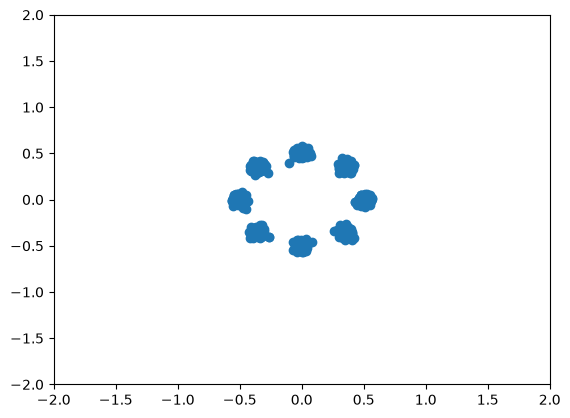

portable_diffusion_model {'out_logvar': (100,)}
resnet_diffusion_model/embed {'embeddings': (100, 32)}
resnet_diffusion_model/layer_norm {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/layer_norm_1 {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/layer_norm_2 {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/layer_norm_3 {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/linear {'b': (128,), 'w': (2, 128)}
resnet_diffusion_model/linear_1 {'b': (256,), 'w': (128, 256)}
resnet_diffusion_model/linear_10 {'b': (256,), 'w': (32, 256)}
resnet_diffusion_model/linear_11 {'b': (256,), 'w': (256, 256)}
resnet_diffusion_model/linear_12 {'b': (128,), 'w': (256, 128)}
resnet_diffusion_model/linear_13 {'b': (256,), 'w': (128, 256)}
resnet_diffusion_model/linear_14 {'b': (256,), 'w': (32, 256)}
resnet_diffusion_model/linear_15 {'b': (256,), 'w': (256, 256)}
resnet_diffusion_model/linear_16 {'b': (128,), 'w': (256, 128)}
resnet_diffusion_model/linear_17 {'b': (2,)

/tmp/ipykernel_1391087/1385371818.py:265: UserWarning: Explicitly requested dtype int64 requested in ones is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  t = jnp.ones((n,), dtype=jnp.int64) * j


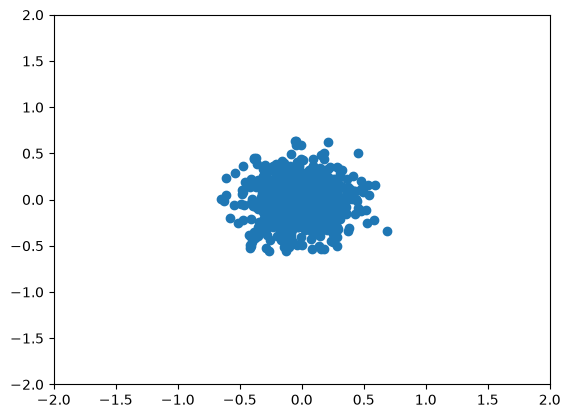

/tmp/ipykernel_1391087/1385371818.py:235: UserWarning: Explicitly requested dtype int64 requested in ones is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  t = jnp.ones((x_0.shape[0],), dtype=jnp.int64) * (self._n_steps - 1)


TEST 0 logpx -969.70447


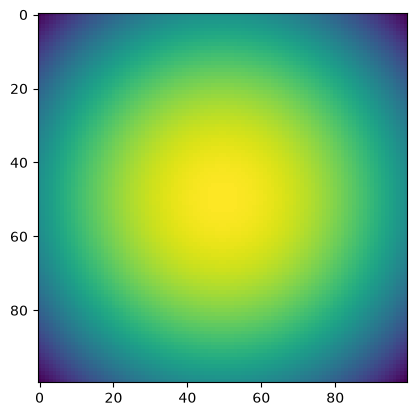

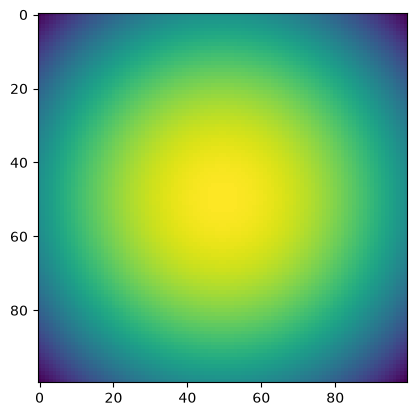

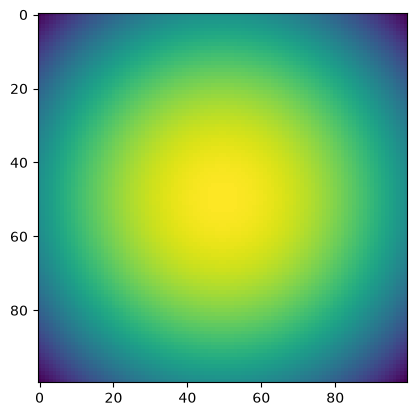

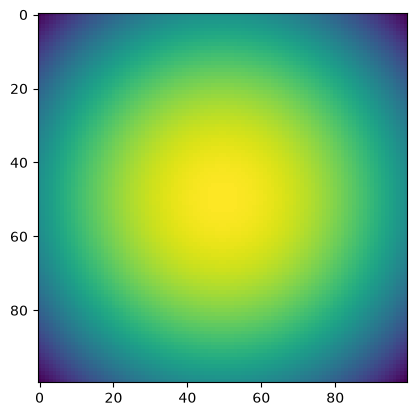

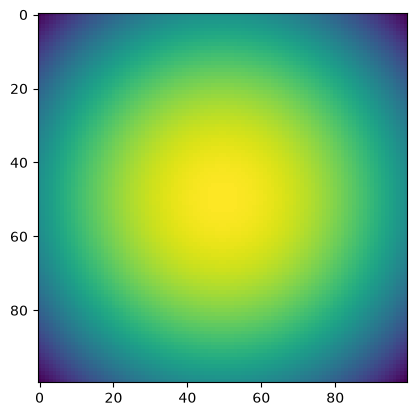

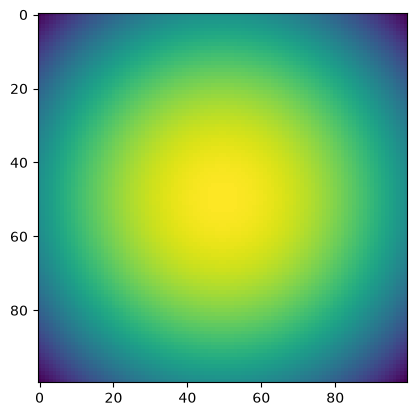

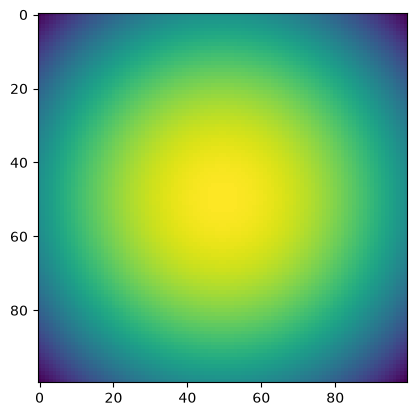

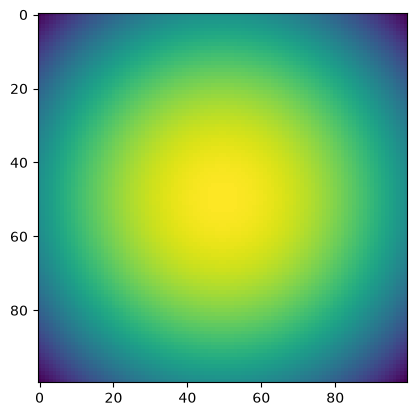

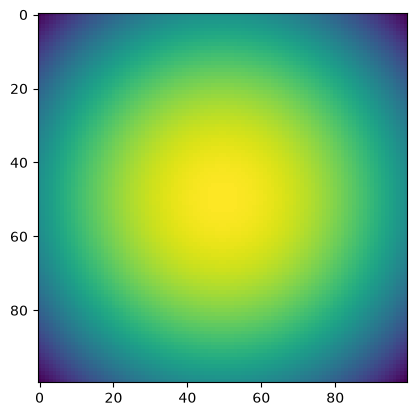

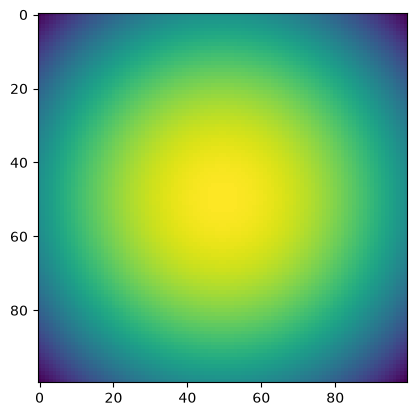

100 0.22874516 time: 0.0018367767333984375
200 0.22157267 time: 0.0032622814178466797
300 0.2303212 time: 0.0030355453491210938
400 0.20838226 time: 0.0023081302642822266
500 0.22669609 time: 0.002031087875366211
600 0.19824116 time: 0.003157377243041992
700 0.20799404 time: 0.0018966197967529297
800 0.20108327 time: 0.003572702407836914
900 0.20223592 time: 0.0027458667755126953
1000 0.17680845 time: 0.002001523971557617


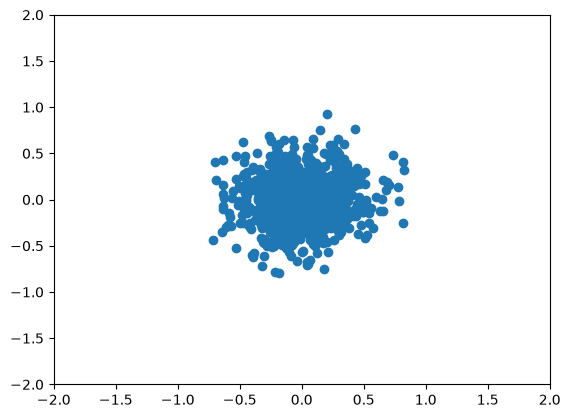

TEST 1000 logpx -127.44004


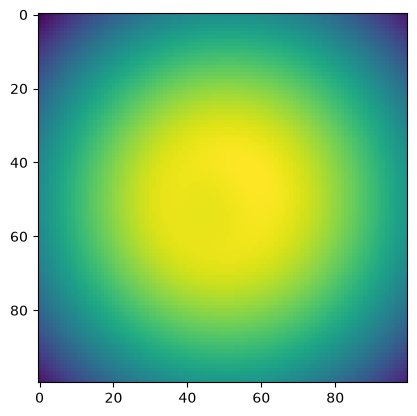

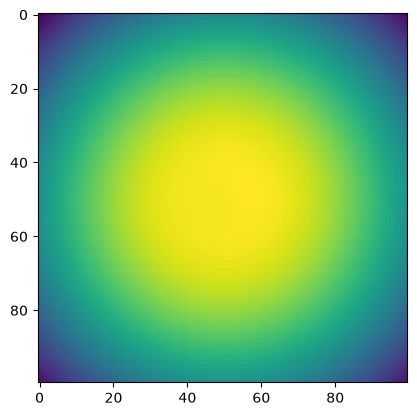

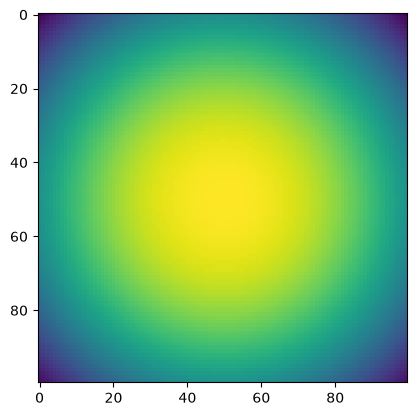

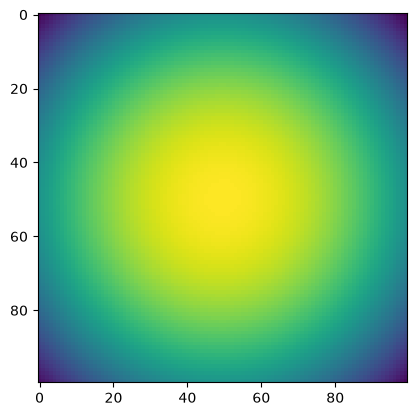

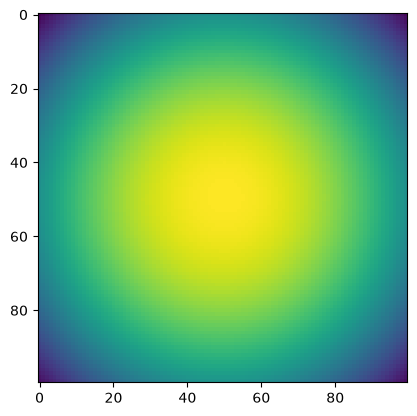

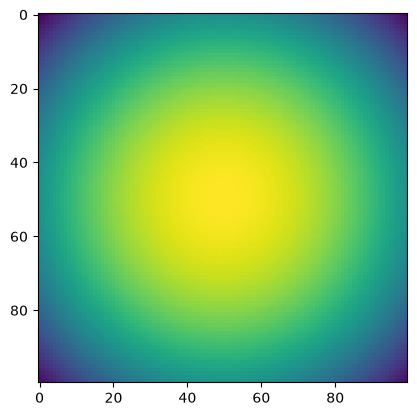

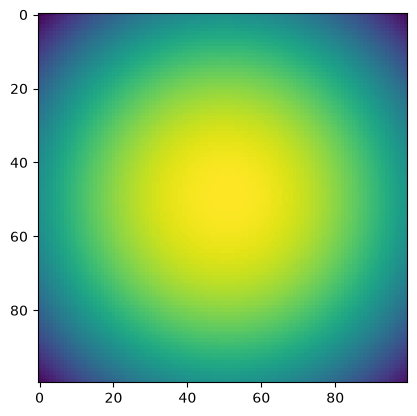

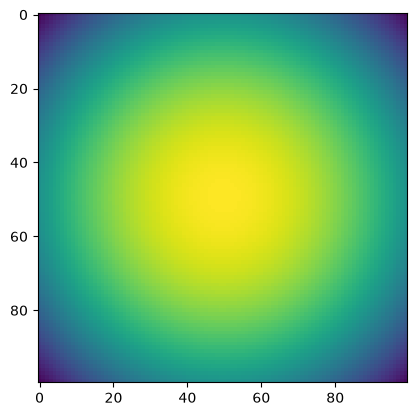

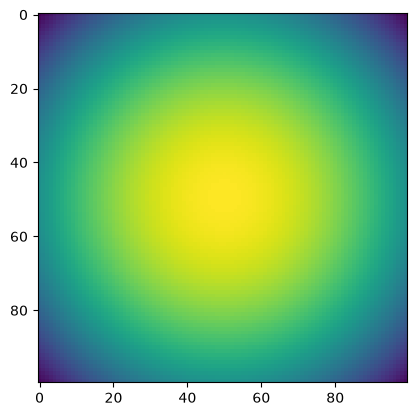

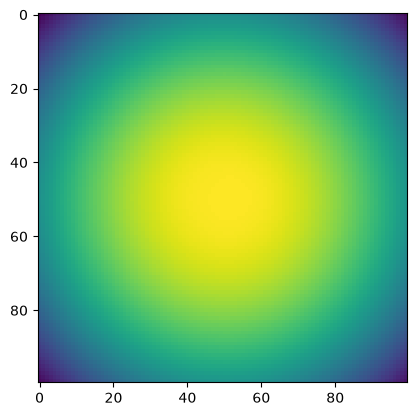

1100 0.22987361 time: 0.003422260284423828
1200 0.21417156 time: 0.0017495155334472656
1300 0.20016234 time: 0.0017483234405517578
1400 0.19054331 time: 0.0017561912536621094
1500 0.21171801 time: 0.0019505023956298828
1600 0.18024866 time: 0.0029821395874023438
1700 0.18253835 time: 0.0020890235900878906
1800 0.20949195 time: 0.0018820762634277344
1900 0.19336085 time: 0.003392934799194336
2000 0.21256514 time: 0.0028247833251953125


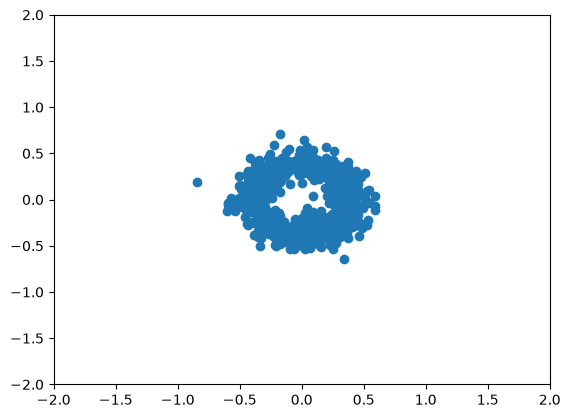

TEST 2000 logpx -18.40747


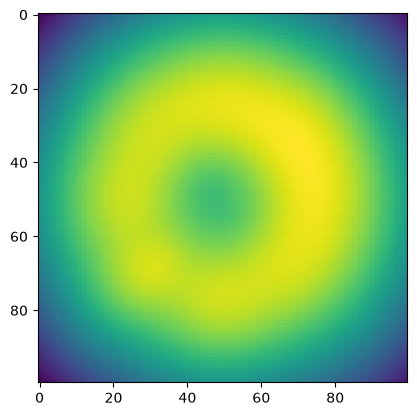

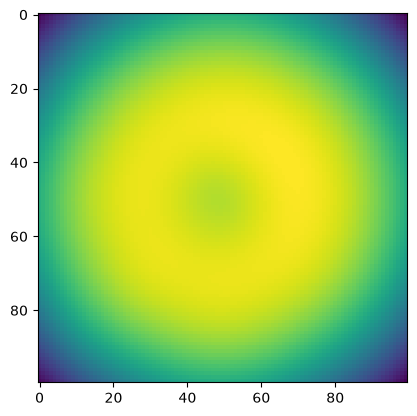

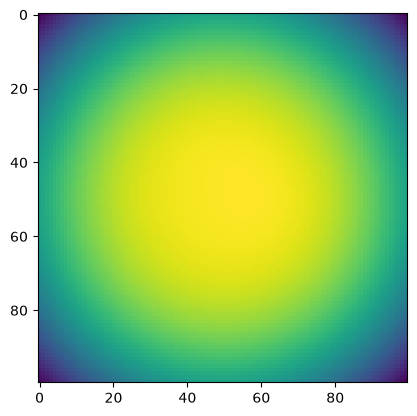

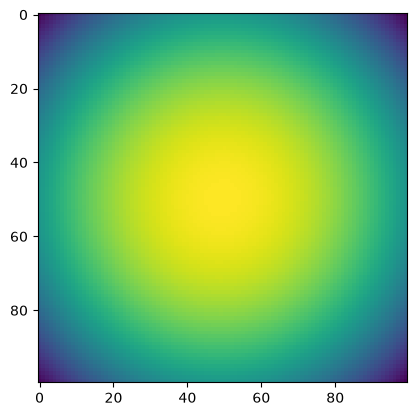

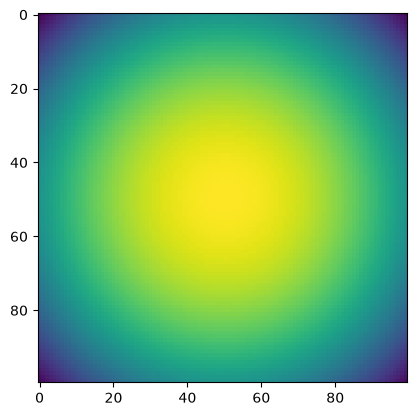

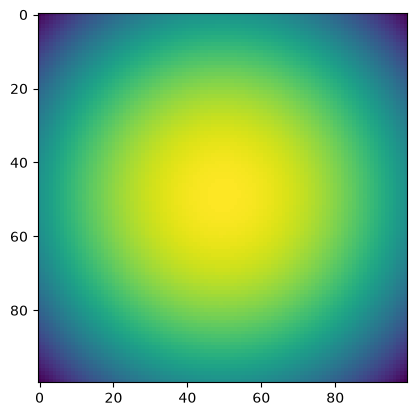

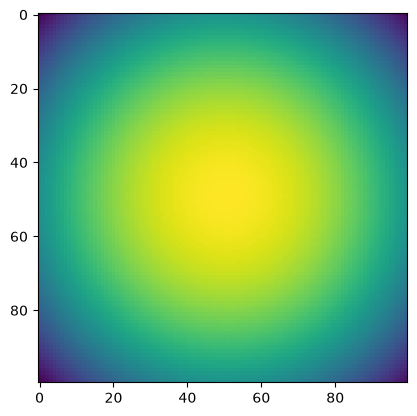

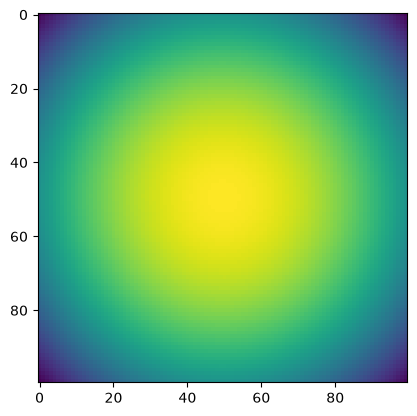

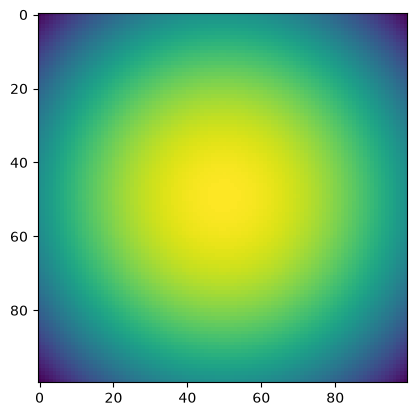

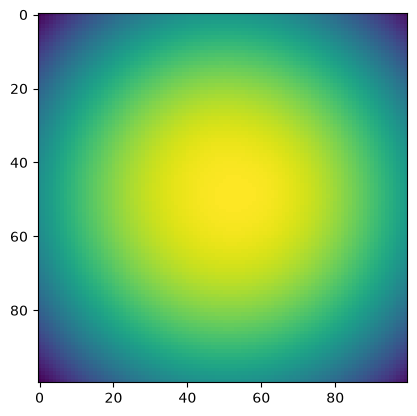

2100 0.20789015 time: 0.002033710479736328
2200 0.18265104 time: 0.001886129379272461
2300 0.21224767 time: 0.002055644989013672
2400 0.17667001 time: 0.001676797866821289
2500 0.20130262 time: 0.0017437934875488281
2600 0.16685456 time: 0.0017397403717041016
2700 0.19878541 time: 0.0017402172088623047
2800 0.20058183 time: 0.0017921924591064453
2900 0.18268855 time: 0.0017402172088623047
3000 0.20035188 time: 0.0017557144165039062


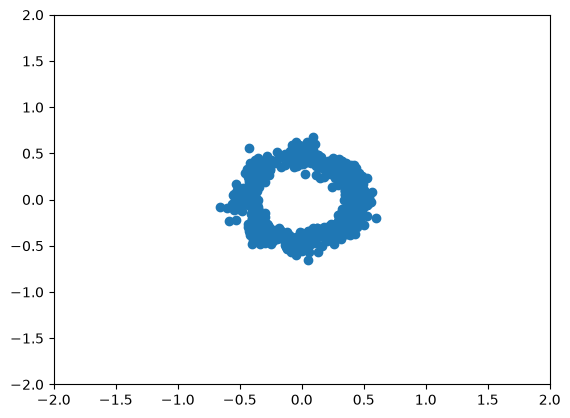

TEST 3000 logpx -2.4270446


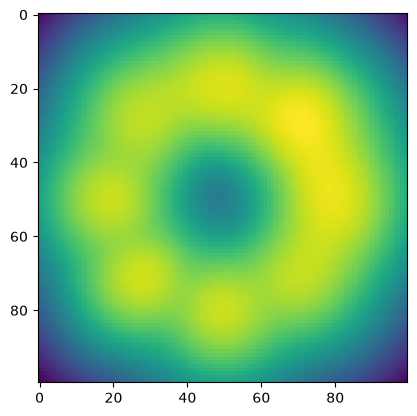

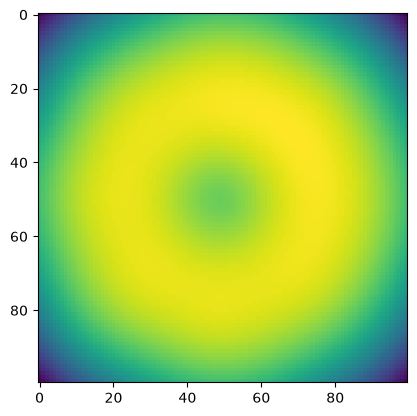

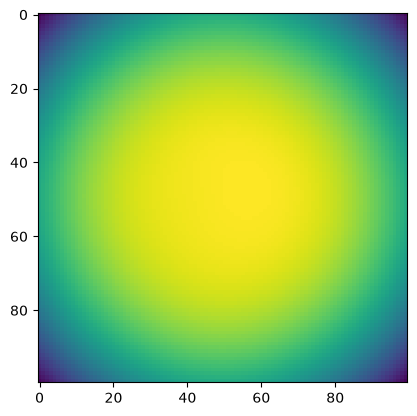

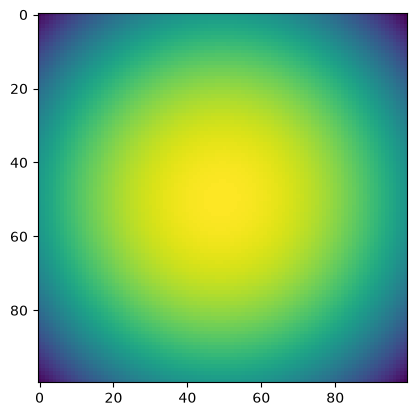

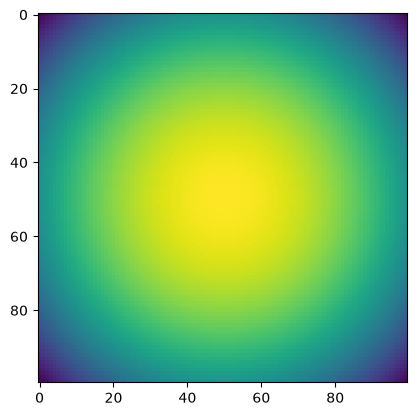

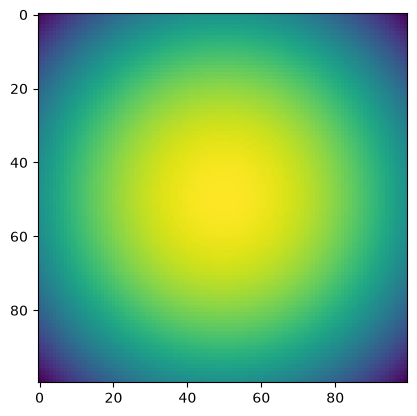

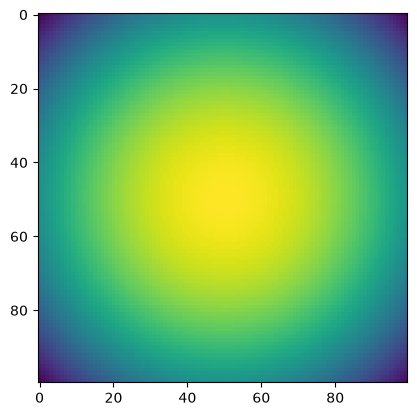

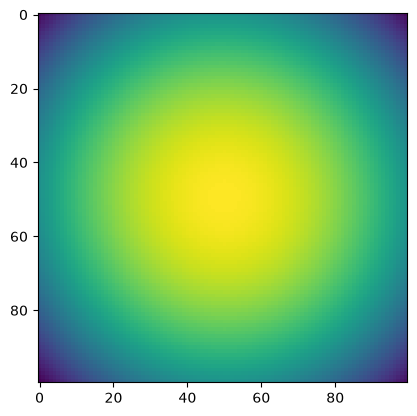

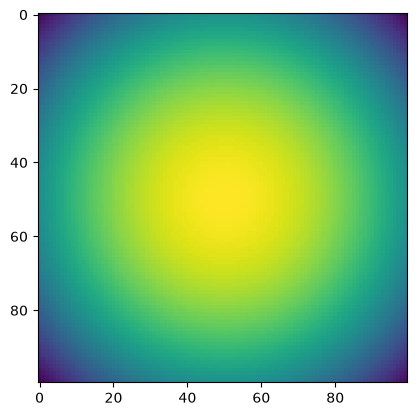

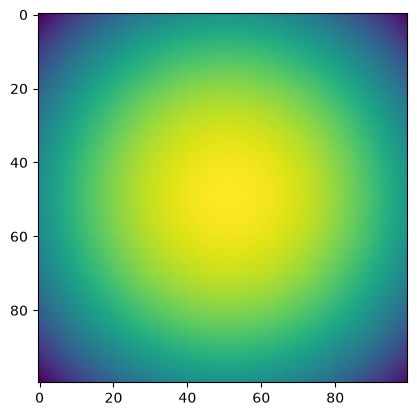

3100 0.17509349 time: 0.0017094612121582031
3200 0.20008767 time: 0.0016868114471435547
3300 0.1719185 time: 0.0017626285552978516
3400 0.17789862 time: 0.0023653507232666016
3500 0.20266736 time: 0.0018718242645263672
3600 0.18614914 time: 0.001649618148803711
3700 0.20192872 time: 0.001737833023071289
3800 0.18519545 time: 0.0025670528411865234
3900 0.1886655 time: 0.0017478466033935547
4000 0.20654784 time: 0.0017888545989990234


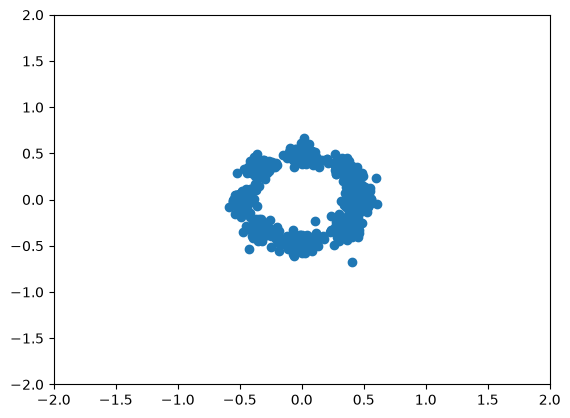

TEST 4000 logpx 0.19115262


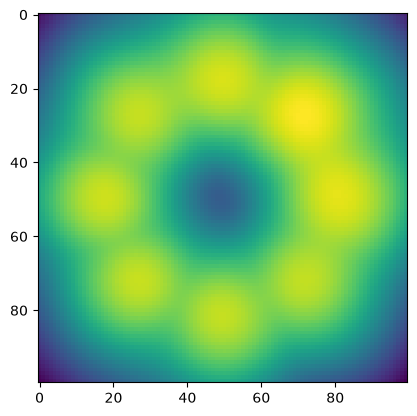

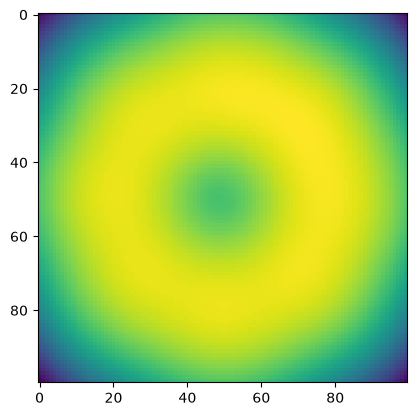

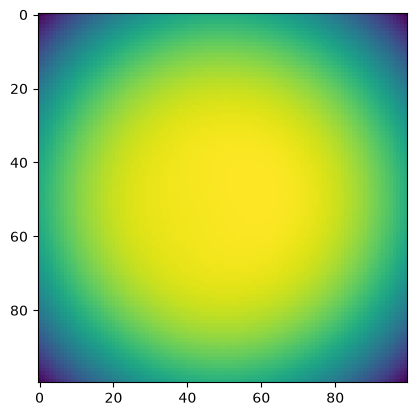

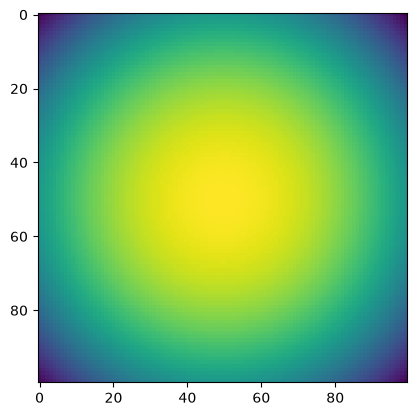

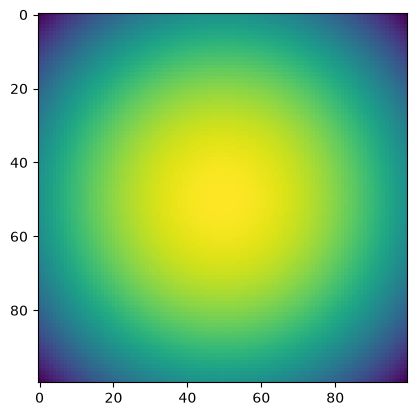

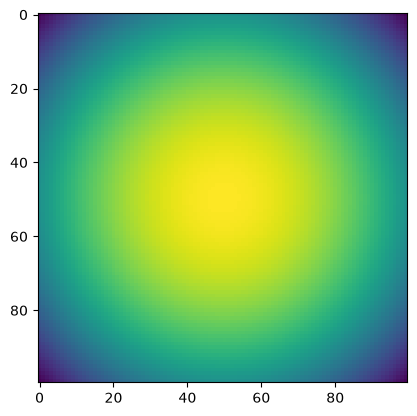

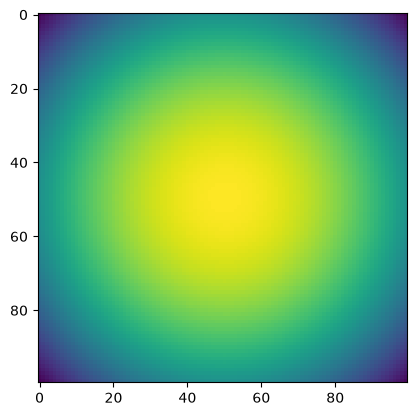

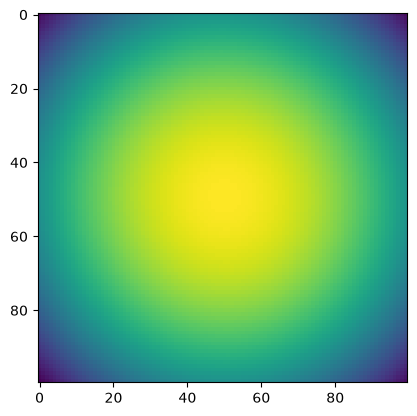

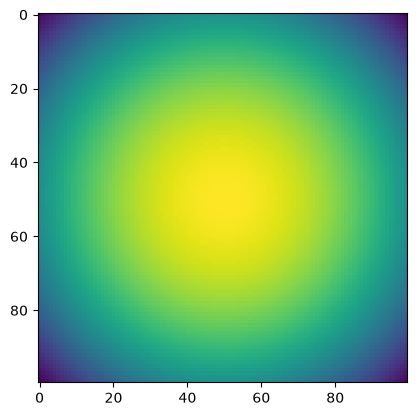

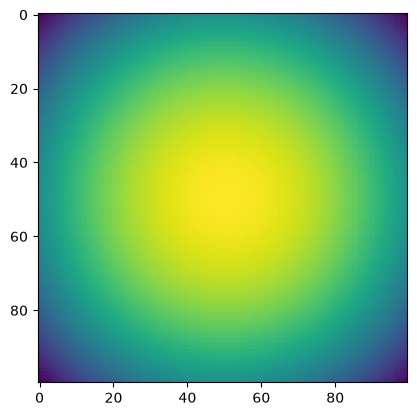

4100 0.21354967 time: 0.0017123222351074219
4200 0.18225862 time: 0.0017261505126953125
4300 0.20831858 time: 0.001832723617553711
4400 0.18600492 time: 0.0016770362854003906
4500 0.20257509 time: 0.0021963119506835938
4600 0.20697868 time: 0.0016338825225830078
4700 0.18178776 time: 0.001947641372680664
4800 0.18746544 time: 0.001913309097290039
4900 0.2047057 time: 0.0022275447845458984
5000 0.22244975 time: 0.0016944408416748047


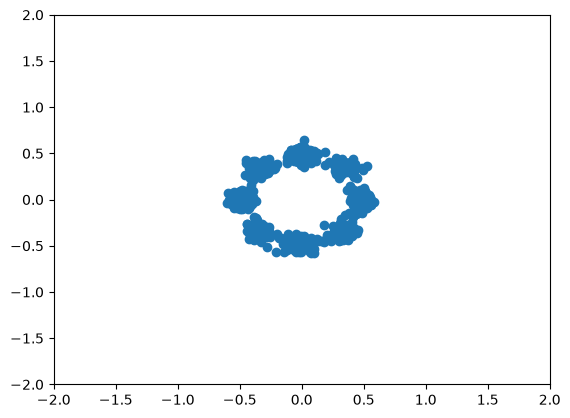

TEST 5000 logpx 0.91714156


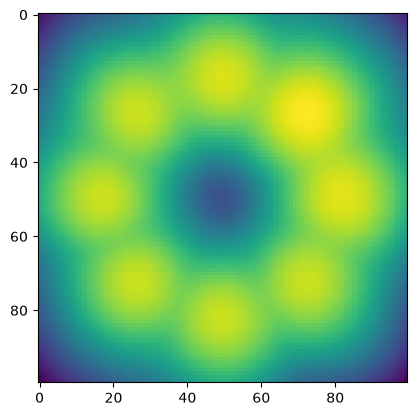

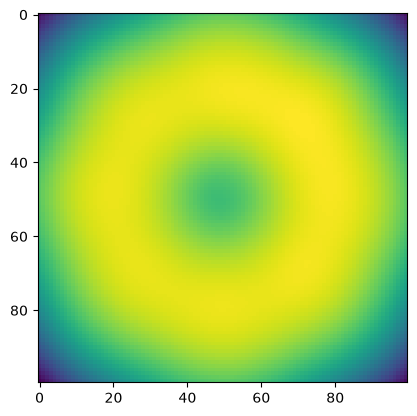

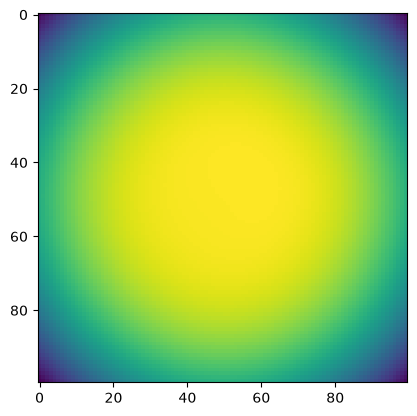

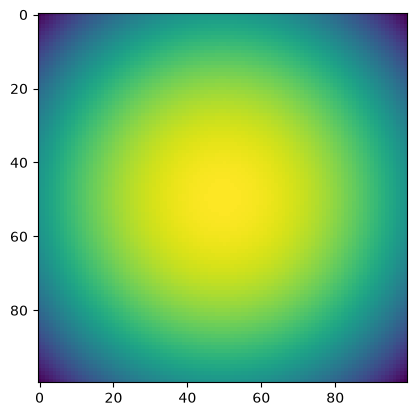

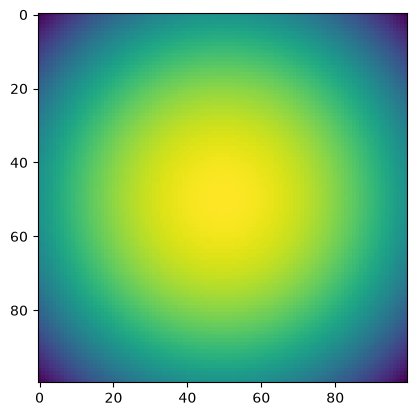

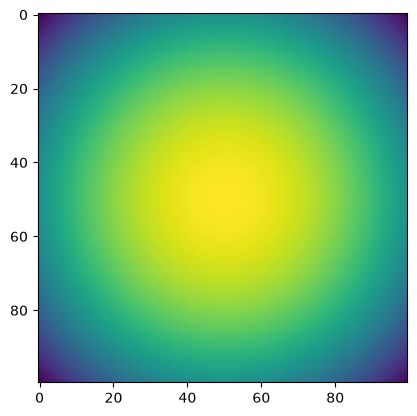

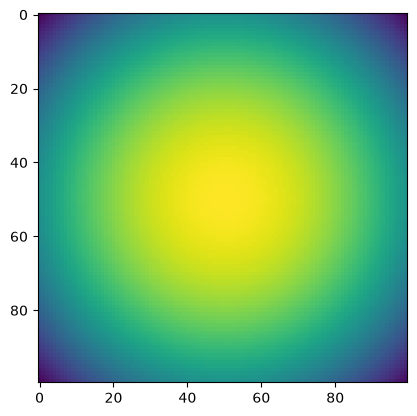

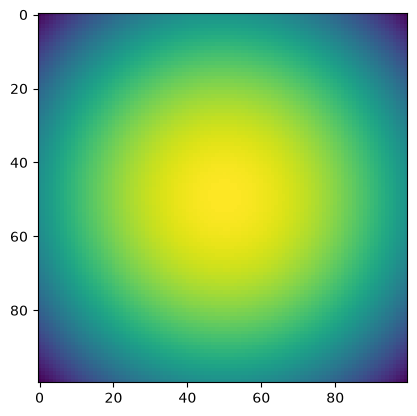

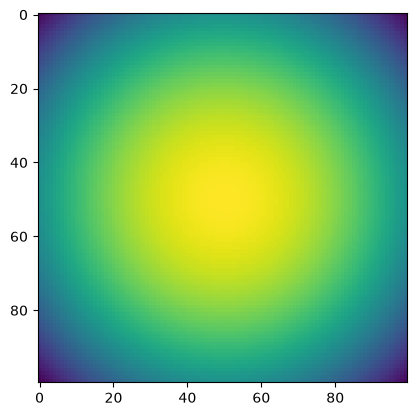

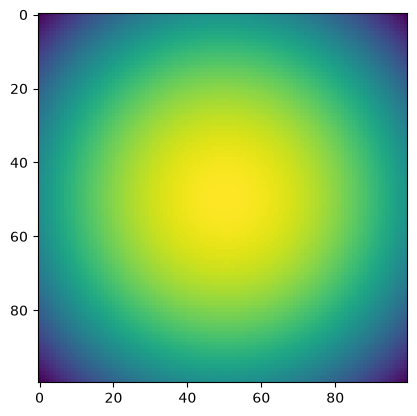

5100 0.192605 time: 0.001703500747680664
5200 0.22540177 time: 0.0017197132110595703
5300 0.20235804 time: 0.002080678939819336
5400 0.21080089 time: 0.001680135726928711
5500 0.20936735 time: 0.0018656253814697266
5600 0.16223249 time: 0.0034744739532470703
5700 0.20632659 time: 0.0018229484558105469
5800 0.18773036 time: 0.0017156600952148438
5900 0.1838492 time: 0.0017704963684082031
6000 0.20857444 time: 0.0019278526306152344


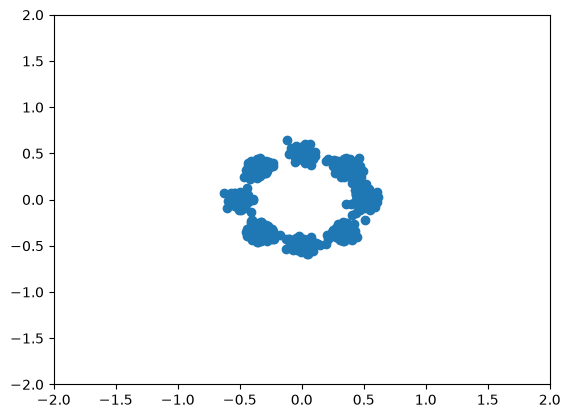

TEST 6000 logpx 1.2186052


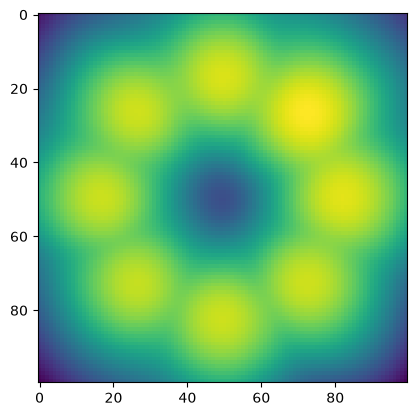

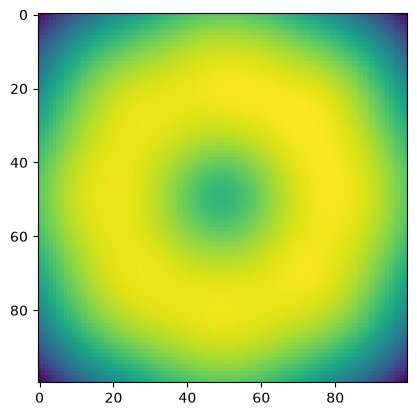

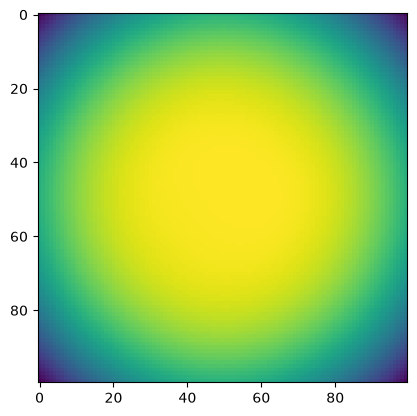

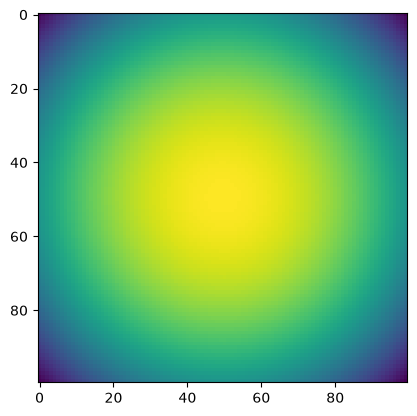

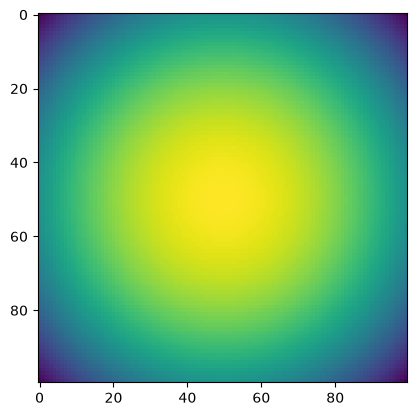

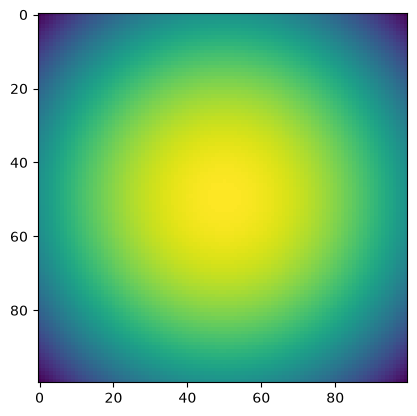

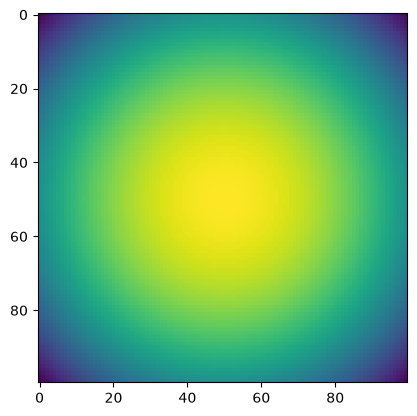

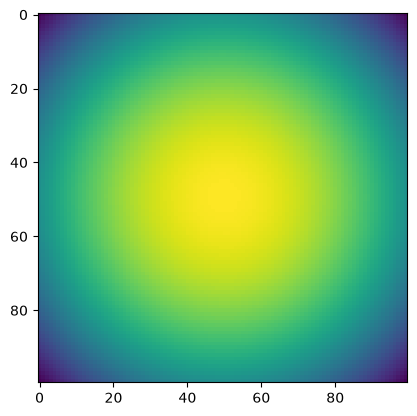

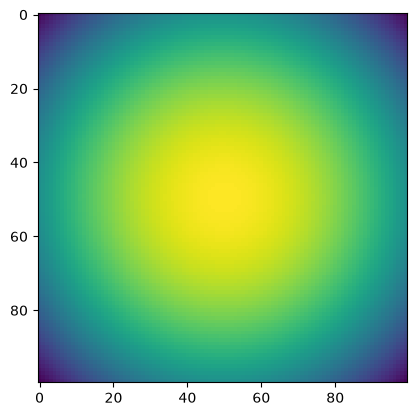

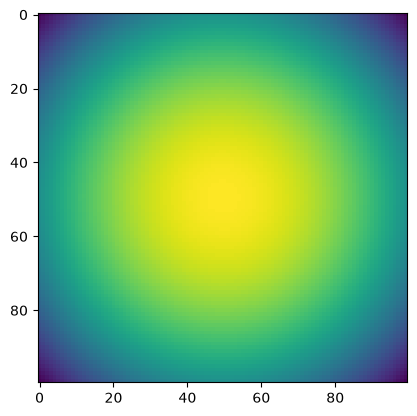

6100 0.18392844 time: 0.0029535293579101562
6200 0.19527322 time: 0.0022928714752197266
6300 0.19195275 time: 0.0017826557159423828
6400 0.2106603 time: 0.0018322467803955078
6500 0.19574757 time: 0.0020198822021484375
6600 0.19407609 time: 0.001674652099609375
6700 0.18656318 time: 0.003409147262573242
6800 0.19411476 time: 0.0017440319061279297
6900 0.18722716 time: 0.0018999576568603516
7000 0.18711655 time: 0.0018589496612548828


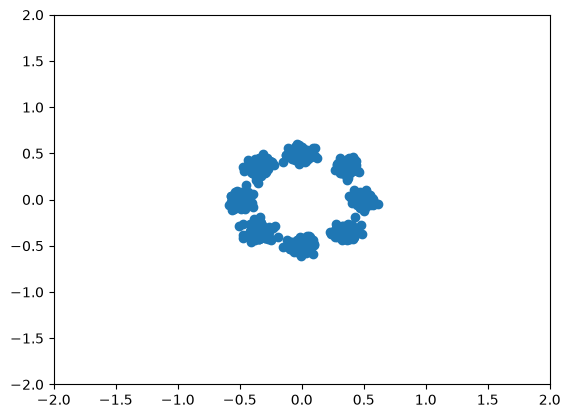

TEST 7000 logpx 1.4183893


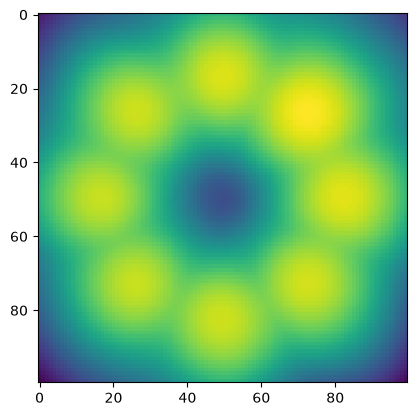

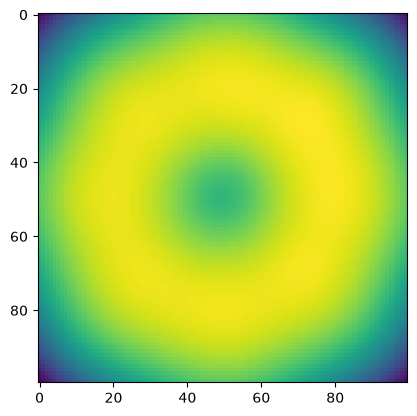

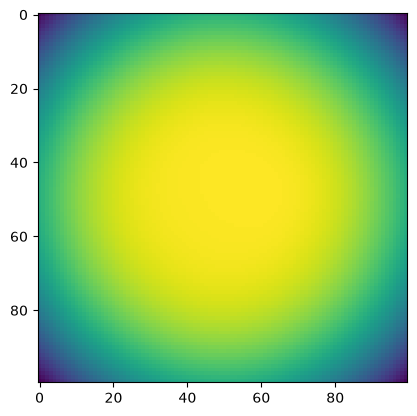

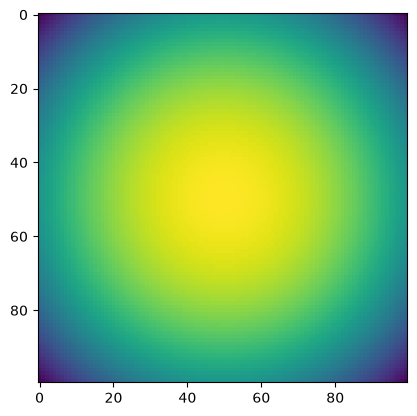

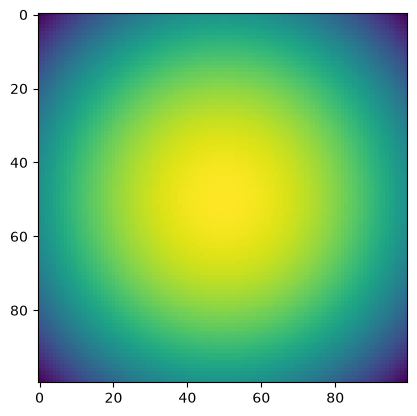

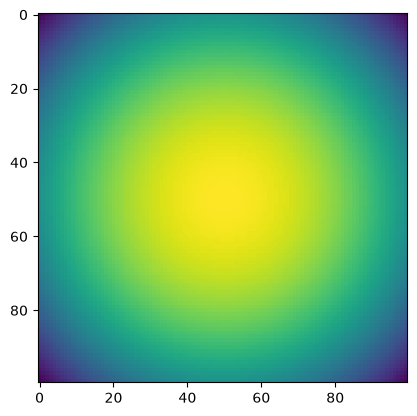

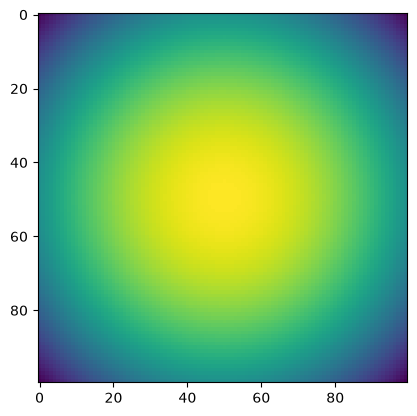

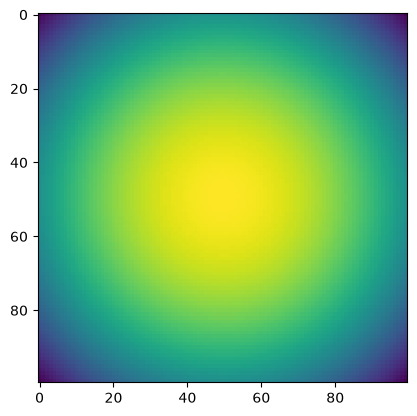

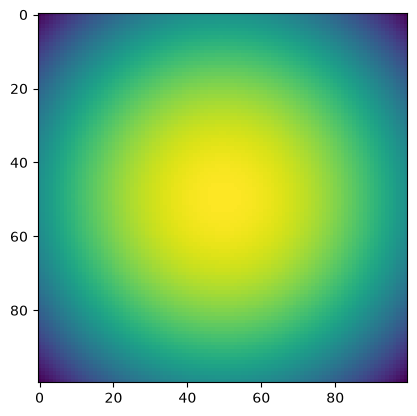

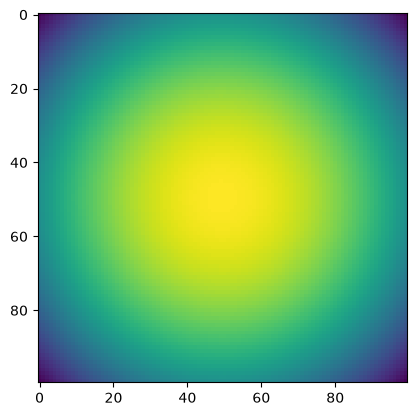

7100 0.18653381 time: 0.0019922256469726562
7200 0.18261547 time: 0.0017871856689453125
7300 0.20836218 time: 0.0017418861389160156
7400 0.19710548 time: 0.0018455982208251953
7500 0.20739084 time: 0.0020418167114257812
7600 0.1756678 time: 0.0017406940460205078
7700 0.20054702 time: 0.0019345283508300781
7800 0.17328702 time: 0.003991365432739258
7900 0.19035792 time: 0.0017824172973632812
8000 0.1915991 time: 0.0018429756164550781


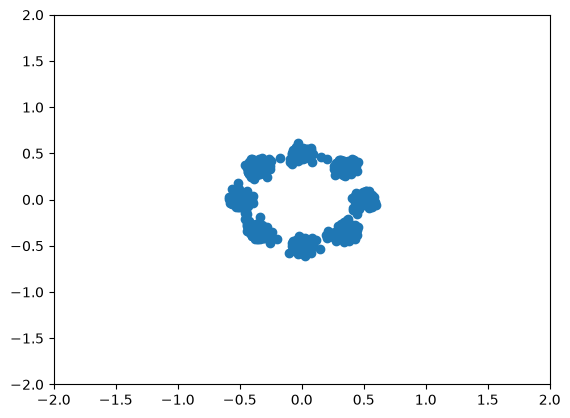

TEST 8000 logpx 1.4982083


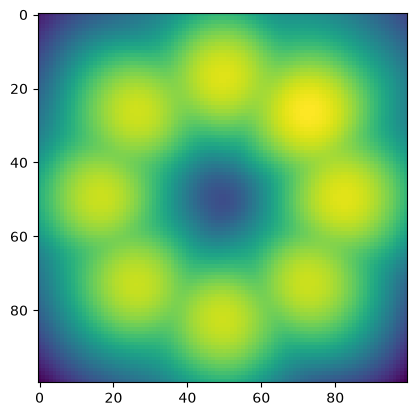

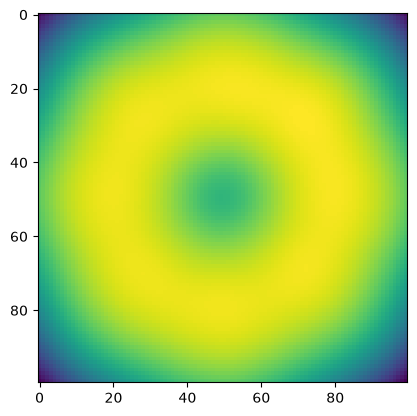

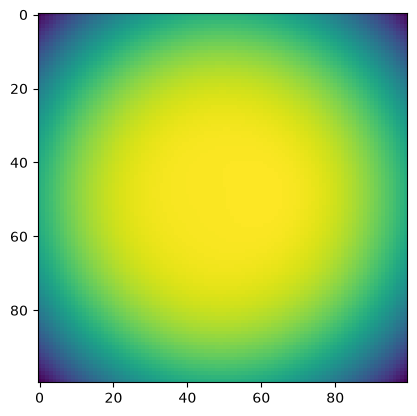

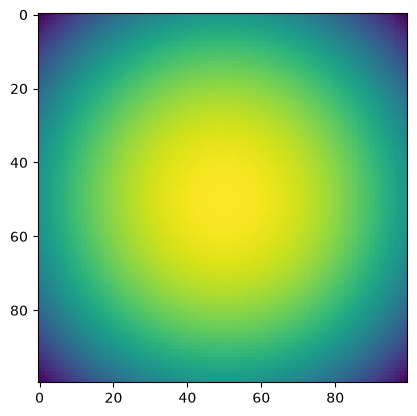

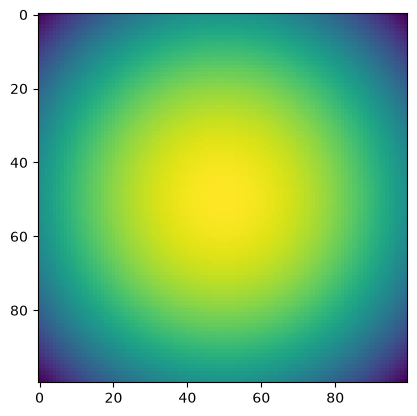

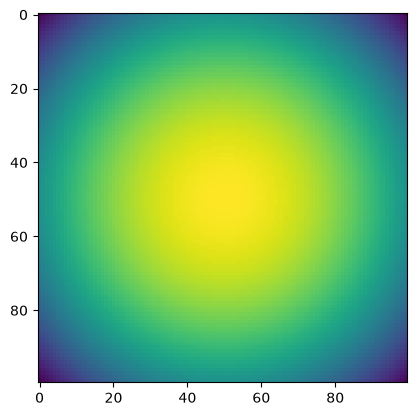

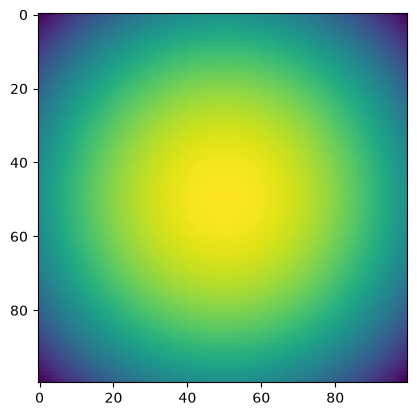

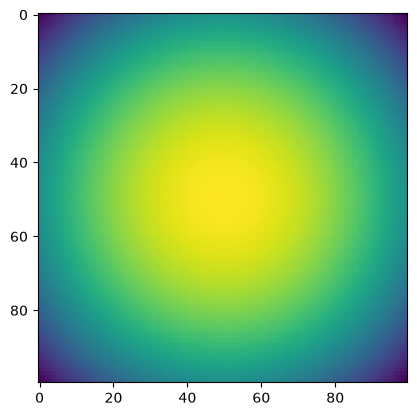

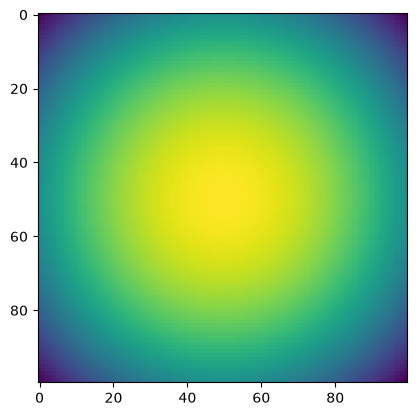

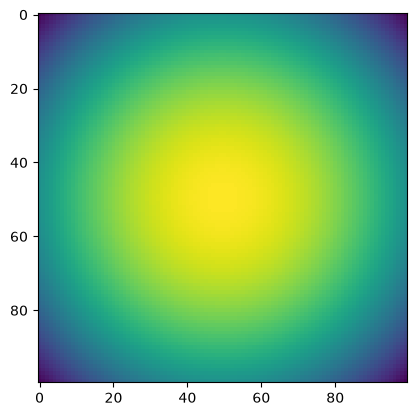

8100 0.1943566 time: 0.0017943382263183594
8200 0.18179215 time: 0.001890420913696289
8300 0.20487311 time: 0.0029828548431396484
8400 0.22637807 time: 0.002302885055541992
8500 0.19809295 time: 0.0017733573913574219
8600 0.18835536 time: 0.001867532730102539
8700 0.17089292 time: 0.0017001628875732422
8800 0.19589306 time: 0.0017170906066894531
8900 0.18304151 time: 0.002630949020385742
9000 0.22709028 time: 0.0017809867858886719


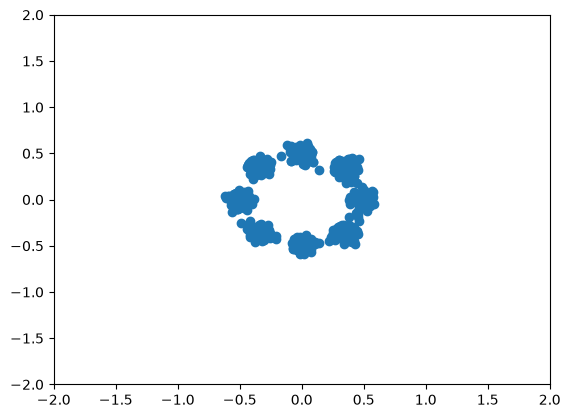

TEST 9000 logpx 1.5573574


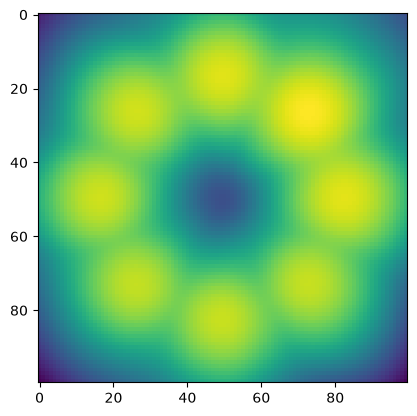

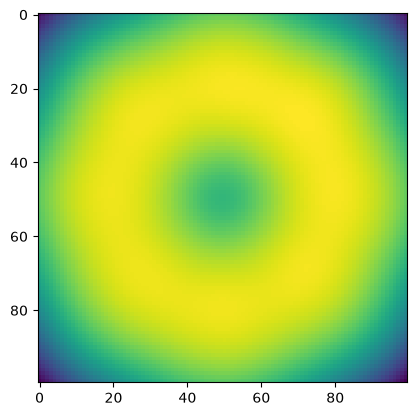

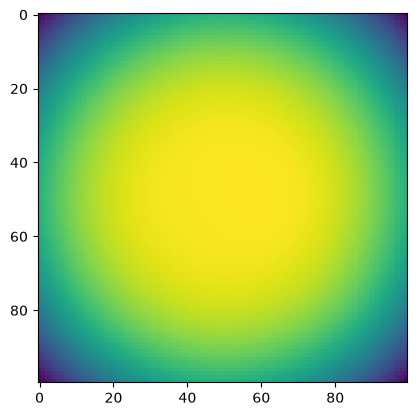

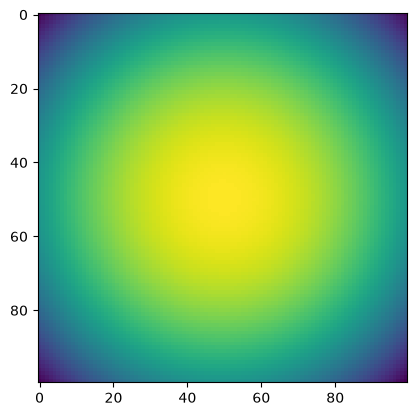

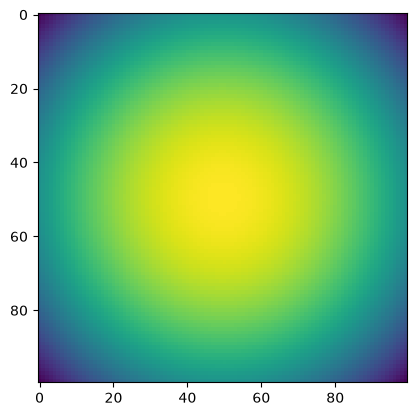

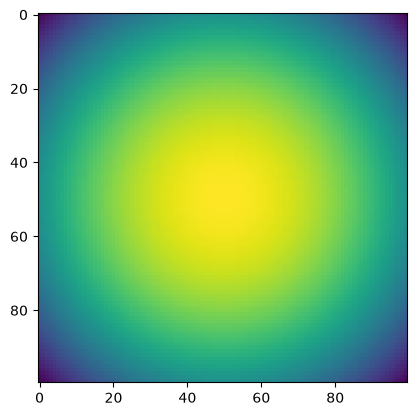

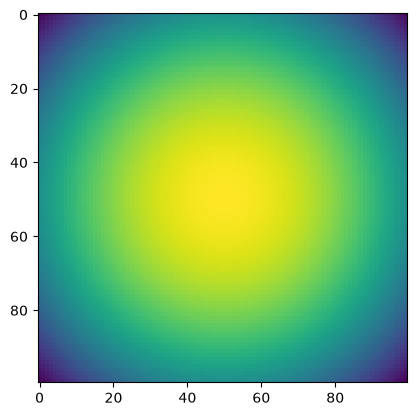

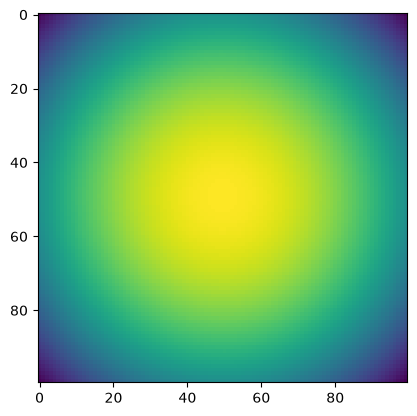

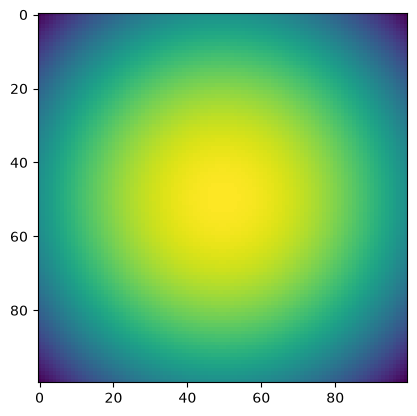

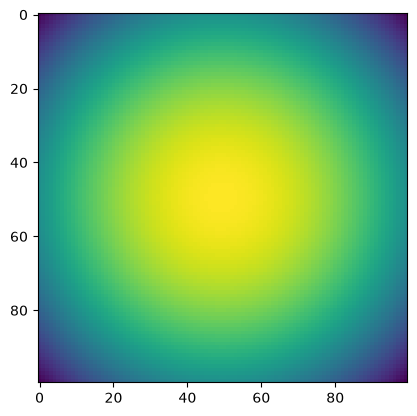

9100 0.18962649 time: 0.004603385925292969
9200 0.18219668 time: 0.0019686222076416016
9300 0.17923228 time: 0.0020160675048828125
9400 0.19417329 time: 0.0017046928405761719
9500 0.20224784 time: 0.0017457008361816406
9600 0.20352878 time: 0.0028111934661865234
9700 0.18024604 time: 0.0021414756774902344
9800 0.18262285 time: 0.001783609390258789
9900 0.18525775 time: 0.001796722412109375
10000 0.2008029 time: 0.001753091812133789


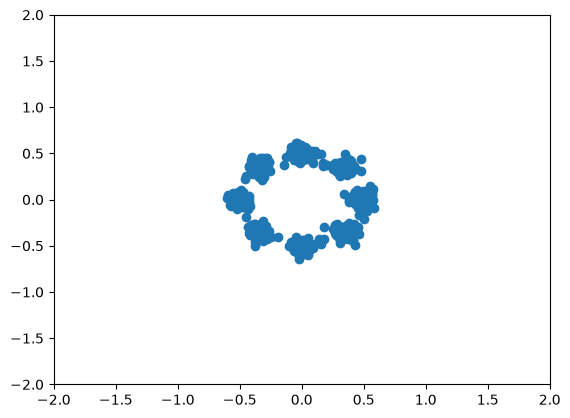

TEST 10000 logpx 1.581682


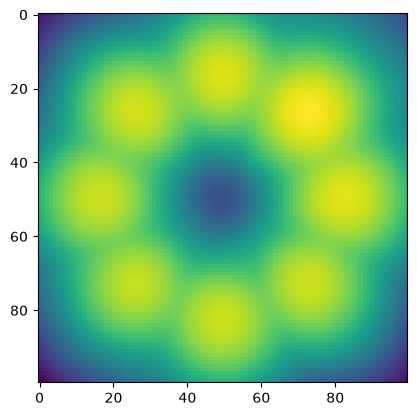

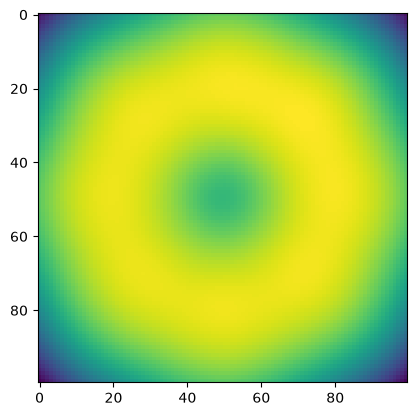

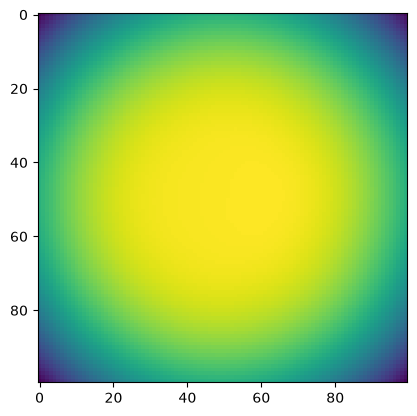

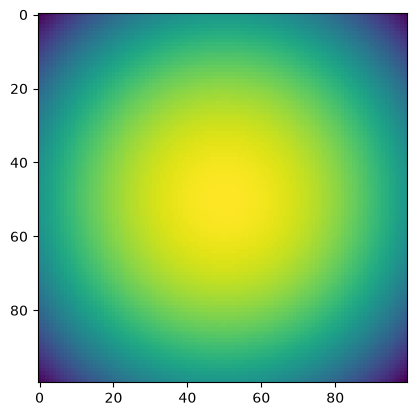

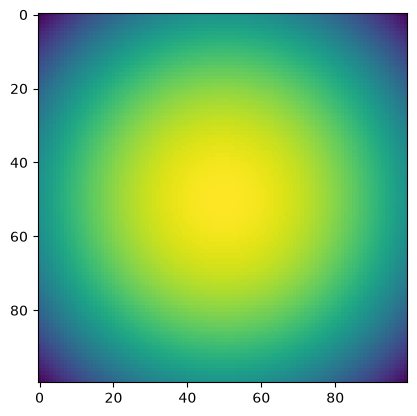

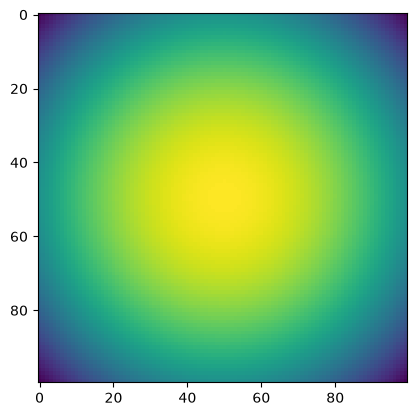

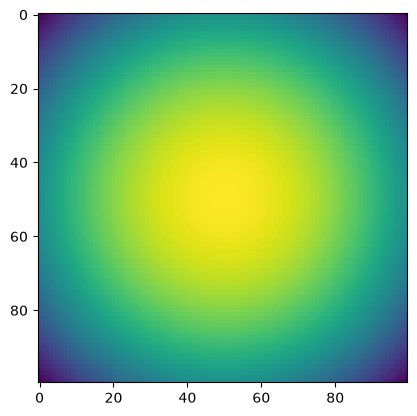

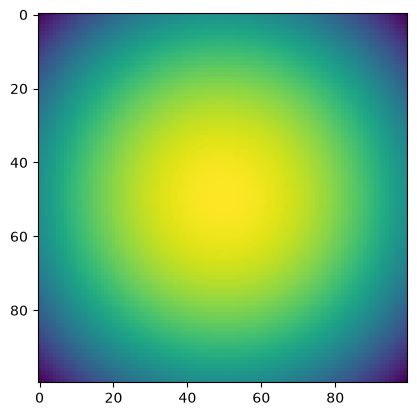

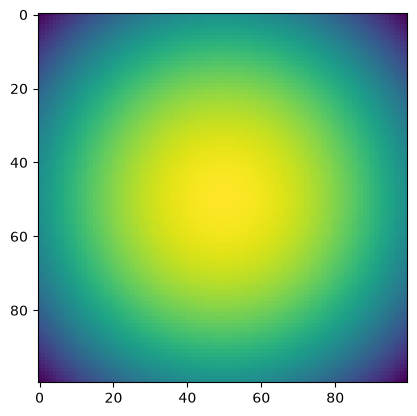

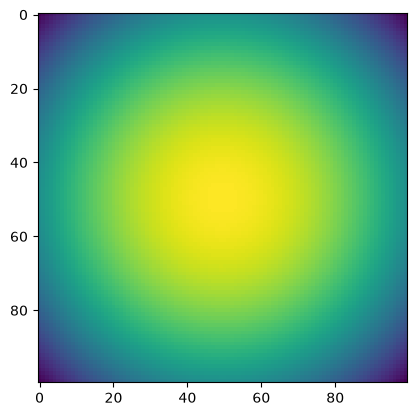

10100 0.21213299 time: 0.0017316341400146484
10200 0.19175199 time: 0.006985664367675781
10300 0.1861576 time: 0.0028955936431884766
10400 0.1860673 time: 0.0017786026000976562
10500 0.18480593 time: 0.001966238021850586
10600 0.18388203 time: 0.005513429641723633
10700 0.18404104 time: 0.001657247543334961
10800 0.17597367 time: 0.0018291473388671875
10900 0.19371358 time: 0.0017659664154052734
11000 0.181124 time: 0.001922607421875


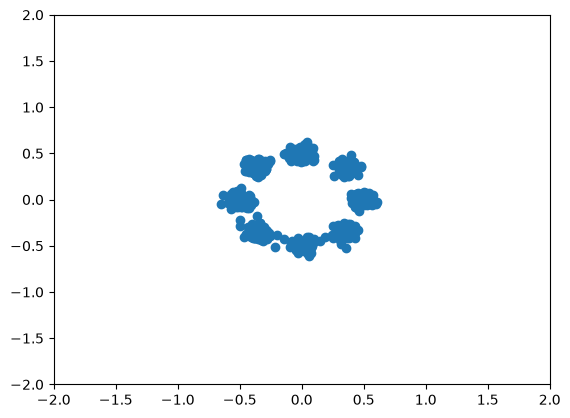

TEST 11000 logpx 1.6115812


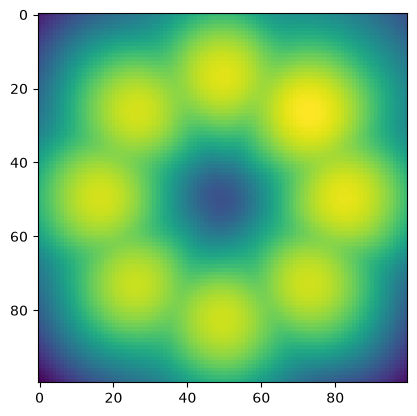

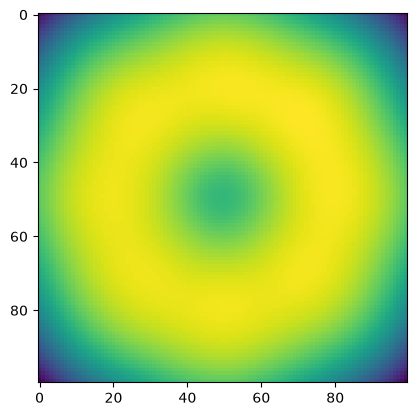

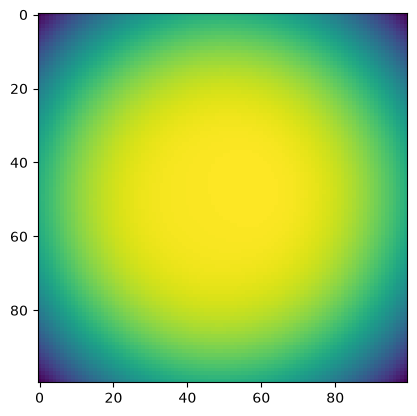

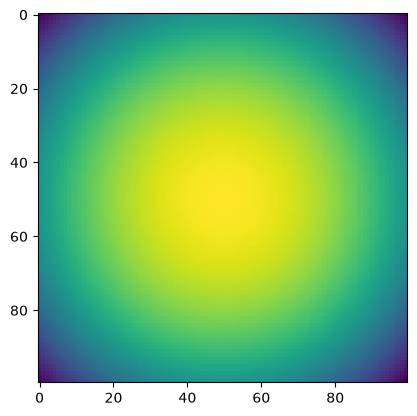

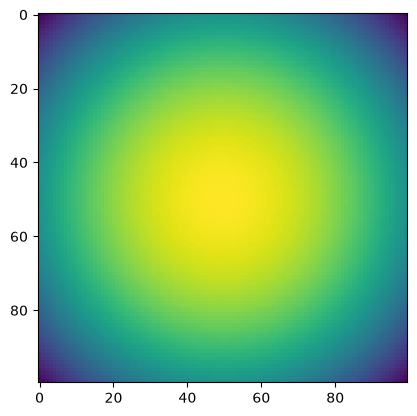

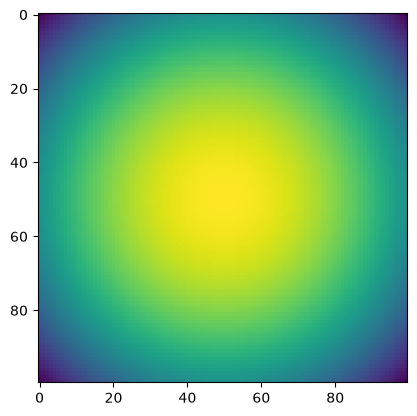

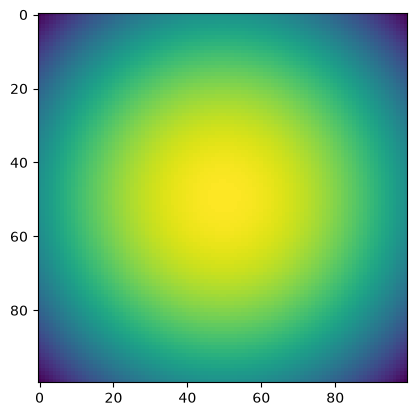

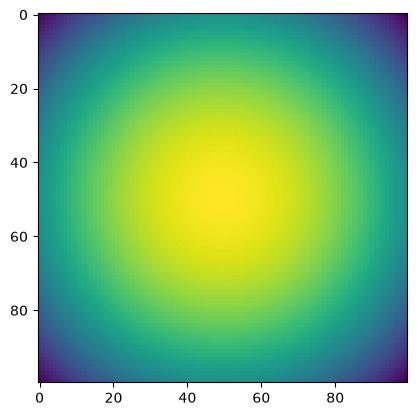

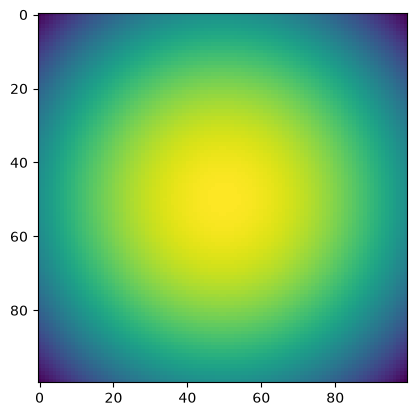

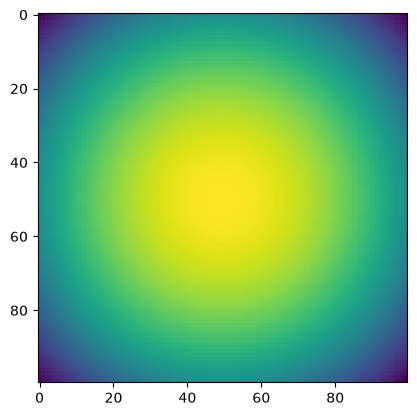

11100 0.18497445 time: 0.003085613250732422
11200 0.17689577 time: 0.005478382110595703
11300 0.23684622 time: 0.001977682113647461
11400 0.19266856 time: 0.001920938491821289
11500 0.20785649 time: 0.0018322467803955078
11600 0.17010371 time: 0.0027358531951904297
11700 0.20997187 time: 0.002644062042236328
11800 0.17509572 time: 0.001745462417602539
11900 0.186289 time: 0.0022182464599609375
12000 0.21316531 time: 0.002388477325439453


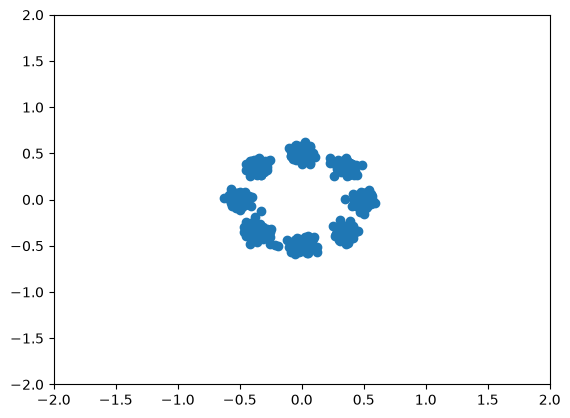

TEST 12000 logpx 1.626728


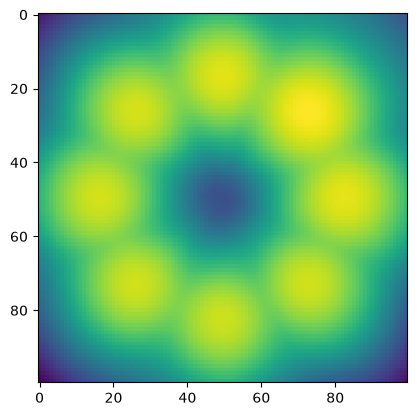

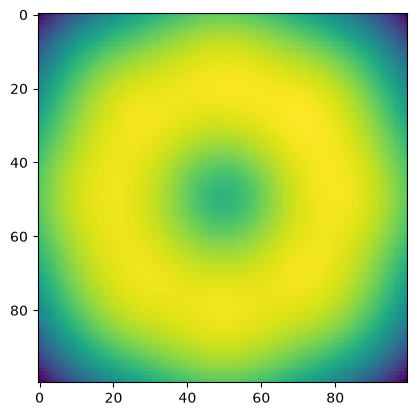

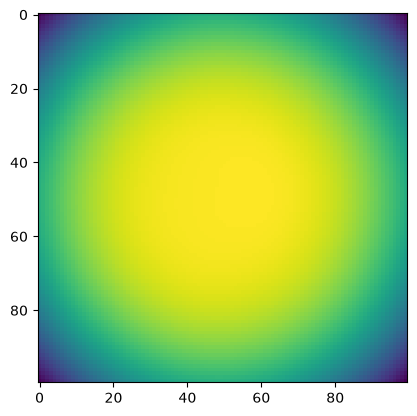

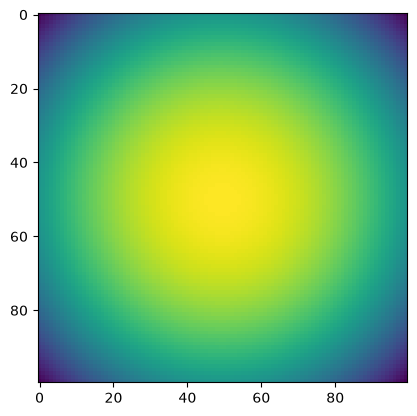

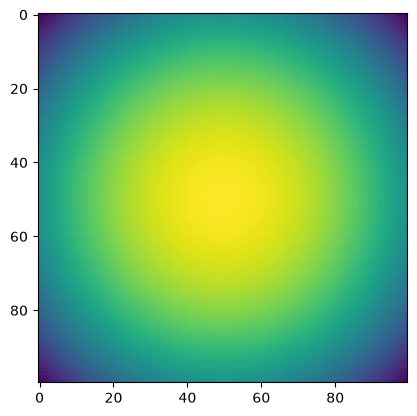

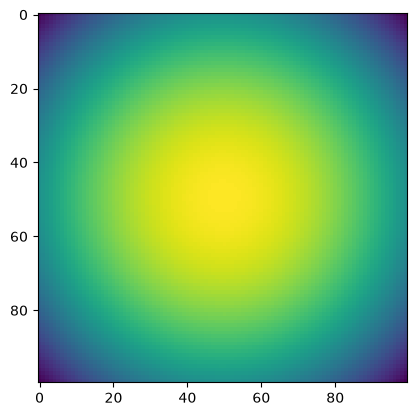

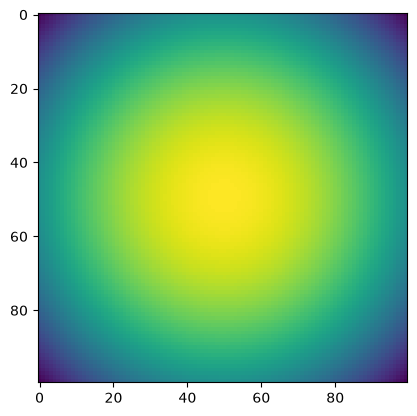

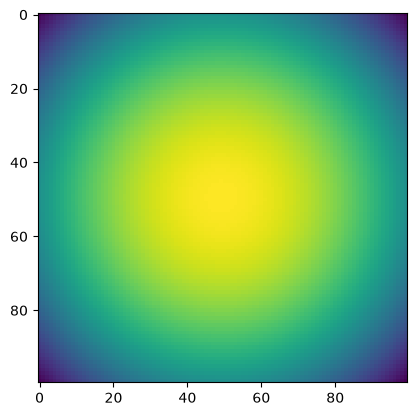

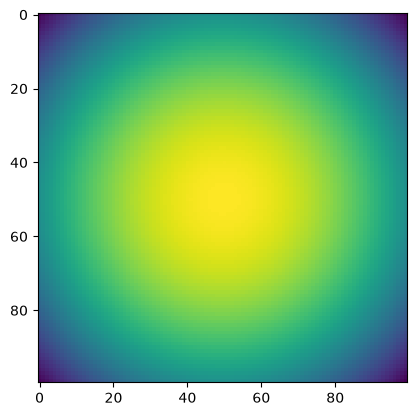

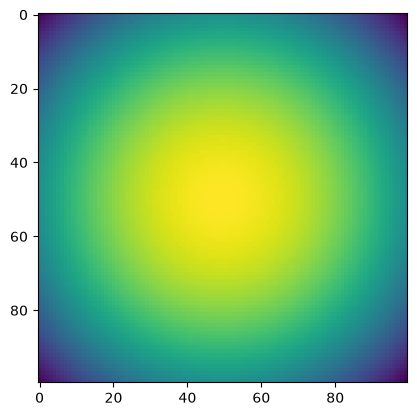

12100 0.19993715 time: 0.0017066001892089844
12200 0.18993907 time: 0.0021736621856689453
12300 0.2081177 time: 0.0021677017211914062
12400 0.1867151 time: 0.0017399787902832031
12500 0.18335167 time: 0.0018301010131835938
12600 0.17154929 time: 0.0018765926361083984
12700 0.1996966 time: 0.0019426345825195312
12800 0.19245443 time: 0.001935720443725586
12900 0.22202542 time: 0.0016825199127197266
13000 0.19820867 time: 0.0016808509826660156


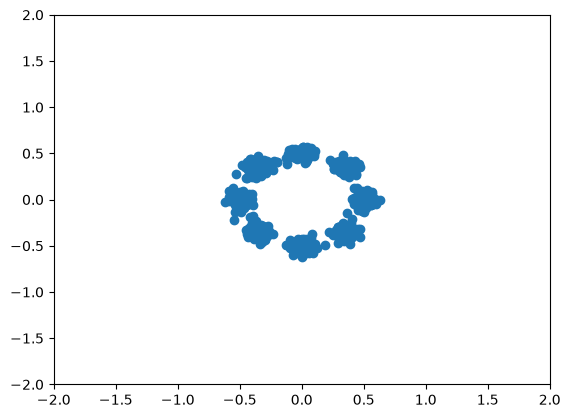

TEST 13000 logpx 1.6767936


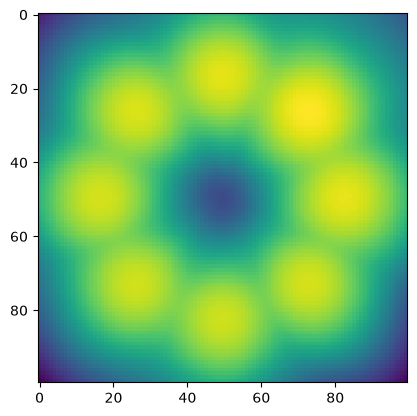

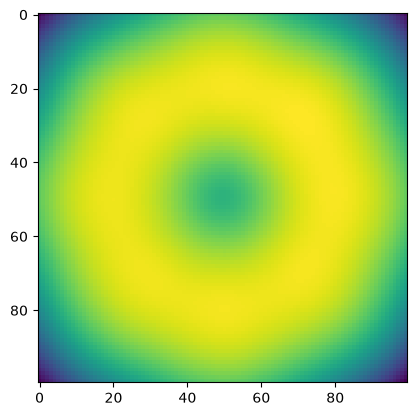

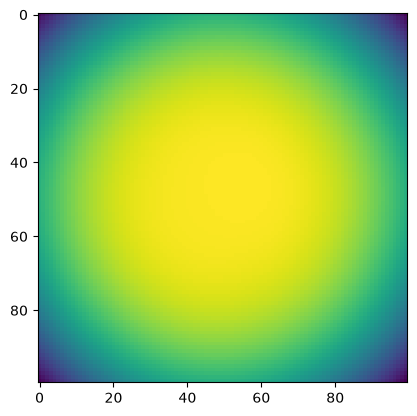

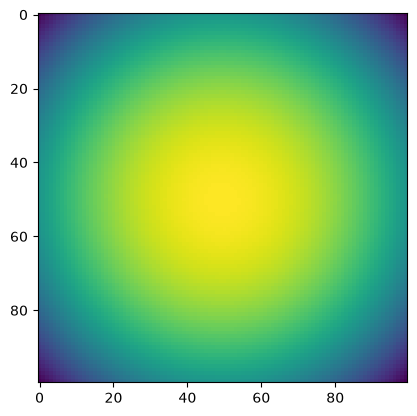

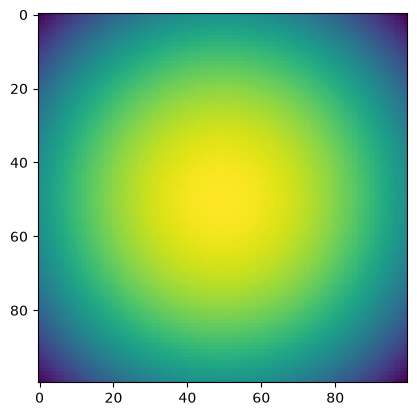

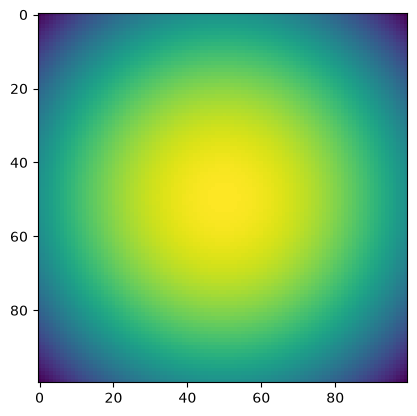

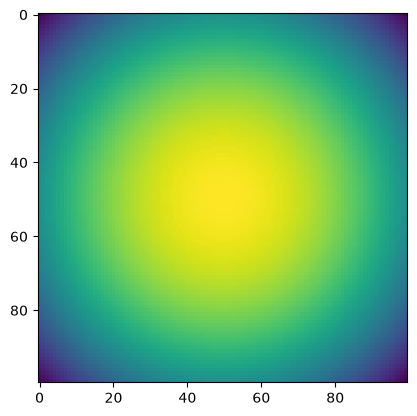

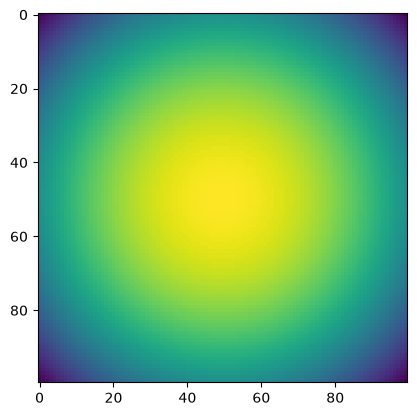

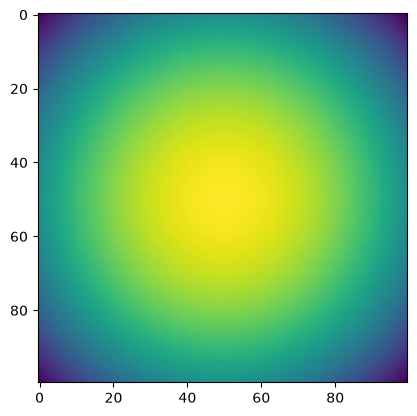

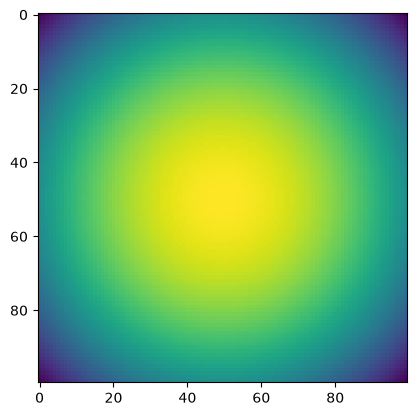

13100 0.1638376 time: 0.0019199848175048828
13200 0.18420814 time: 0.0021016597747802734
13300 0.1769345 time: 0.0017628669738769531
13400 0.18195124 time: 0.0024368762969970703
13500 0.18008137 time: 0.0018591880798339844
13600 0.18883367 time: 0.0016853809356689453
13700 0.17934929 time: 0.0021381378173828125
13800 0.21903767 time: 0.001689910888671875
13900 0.21418747 time: 0.0028960704803466797
14000 0.18220752 time: 0.0020084381103515625


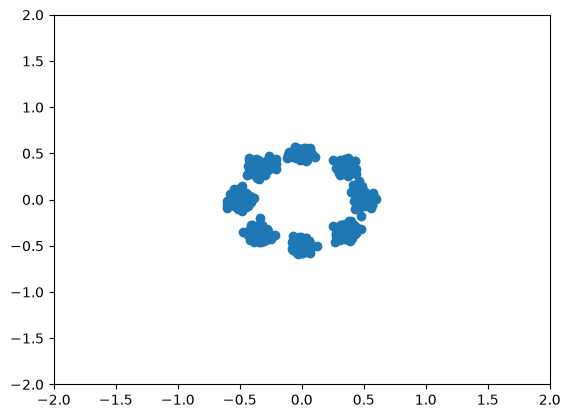

TEST 14000 logpx 1.7106009


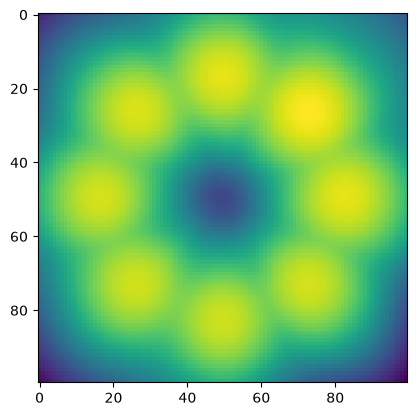

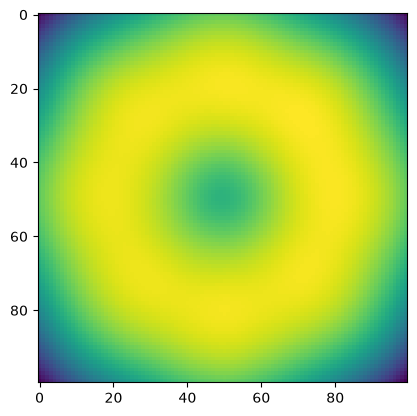

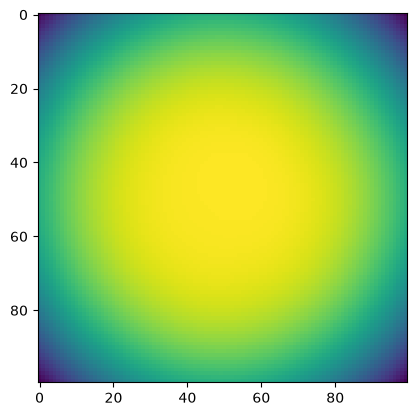

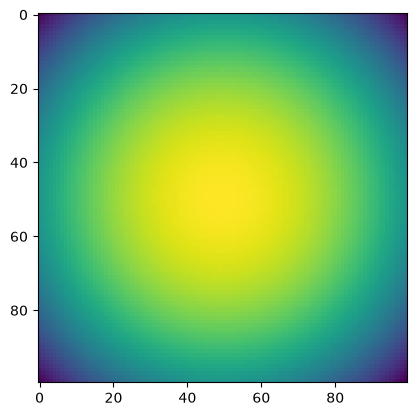

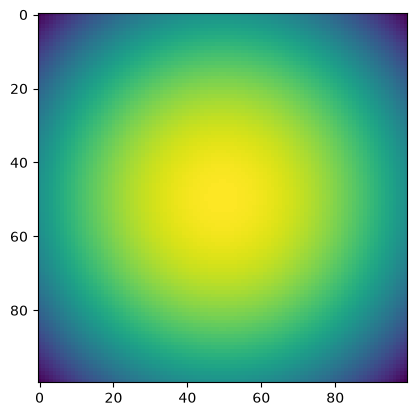

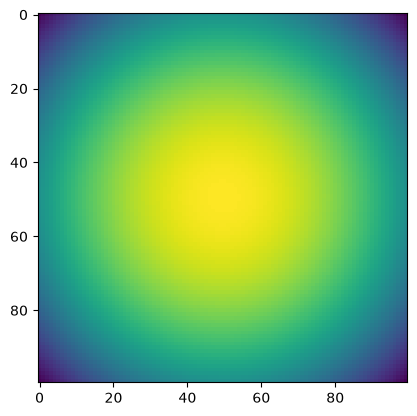

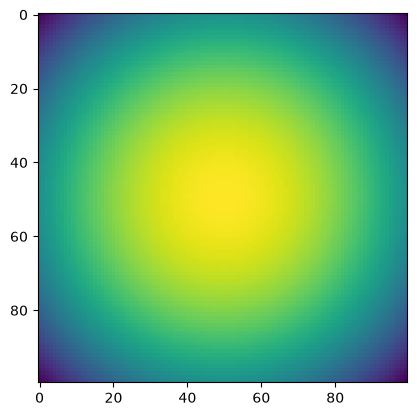

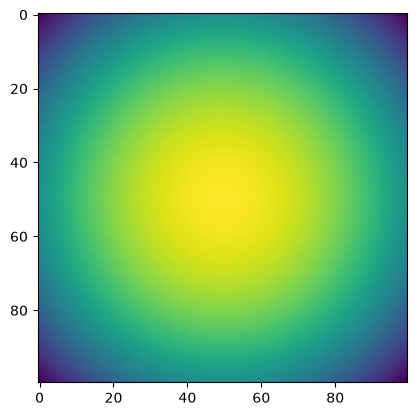

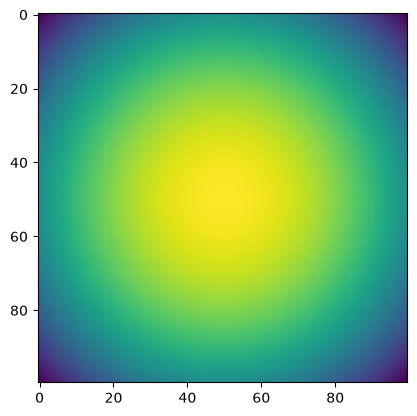

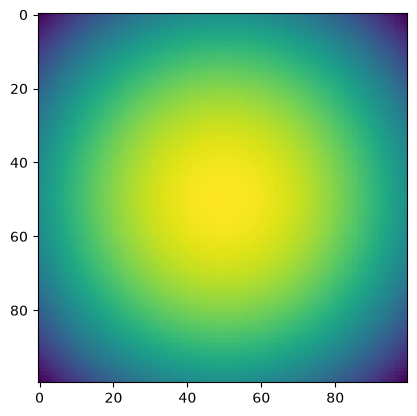

14100 0.19860336 time: 0.0018973350524902344
14200 0.19698186 time: 0.0019080638885498047
14300 0.18715854 time: 0.003064870834350586
14400 0.1945147 time: 0.0023047924041748047
14500 0.20578955 time: 0.0018222332000732422
14600 0.199894 time: 0.002168893814086914
14700 0.20678535 time: 0.0018405914306640625
14800 0.20958133 time: 0.001766204833984375
14900 0.21060047 time: 0.0017616748809814453
15000 0.21699855 time: 0.001758575439453125


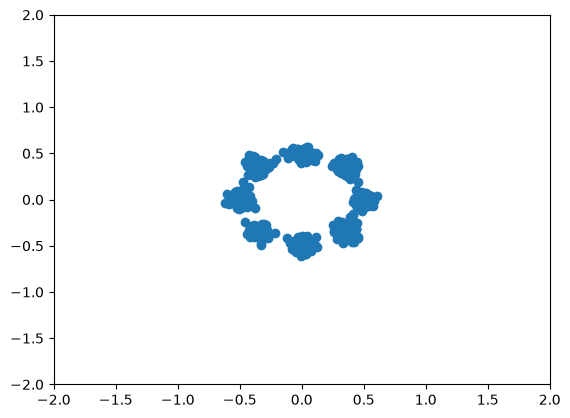

TEST 15000 logpx 1.6398684


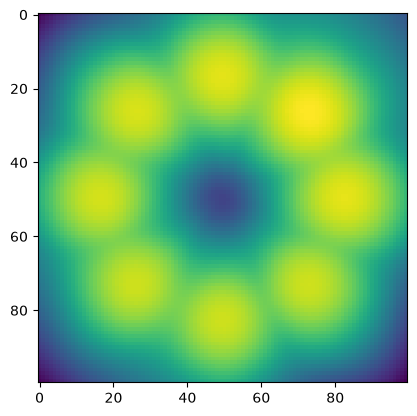

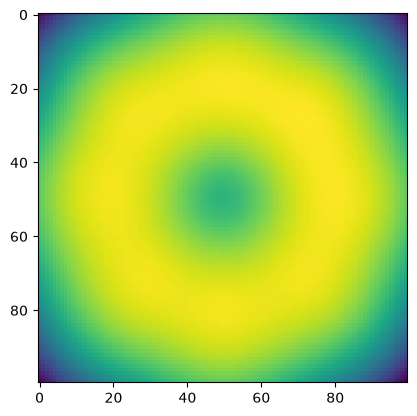

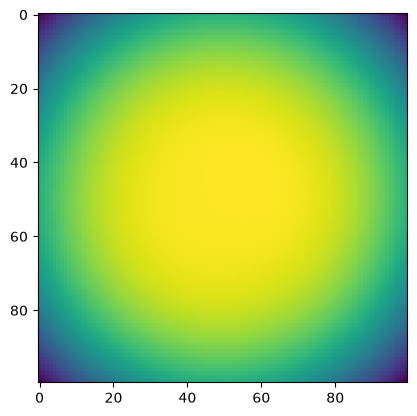

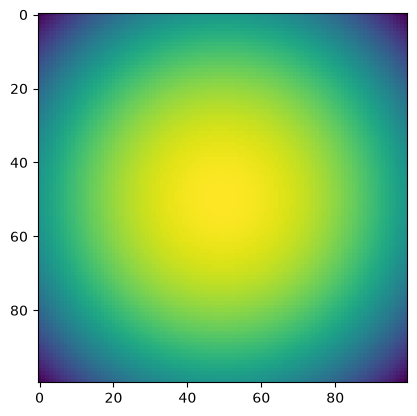

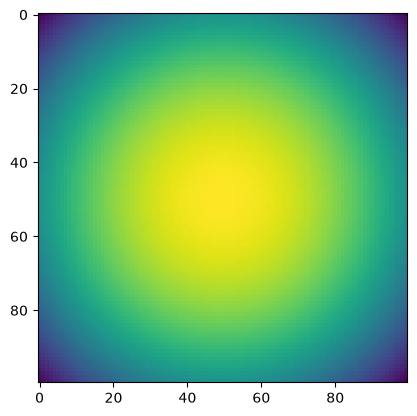

...

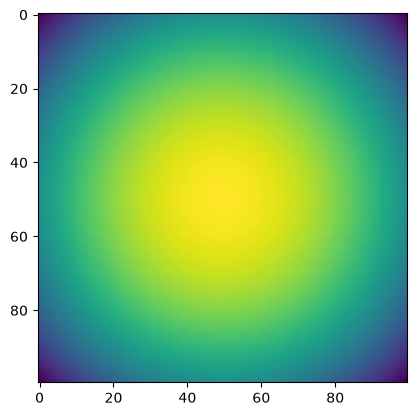

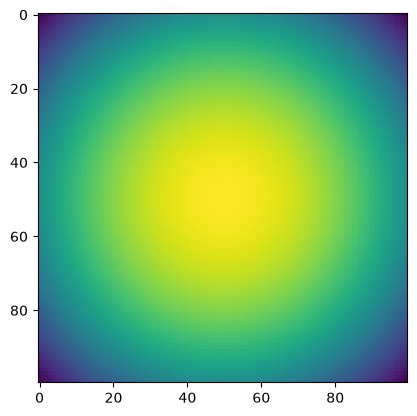

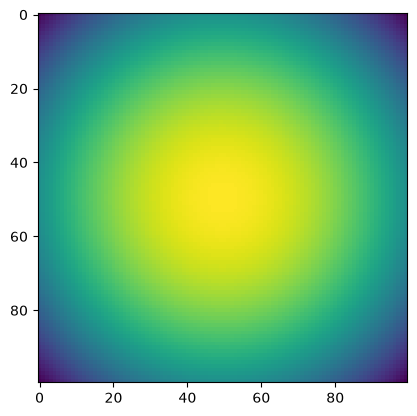

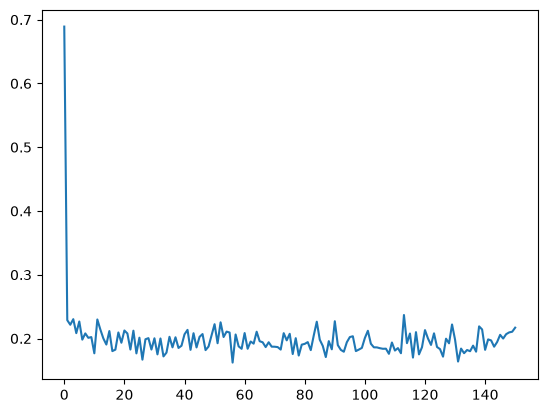

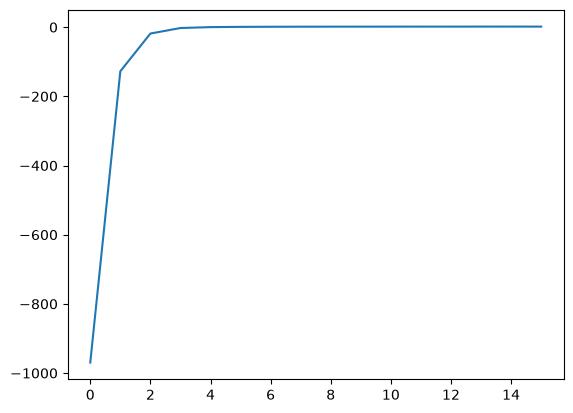

In [28]:
# Train Spiral EBM Model
batch_size = 1000
data_dim = 2
num_steps = 15001

EMA = .999

n_steps = 100
net_params = {"n_layers": 4,
              "h_dim": 128,
              "emb_dim": 32}

def forward_fn():
  net = ResnetDiffusionModel(n_steps=n_steps, n_layers=4, x_dim=data_dim, h_dim=128, emb_dim=32)

  if ebm:
    net = EBMDiffusionModel(net)

  ddpm = PortableDiffusionModel(data_dim, n_steps, net, var_type="beta_forward")

  def logp_unnorm(x, t):
    scale_e = ddpm.energy_scale(-2 - t)
    t = jnp.ones((x.shape[0],), dtype=jnp.int32) * t
    return -net.neg_logp_unnorm(x, t) * scale_e

  def _logpx(x):
    return ddpm.logpx(x)["logpx"]
  return ddpm.loss, (ddpm.loss, ddpm.sample, _logpx, logp_unnorm)

forward = hk.multi_transform(forward_fn)
rng_seq = hk.PRNGSequence(0)

xr = [-.75, .75]
yr = [-.75, .75]


def plot_samples(x):
  plt.scatter(x[:, 0], x[:, 1])
  plt.xlim(-2, 2)
  plt.ylim(-2, 2)

def dist_show_2d(fn, xr, yr):
    nticks = 100
    x, y = np.meshgrid(np.linspace(xr[0], xr[1], nticks), np.linspace(yr[0], yr[1], nticks))
    coord = np.stack([x, y], axis=-1).reshape((-1, 2))
    heatmap = fn(coord).reshape((nticks, nticks))
    plt.imshow(heatmap)

# load data
dataset_energy, dataset_sample = toy_gmm(std=.03)
x = dataset_sample(batch_size)

plot_samples(x)
plt.show()
x = x.reshape(x.shape[0], -1)


params = forward.init(next(rng_seq), x)
loss_fn, sample_fn, logpx_fn, logp_unnorm_fn = forward.apply
param_count = sum(x.size for x in jax.tree_leaves(params))
for k, v in jax.tree_map(lambda x: x.shape, params).items():
  print(k, v)
print("Model has {} params".format(param_count))


opt = optax.adam(1e-3)
opt_state = opt.init(params)

sample_fn = jax.jit(sample_fn, static_argnums=2)
logpx_fn = jax.jit(logpx_fn)

logp_unnorm_fn = jax.jit(logp_unnorm_fn)

@jax.jit
def mean_loss_fn(params, rng, x):
  loss = loss_fn(params, rng, x)
  return loss.mean()

@jax.jit
def update(params, opt_state, rng, x):
  loss, grad = jax.value_and_grad(mean_loss_fn)(params, rng, x)

  updates, opt_state = opt.update(grad, opt_state)
  new_params = optax.apply_updates(params, updates)
  return loss, new_params, opt_state

# Speed-only change (no maths changed): the moving average runs inside one compiled call
# instead of one small GPU operation per weight array, about 10x faster per step.
@jax.jit
def update_ema(params, ema_params, opt_state, rng, x):
  loss, params, opt_state = update(params, opt_state, rng, x)
  ema_params = jax.tree_util.tree_map(lambda e, p: e * EMA + p * (1 - EMA), ema_params, params)
  return loss, params, ema_params, opt_state

ema_params = params
losses = []
test_logpx = []
itr = 0

for itr in range(num_steps):
  x = dataset_sample(batch_size)

  x = x.reshape(x.shape[0], -1)
  start_time = time.time()
  loss, params, ema_params, opt_state = update_ema(params, ema_params, opt_state, next(rng_seq), x)
  duration_update = time.time() - start_time

  if itr % 100 == 0:
    print(itr, loss, "time:", duration_update)
    losses.append(loss)
  if itr % 1000 == 0:
    x_samp = sample_fn(ema_params, next(rng_seq), batch_size)
    plot_samples(x_samp)
    plt.show()
    logpx = logpx_fn(ema_params, next(rng_seq), x).mean()
    print("TEST", itr, 'logpx', logpx)
    test_logpx.append(logpx)

    if ebm:
      for t in range(10):
        dist_show_2d(lambda x: logp_unnorm_fn(ema_params, next(rng_seq), x, 10*t), xr=xr, yr=yr)
        plt.show()

plt.plot(losses)
plt.show()
plt.plot(test_logpx)

flow_params = params
flow_rng = next(rng_seq)

spiral_params = ema_params

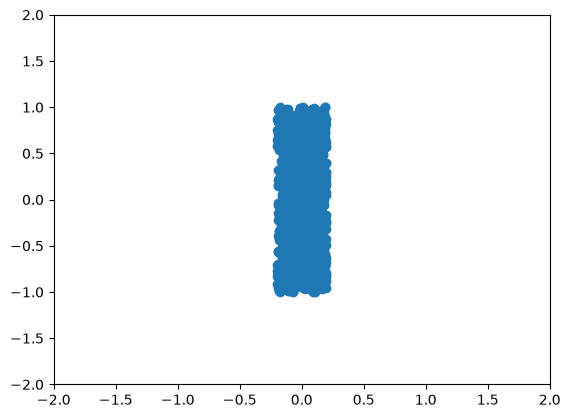

portable_diffusion_model {'out_logvar': (100,)}
resnet_diffusion_model/embed {'embeddings': (100, 32)}
resnet_diffusion_model/layer_norm {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/layer_norm_1 {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/layer_norm_2 {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/layer_norm_3 {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/linear {'b': (128,), 'w': (2, 128)}
resnet_diffusion_model/linear_1 {'b': (256,), 'w': (128, 256)}
resnet_diffusion_model/linear_10 {'b': (256,), 'w': (32, 256)}
resnet_diffusion_model/linear_11 {'b': (256,), 'w': (256, 256)}
resnet_diffusion_model/linear_12 {'b': (128,), 'w': (256, 128)}
resnet_diffusion_model/linear_13 {'b': (256,), 'w': (128, 256)}
resnet_diffusion_model/linear_14 {'b': (256,), 'w': (32, 256)}
resnet_diffusion_model/linear_15 {'b': (256,), 'w': (256, 256)}
resnet_diffusion_model/linear_16 {'b': (128,), 'w': (256, 128)}
resnet_diffusion_model/linear_17 {'b': (2,)

/tmp/ipykernel_1391087/1385371818.py:265: UserWarning: Explicitly requested dtype int64 requested in ones is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  t = jnp.ones((n,), dtype=jnp.int64) * j


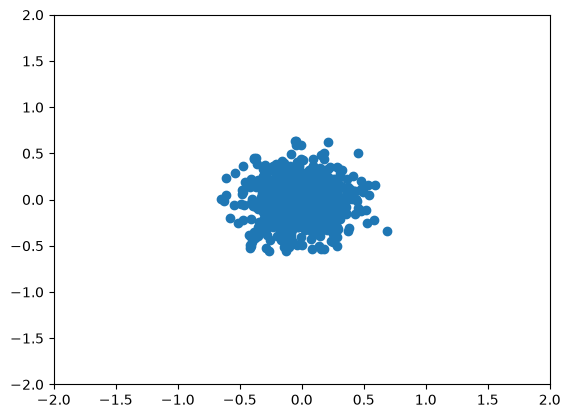

/tmp/ipykernel_1391087/1385371818.py:235: UserWarning: Explicitly requested dtype int64 requested in ones is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  t = jnp.ones((x_0.shape[0],), dtype=jnp.int64) * (self._n_steps - 1)


TEST 0 logpx -971.1814


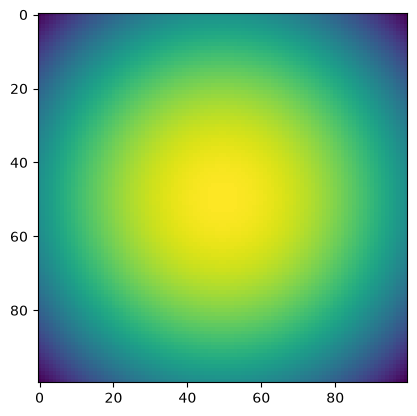

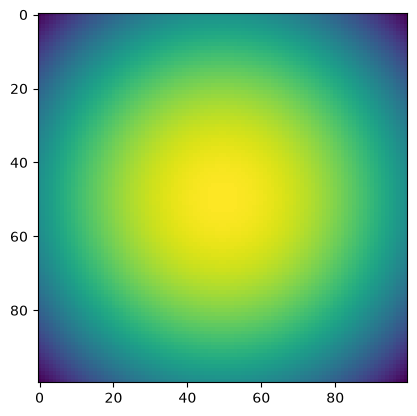

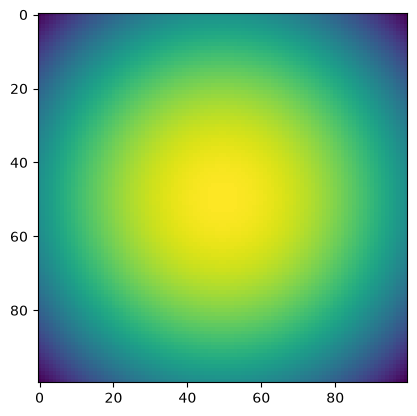

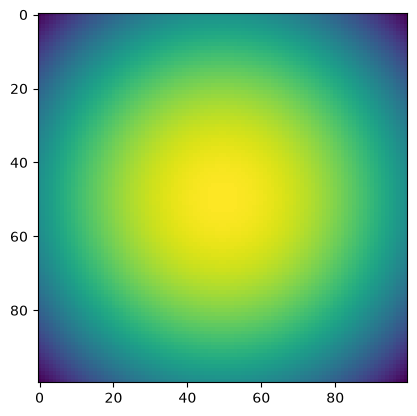

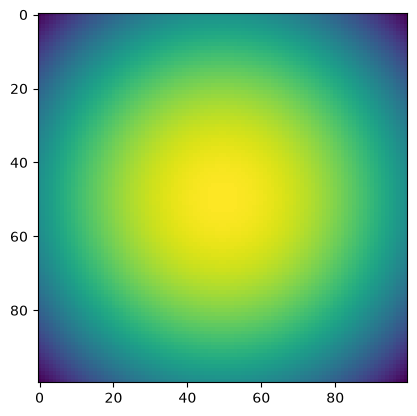

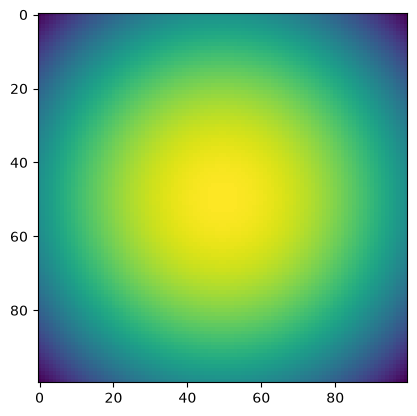

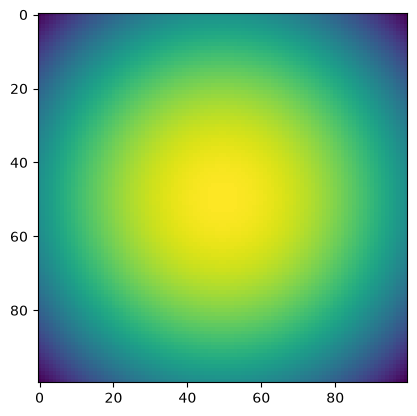

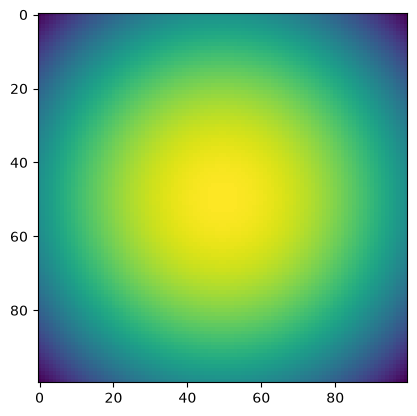

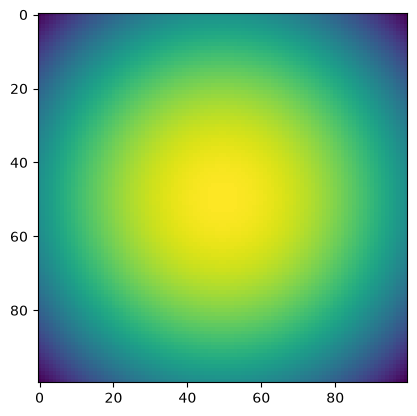

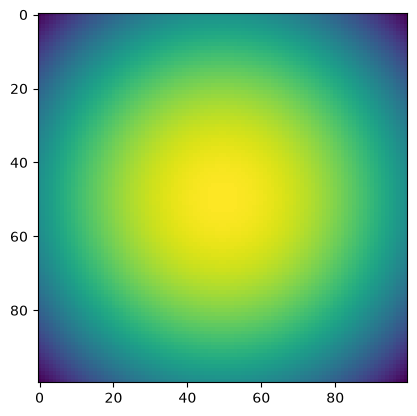

100 0.22129992 time: 0.0016646385192871094
200 0.21721107 time: 0.0020377635955810547
300 0.20286427 time: 0.003612995147705078
400 0.2262092 time: 0.0017278194427490234
500 0.23344046 time: 0.0019044876098632812
600 0.21050815 time: 0.002294301986694336
700 0.22140123 time: 0.0016889572143554688
800 0.21415037 time: 0.0018444061279296875
900 0.21656726 time: 0.001783132553100586
1000 0.20817311 time: 0.0023322105407714844


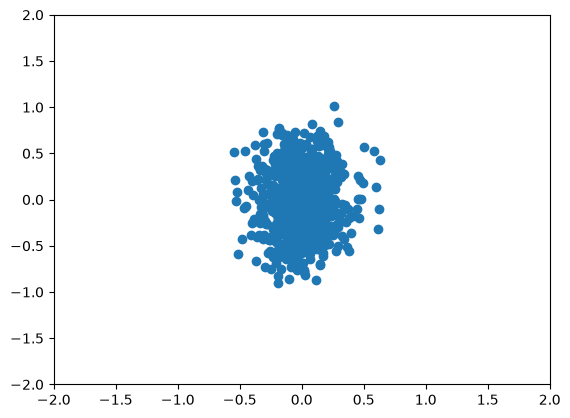

TEST 1000 logpx -135.33684


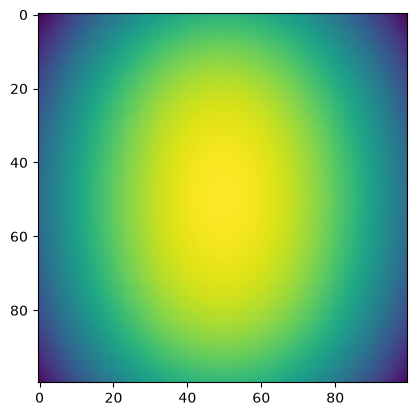

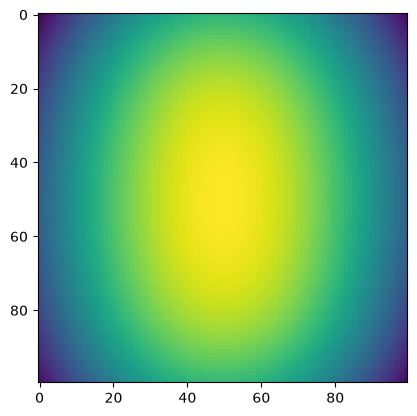

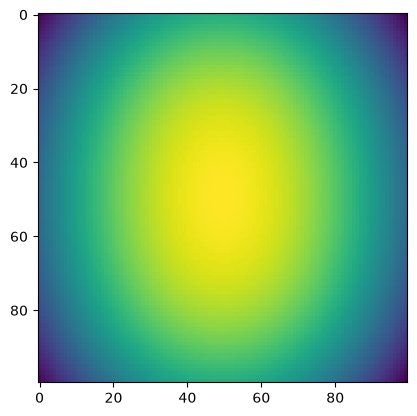

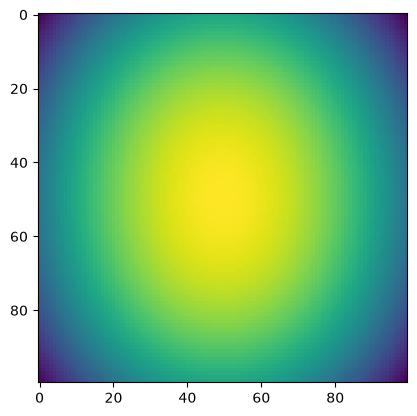

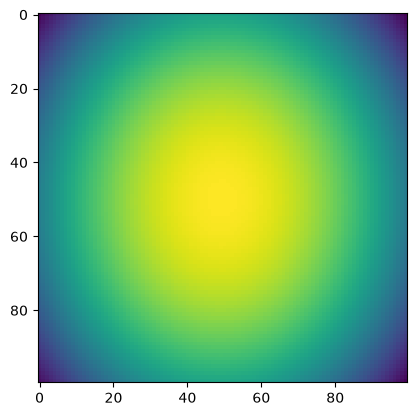

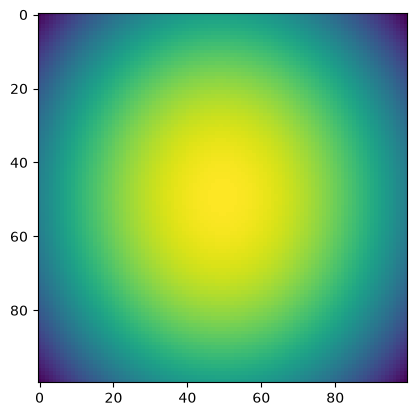

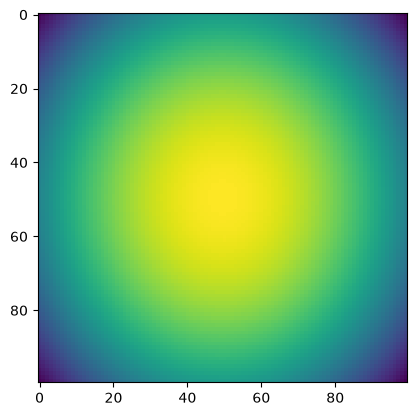

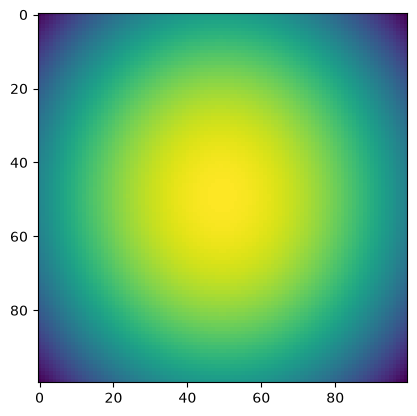

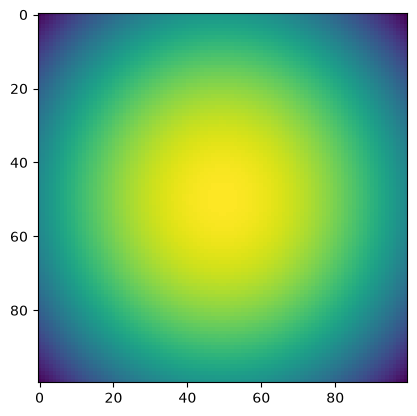

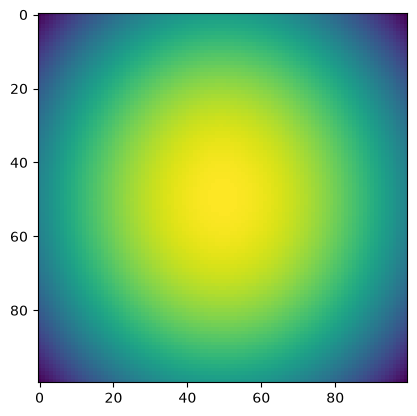

1100 0.2508796 time: 0.003343343734741211
1200 0.22599296 time: 0.0034074783325195312
1300 0.21062148 time: 0.0019099712371826172
1400 0.21659096 time: 0.003690958023071289
1500 0.20204124 time: 0.002035379409790039
1600 0.19052546 time: 0.0025327205657958984
1700 0.2113331 time: 0.002116680145263672
1800 0.21974254 time: 0.0018801689147949219
1900 0.2170438 time: 0.0036439895629882812
2000 0.21497208 time: 0.001913309097290039


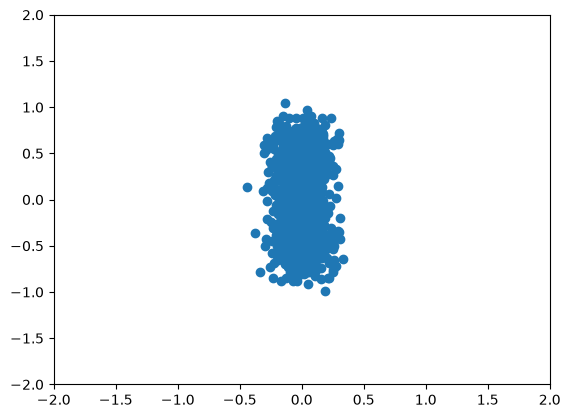

TEST 2000 logpx -17.702234


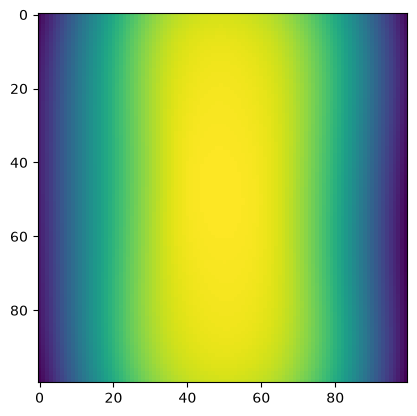

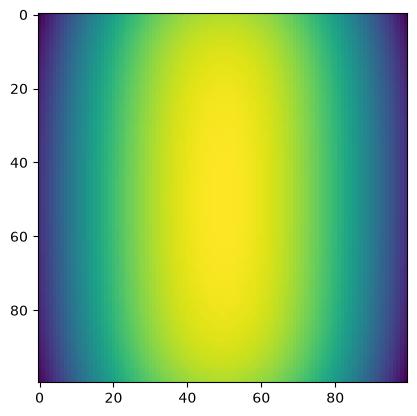

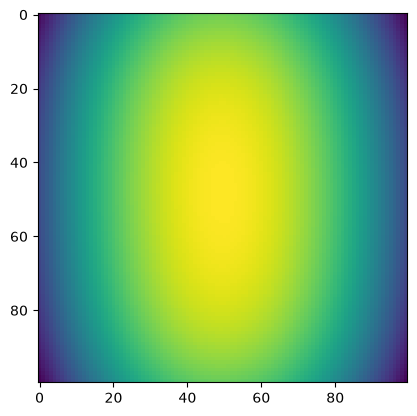

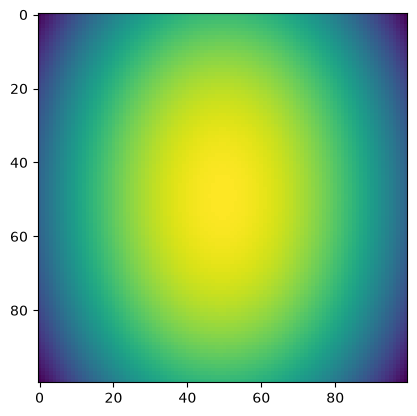

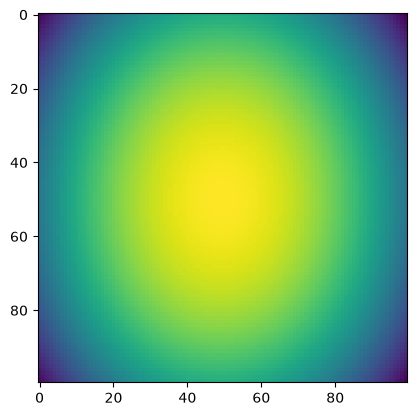

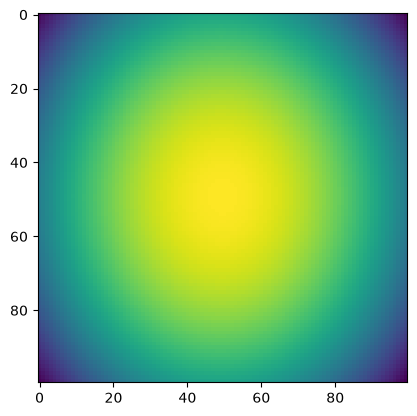

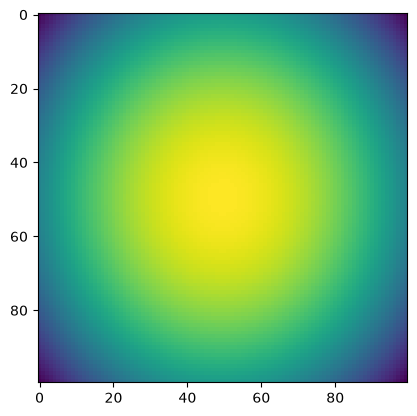

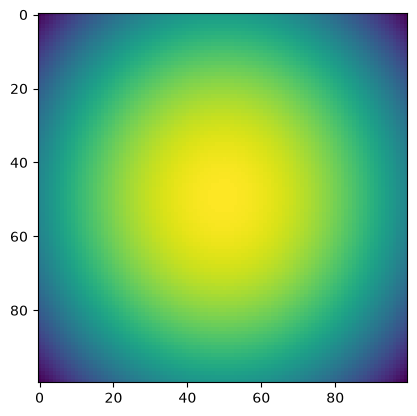

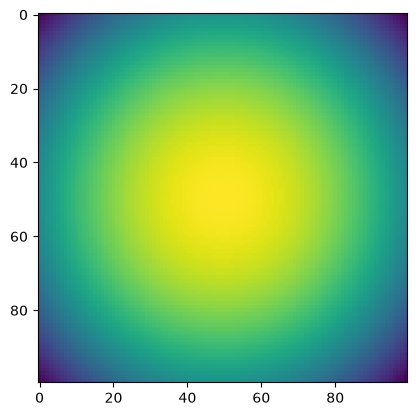

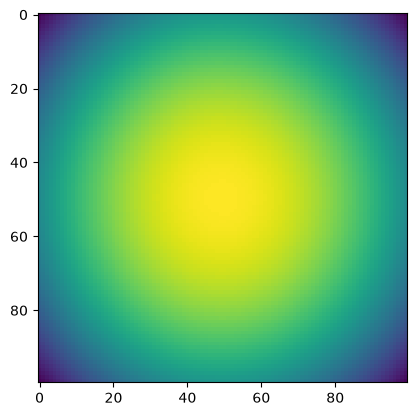

2100 0.22322017 time: 0.001827239990234375
2200 0.22065003 time: 0.0018930435180664062
2300 0.23009628 time: 0.0018572807312011719
2400 0.20818281 time: 0.0018682479858398438
2500 0.22126225 time: 0.00173187255859375
2600 0.21568687 time: 0.0035181045532226562
2700 0.22389393 time: 0.003571748733520508
2800 0.21624033 time: 0.0032813549041748047
2900 0.2292162 time: 0.0017671585083007812
3000 0.21463917 time: 0.001982450485229492


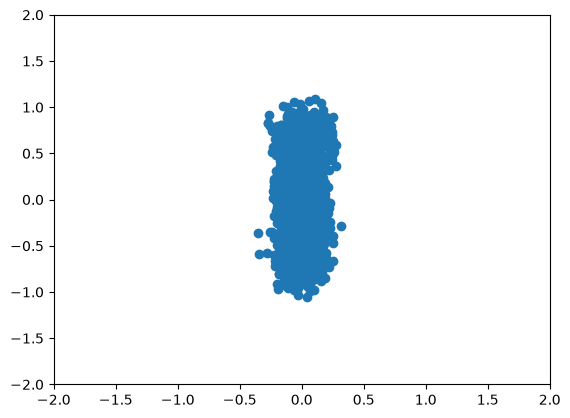

TEST 3000 logpx -2.9365299


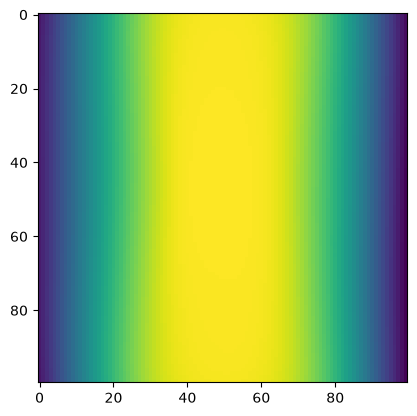

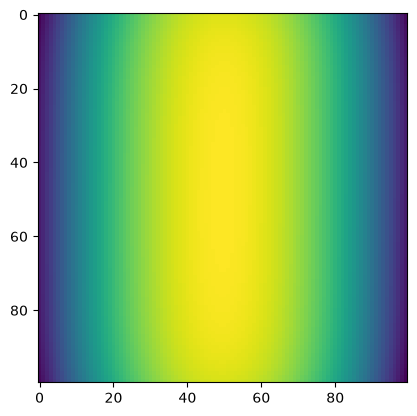

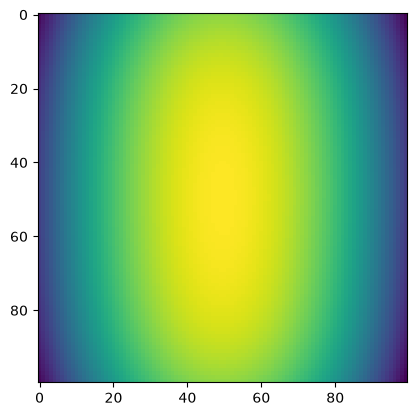

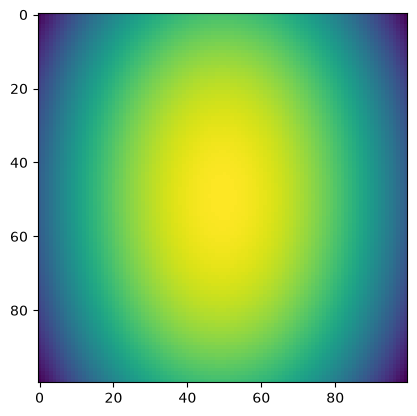

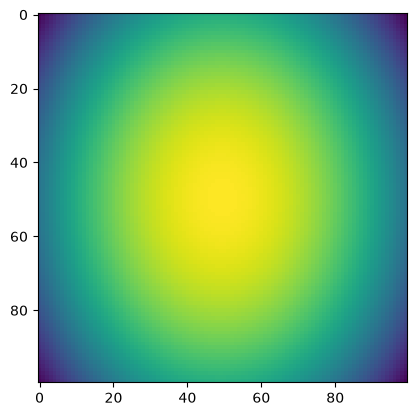

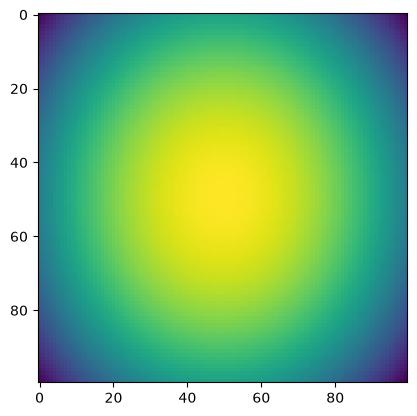

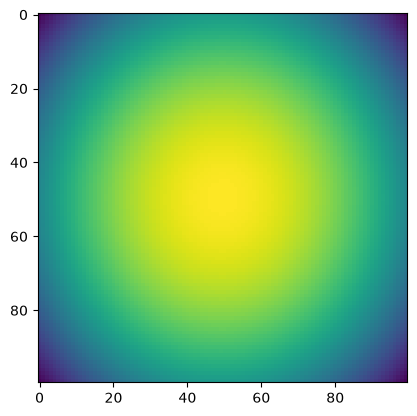

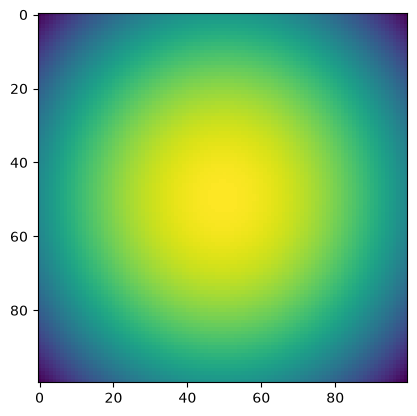

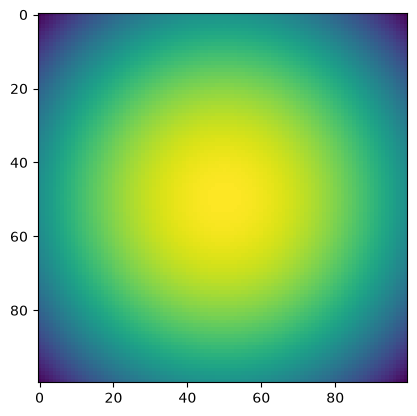

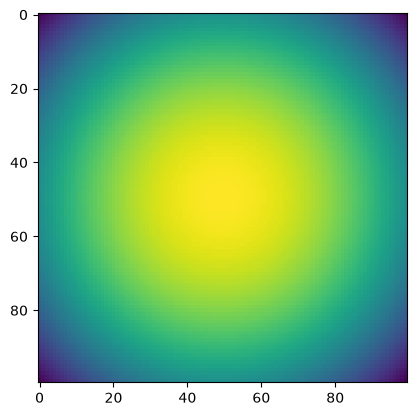

3100 0.1997314 time: 0.0020568370819091797
3200 0.2116356 time: 0.0021326541900634766
3300 0.19976969 time: 0.0018620491027832031
3400 0.21183896 time: 0.0017900466918945312
3500 0.2077107 time: 0.0018911361694335938
3600 0.19986033 time: 0.0030112266540527344
3700 0.22729807 time: 0.003464937210083008
3800 0.21011876 time: 0.002158641815185547
3900 0.2029916 time: 0.0018017292022705078
4000 0.22317396 time: 0.004084348678588867


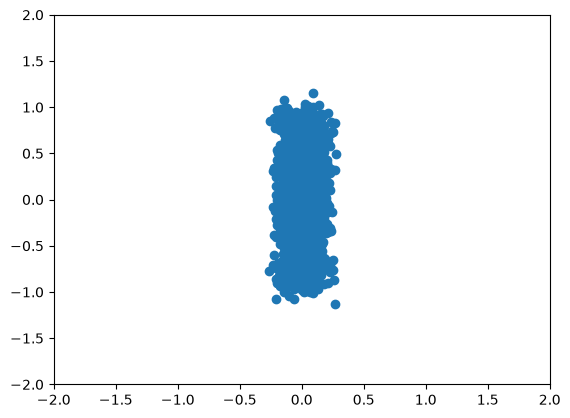

TEST 4000 logpx -0.70360285


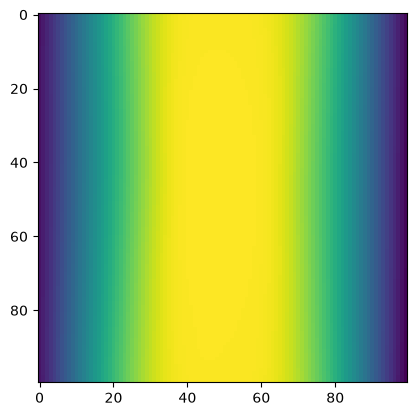

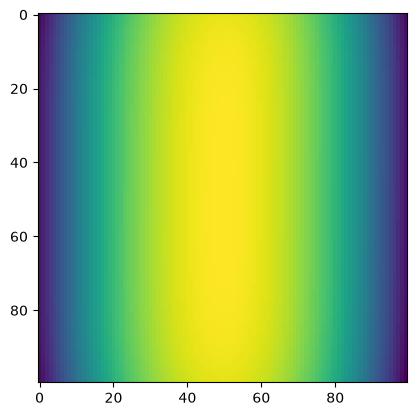

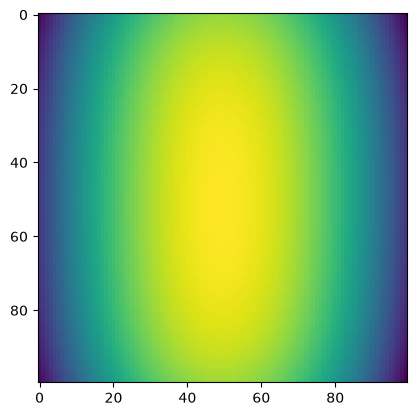

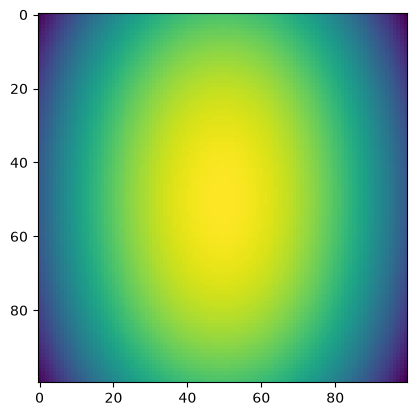

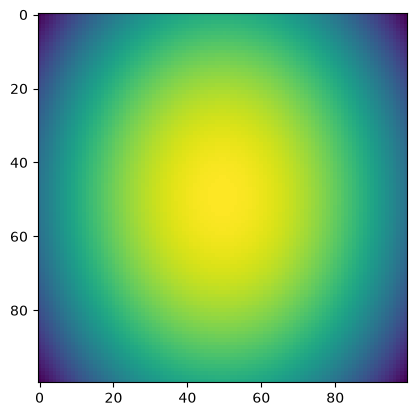

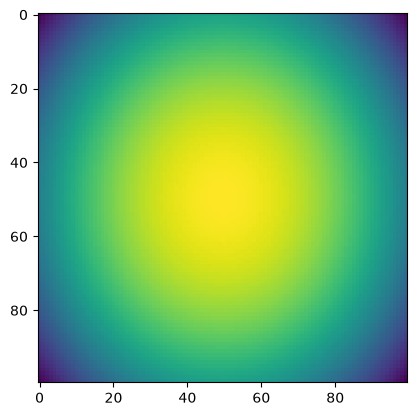

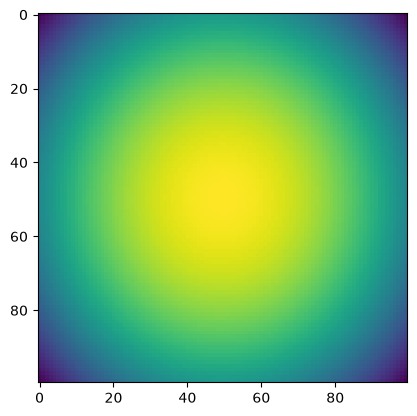

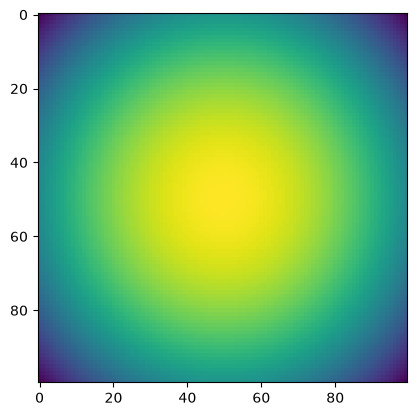

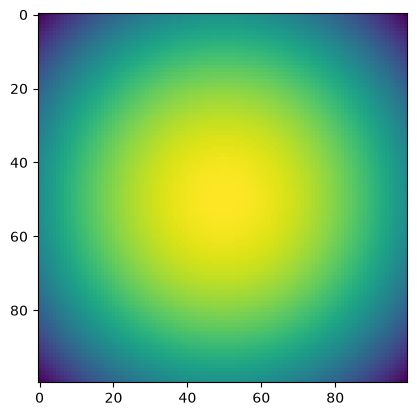

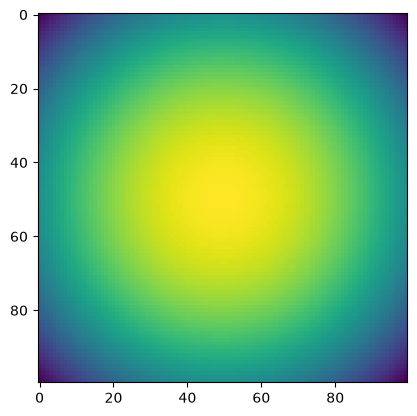

4100 0.22324993 time: 0.0018284320831298828
4200 0.23296002 time: 0.002618551254272461
4300 0.23809187 time: 0.0017614364624023438
4400 0.19545005 time: 0.001720428466796875
4500 0.22629488 time: 0.0018095970153808594
4600 0.22243266 time: 0.0032219886779785156
4700 0.21923268 time: 0.0037376880645751953
4800 0.21414989 time: 0.003579378128051758
4900 0.23478645 time: 0.0017883777618408203
5000 0.23202106 time: 0.001798391342163086


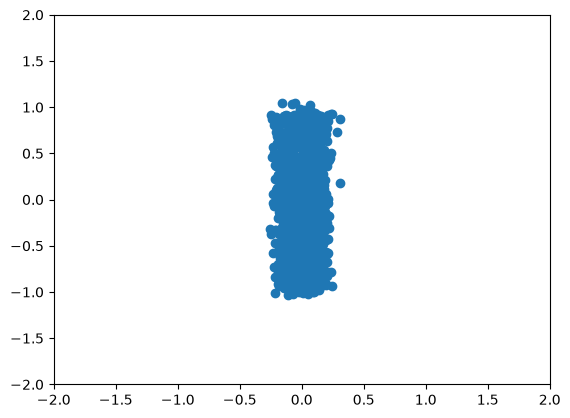

TEST 5000 logpx -0.21117814


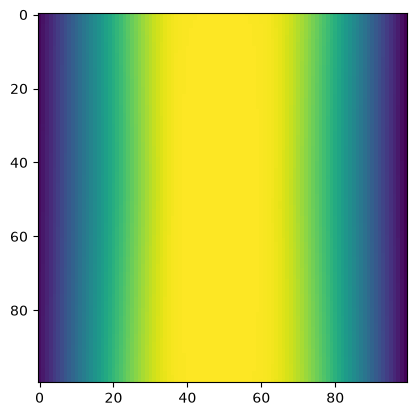

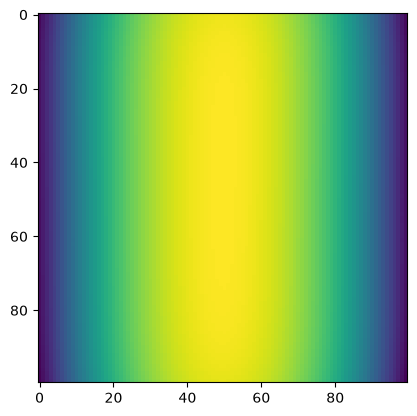

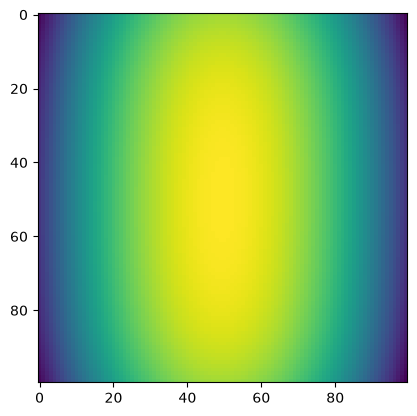

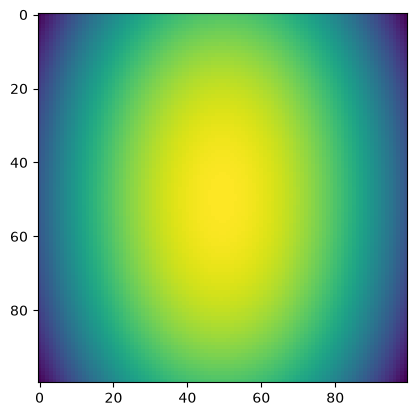

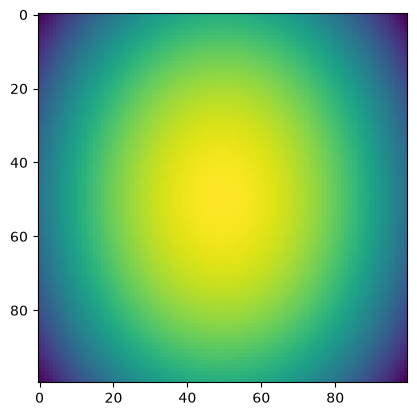

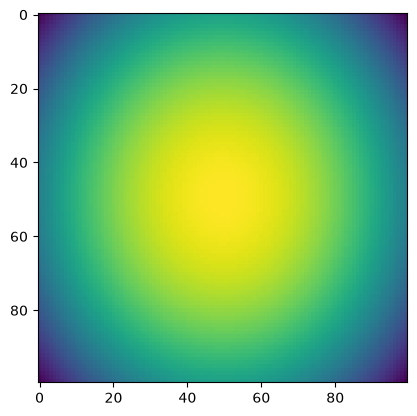

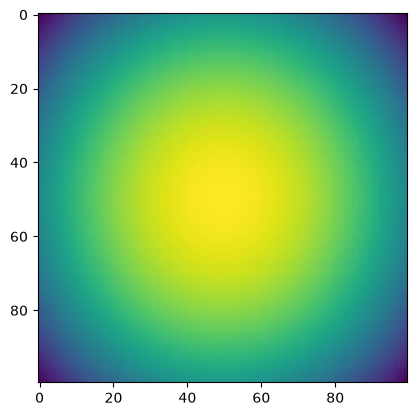

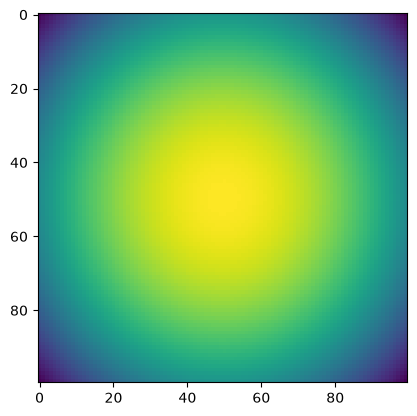

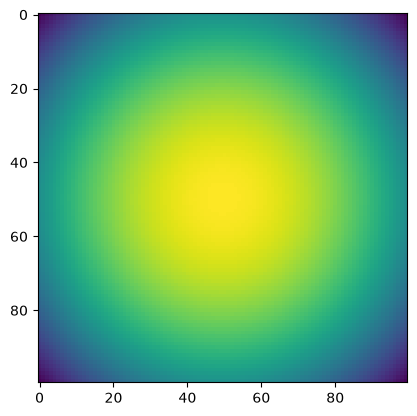

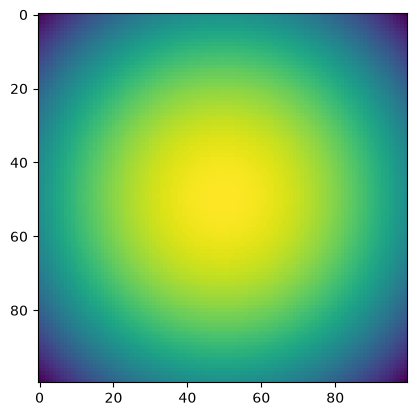

5100 0.23088951 time: 0.001882791519165039
5200 0.22553575 time: 0.0017061233520507812
5300 0.21952367 time: 0.0017576217651367188
5400 0.23324192 time: 0.001741647720336914
5500 0.21636848 time: 0.0017938613891601562
5600 0.20079082 time: 0.0020198822021484375
5700 0.22621089 time: 0.0032668113708496094
5800 0.20485058 time: 0.0017538070678710938
5900 0.19982901 time: 0.002557039260864258
6000 0.2413969 time: 0.001758575439453125


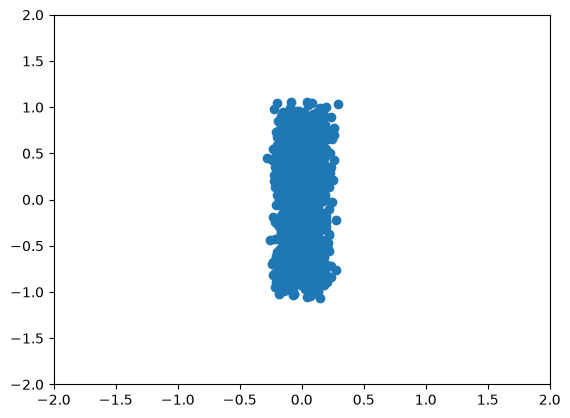

TEST 6000 logpx -0.14349252


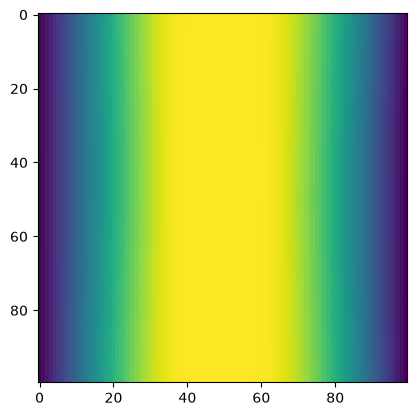

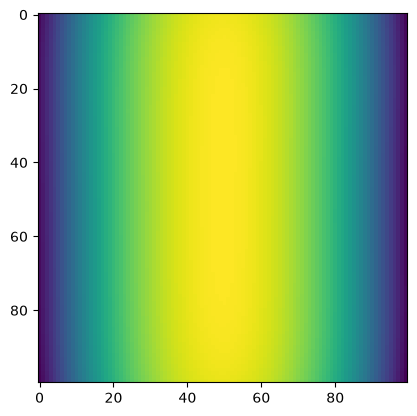

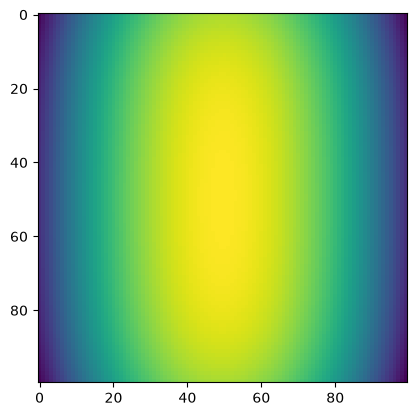

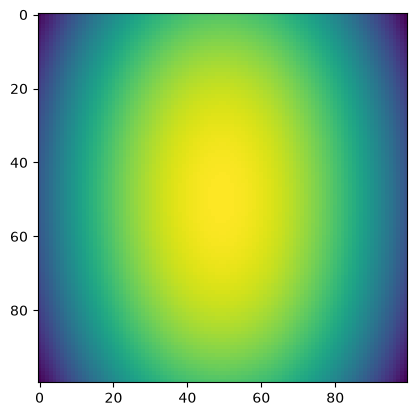

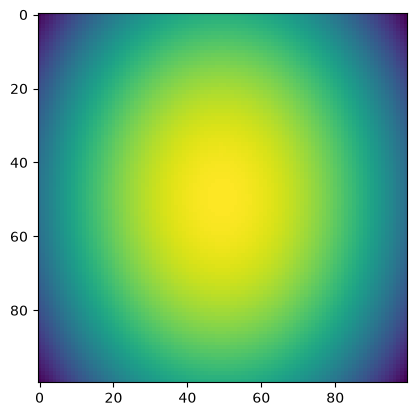

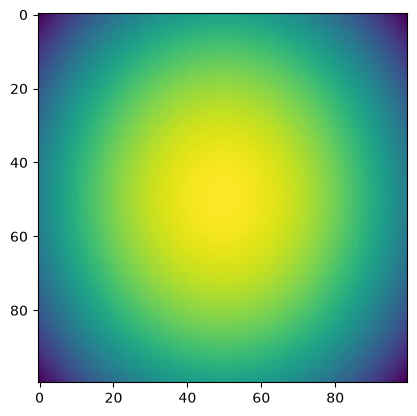

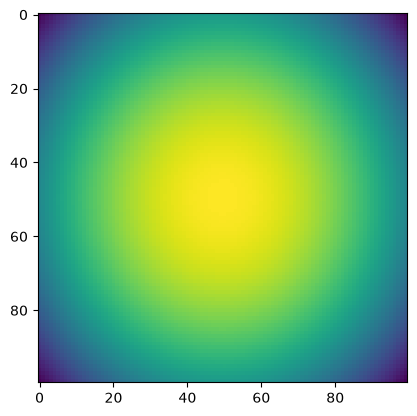

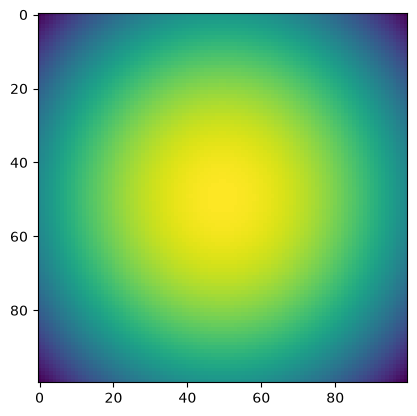

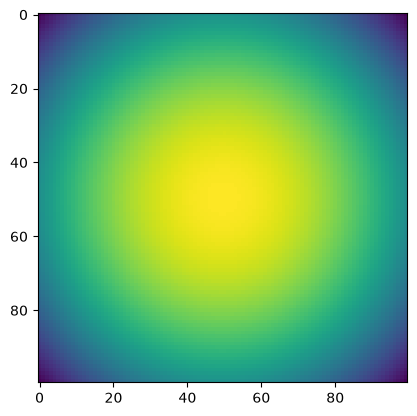

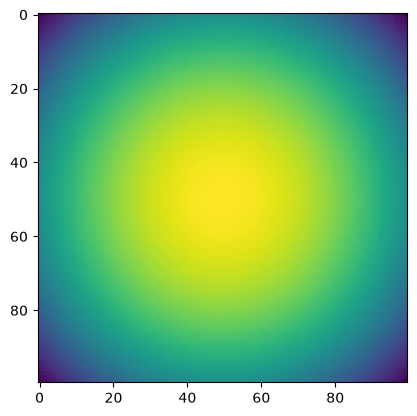

6100 0.20697694 time: 0.003457307815551758
6200 0.21580619 time: 0.002156496047973633
6300 0.21744365 time: 0.0034286975860595703
6400 0.24095319 time: 0.0017979145050048828
6500 0.20921314 time: 0.0017917156219482422
6600 0.21940252 time: 0.0018758773803710938
6700 0.22109556 time: 0.0022437572479248047
6800 0.2239495 time: 0.0018463134765625
6900 0.20766166 time: 0.0018584728240966797
7000 0.20945902 time: 0.0035910606384277344


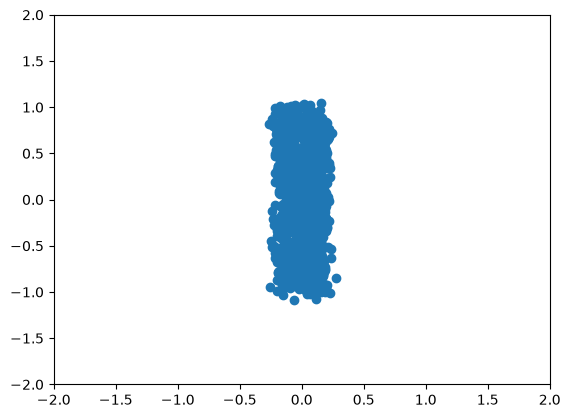

TEST 7000 logpx -0.0020983678


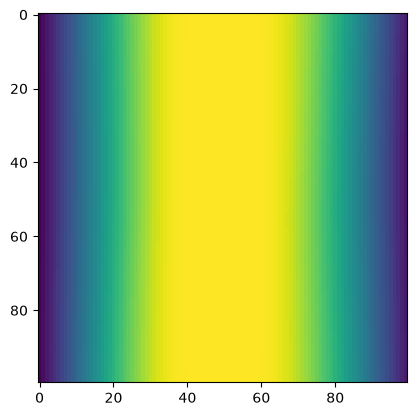

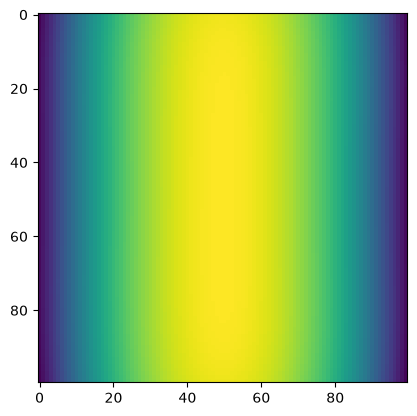

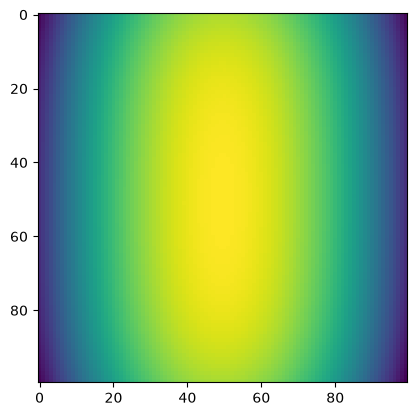

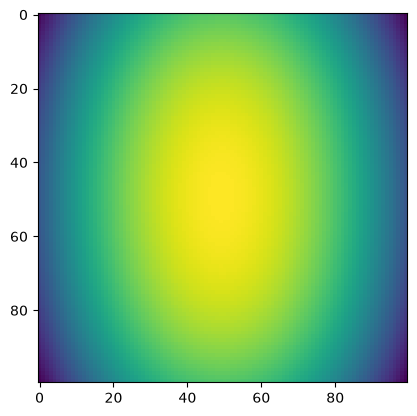

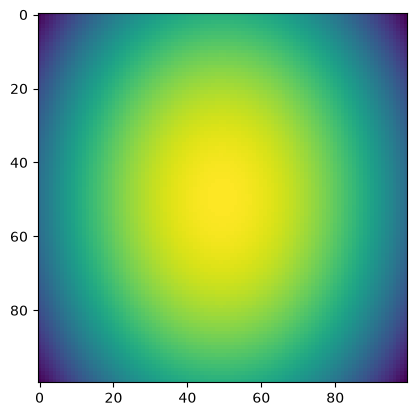

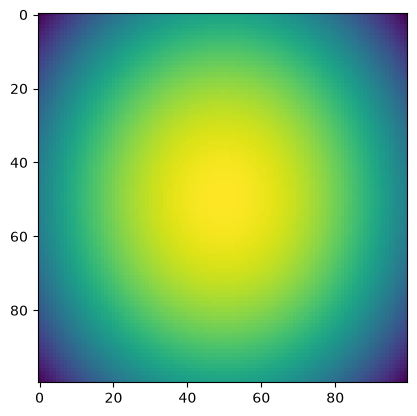

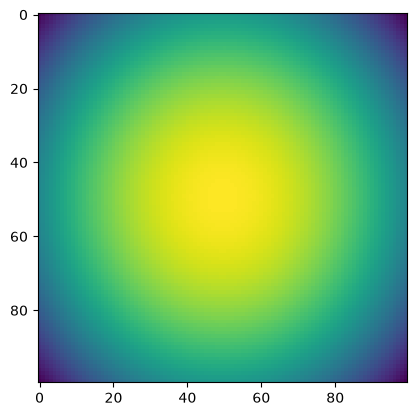

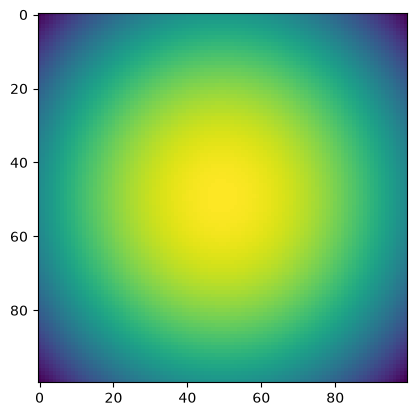

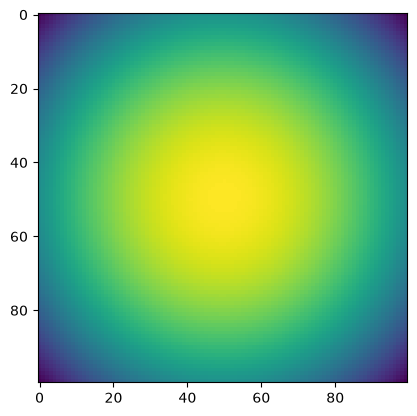

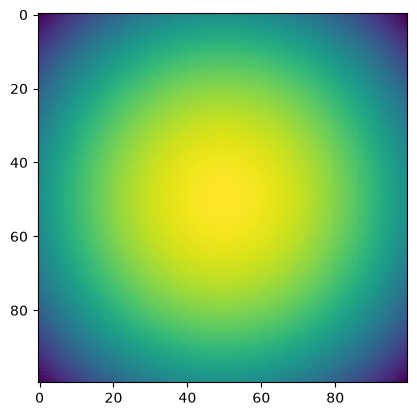

7100 0.21952434 time: 0.0017616748809814453
7200 0.20163928 time: 0.00228118896484375
7300 0.23193796 time: 0.0017409324645996094
7400 0.20597944 time: 0.001726388931274414
7500 0.22667892 time: 0.0017731189727783203
7600 0.21601316 time: 0.0016639232635498047
7700 0.2248236 time: 0.0017399787902832031
7800 0.20543334 time: 0.0032570362091064453
7900 0.20279273 time: 0.004103422164916992
8000 0.2092099 time: 0.0016579627990722656


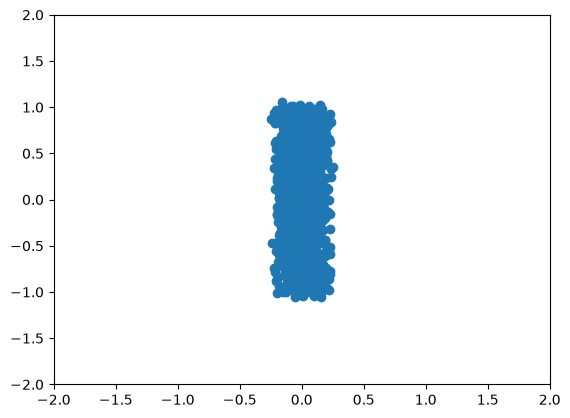

TEST 8000 logpx 0.15561591


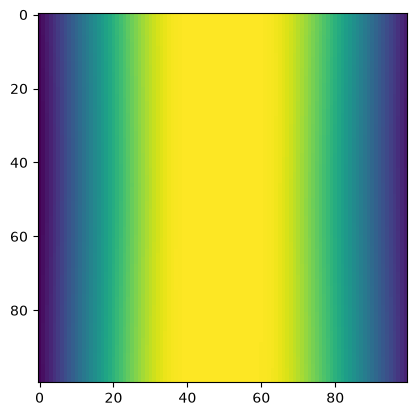

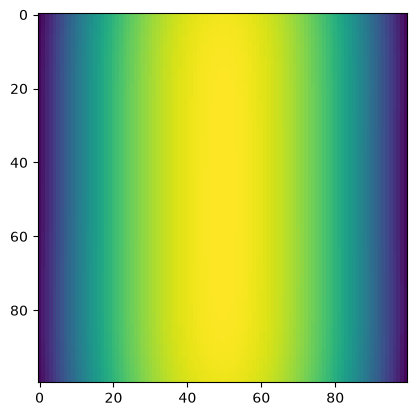

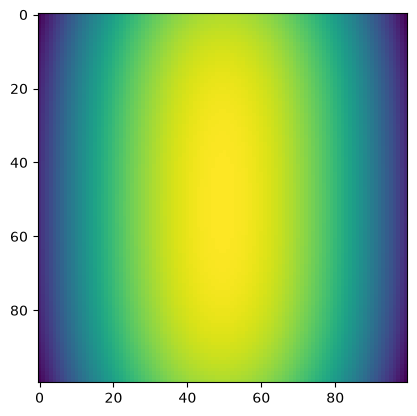

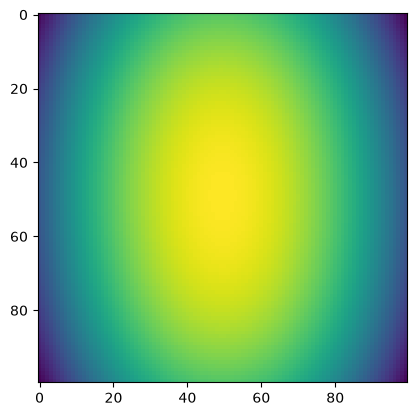

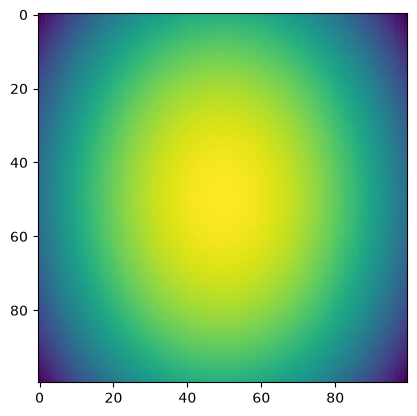

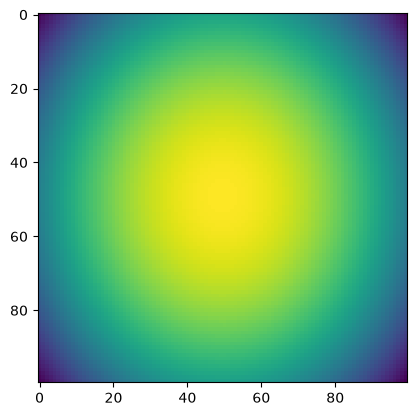

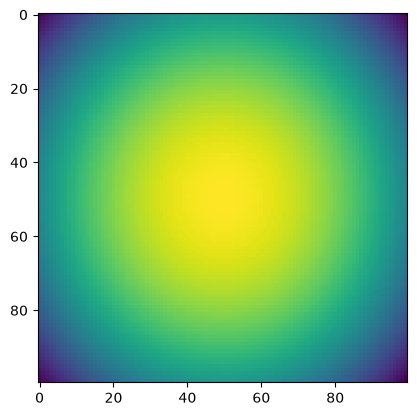

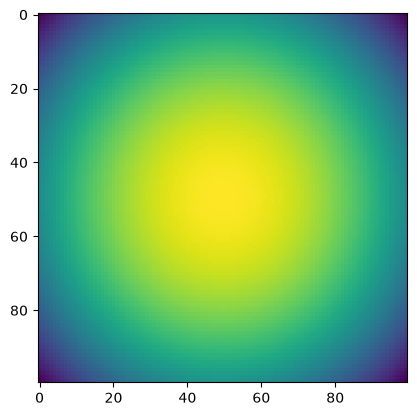

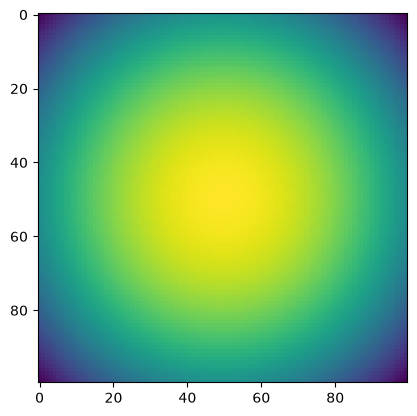

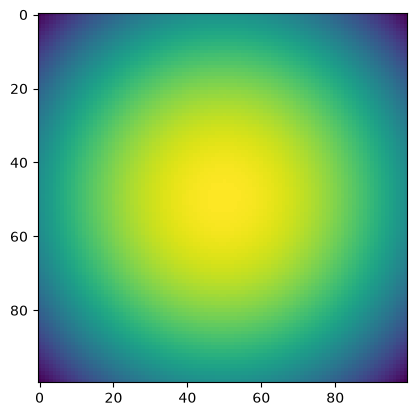

8100 0.20889835 time: 0.0038411617279052734
8200 0.20664026 time: 0.00196075439453125
8300 0.244343 time: 0.001735687255859375
8400 0.2412312 time: 0.0017590522766113281
8500 0.22683083 time: 0.0018320083618164062
8600 0.1974467 time: 0.0026750564575195312
8700 0.1932227 time: 0.0017206668853759766
8800 0.21273349 time: 0.003427267074584961
8900 0.2088708 time: 0.003744840621948242
9000 0.21797541 time: 0.0017402172088623047


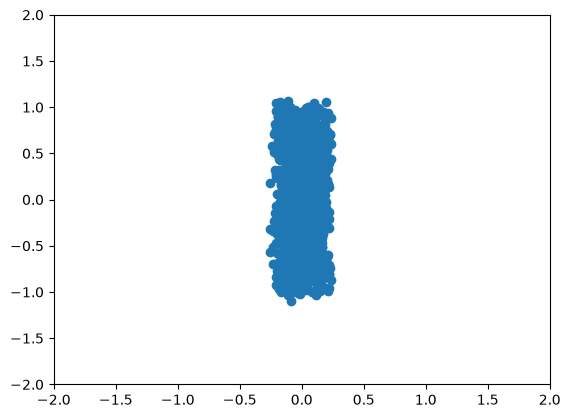

TEST 9000 logpx 0.15944628


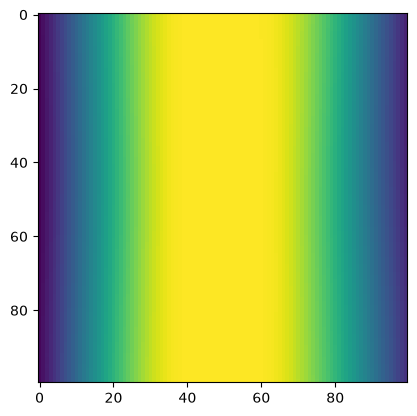

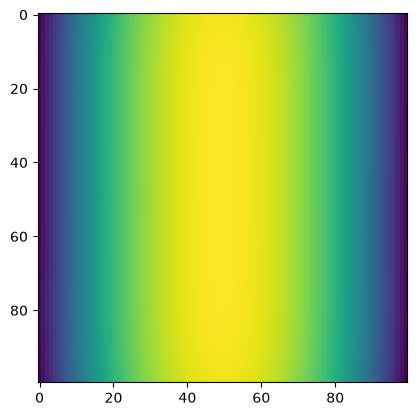

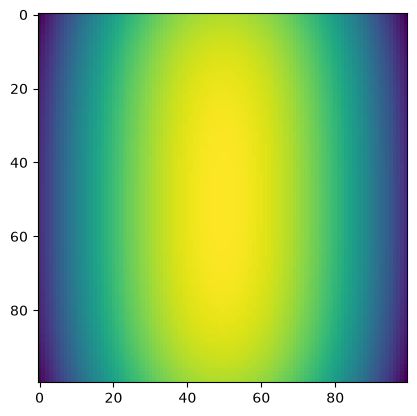

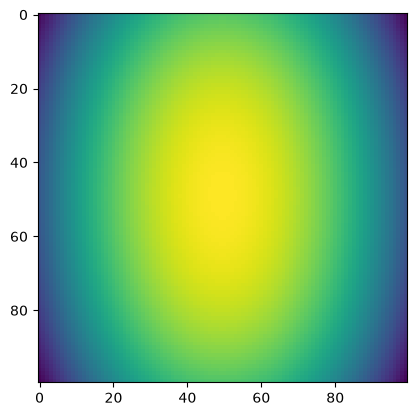

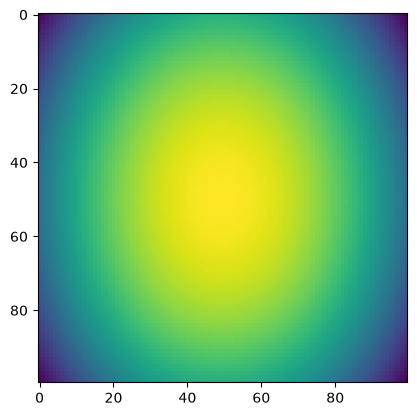

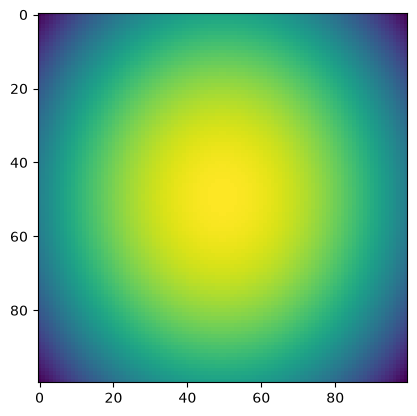

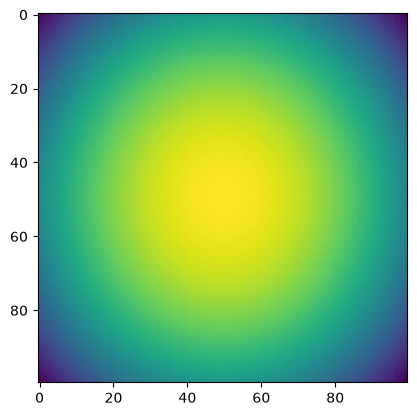

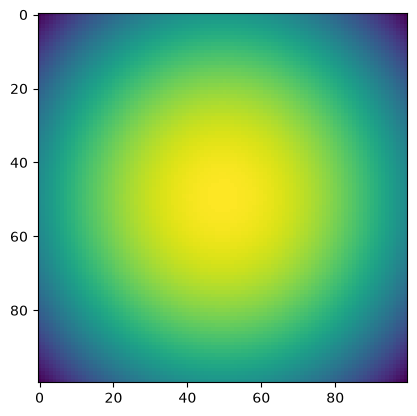

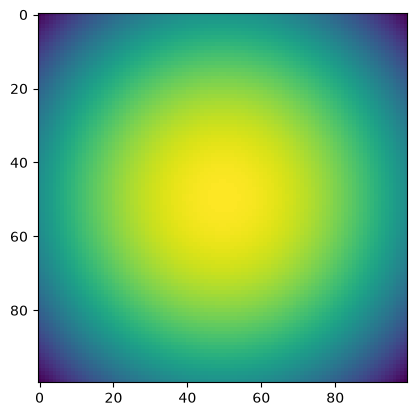

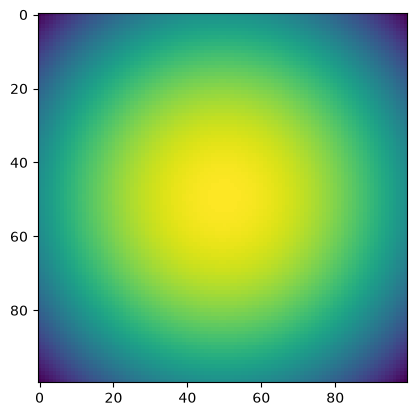

9100 0.2109061 time: 0.0018949508666992188
9200 0.2096142 time: 0.002069711685180664
9300 0.20702408 time: 0.0034265518188476562
9400 0.22285843 time: 0.0017867088317871094
9500 0.21482731 time: 0.0019767284393310547
9600 0.22928968 time: 0.0019414424896240234
9700 0.22583051 time: 0.0017881393432617188
9800 0.20685606 time: 0.005168914794921875
9900 0.21364915 time: 0.0019421577453613281
10000 0.22073478 time: 0.0018305778503417969


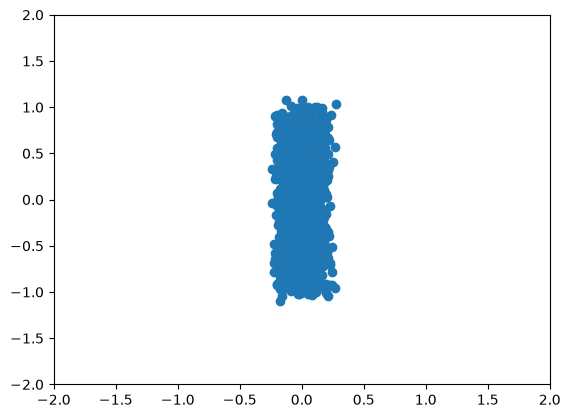

TEST 10000 logpx 0.22356795


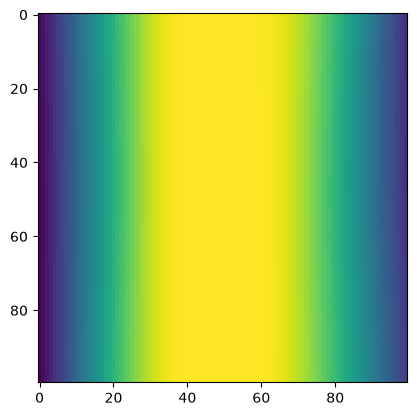

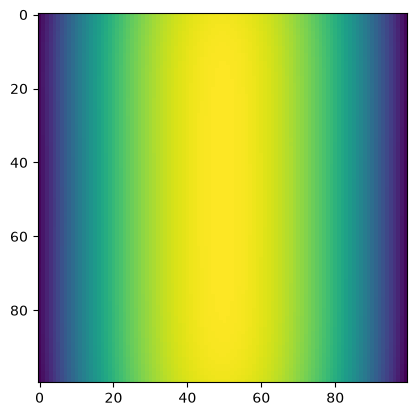

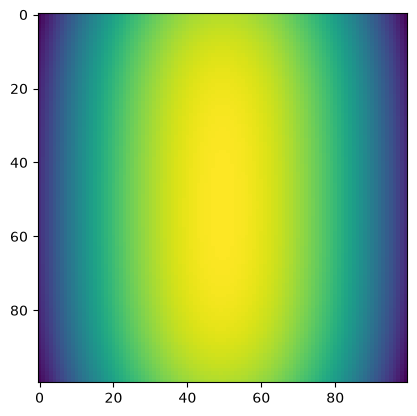

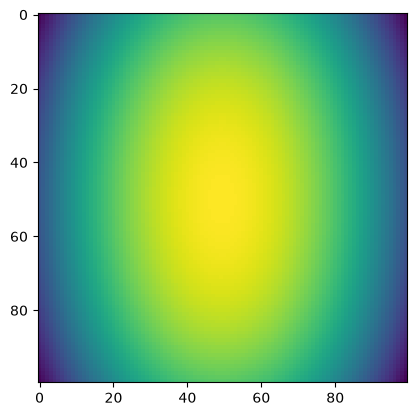

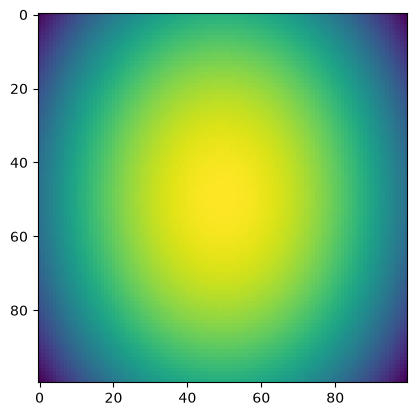

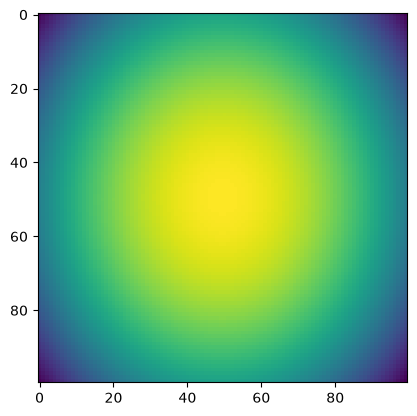

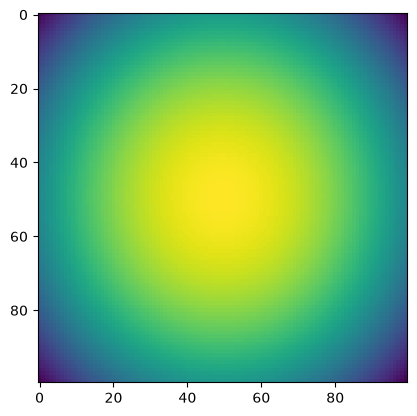

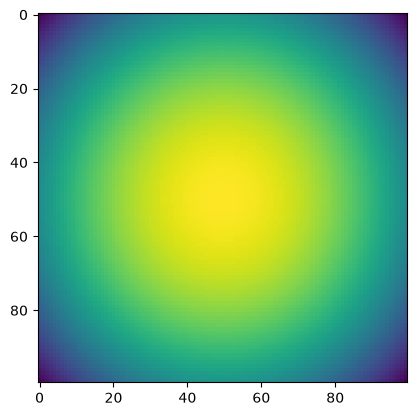

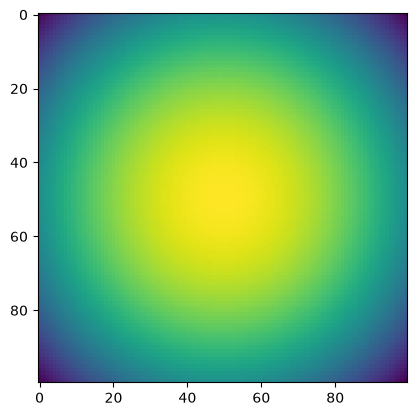

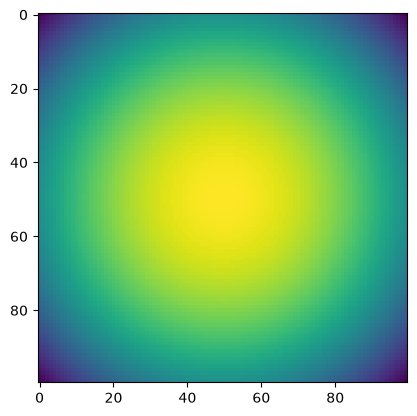

10100 0.21419162 time: 0.003675222396850586
10200 0.21276988 time: 0.0017957687377929688
10300 0.19454116 time: 0.0024421215057373047
10400 0.20055752 time: 0.001889944076538086
10500 0.20885083 time: 0.002038717269897461
10600 0.23530594 time: 0.0017549991607666016
10700 0.19461222 time: 0.0018298625946044922
10800 0.2088211 time: 0.0018622875213623047
10900 0.22999817 time: 0.004263162612915039
11000 0.20209019 time: 0.0018067359924316406


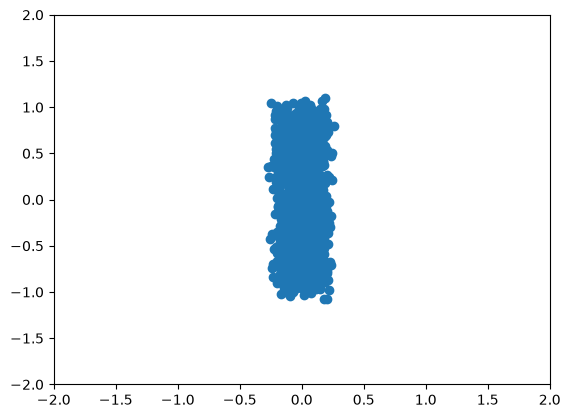

TEST 11000 logpx 0.21403968


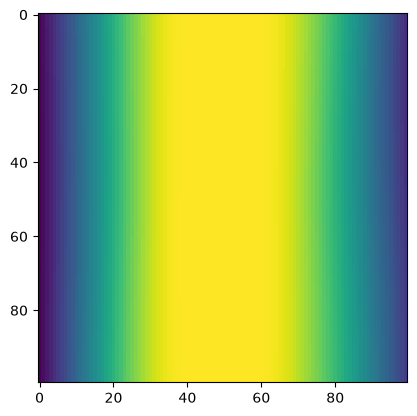

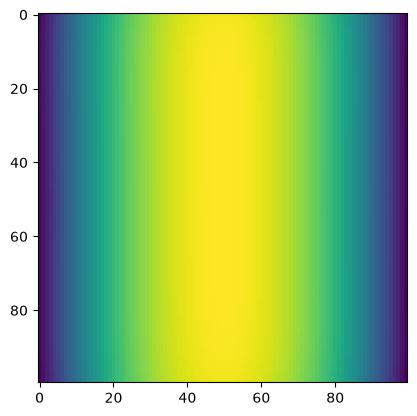

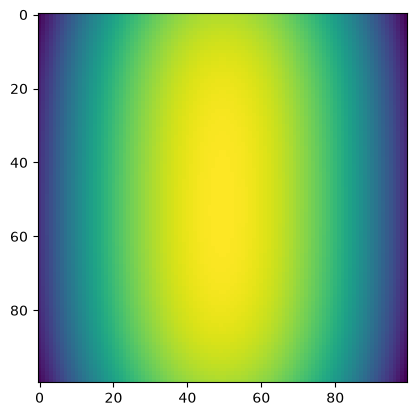

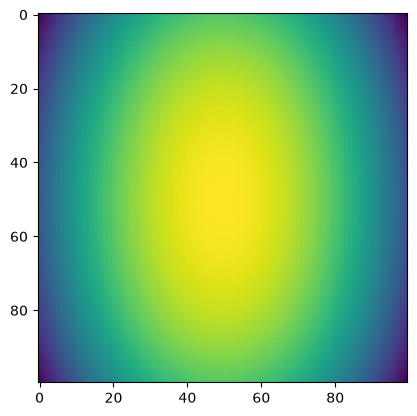

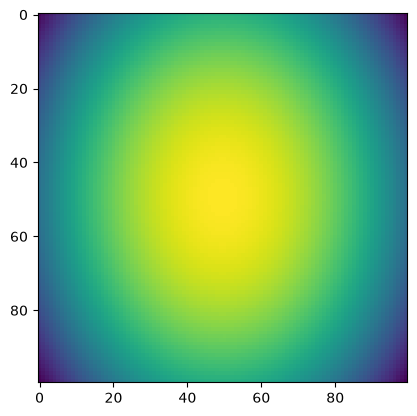

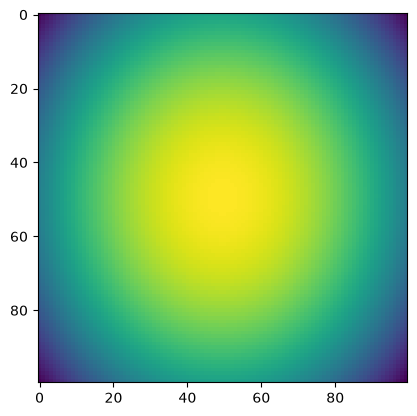

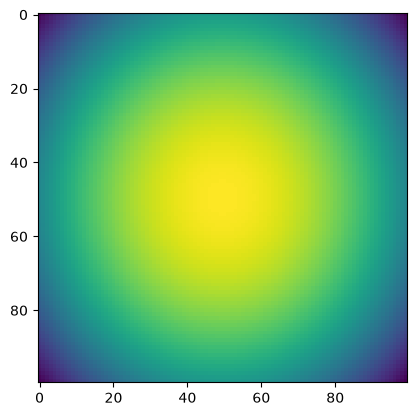

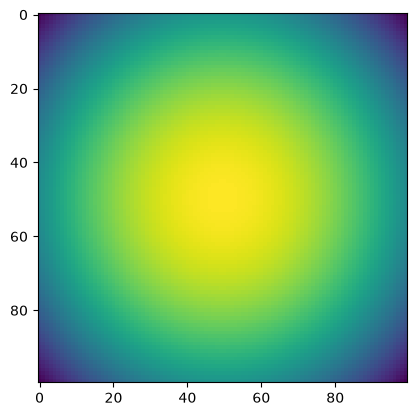

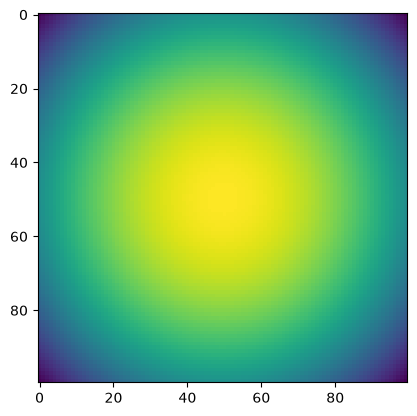

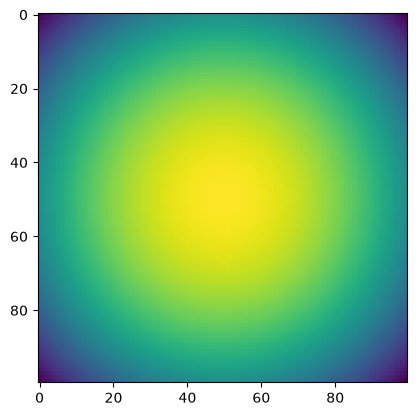

11100 0.21319172 time: 0.0032699108123779297
11200 0.1916226 time: 0.0019943714141845703
11300 0.26457462 time: 0.0035715103149414062
11400 0.22766681 time: 0.0031049251556396484
11500 0.22800069 time: 0.0040187835693359375
11600 0.20531203 time: 0.00197601318359375
11700 0.2531983 time: 0.0017354488372802734
11800 0.21741465 time: 0.0017285346984863281
11900 0.2267358 time: 0.0017309188842773438
12000 0.22898506 time: 0.0017650127410888672


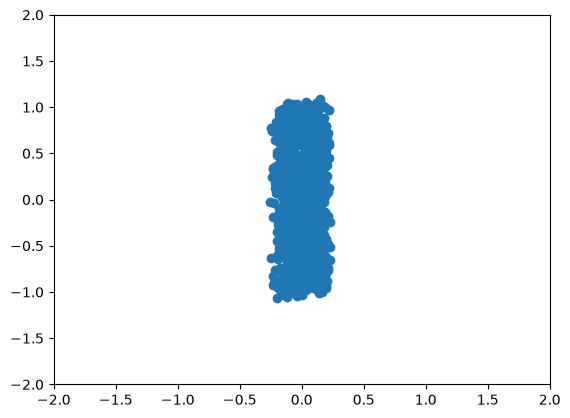

TEST 12000 logpx 0.19007313


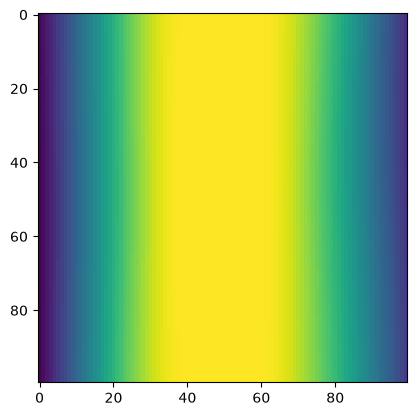

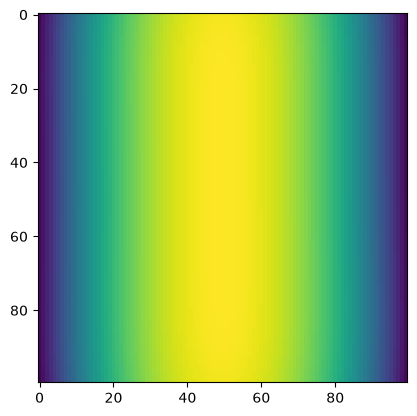

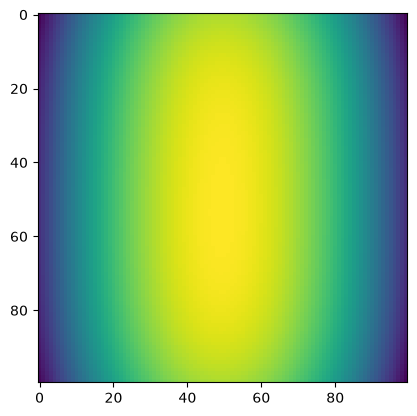

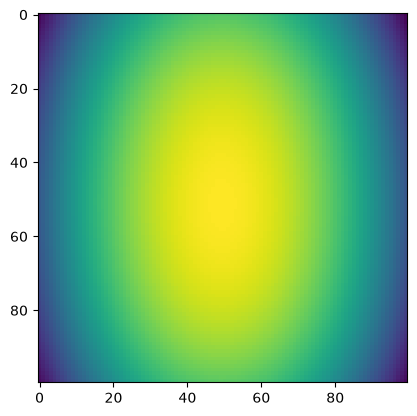

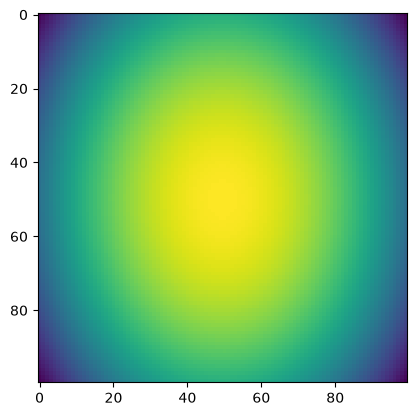

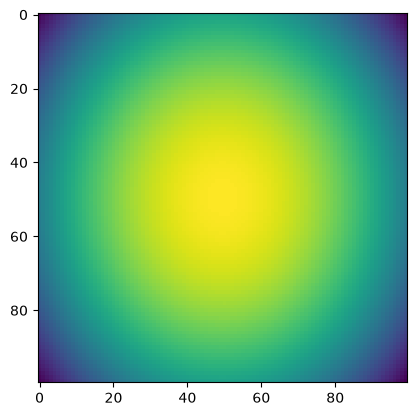

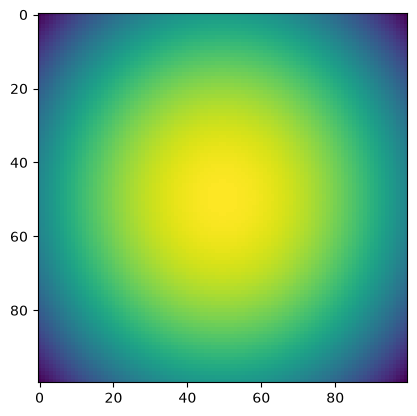

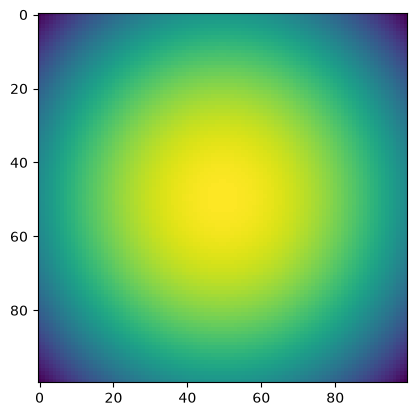

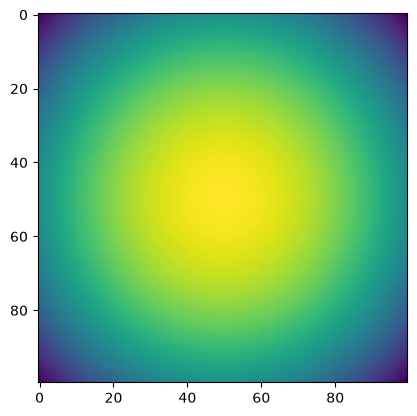

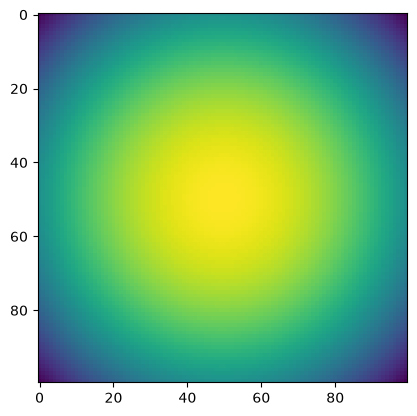

12100 0.2331461 time: 0.0017135143280029297
12200 0.21451509 time: 0.0017824172973632812
12300 0.22002384 time: 0.0017802715301513672
12400 0.2108054 time: 0.0017440319061279297
12500 0.21686903 time: 0.0018131732940673828
12600 0.20226578 time: 0.004938602447509766
12700 0.24163423 time: 0.003530263900756836
12800 0.2203989 time: 0.0017848014831542969
12900 0.21356845 time: 0.0019276142120361328
13000 0.21652924 time: 0.002258777618408203


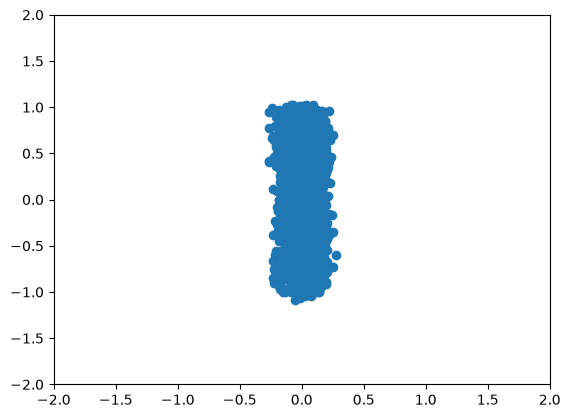

TEST 13000 logpx 0.23369734


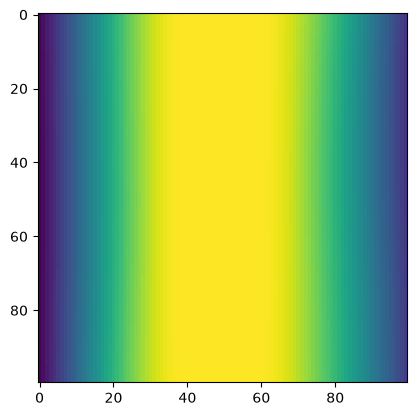

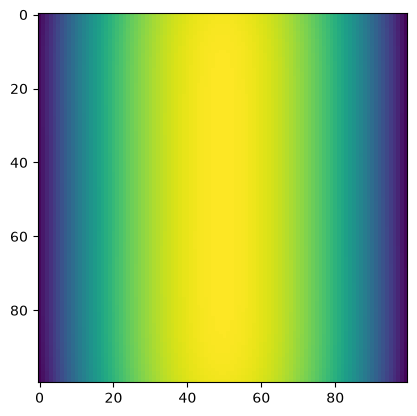

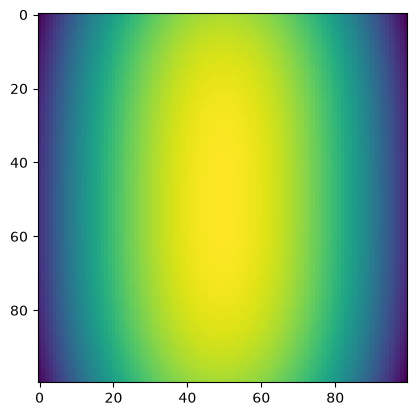

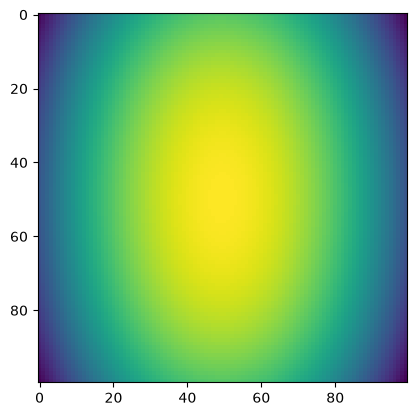

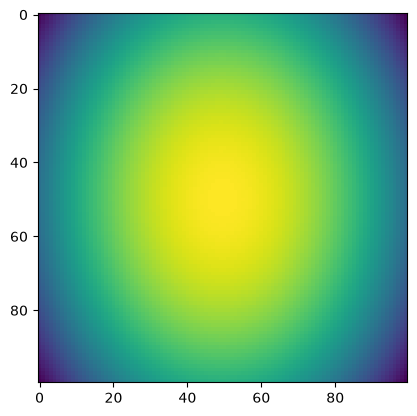

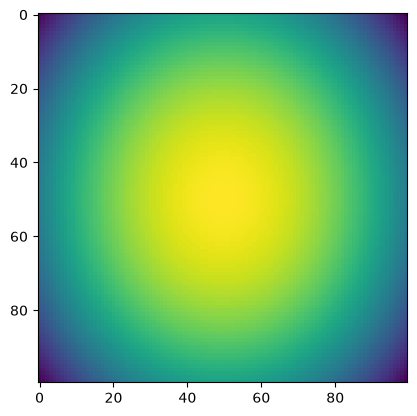

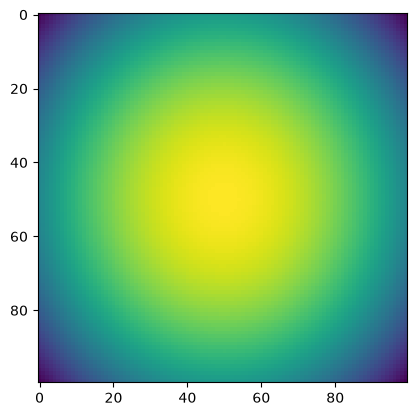

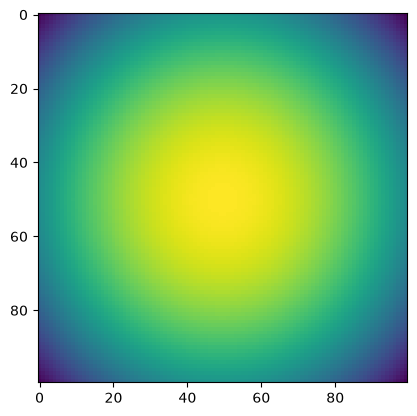

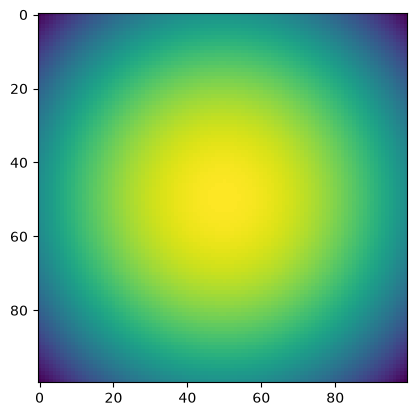

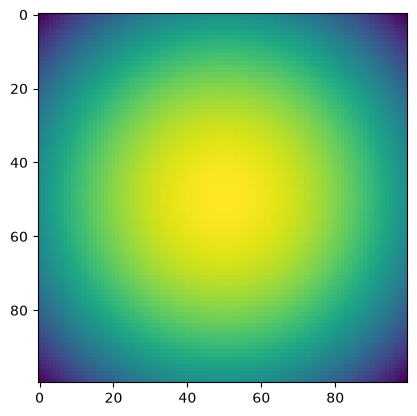

13100 0.19143897 time: 0.0017061233520507812
13200 0.19310483 time: 0.0019338130950927734
13300 0.22341698 time: 0.0021445751190185547
13400 0.21536008 time: 0.0033779144287109375
13500 0.2200282 time: 0.0018138885498046875
13600 0.20917198 time: 0.0051212310791015625
13700 0.22063555 time: 0.002389192581176758
13800 0.22814877 time: 0.0018084049224853516
13900 0.21547359 time: 0.0017099380493164062
14000 0.20115574 time: 0.0019268989562988281


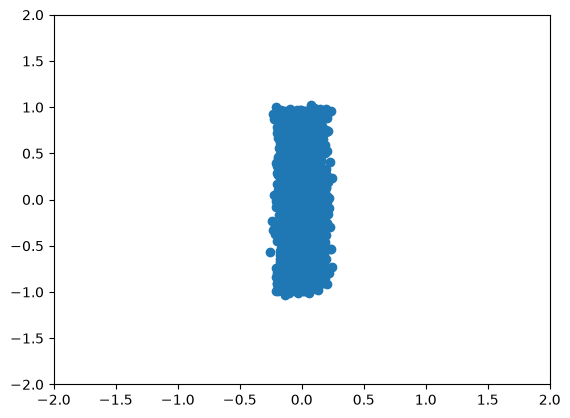

TEST 14000 logpx 0.23072498


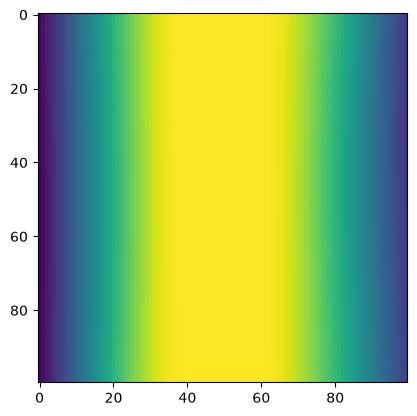

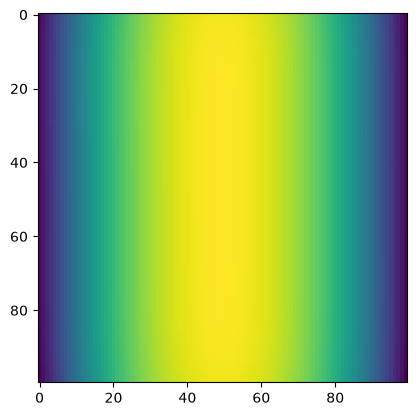

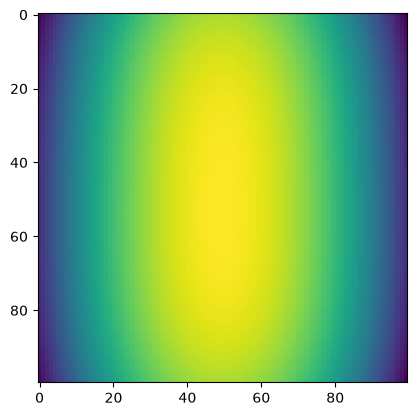

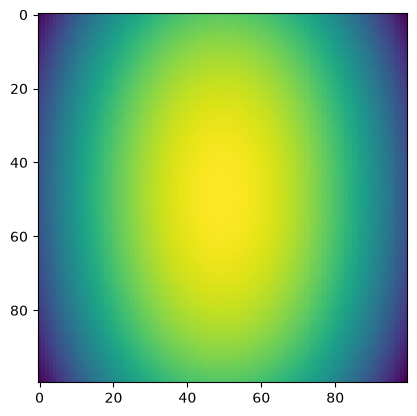

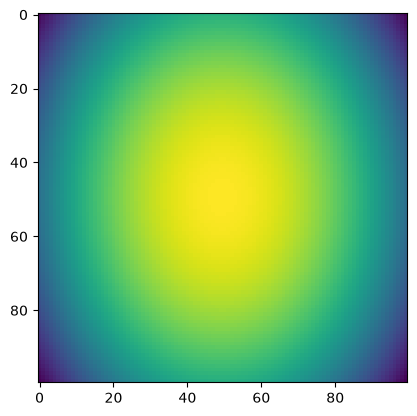

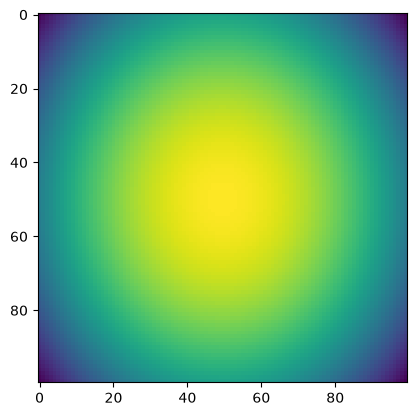

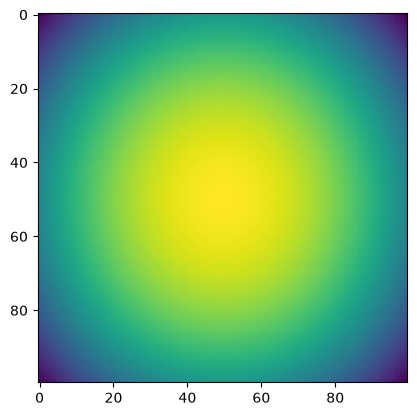

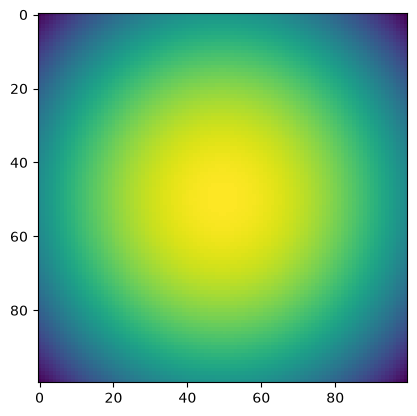

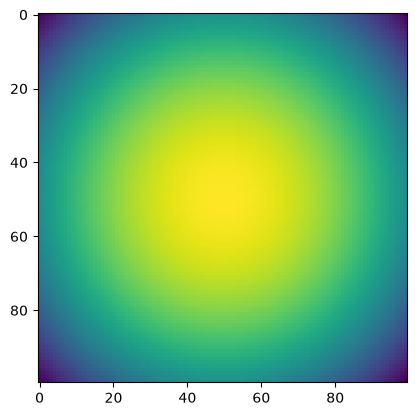

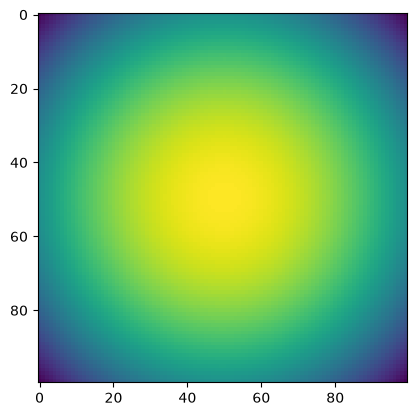

14100 0.184185 time: 0.0017671585083007812
14200 0.22615275 time: 0.0018868446350097656
14300 0.20801584 time: 0.002027273178100586
14400 0.21804304 time: 0.0018088817596435547
14500 0.24761365 time: 0.0046727657318115234
14600 0.23676783 time: 0.0016732215881347656
14700 0.24007532 time: 0.0035266876220703125
14800 0.24222249 time: 0.0021791458129882812
14900 0.24022141 time: 0.003497600555419922
15000 0.21699849 time: 0.003443479537963867


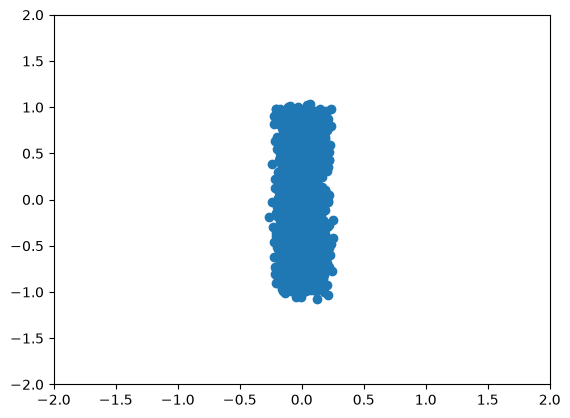

TEST 15000 logpx 0.2246393


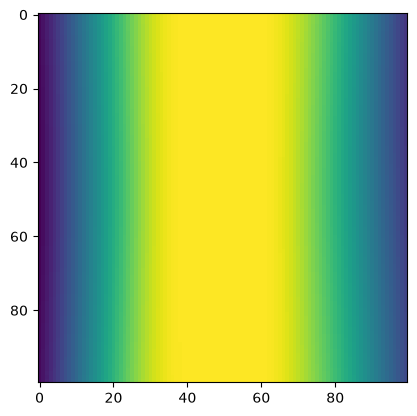

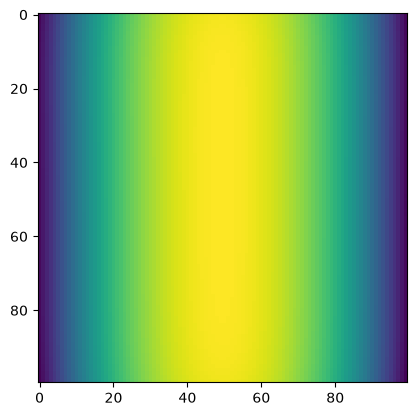

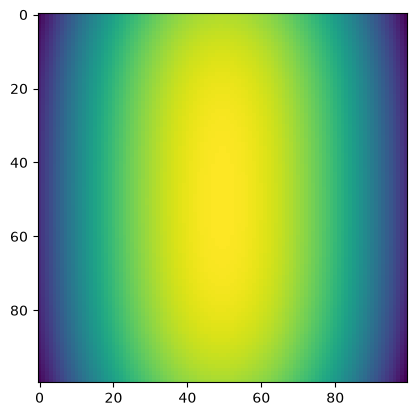

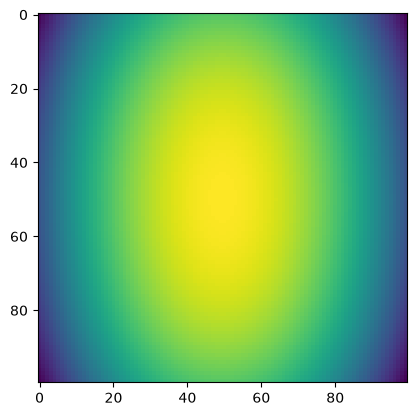

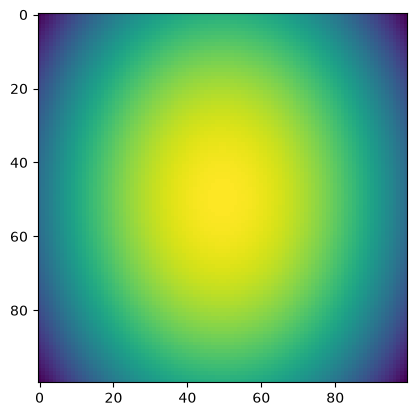

...

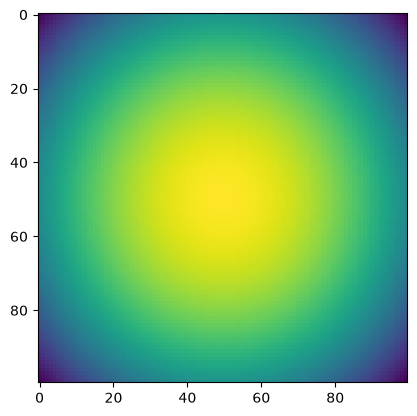

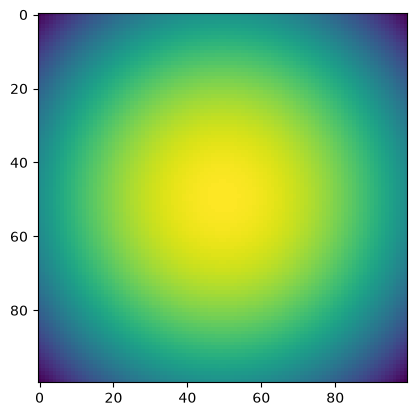

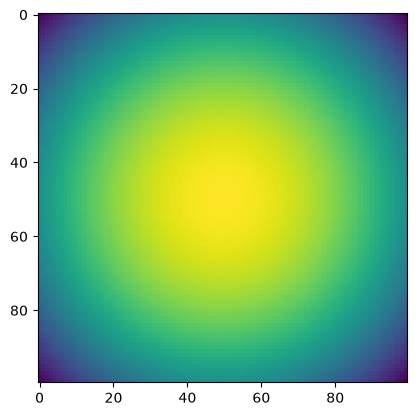

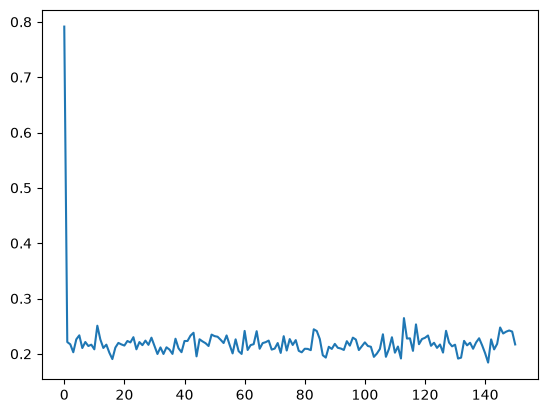

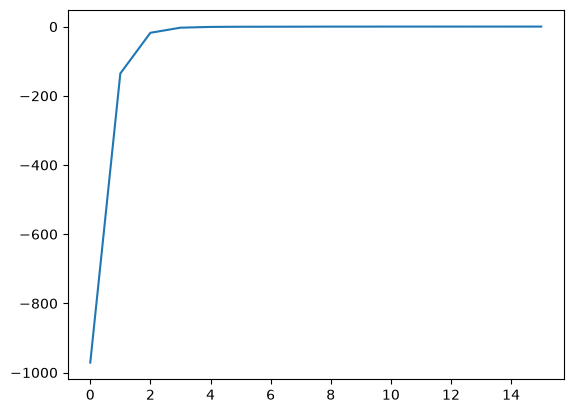

In [29]:
batch_size = 1000
num_steps = 15001

EMA = .999


net_params = {"n_layers": 4,
              "h_dim": 128,
              "emb_dim": 32}

def forward_fn():
  net = ResnetDiffusionModel(n_steps=n_steps, n_layers=4, x_dim=data_dim, h_dim=128, emb_dim=32)

  if ebm:
    net = EBMDiffusionModel(net)

  ddpm = PortableDiffusionModel(data_dim, n_steps, net, var_type="beta_forward")

  def logp_unnorm(x, t):
    scale_e = ddpm.energy_scale(-2 - t)
    t = jnp.ones((x.shape[0],), dtype=jnp.int32) * t
    return -net.neg_logp_unnorm(x, t) * scale_e

  def _logpx(x):
    return ddpm.logpx(x)["logpx"]
  return ddpm.loss, (ddpm.loss, ddpm.sample, _logpx, logp_unnorm)

forward = hk.multi_transform(forward_fn)
rng_seq = hk.PRNGSequence(0)

xr = [-.75, .75]
yr = [-.75, .75]


def plot_samples(x):
  plt.scatter(x[:, 0], x[:, 1])
  plt.xlim(-2, 2)
  plt.ylim(-2, 2)

def dist_show_2d(fn, xr, yr):
    nticks = 100
    x, y = np.meshgrid(np.linspace(xr[0], xr[1], nticks), np.linspace(yr[0], yr[1], nticks))
    coord = np.stack([x, y], axis=-1).reshape((-1, 2))
    heatmap = fn(coord).reshape((nticks, nticks))
    plt.imshow(heatmap)

# load data
dataset_energy, dataset_sample = bar(scale=0.2)
x = dataset_sample(batch_size)

plot_samples(x)
plt.show()
x = x.reshape(x.shape[0], -1)


params = forward.init(next(rng_seq), x)
loss_fn, sample_fn, logpx_fn, logp_unnorm_fn = forward.apply
param_count = sum(x.size for x in jax.tree_leaves(params))
for k, v in jax.tree_map(lambda x: x.shape, params).items():
  print(k, v)
print("Model has {} params".format(param_count))


opt = optax.adam(1e-3)
opt_state = opt.init(params)

sample_fn = jax.jit(sample_fn, static_argnums=2)
logpx_fn = jax.jit(logpx_fn)

logp_unnorm_fn = jax.jit(logp_unnorm_fn)

@jax.jit
def mean_loss_fn(params, rng, x):
  loss = loss_fn(params, rng, x)
  return loss.mean()

@jax.jit
def update(params, opt_state, rng, x):
  loss, grad = jax.value_and_grad(mean_loss_fn)(params, rng, x)

  updates, opt_state = opt.update(grad, opt_state)
  new_params = optax.apply_updates(params, updates)
  return loss, new_params, opt_state

# Speed-only change (no maths changed): the moving average runs inside one compiled call
# instead of one small GPU operation per weight array, about 10x faster per step.
@jax.jit
def update_ema(params, ema_params, opt_state, rng, x):
  loss, params, opt_state = update(params, opt_state, rng, x)
  ema_params = jax.tree_util.tree_map(lambda e, p: e * EMA + p * (1 - EMA), ema_params, params)
  return loss, params, ema_params, opt_state

ema_params = params
losses = []
test_logpx = []
itr = 0

for itr in range(num_steps):
  x = dataset_sample(batch_size)

  x = x.reshape(x.shape[0], -1)
  start_time = time.time()
  loss, params, ema_params, opt_state = update_ema(params, ema_params, opt_state, next(rng_seq), x)
  duration_update = time.time() - start_time

  if itr % 100 == 0:
    print(itr, loss, "time:", duration_update)
    losses.append(loss)
  if itr % 1000 == 0:
    x_samp = sample_fn(ema_params, next(rng_seq), batch_size)
    plot_samples(x_samp)
    plt.show()
    logpx = logpx_fn(ema_params, next(rng_seq), x).mean()
    print("TEST", itr, 'logpx', logpx)
    test_logpx.append(logpx)

    if ebm:
      for t in range(10):
        dist_show_2d(lambda x: logp_unnorm_fn(ema_params, next(rng_seq), x, 10*t), xr=xr, yr=yr)
        plt.show()

plt.plot(losses)
plt.show()
plt.plot(test_logpx)

bar_params = ema_params

In [30]:
params = {}

for k, v in spiral_params.items():
  params[k] = v

for k, v in bar_params.items():
  k = k.replace('resnet_diffusion_model/', 'resnet_diffusion_model_1/')
  params[k] = v

/tmp/ipykernel_1391087/1385371818.py:265: UserWarning: Explicitly requested dtype int64 requested in ones is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  t = jnp.ones((n,), dtype=jnp.int64) * j


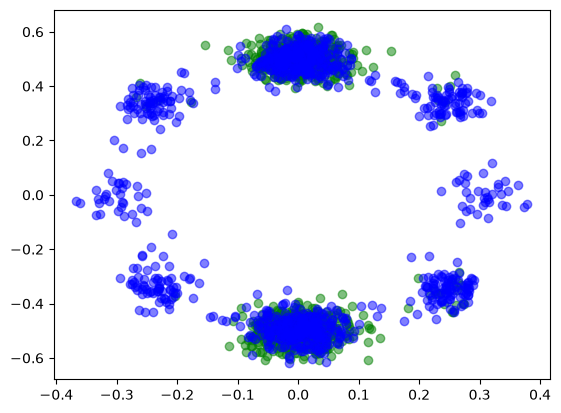

In [31]:
# Sampling from product of distributions
import matplotlib.pyplot as plt

dim = 2
n_mode = 4
std = .05
init_std = 1.
init_mu = 0.
n_steps = 10
damping = .5
mass_diag_sqrt = 1.
num_leapfrog = 3
samples_per_step = 10
uha_step_size = .03
ula_step_size = .001

batch_size = 1000

rng_seq = hk.PRNGSequence(0)

means = jax.random.normal(next(rng_seq), (n_mode, dim))
comp_dists = distrax.MultivariateNormalDiag(means, jnp.ones_like(means) * std)
pi = distrax.Categorical(logits=jnp.zeros((n_mode,)))
target_dist = distrax.MixtureSameFamily(pi, comp_dists)
initial_dist = distrax.MultivariateNormalDiag(means[0] * 0 + init_mu, init_std * jnp.ones_like(means[0]))


x_init = initial_dist.sample(seed=next(rng_seq), sample_shape=(batch_size,))
logZs = []
n_stepss = [100]

def gradient_function(x, t):
  t = n_steps - jnp.ones((x.shape[0],), dtype=jnp.int32) * t - 1
  return -1 *dual_product_gradient_fn(params, next(rng_seq), x, t)

if ebm:
  def energy_function(x, t):
    t = n_steps - jnp.ones((x.shape[0],), dtype=jnp.int32) * t - 1
    return -1 *dual_product_energy_fn(params, next(rng_seq), x, t)

for n_steps in n_stepss:
  ula_step_sizes = jnp.ones((n_steps,)) * ula_step_size
  uha_step_sizes = jnp.ones((n_steps,)) * uha_step_size

  betas = jnp.linspace(0., 1., n_steps)

  def target_function(x, i):
    beta = betas[i]
    init_lp = initial_dist.log_prob(x)
    targ_lp = target_dist.log_prob(x)
    return beta * targ_lp + (1 - beta) * init_lp

  # Choose MCMC Sampler to use
  # sampler = AnnealedULASampler(n_steps, samples_per_step, ula_step_sizes, initial_dist, target_distribution=None, gradient_function=gradient_function)
  # sampler = AnnealedMALASampler(n_steps, samples_per_step, ula_step_sizes, initial_dist, target_distribution=None, gradient_function=gradient_function, energy_function=energy_function)
  # sampler = AnnealedUHASampler(n_steps, samples_per_step, uha_step_sizes, damping, mass_diag_sqrt, num_leapfrog, initial_dist, target_distribution=None, gradient_function=gradient_function)
  sampler = AnnealedMUHASampler(n_steps, samples_per_step, uha_step_sizes, damping, mass_diag_sqrt, num_leapfrog, initial_dist, target_distribution=None, gradient_function=gradient_function, energy_function=energy_function)

  x_samp, logw, accept = sampler.sample(next(rng_seq), batch_size)
  rng_seq = hk.PRNGSequence(1)
  grad_sample = dual_product_sample_fn(params, next(rng_seq), batch_size, jnp.inf)

  # Samples from MCMC
  plt.scatter(x_samp[:, 0], x_samp[:, 1], color='green', alpha=.5)

  # Samples from adding score functions
  plt.scatter(grad_sample[:, 0], grad_sample[:, 1], color='blue', alpha=.5)

  plt.show()

Excute Disjunction Composition

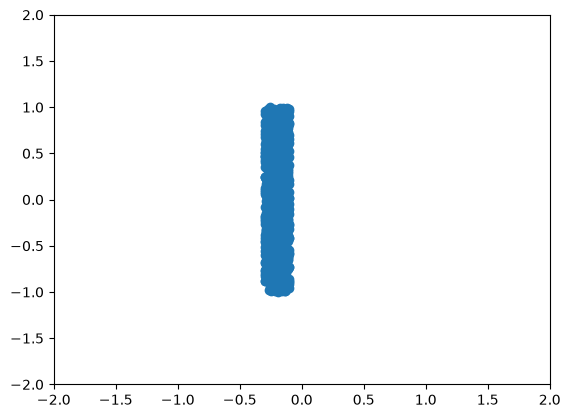

portable_diffusion_model {'out_logvar': (100,)}
resnet_diffusion_model/embed {'embeddings': (100, 32)}
resnet_diffusion_model/layer_norm {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/layer_norm_1 {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/layer_norm_2 {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/layer_norm_3 {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/linear {'b': (128,), 'w': (2, 128)}
resnet_diffusion_model/linear_1 {'b': (256,), 'w': (128, 256)}
resnet_diffusion_model/linear_10 {'b': (256,), 'w': (32, 256)}
resnet_diffusion_model/linear_11 {'b': (256,), 'w': (256, 256)}
resnet_diffusion_model/linear_12 {'b': (128,), 'w': (256, 128)}
resnet_diffusion_model/linear_13 {'b': (256,), 'w': (128, 256)}
resnet_diffusion_model/linear_14 {'b': (256,), 'w': (32, 256)}
resnet_diffusion_model/linear_15 {'b': (256,), 'w': (256, 256)}
resnet_diffusion_model/linear_16 {'b': (128,), 'w': (256, 128)}
resnet_diffusion_model/linear_17 {'b': (2,)

/tmp/ipykernel_1391087/1385371818.py:265: UserWarning: Explicitly requested dtype int64 requested in ones is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  t = jnp.ones((n,), dtype=jnp.int64) * j


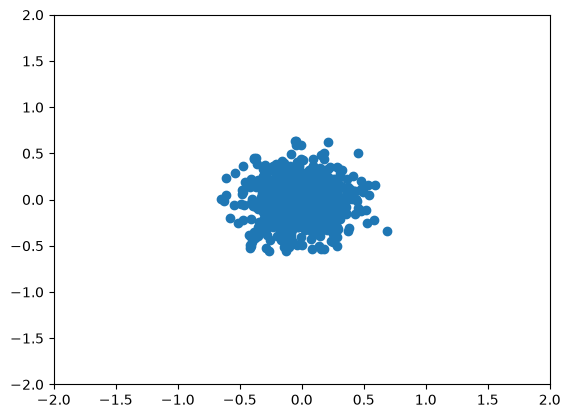

/tmp/ipykernel_1391087/1385371818.py:235: UserWarning: Explicitly requested dtype int64 requested in ones is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  t = jnp.ones((x_0.shape[0],), dtype=jnp.int64) * (self._n_steps - 1)


TEST 0 logpx -971.6026


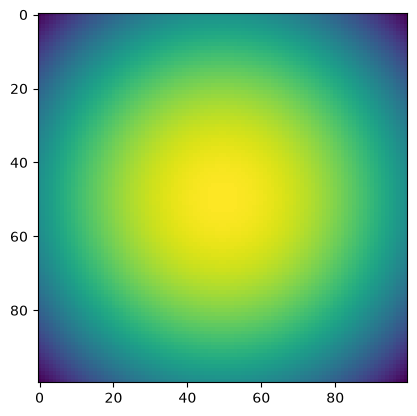

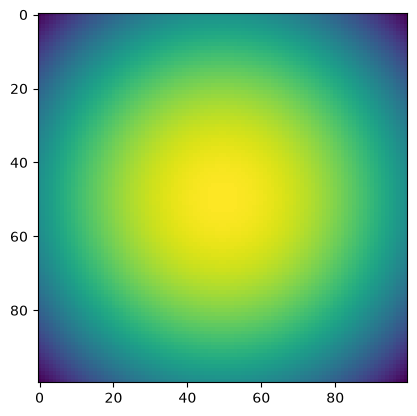

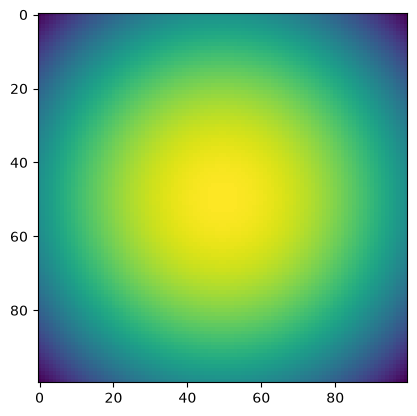

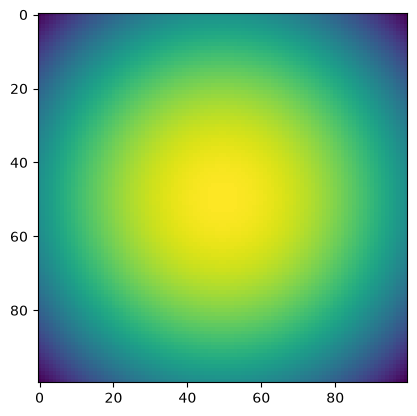

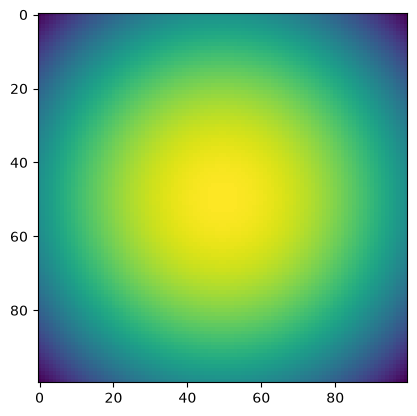

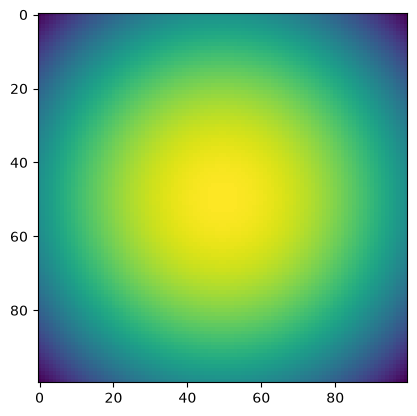

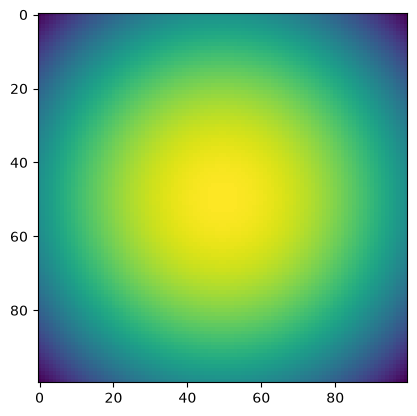

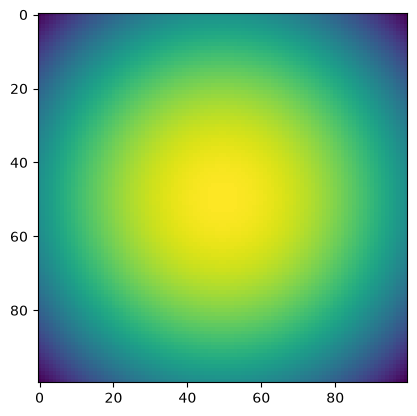

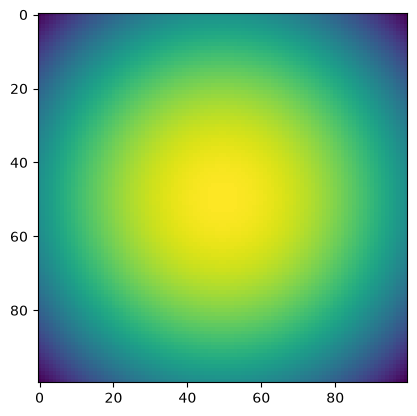

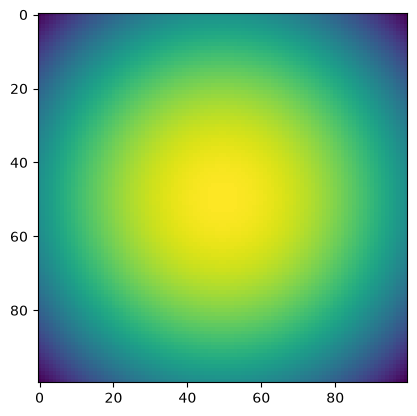

100 0.20543218 time: 0.003159046173095703
200 0.19926664 time: 0.003495931625366211
300 0.1740773 time: 0.0020797252655029297
400 0.20698772 time: 0.0020859241485595703
500 0.21652569 time: 0.001889944076538086
600 0.19006793 time: 0.0018665790557861328
700 0.19255857 time: 0.001840353012084961
800 0.17978734 time: 0.0018343925476074219
900 0.18335497 time: 0.001947164535522461
1000 0.17926247 time: 0.0030498504638671875


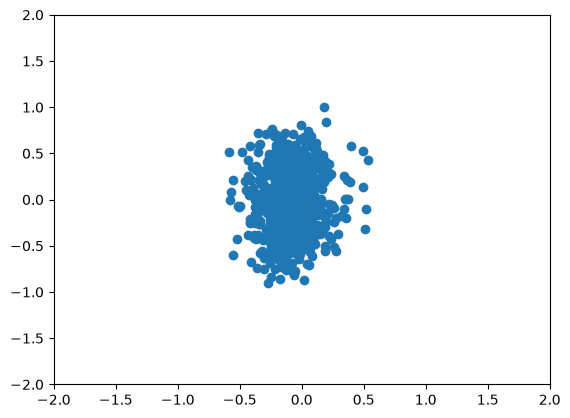

TEST 1000 logpx -147.98082


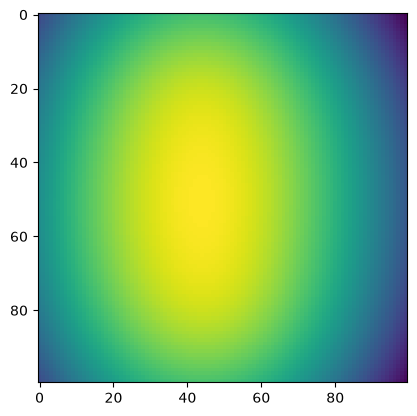

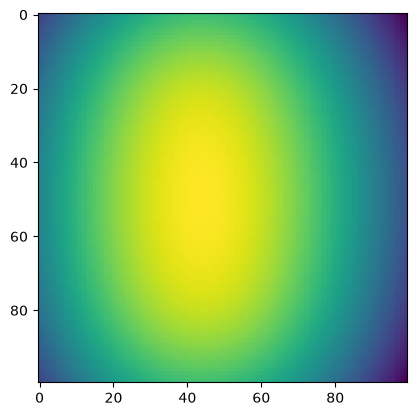

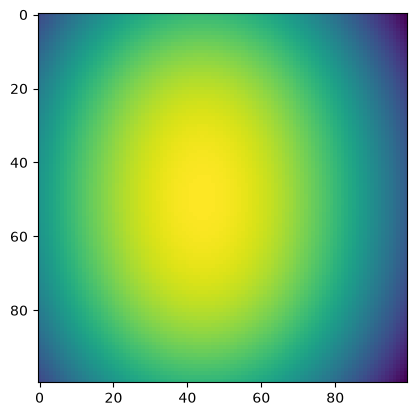

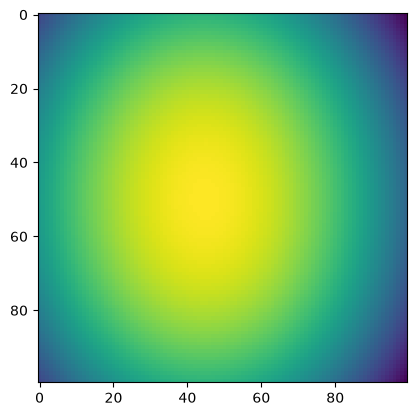

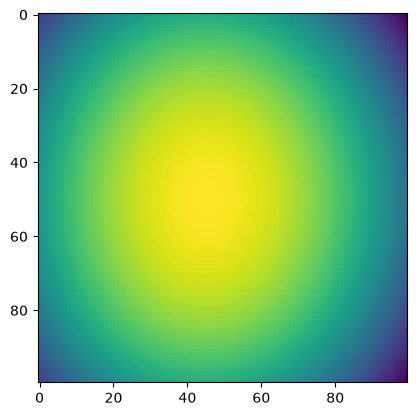

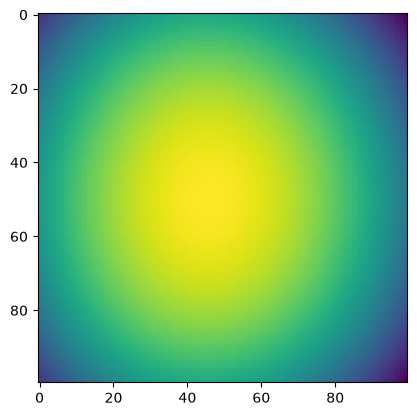

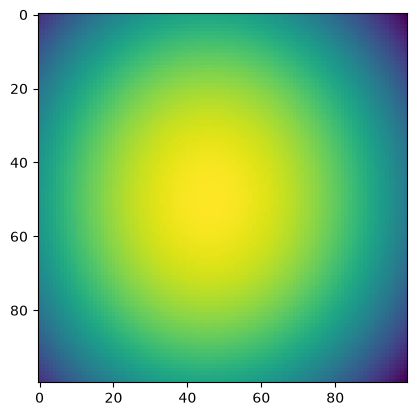

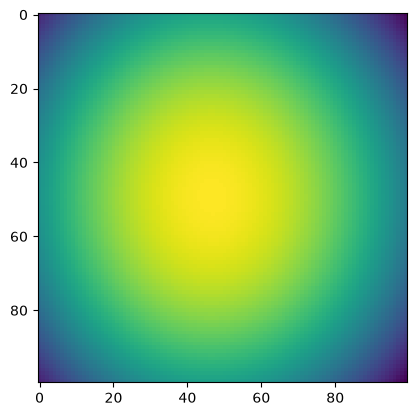

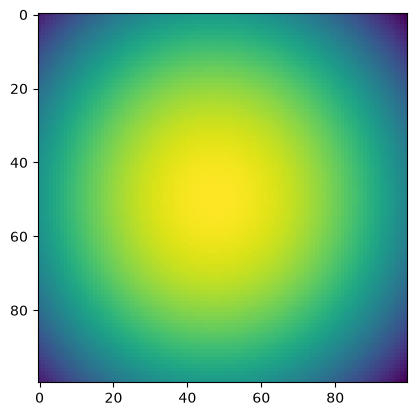

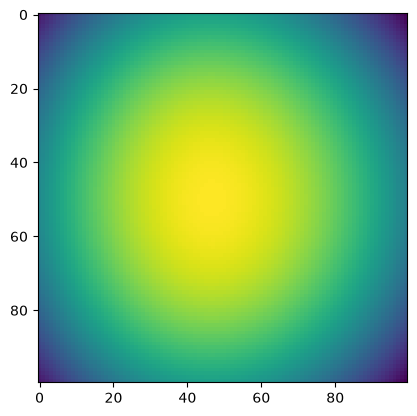

1100 0.22087727 time: 0.0031633377075195312
1200 0.1968082 time: 0.003282308578491211
1300 0.17695351 time: 0.0019457340240478516
1400 0.19903424 time: 0.0019152164459228516
1500 0.1940997 time: 0.001844167709350586
1600 0.17822157 time: 0.002402067184448242
1700 0.1999962 time: 0.0034215450286865234
1800 0.20156339 time: 0.0021622180938720703
1900 0.19312684 time: 0.002887248992919922
2000 0.19136769 time: 0.002028226852416992


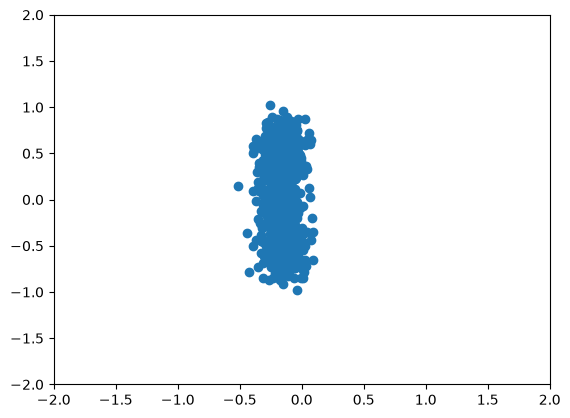

TEST 2000 logpx -20.343693


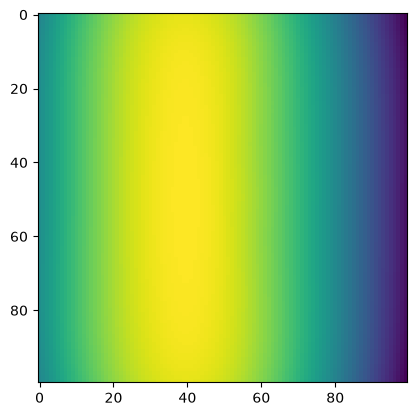

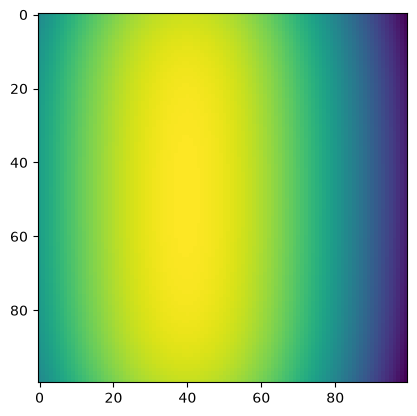

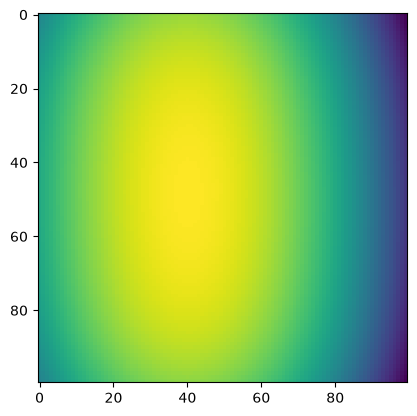

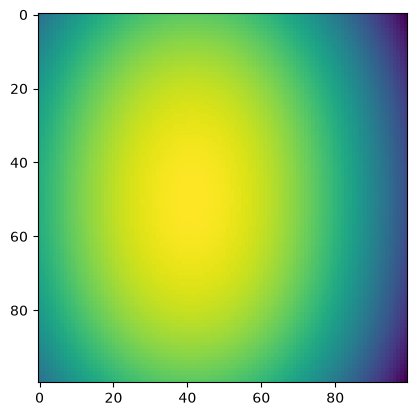

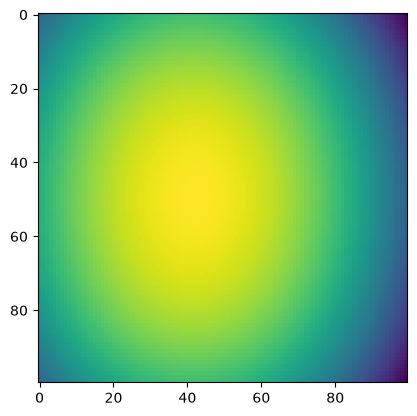

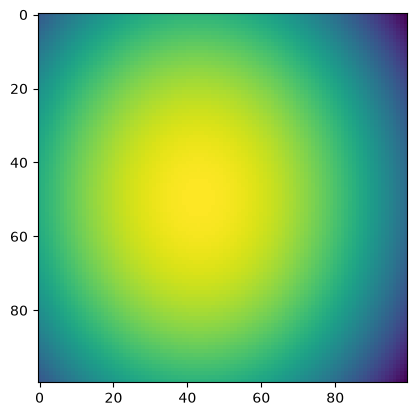

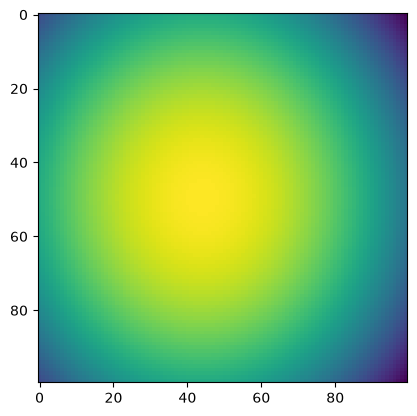

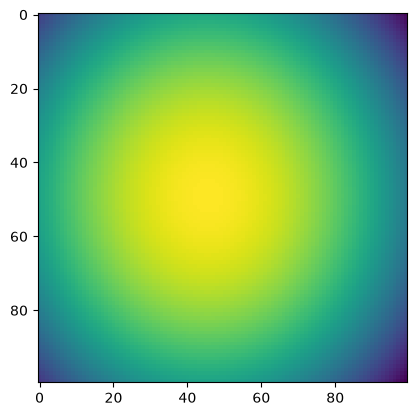

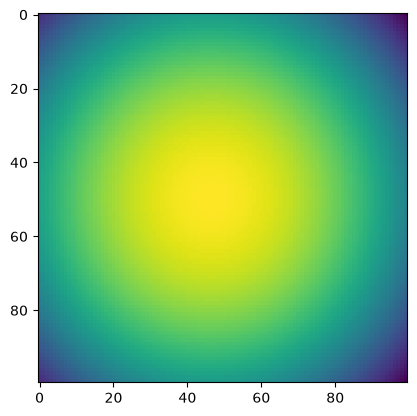

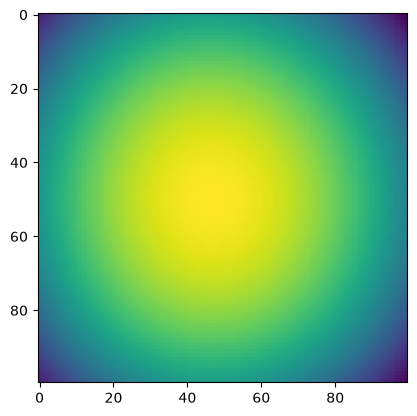

2100 0.21483423 time: 0.0018939971923828125
2200 0.19678925 time: 0.0019354820251464844
2300 0.2192414 time: 0.0022382736206054688
2400 0.18760061 time: 0.001936197280883789
2500 0.21329947 time: 0.0023360252380371094
2600 0.19035944 time: 0.001798868179321289
2700 0.19520766 time: 0.002429962158203125
2800 0.1929464 time: 0.001832723617553711
2900 0.20437185 time: 0.0020089149475097656
3000 0.18407923 time: 0.0018167495727539062


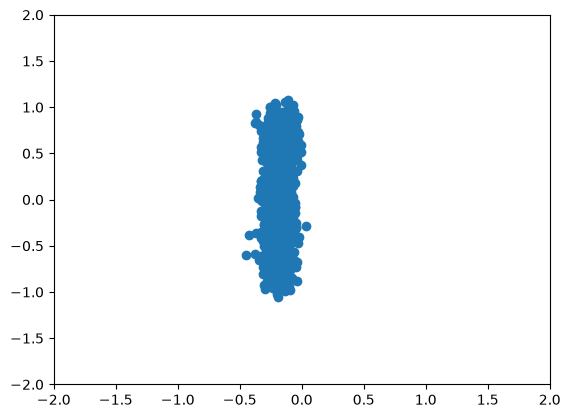

TEST 3000 logpx -2.7831383


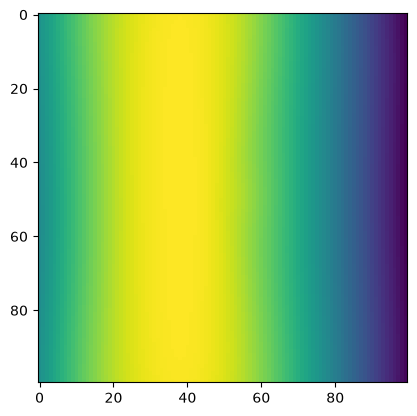

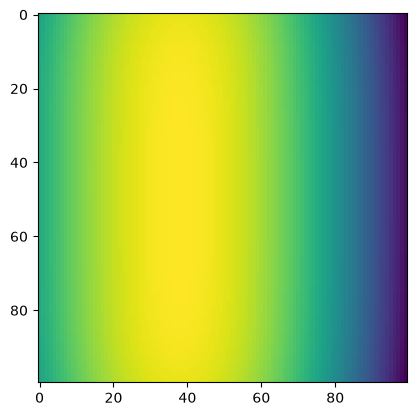

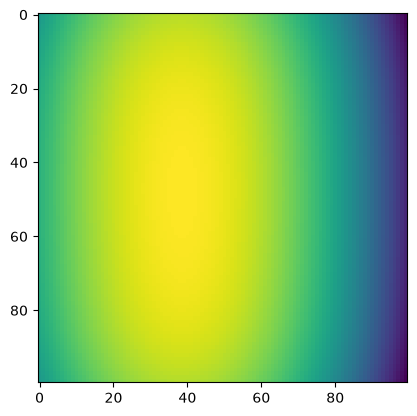

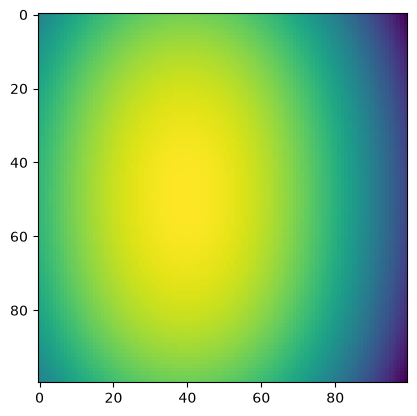

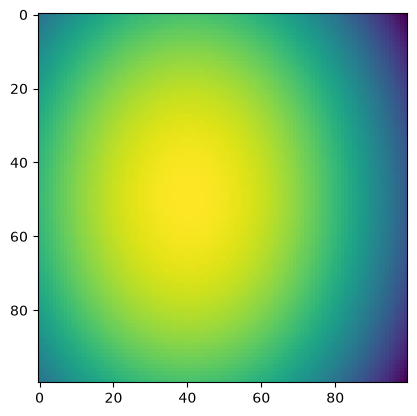

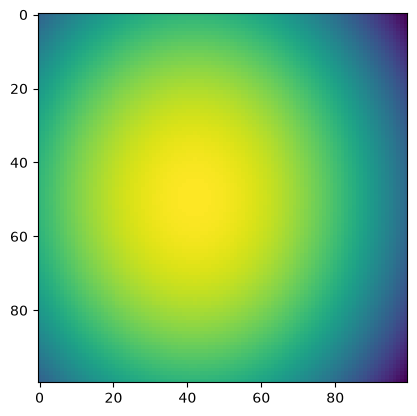

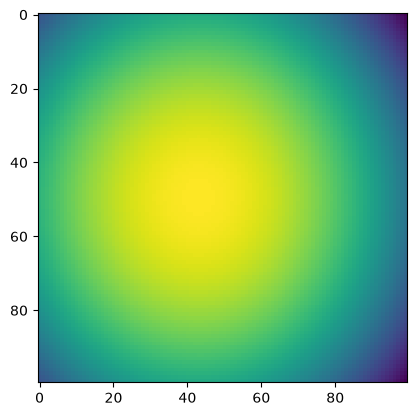

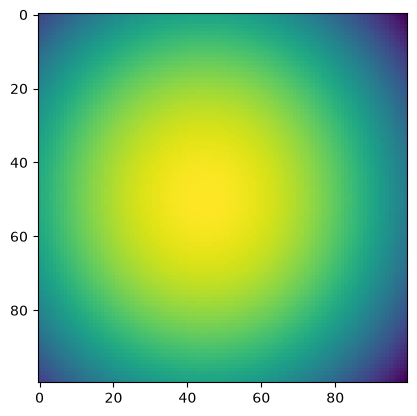

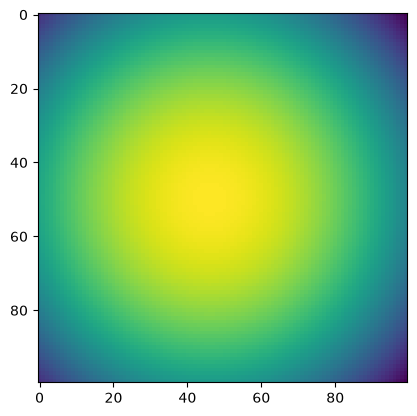

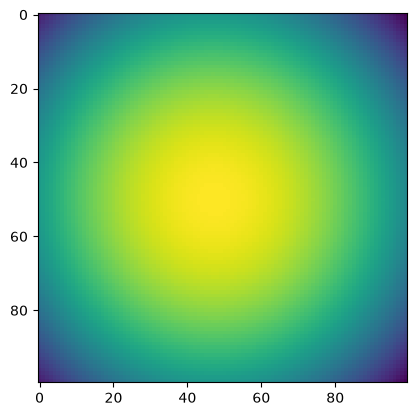

3100 0.18818647 time: 0.0034592151641845703
3200 0.19017321 time: 0.002691507339477539
3300 0.17364556 time: 0.002111673355102539
3400 0.20173746 time: 0.002237081527709961
3500 0.17969914 time: 0.0033042430877685547
3600 0.18475507 time: 0.0034875869750976562
3700 0.19652241 time: 0.0018558502197265625
3800 0.18137147 time: 0.0033605098724365234
3900 0.18864746 time: 0.001934051513671875
4000 0.20222123 time: 0.0019440650939941406


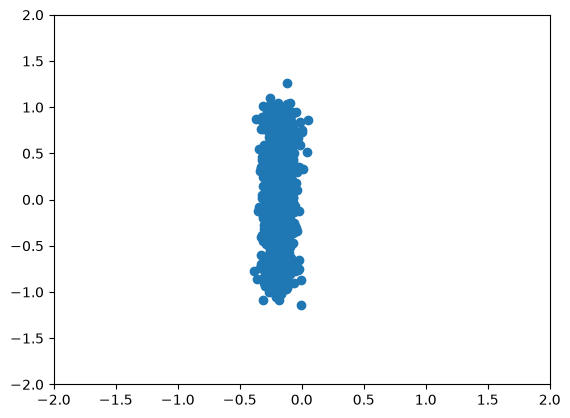

TEST 4000 logpx -0.7046663


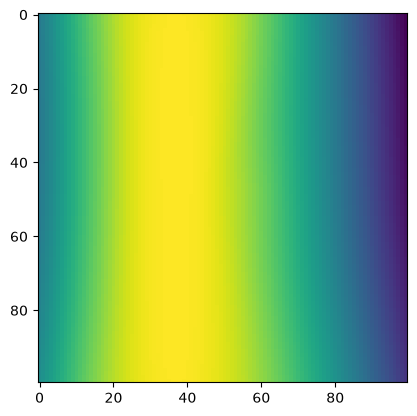

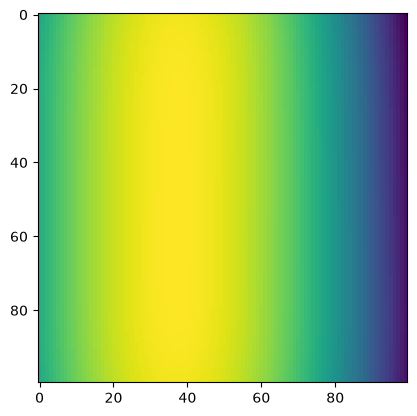

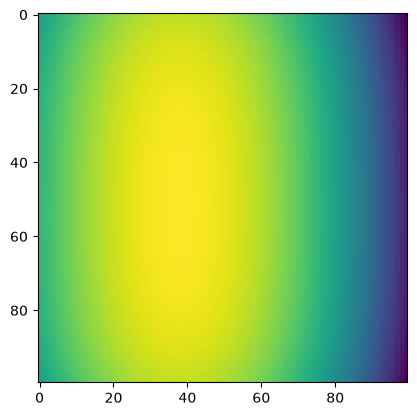

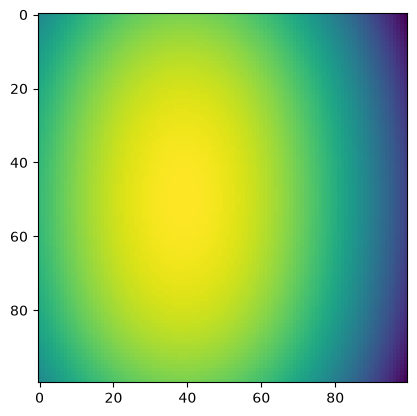

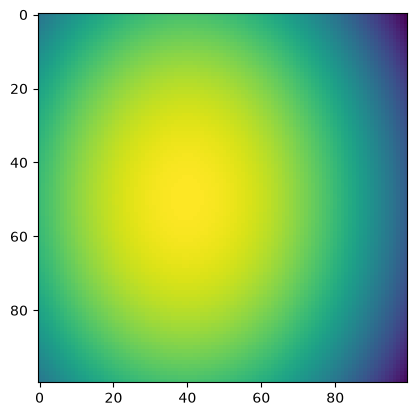

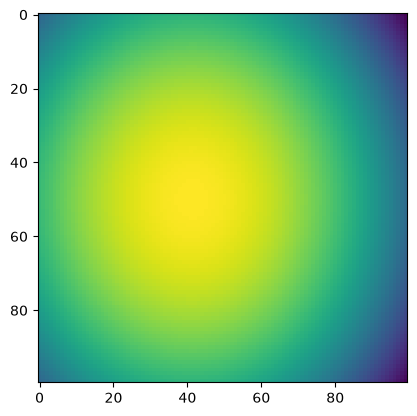

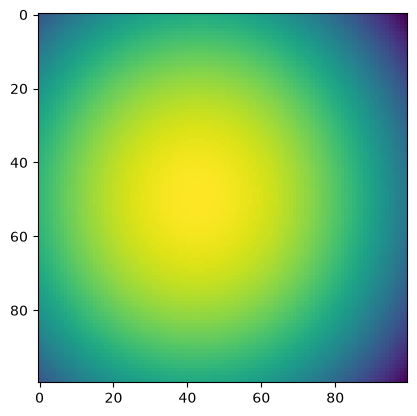

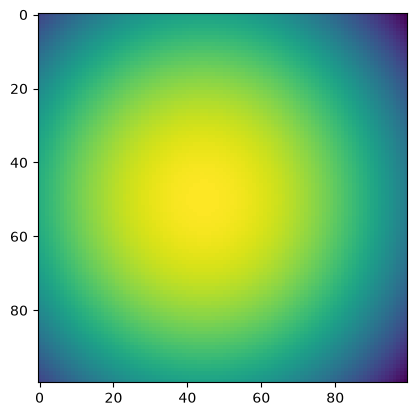

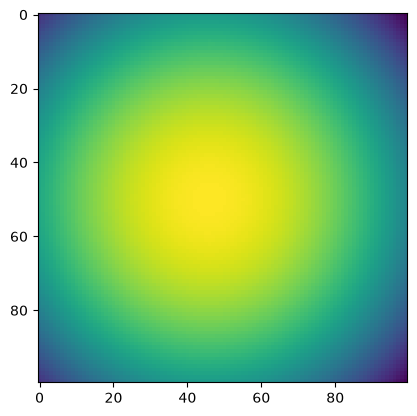

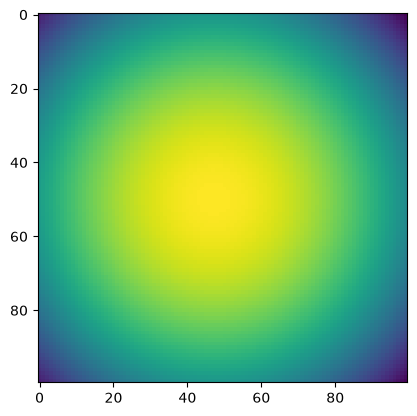

4100 0.18345793 time: 0.0033948421478271484
4200 0.2111515 time: 0.0024971961975097656
4300 0.20356257 time: 0.002478361129760742
4400 0.16492964 time: 0.0019140243530273438
4500 0.20693634 time: 0.0019173622131347656
4600 0.20472 time: 0.0018384456634521484
4700 0.17546967 time: 0.0049130916595458984
4800 0.1695637 time: 0.001958608627319336
4900 0.19695552 time: 0.002315998077392578
5000 0.19239211 time: 0.001775979995727539


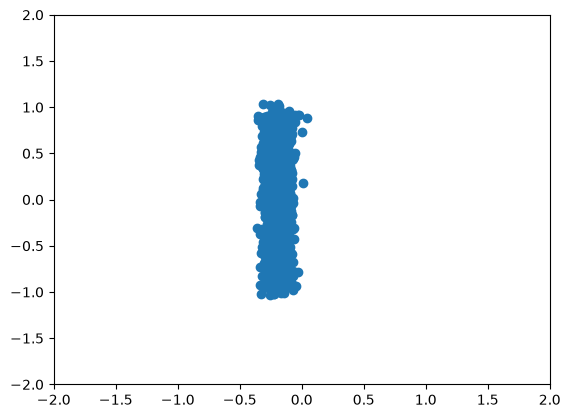

TEST 5000 logpx -0.002132893


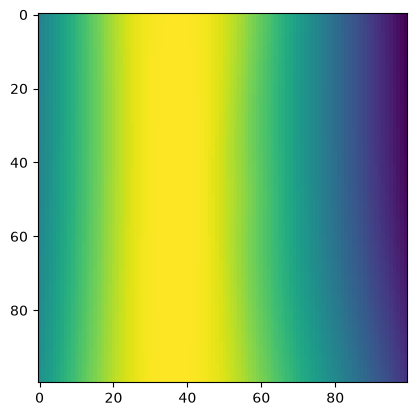

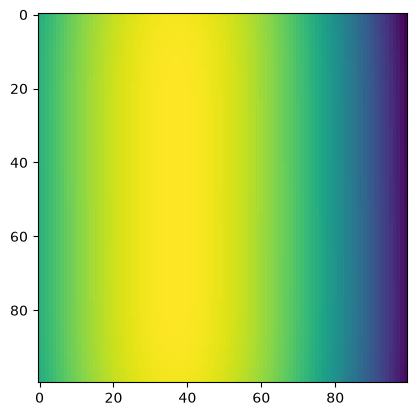

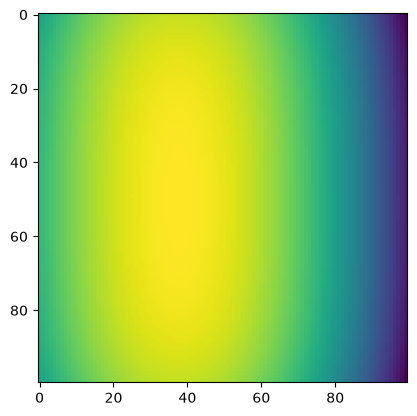

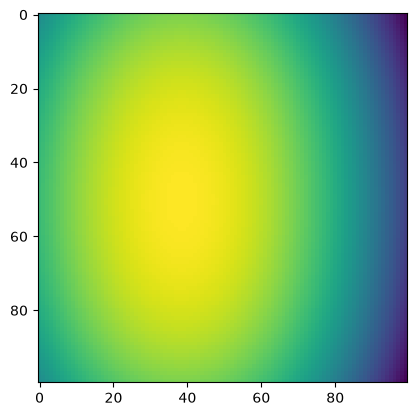

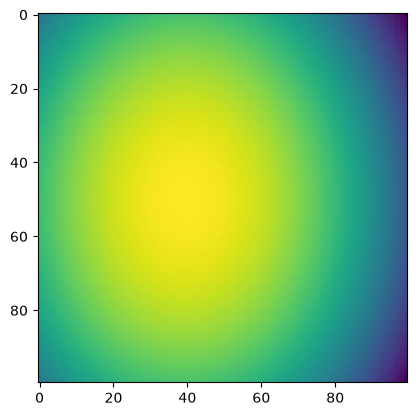

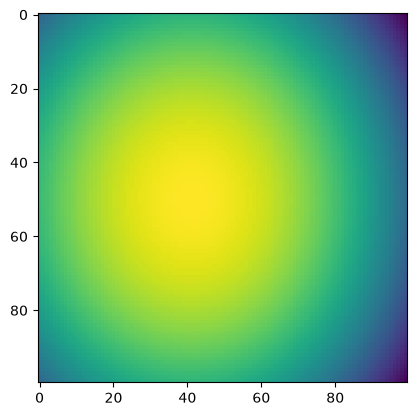

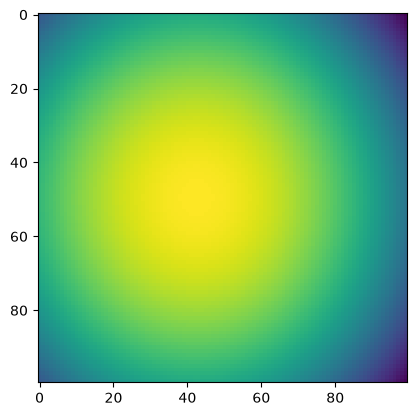

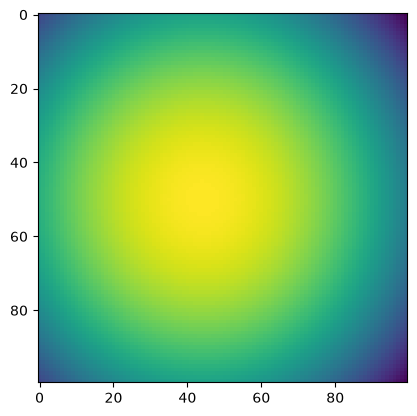

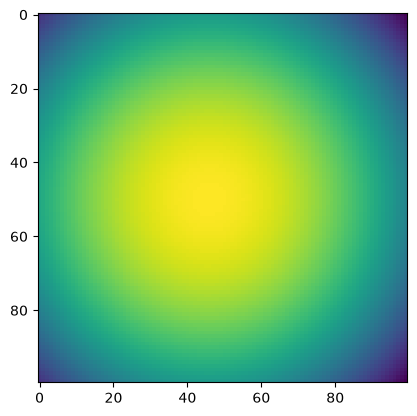

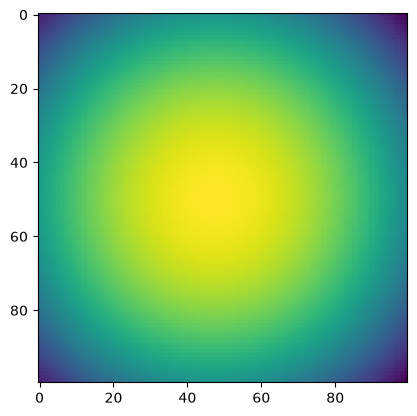

5100 0.19967994 time: 0.001977205276489258
5200 0.20298338 time: 0.0033223628997802734
5300 0.18469587 time: 0.002162456512451172
5400 0.21579415 time: 0.0018734931945800781
5500 0.20230034 time: 0.003483295440673828
5600 0.17868224 time: 0.0034339427947998047
5700 0.19727314 time: 0.0021085739135742188
5800 0.1889372 time: 0.0018320083618164062
5900 0.17946188 time: 0.001764059066772461
6000 0.21241224 time: 0.0033664703369140625


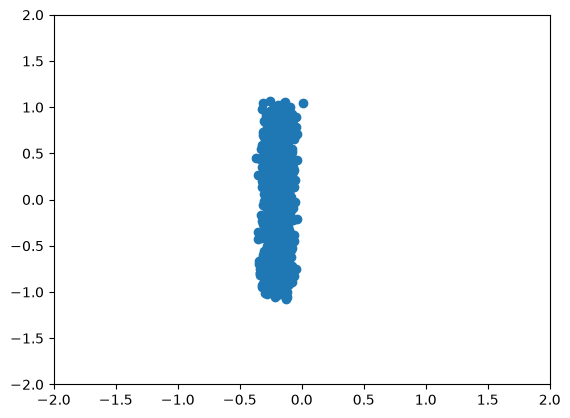

TEST 6000 logpx 0.25209883


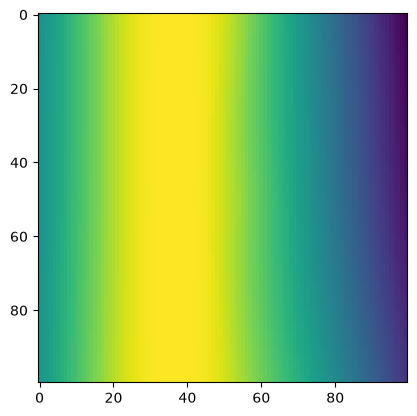

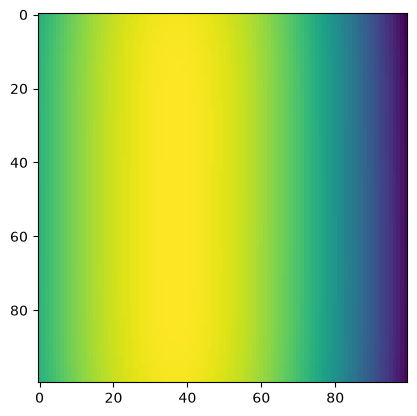

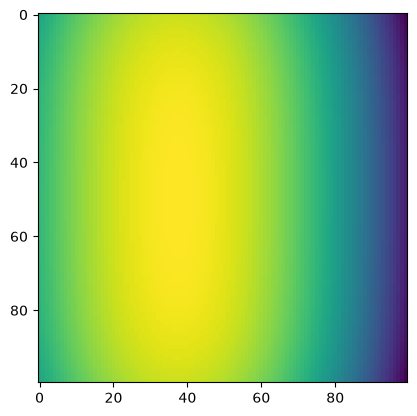

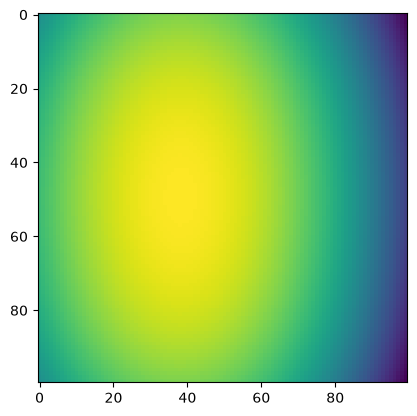

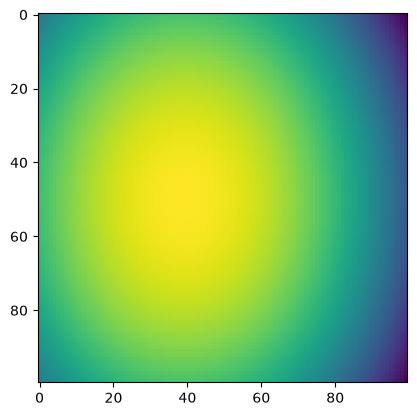

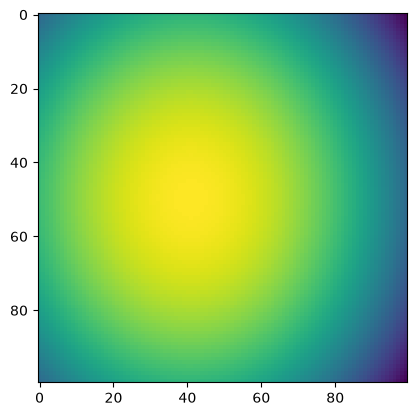

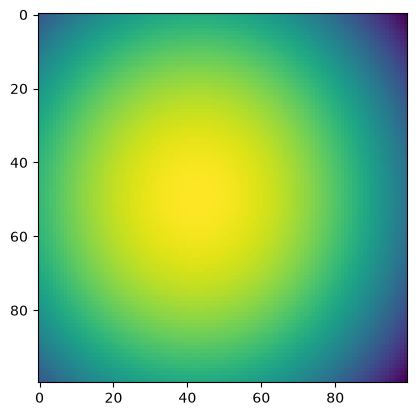

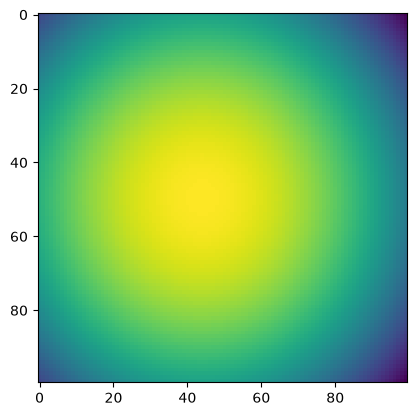

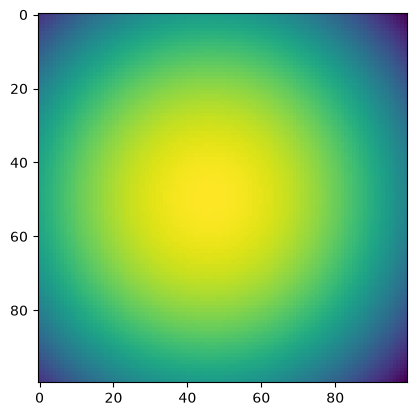

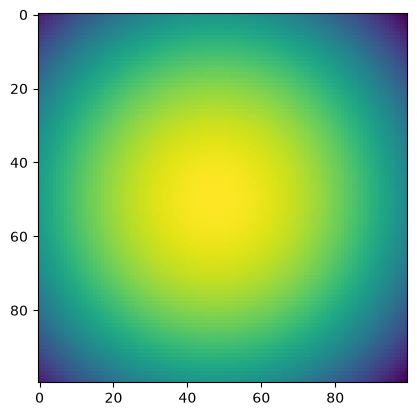

6100 0.18847035 time: 0.0019009113311767578
6200 0.21604402 time: 0.003645658493041992
6300 0.18160558 time: 0.0020885467529296875
6400 0.21600452 time: 0.005089759826660156
6500 0.1876388 time: 0.0020439624786376953
6600 0.1943209 time: 0.0028650760650634766
6700 0.17911361 time: 0.0034074783325195312
6800 0.20938902 time: 0.0018558502197265625
6900 0.17840458 time: 0.0019321441650390625
7000 0.18569422 time: 0.0019159317016601562


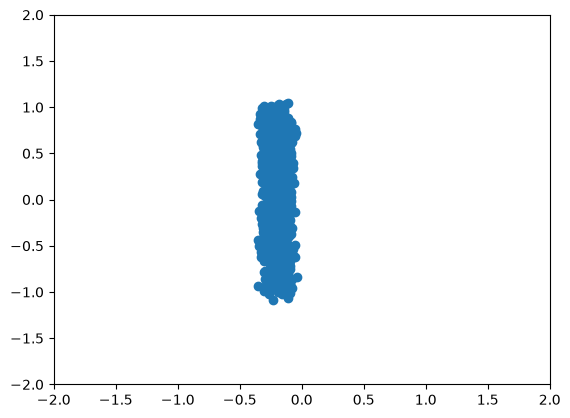

TEST 7000 logpx 0.5066497


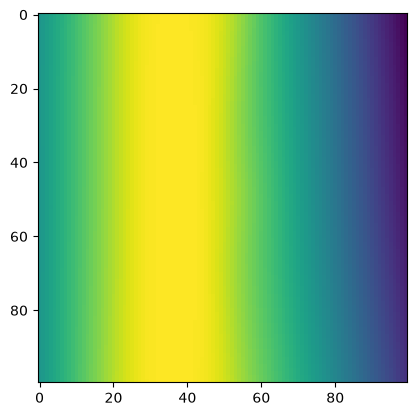

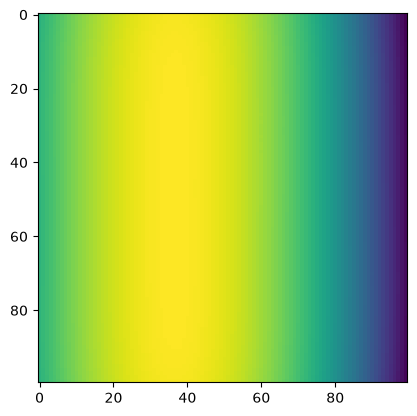

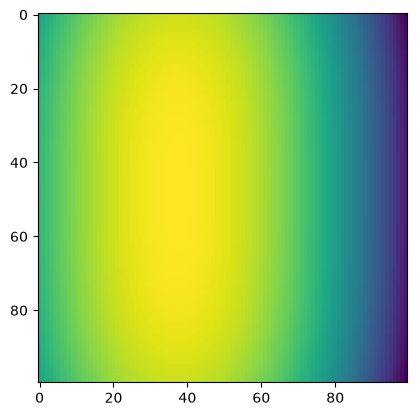

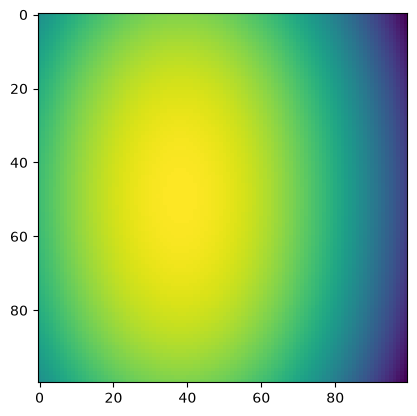

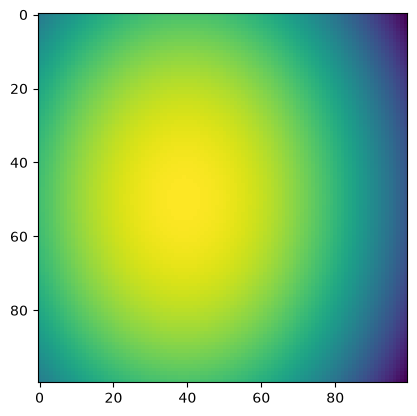

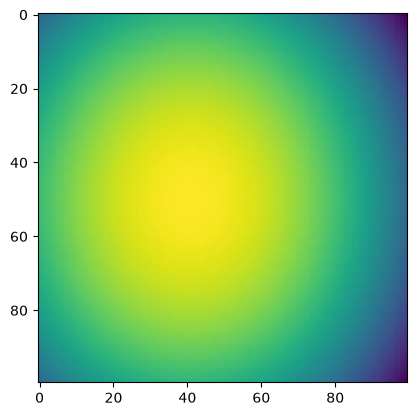

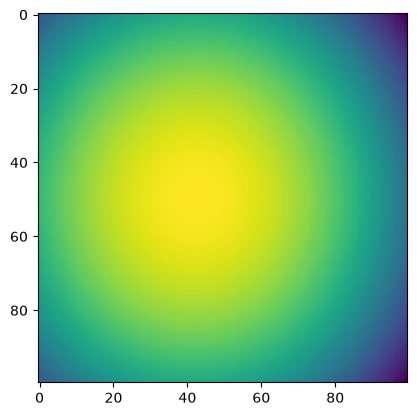

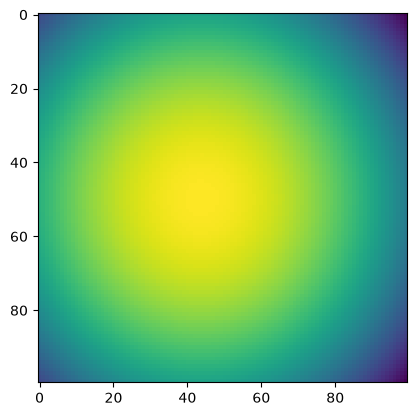

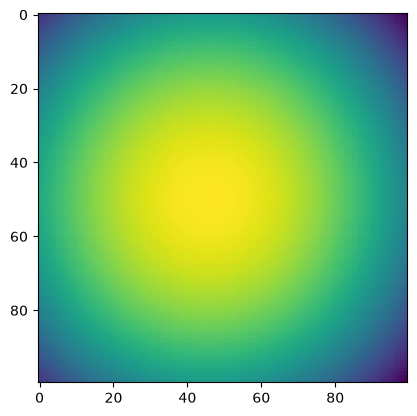

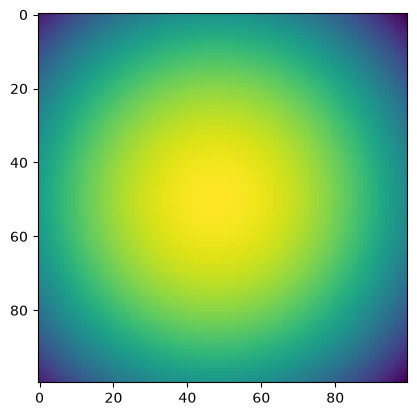

7100 0.19636838 time: 0.0033452510833740234
7200 0.18874635 time: 0.0019097328186035156
7300 0.20304787 time: 0.0019087791442871094
7400 0.18572429 time: 0.0020508766174316406
7500 0.19991334 time: 0.0018625259399414062
7600 0.18623494 time: 0.0018460750579833984
7700 0.19921629 time: 0.00373077392578125
7800 0.17907129 time: 0.0017936229705810547
7900 0.18418637 time: 0.001986980438232422
8000 0.20110495 time: 0.0019130706787109375


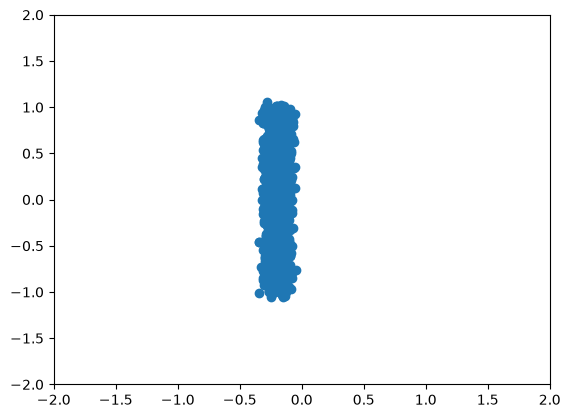

TEST 8000 logpx 0.65810364


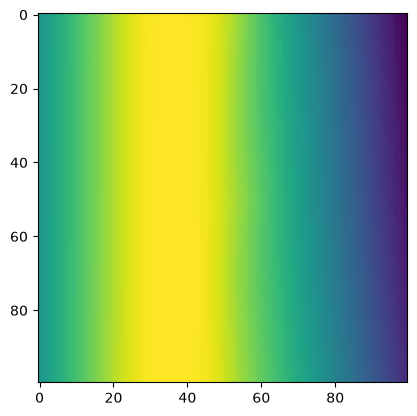

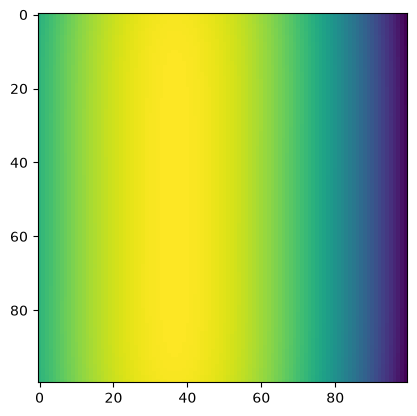

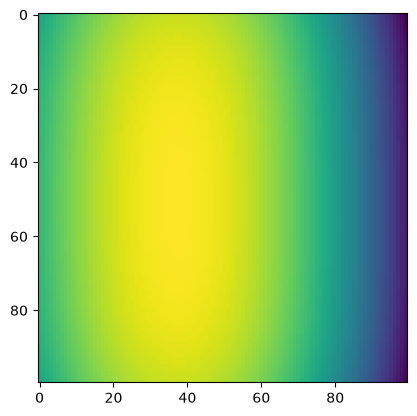

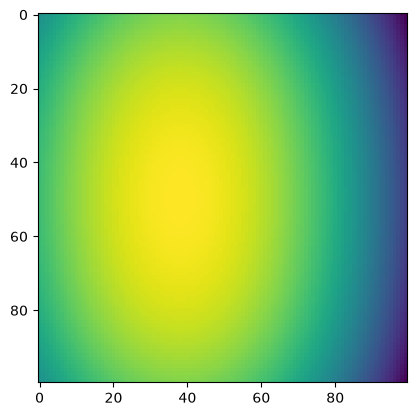

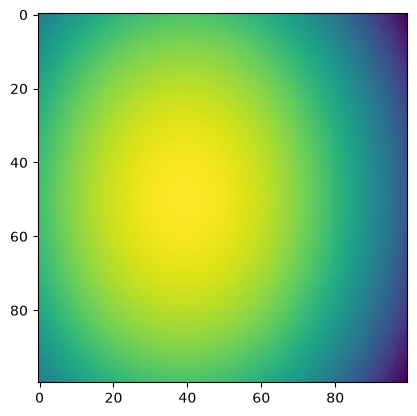

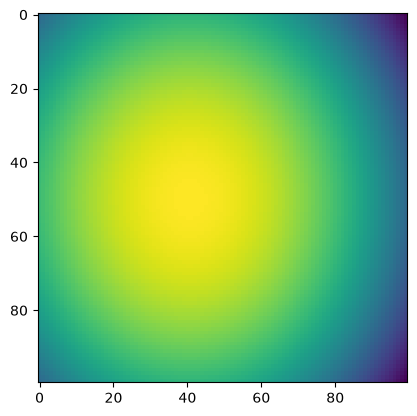

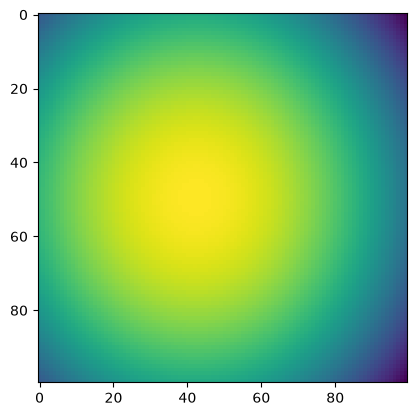

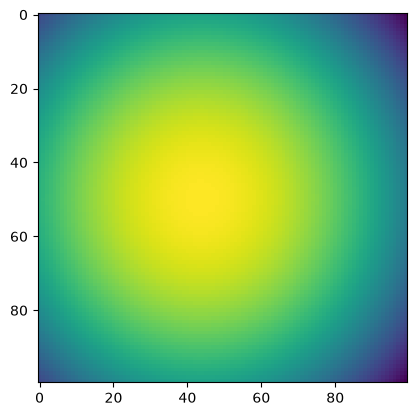

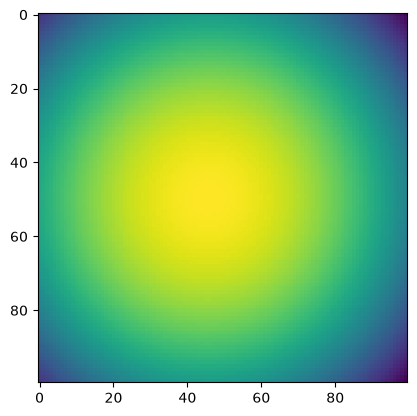

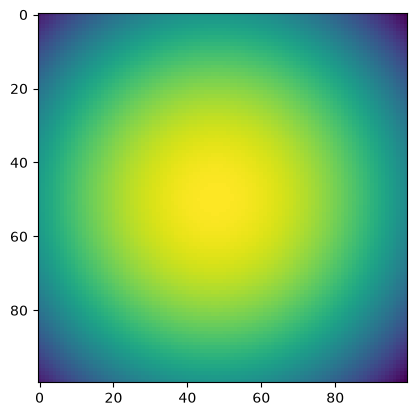

8100 0.19344059 time: 0.002867460250854492
8200 0.18476781 time: 0.0018241405487060547
8300 0.20326893 time: 0.0018248558044433594
8400 0.22520353 time: 0.003065347671508789
8500 0.20413764 time: 0.0018768310546875
8600 0.18314046 time: 0.0018756389617919922
8700 0.1777874 time: 0.00189208984375
8800 0.19386928 time: 0.0018048286437988281
8900 0.18253809 time: 0.003493785858154297
9000 0.19814274 time: 0.0034787654876708984


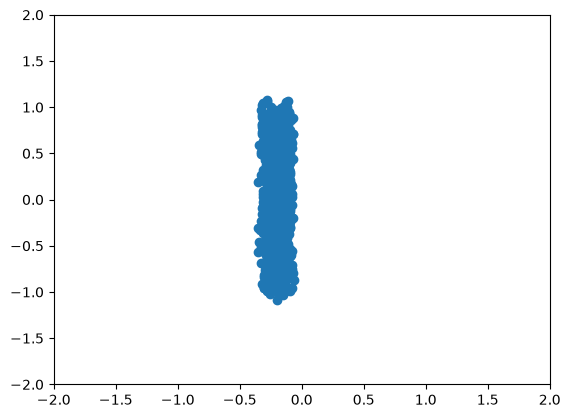

TEST 9000 logpx 0.73219436


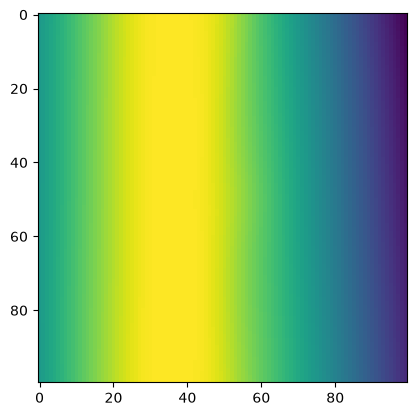

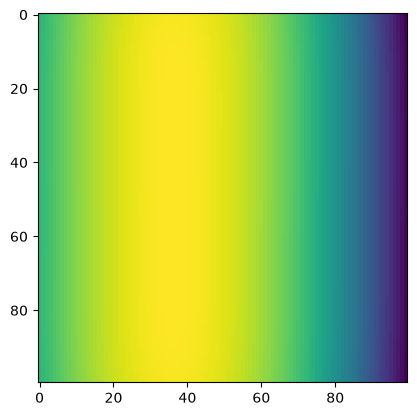

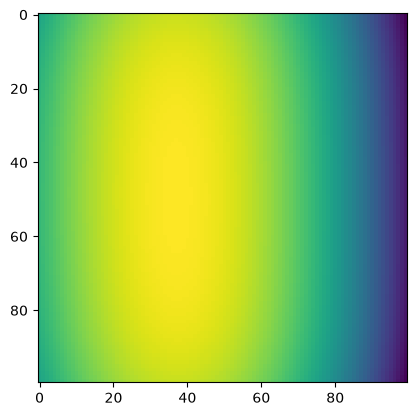

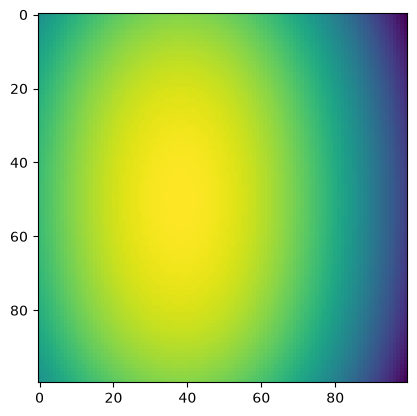

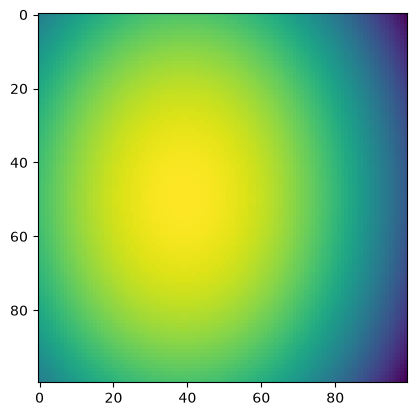

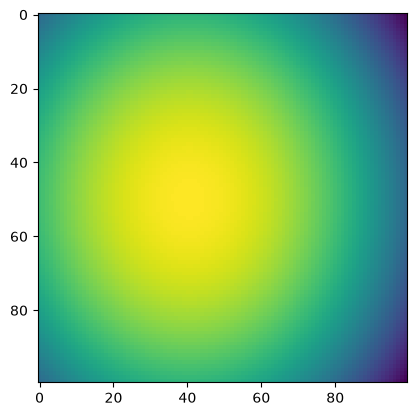

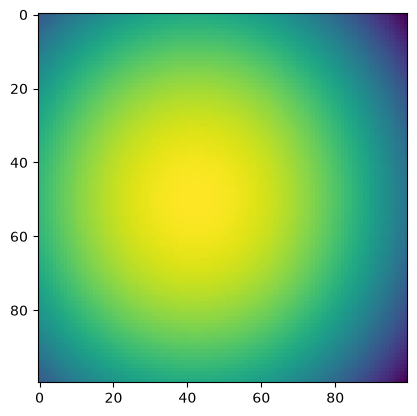

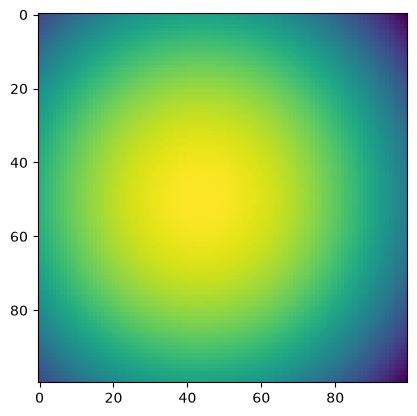

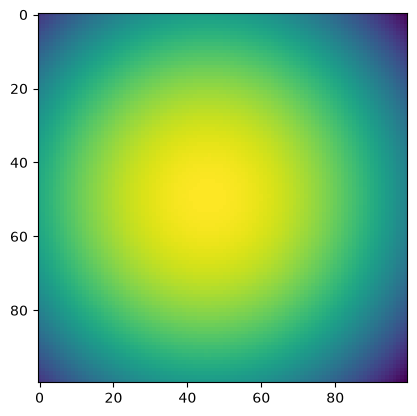

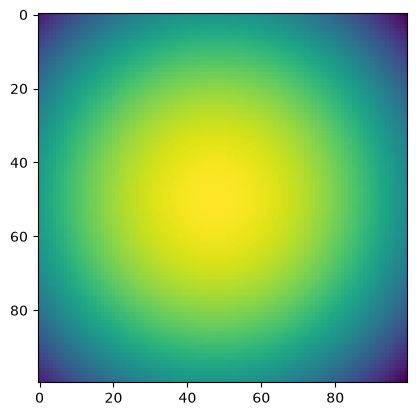

9100 0.18054387 time: 0.00351715087890625
9200 0.18510914 time: 0.0035016536712646484
9300 0.1838968 time: 0.0035653114318847656
9400 0.19654468 time: 0.002524137496948242
9500 0.19305211 time: 0.0019192695617675781
9600 0.20286302 time: 0.0019884109497070312
9700 0.19762833 time: 0.001979827880859375
9800 0.20263627 time: 0.003908634185791016
9900 0.19753611 time: 0.0019466876983642578
10000 0.18635845 time: 0.001966238021850586


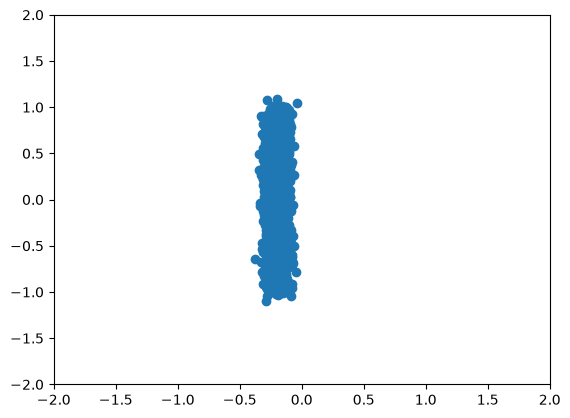

TEST 10000 logpx 0.77714735


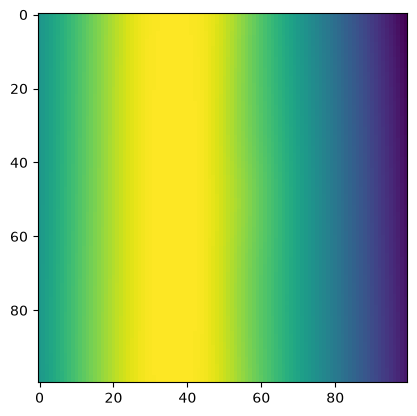

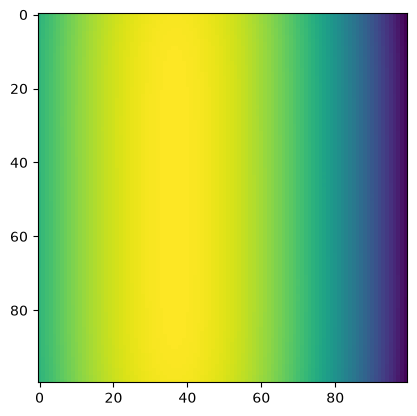

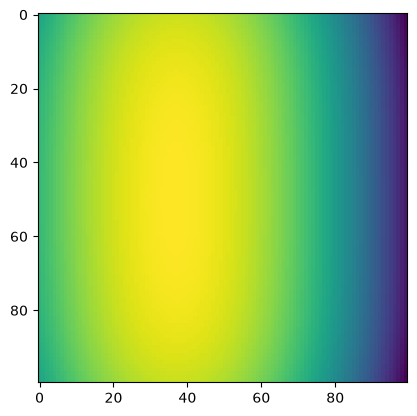

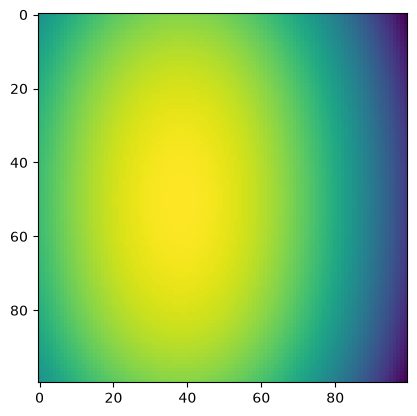

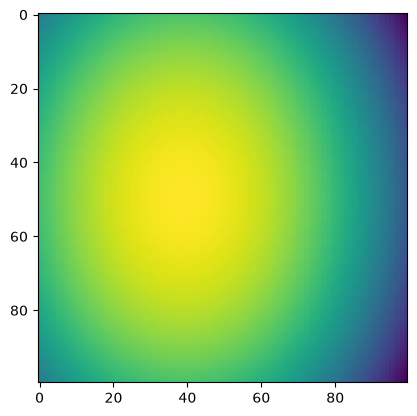

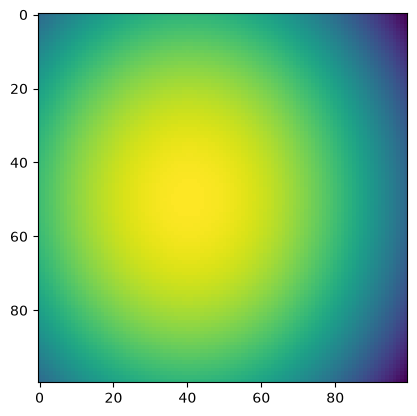

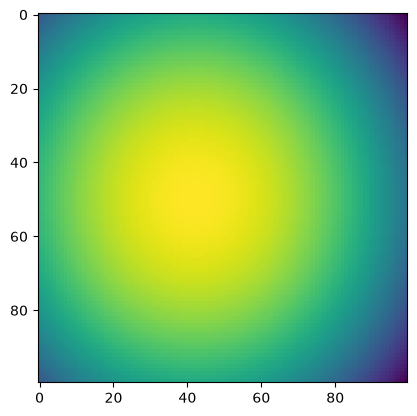

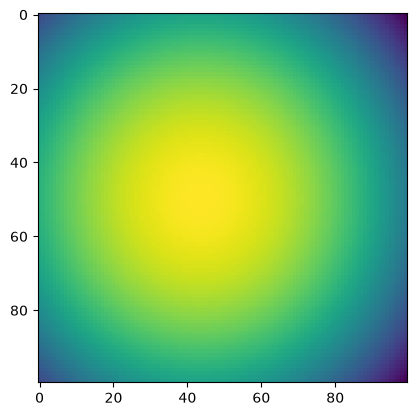

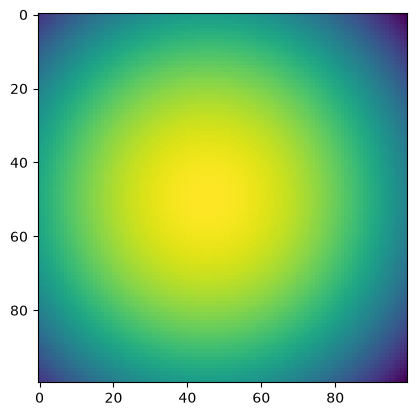

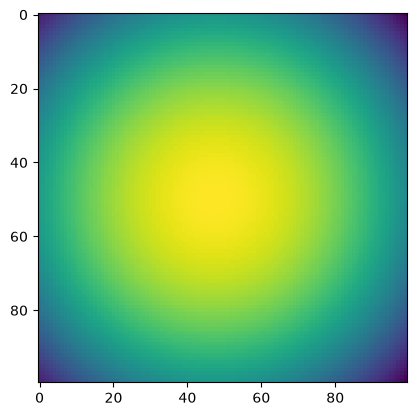

10100 0.20317823 time: 0.004545927047729492
10200 0.19646645 time: 0.0023148059844970703
10300 0.17384008 time: 0.001840829849243164
10400 0.18495655 time: 0.002796649932861328
10500 0.18059662 time: 0.0034160614013671875
10600 0.2008652 time: 0.003414630889892578
10700 0.17667282 time: 0.001932382583618164
10800 0.19672345 time: 0.0024480819702148438
10900 0.2050547 time: 0.005148410797119141
11000 0.18459769 time: 0.0018391609191894531


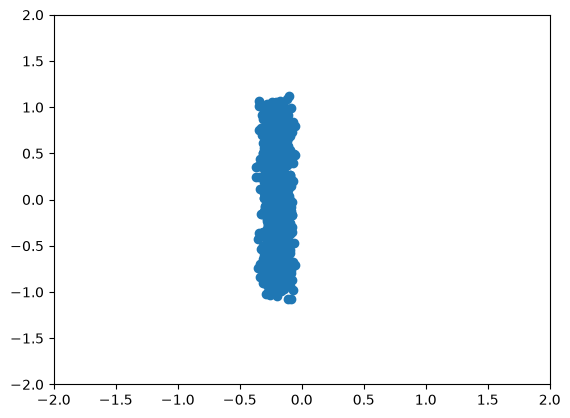

TEST 11000 logpx 0.7620701


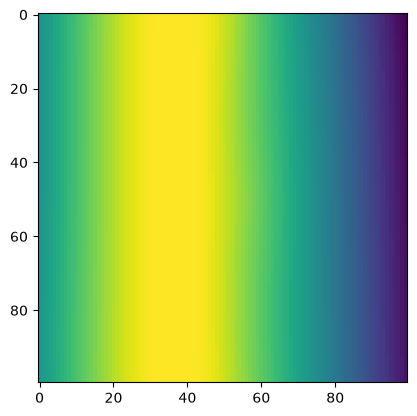

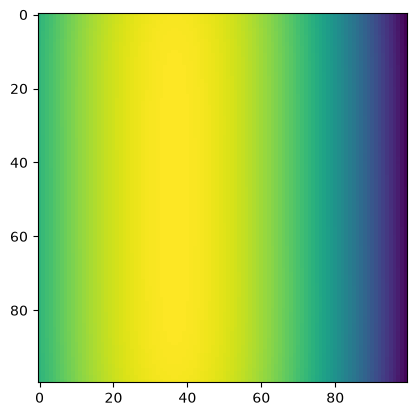

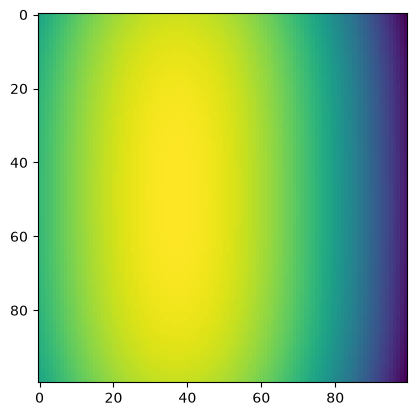

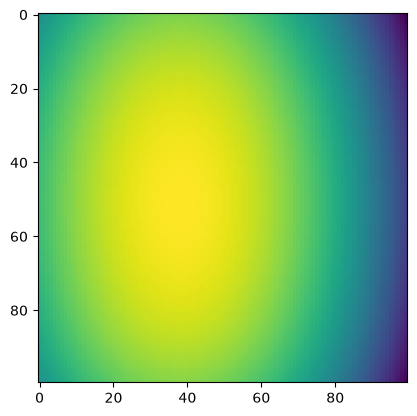

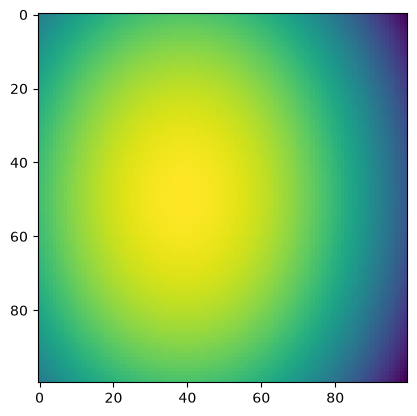

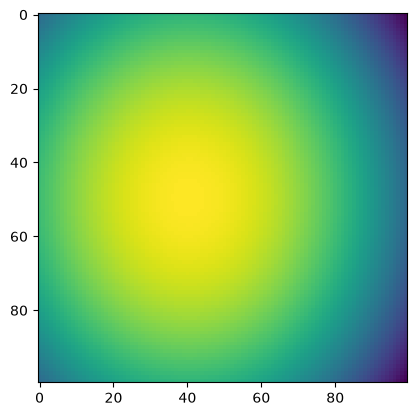

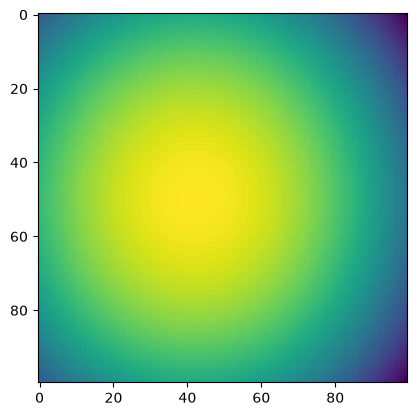

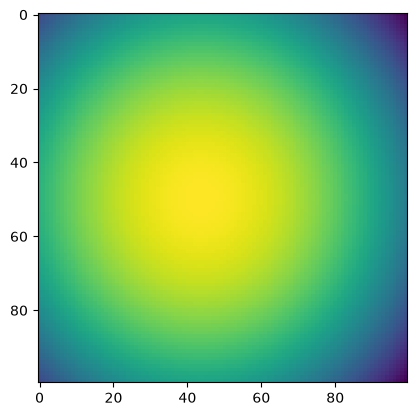

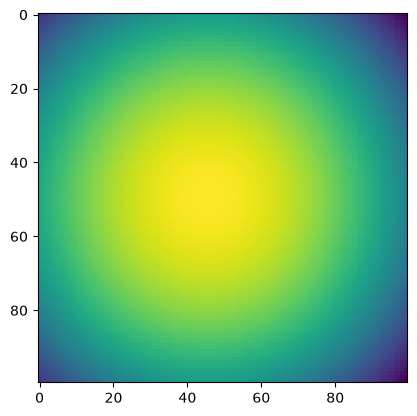

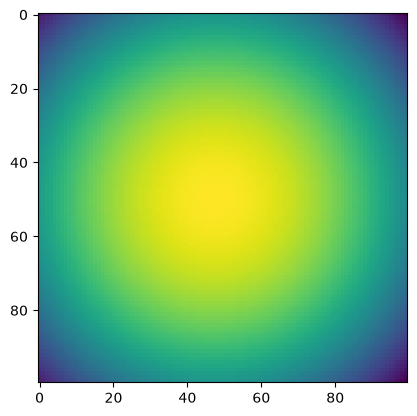

11100 0.20968767 time: 0.005596637725830078
11200 0.16981712 time: 0.002118349075317383
11300 0.22094335 time: 0.0028007030487060547
11400 0.20113988 time: 0.003697633743286133
11500 0.1943559 time: 0.0018193721771240234
11600 0.17078874 time: 0.004088401794433594
11700 0.21291909 time: 0.003824472427368164
11800 0.19769026 time: 0.0017800331115722656
11900 0.201606 time: 0.003546476364135742
12000 0.20306696 time: 0.0023555755615234375


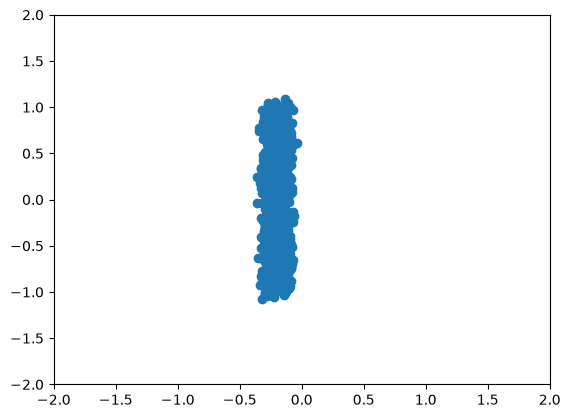

TEST 12000 logpx 0.7075584


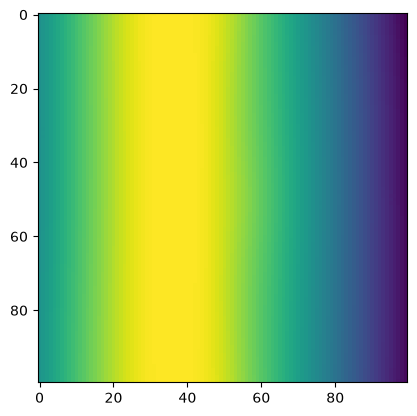

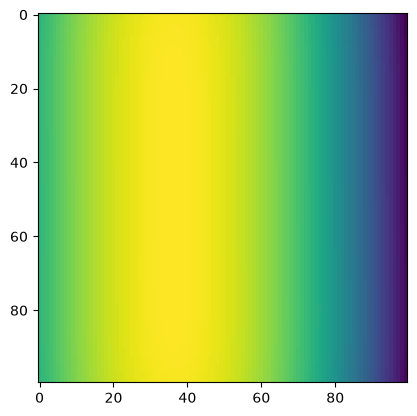

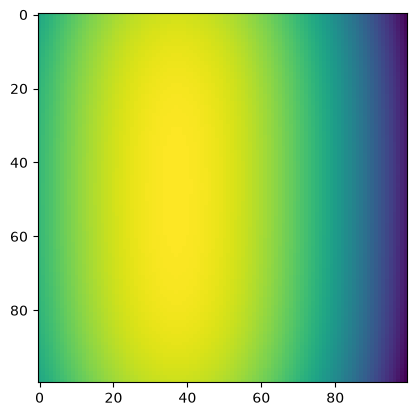

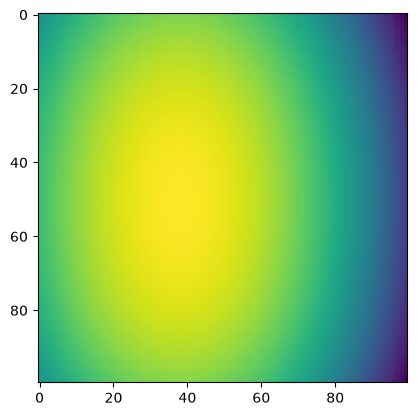

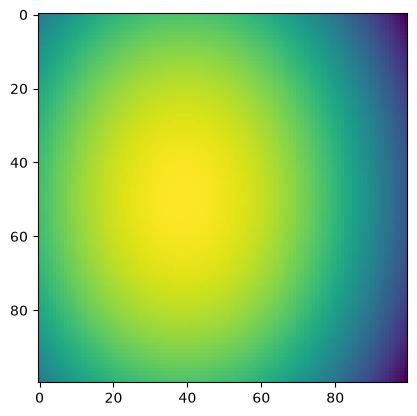

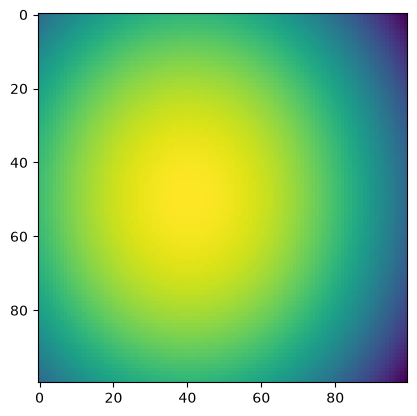

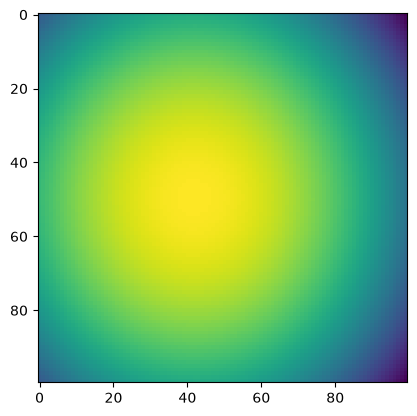

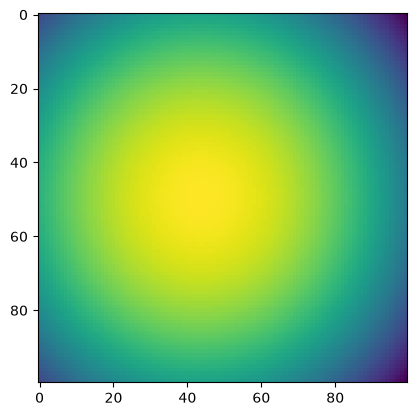

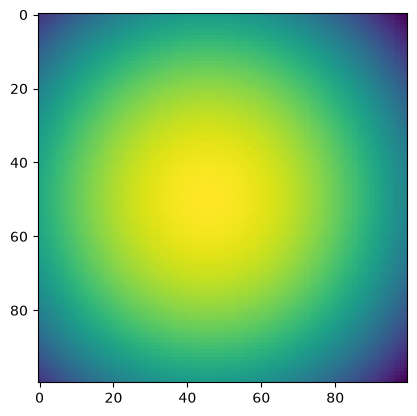

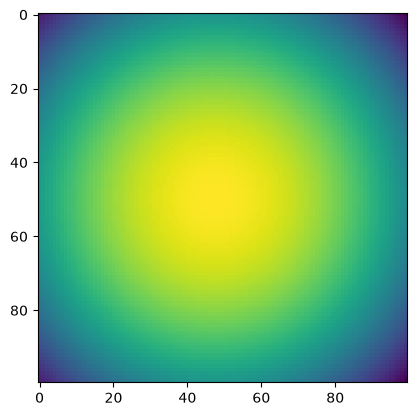

12100 0.19640821 time: 0.003841876983642578
12200 0.18985692 time: 0.001984119415283203
12300 0.22168003 time: 0.0018575191497802734
12400 0.17048971 time: 0.002006053924560547
12500 0.18917923 time: 0.00341796875
12600 0.19288556 time: 0.0020055770874023438
12700 0.199533 time: 0.001855611801147461
12800 0.20235926 time: 0.001990079879760742
12900 0.18838584 time: 0.0019674301147460938
13000 0.19729555 time: 0.0018019676208496094


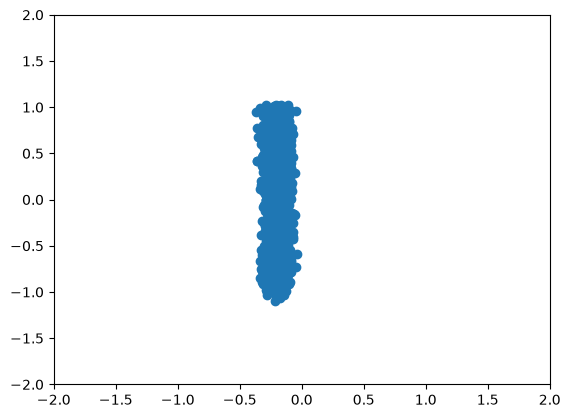

TEST 13000 logpx 0.80788654


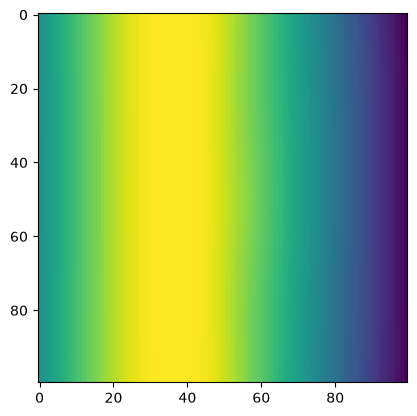

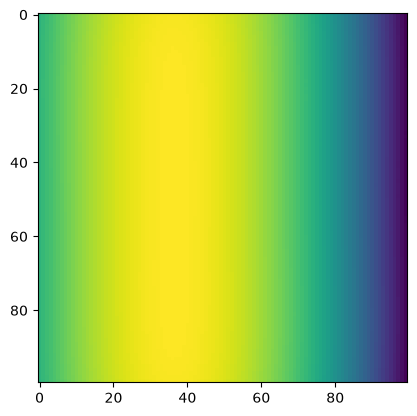

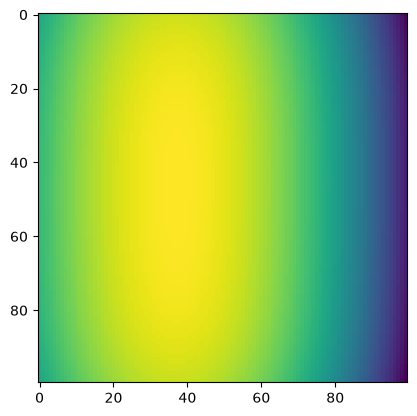

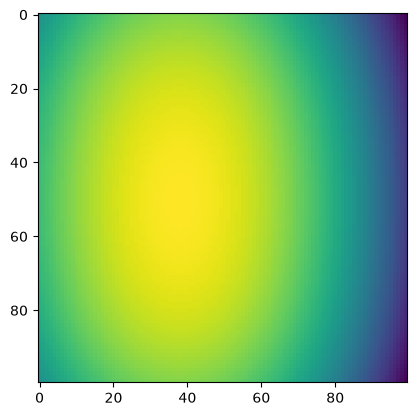

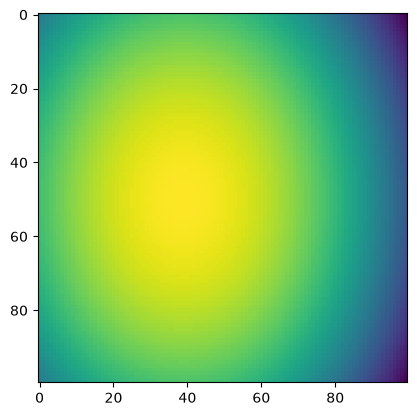

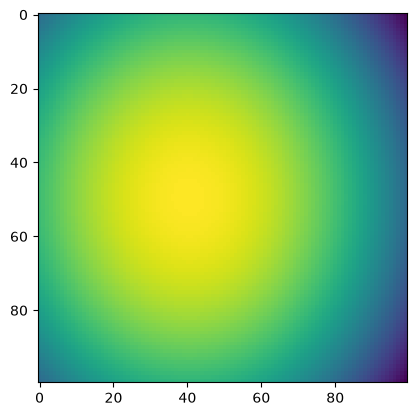

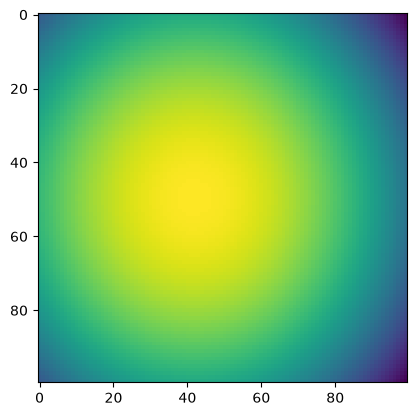

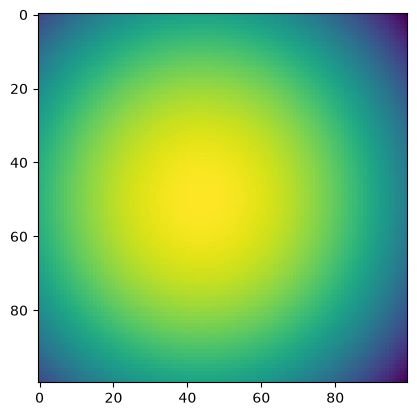

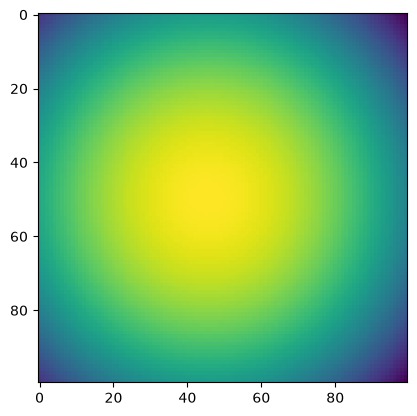

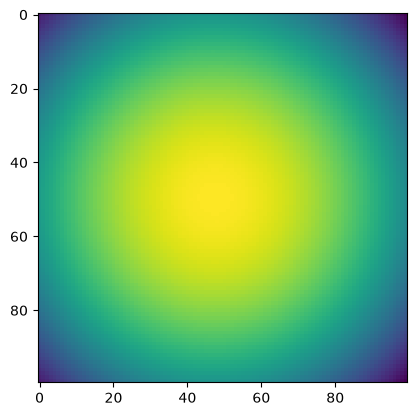

13100 0.1650535 time: 0.0020024776458740234
13200 0.18643837 time: 0.0019850730895996094
13300 0.19265322 time: 0.002087116241455078
13400 0.19187562 time: 0.0022966861724853516
13500 0.18194315 time: 0.001954793930053711
13600 0.18239895 time: 0.002189159393310547
13700 0.18553723 time: 0.0022618770599365234
13800 0.18449993 time: 0.002092599868774414
13900 0.18897584 time: 0.00180816650390625
14000 0.1787679 time: 0.0018749237060546875


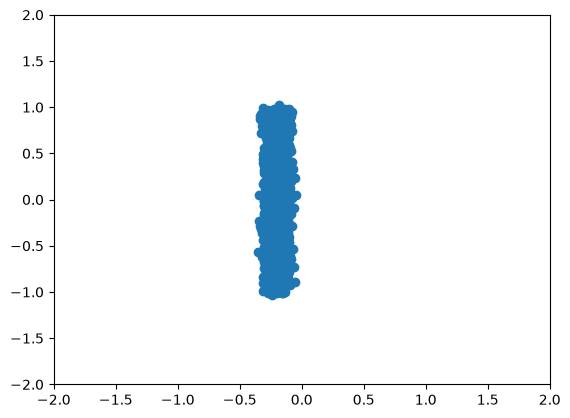

TEST 14000 logpx 0.7872541


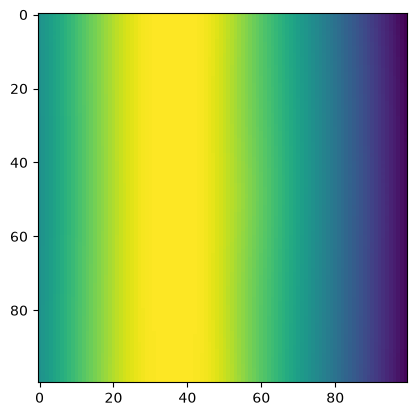

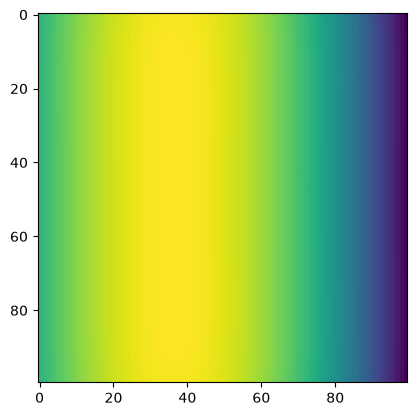

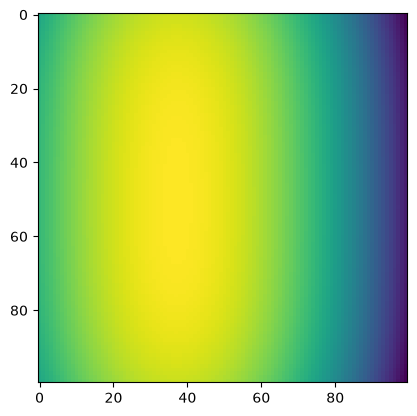

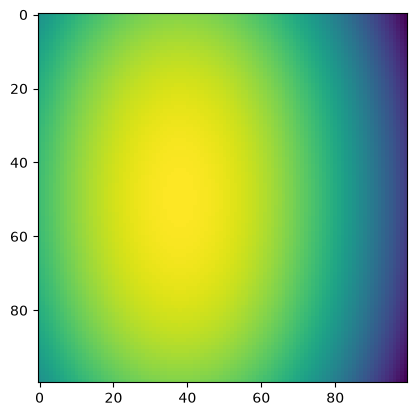

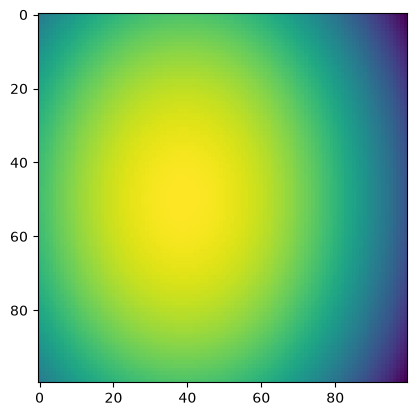

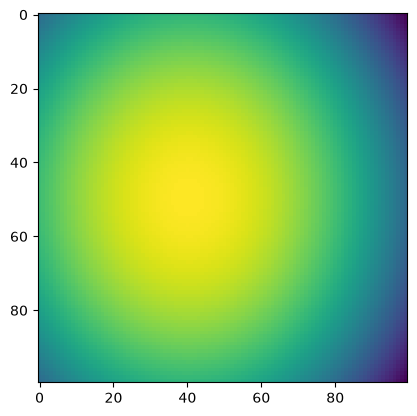

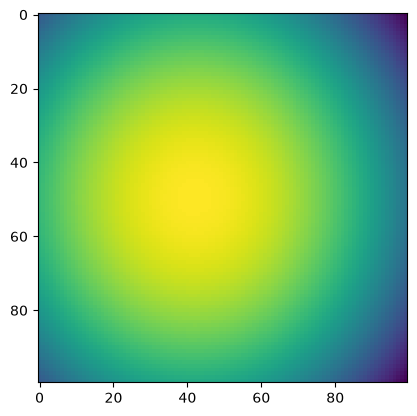

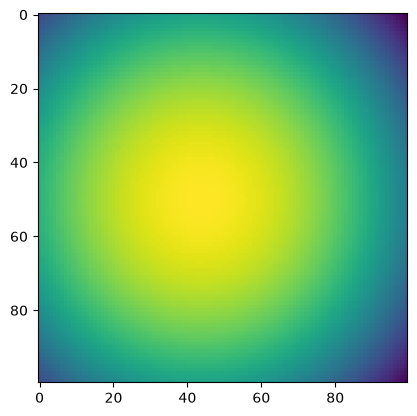

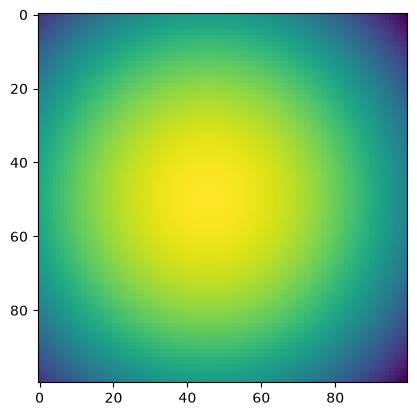

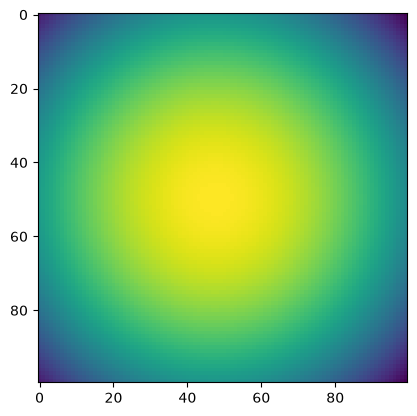

14100 0.17218874 time: 0.0033173561096191406
14200 0.19816422 time: 0.0020494461059570312
14300 0.17657846 time: 0.001955747604370117
14400 0.18090275 time: 0.0018422603607177734
14500 0.20264445 time: 0.0019817352294921875
14600 0.21920918 time: 0.0021240711212158203
14700 0.21116167 time: 0.002281665802001953
14800 0.19645436 time: 0.0018925666809082031
14900 0.20254084 time: 0.0021305084228515625
15000 0.21240145 time: 0.0017919540405273438


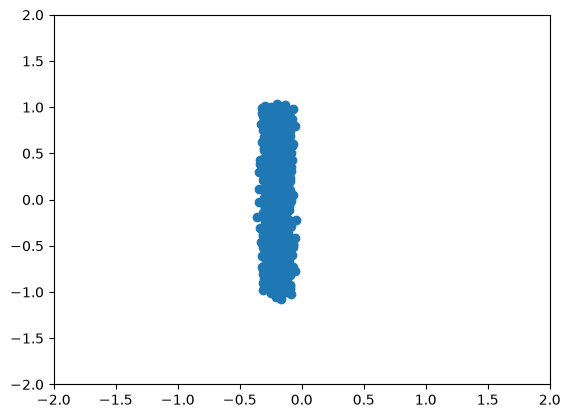

TEST 15000 logpx 0.8027474


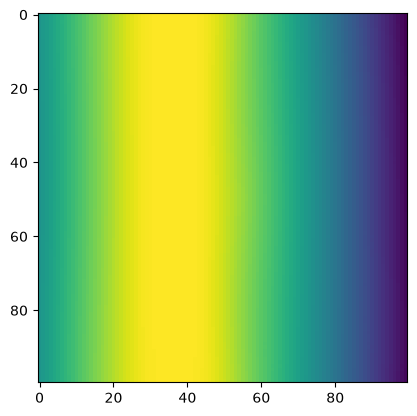

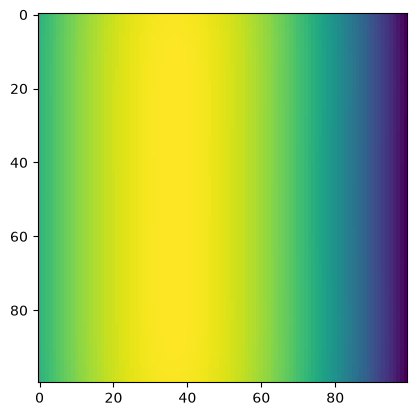

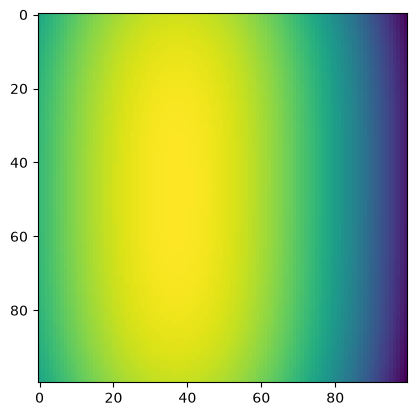

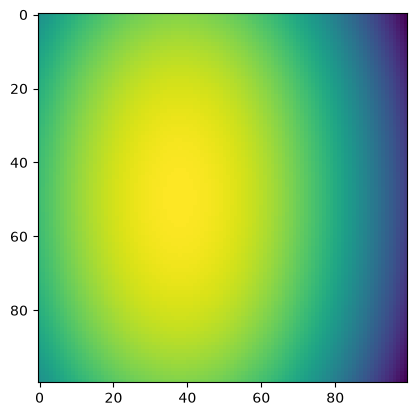

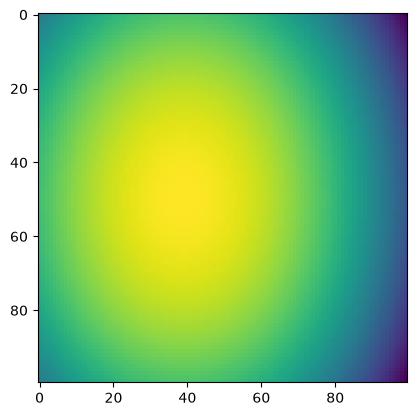

...

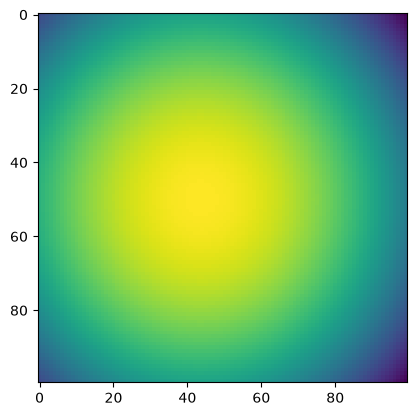

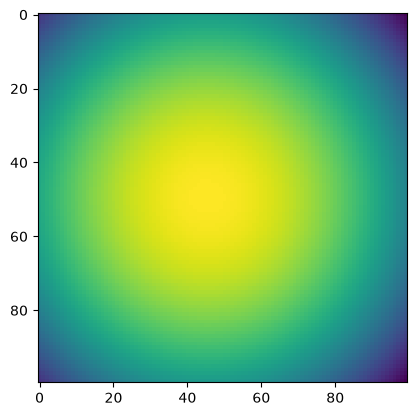

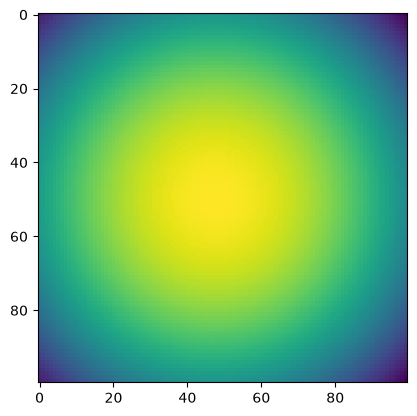

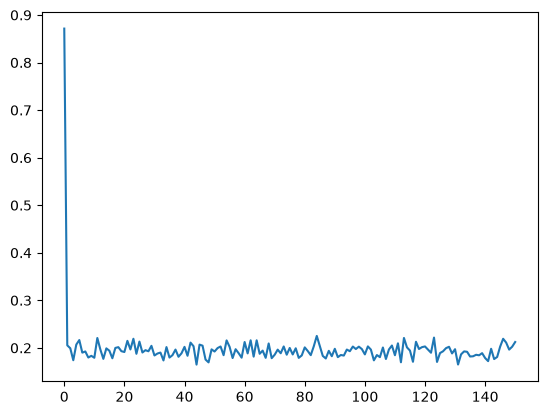

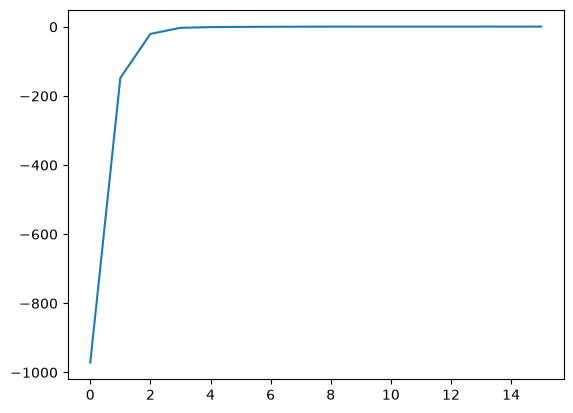

In [32]:
# Train Left Bar EBM Model
batch_size = 1000
data_dim = 2
num_steps = 15001

EMA = .999

n_steps = 100
net_params = {"n_layers": 4,
              "h_dim": 128,
              "emb_dim": 32}

def forward_fn():
  net = ResnetDiffusionModel(n_steps=n_steps, n_layers=4, x_dim=data_dim, h_dim=128, emb_dim=32)

  if ebm:
    net = EBMDiffusionModel(net)

  ddpm = PortableDiffusionModel(data_dim, n_steps, net, var_type="beta_forward")

  def logp_unnorm(x, t):
    scale_e = ddpm.energy_scale(-2 - t)
    t = jnp.ones((x.shape[0],), dtype=jnp.int32) * t
    return -net.neg_logp_unnorm(x, t) * scale_e

  def _logpx(x):
    return ddpm.logpx(x)["logpx"]
  return ddpm.loss, (ddpm.loss, ddpm.sample, _logpx, logp_unnorm)

forward = hk.multi_transform(forward_fn)
rng_seq = hk.PRNGSequence(0)

xr = [-.75, .75]
yr = [-.75, .75]


def plot_samples(x):
  plt.scatter(x[:, 0], x[:, 1])
  plt.xlim(-2, 2)
  plt.ylim(-2, 2)

def dist_show_2d(fn, xr, yr):
    nticks = 100
    x, y = np.meshgrid(np.linspace(xr[0], xr[1], nticks), np.linspace(yr[0], yr[1], nticks))
    coord = np.stack([x, y], axis=-1).reshape((-1, 2))
    heatmap = fn(coord).reshape((nticks, nticks))
    plt.imshow(heatmap)

# load data
dataset_energy, dataset_sample = left_bar()
x = dataset_sample(batch_size)

plot_samples(x)
plt.show()
x = x.reshape(x.shape[0], -1)


params = forward.init(next(rng_seq), x)
loss_fn, sample_fn, logpx_fn, logp_unnorm_fn = forward.apply
param_count = sum(x.size for x in jax.tree_leaves(params))
for k, v in jax.tree_map(lambda x: x.shape, params).items():
  print(k, v)
print("Model has {} params".format(param_count))


opt = optax.adam(1e-3)
opt_state = opt.init(params)

sample_fn = jax.jit(sample_fn, static_argnums=2)
logpx_fn = jax.jit(logpx_fn)

logp_unnorm_fn = jax.jit(logp_unnorm_fn)

@jax.jit
def mean_loss_fn(params, rng, x):
  loss = loss_fn(params, rng, x)
  return loss.mean()

@jax.jit
def update(params, opt_state, rng, x):
  loss, grad = jax.value_and_grad(mean_loss_fn)(params, rng, x)

  updates, opt_state = opt.update(grad, opt_state)
  new_params = optax.apply_updates(params, updates)
  return loss, new_params, opt_state

# Speed-only change (no maths changed): the moving average runs inside one compiled call
# instead of one small GPU operation per weight array, about 10x faster per step.
@jax.jit
def update_ema(params, ema_params, opt_state, rng, x):
  loss, params, opt_state = update(params, opt_state, rng, x)
  ema_params = jax.tree_util.tree_map(lambda e, p: e * EMA + p * (1 - EMA), ema_params, params)
  return loss, params, ema_params, opt_state

ema_params = params
losses = []
test_logpx = []
itr = 0

for itr in range(num_steps):
  x = dataset_sample(batch_size)

  x = x.reshape(x.shape[0], -1)
  start_time = time.time()
  loss, params, ema_params, opt_state = update_ema(params, ema_params, opt_state, next(rng_seq), x)
  duration_update = time.time() - start_time

  if itr % 100 == 0:
    print(itr, loss, "time:", duration_update)
    losses.append(loss)
  if itr % 1000 == 0:
    x_samp = sample_fn(ema_params, next(rng_seq), batch_size)
    plot_samples(x_samp)
    plt.show()
    logpx = logpx_fn(ema_params, next(rng_seq), x).mean()
    print("TEST", itr, 'logpx', logpx)
    test_logpx.append(logpx)

    if ebm:
      for t in range(10):
        dist_show_2d(lambda x: logp_unnorm_fn(ema_params, next(rng_seq), x, 10*t), xr=xr, yr=yr)
        plt.show()

plt.plot(losses)
plt.show()
plt.plot(test_logpx)

flow_params = params
flow_rng = next(rng_seq)

left_bar_params = ema_params

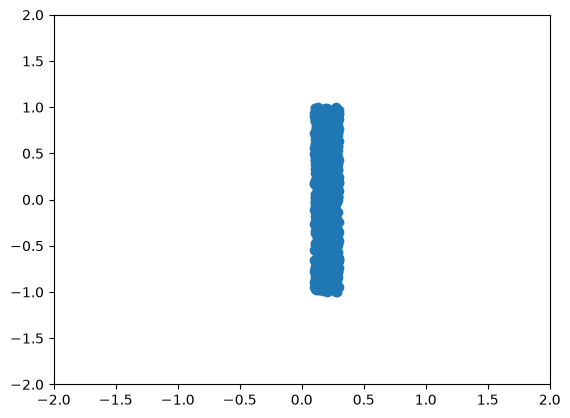

portable_diffusion_model {'out_logvar': (100,)}
resnet_diffusion_model/embed {'embeddings': (100, 32)}
resnet_diffusion_model/layer_norm {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/layer_norm_1 {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/layer_norm_2 {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/layer_norm_3 {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/linear {'b': (128,), 'w': (2, 128)}
resnet_diffusion_model/linear_1 {'b': (256,), 'w': (128, 256)}
resnet_diffusion_model/linear_10 {'b': (256,), 'w': (32, 256)}
resnet_diffusion_model/linear_11 {'b': (256,), 'w': (256, 256)}
resnet_diffusion_model/linear_12 {'b': (128,), 'w': (256, 128)}
resnet_diffusion_model/linear_13 {'b': (256,), 'w': (128, 256)}
resnet_diffusion_model/linear_14 {'b': (256,), 'w': (32, 256)}
resnet_diffusion_model/linear_15 {'b': (256,), 'w': (256, 256)}
resnet_diffusion_model/linear_16 {'b': (128,), 'w': (256, 128)}
resnet_diffusion_model/linear_17 {'b': (2,)

/tmp/ipykernel_1391087/1385371818.py:265: UserWarning: Explicitly requested dtype int64 requested in ones is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  t = jnp.ones((n,), dtype=jnp.int64) * j


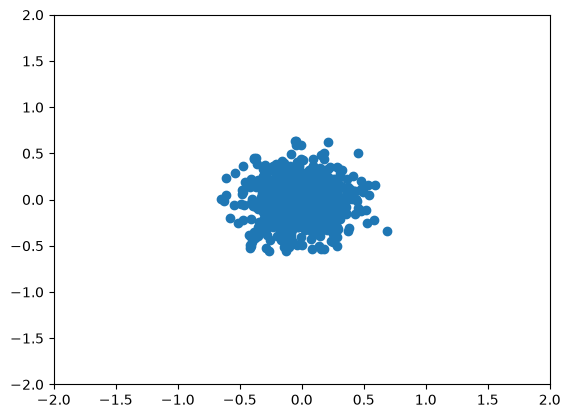

/tmp/ipykernel_1391087/1385371818.py:235: UserWarning: Explicitly requested dtype int64 requested in ones is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  t = jnp.ones((x_0.shape[0],), dtype=jnp.int64) * (self._n_steps - 1)


TEST 0 logpx -971.55804


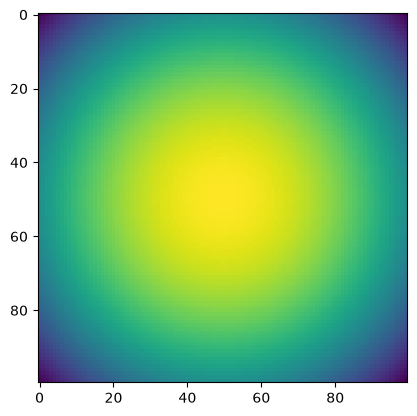

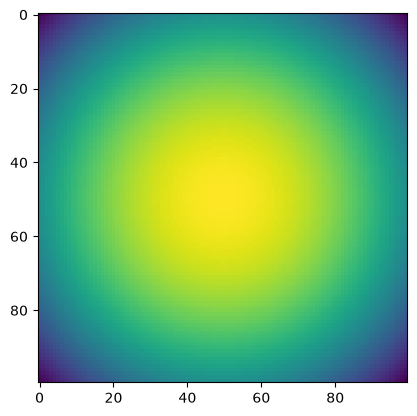

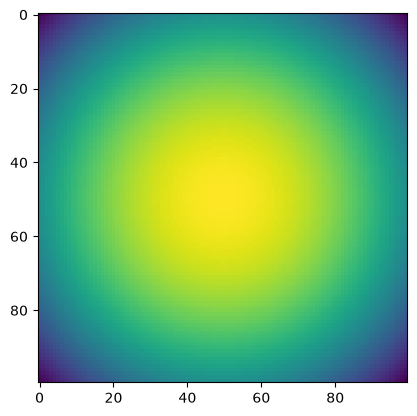

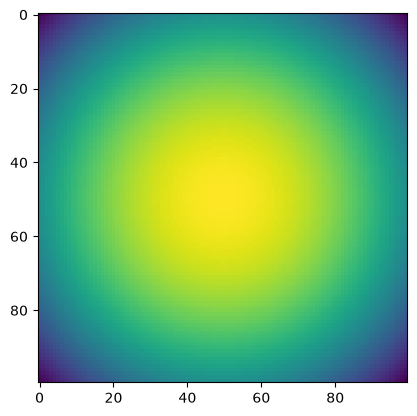

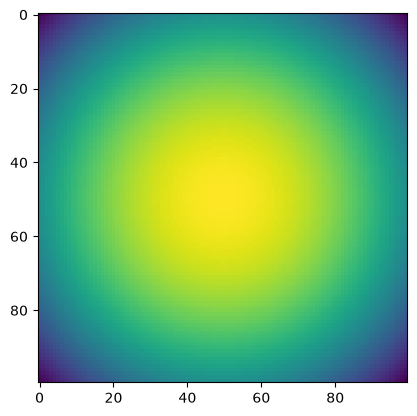

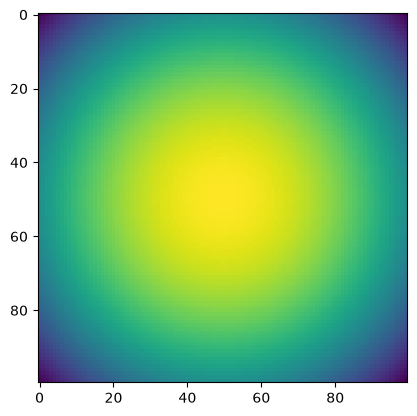

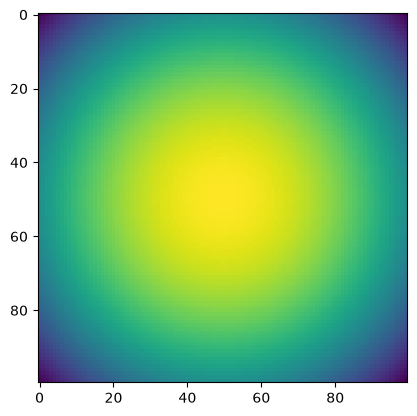

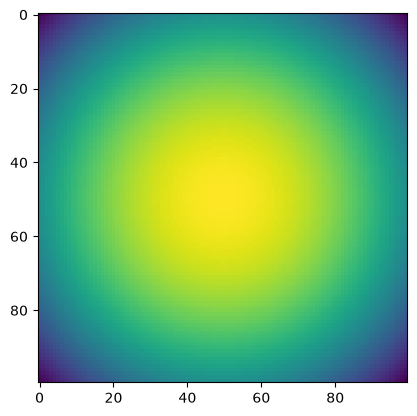

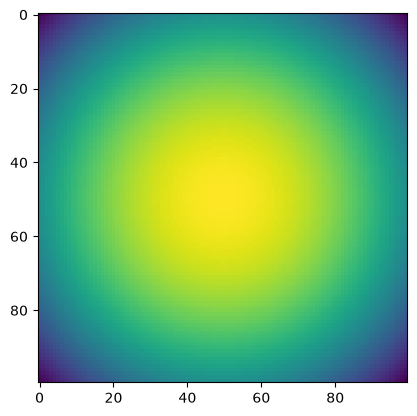

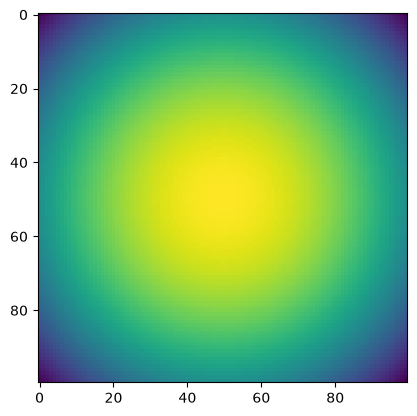

100 0.19240846 time: 0.002025127410888672
200 0.2089592 time: 0.002141714096069336
300 0.18564866 time: 0.0018868446350097656
400 0.20336832 time: 0.002662181854248047
500 0.21676114 time: 0.0024483203887939453
600 0.19229858 time: 0.002051830291748047
700 0.18429257 time: 0.0019757747650146484
800 0.18999541 time: 0.0034623146057128906
900 0.1896059 time: 0.0026357173919677734
1000 0.1914062 time: 0.002382040023803711


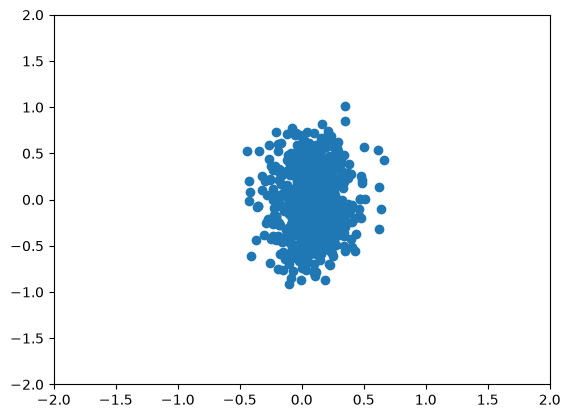

TEST 1000 logpx -143.85034


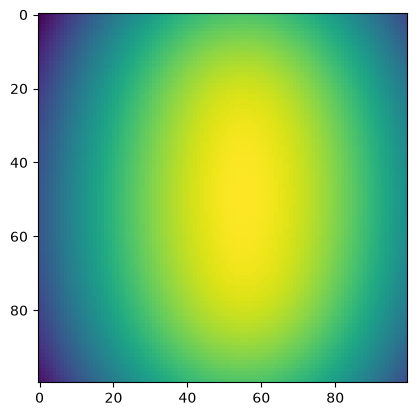

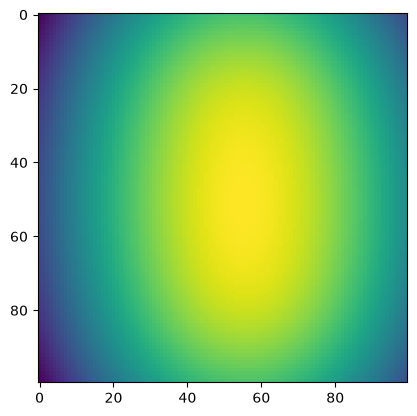

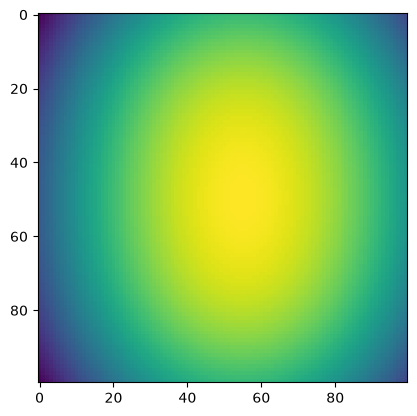

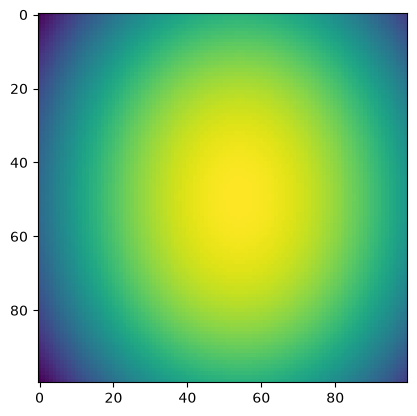

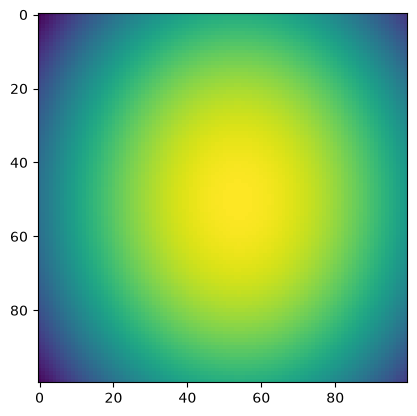

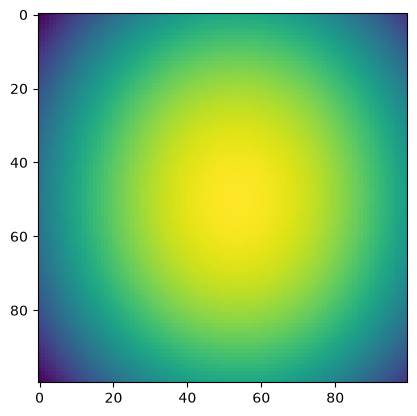

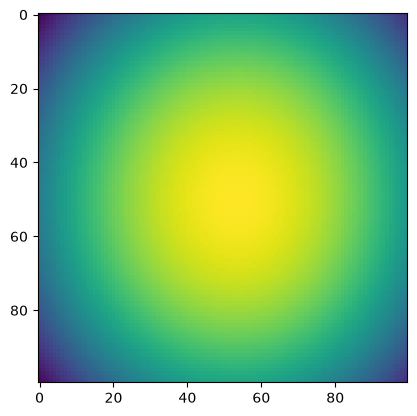

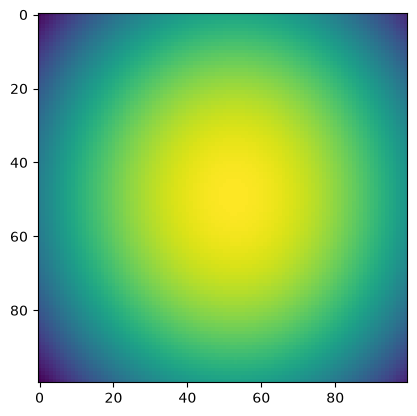

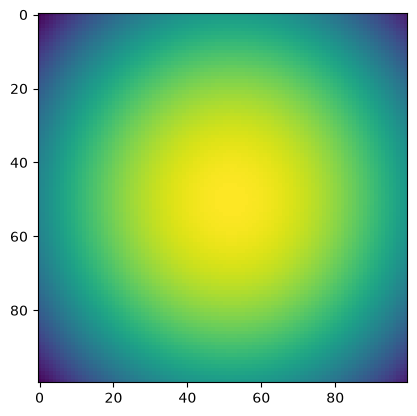

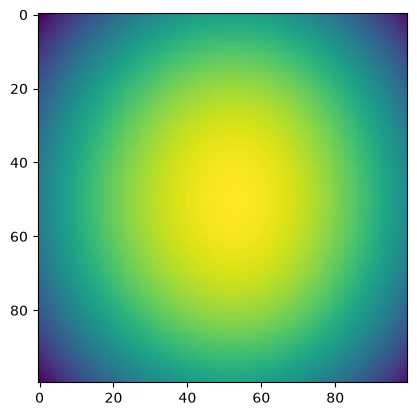

1100 0.2136579 time: 0.0018754005432128906
1200 0.19650769 time: 0.00305938720703125
1300 0.1939232 time: 0.0018570423126220703
1400 0.19924577 time: 0.002034425735473633
1500 0.19709222 time: 0.0027556419372558594
1600 0.17397046 time: 0.0027344226837158203
1700 0.20746997 time: 0.0020596981048583984
1800 0.2018551 time: 0.0030040740966796875
1900 0.19816516 time: 0.0020856857299804688
2000 0.18541908 time: 0.0019371509552001953


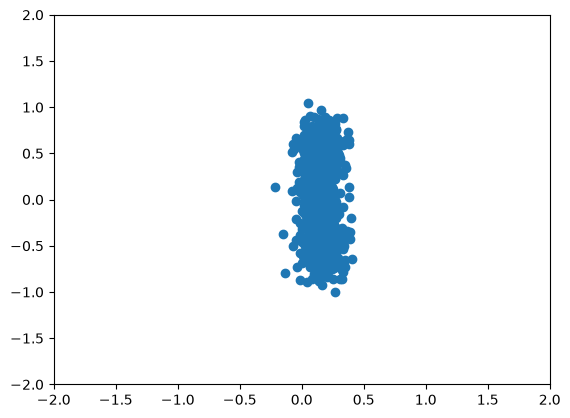

TEST 2000 logpx -20.107653


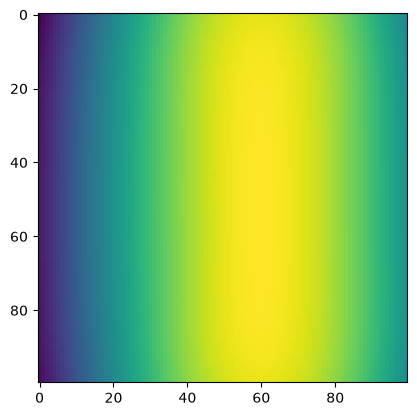

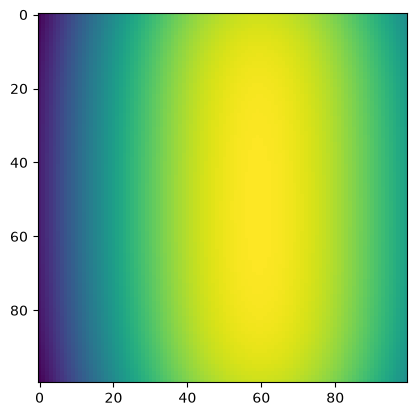

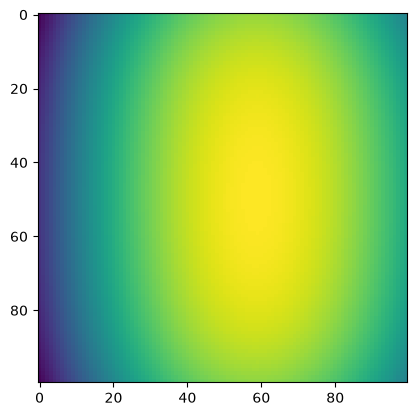

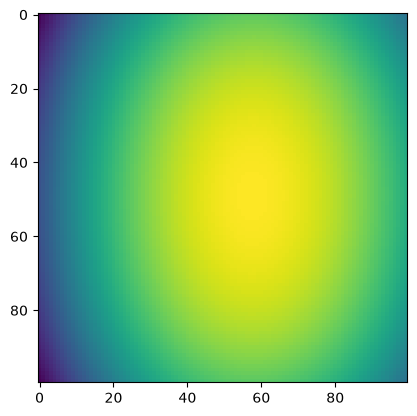

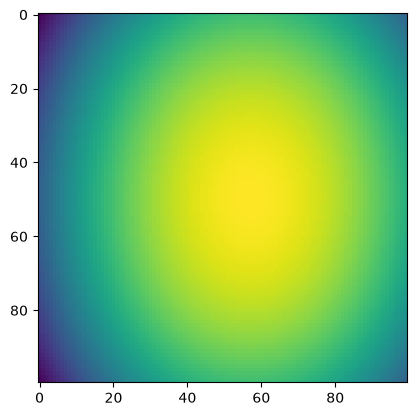

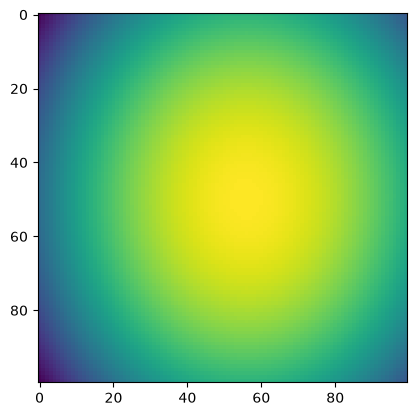

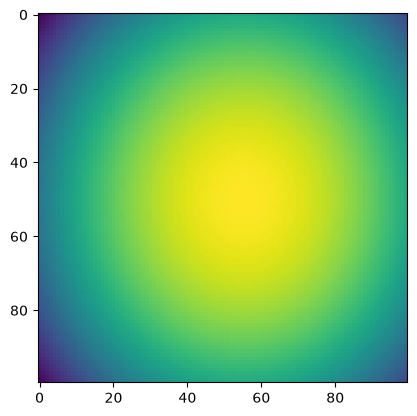

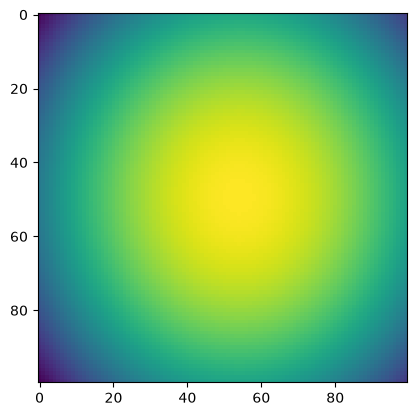

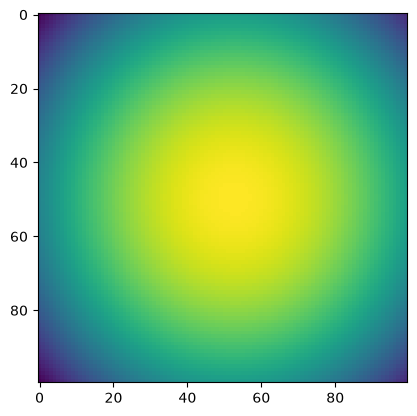

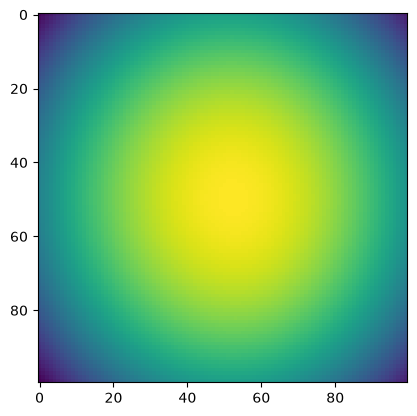

2100 0.20050357 time: 0.002126932144165039
2200 0.17958699 time: 0.001980304718017578
2300 0.21878427 time: 0.0019140243530273438
2400 0.19356911 time: 0.0019452571868896484
2500 0.20540808 time: 0.0035355091094970703
2600 0.19202363 time: 0.003488302230834961
2700 0.19440319 time: 0.0019452571868896484
2800 0.19948548 time: 0.003424406051635742
2900 0.2104429 time: 0.003459930419921875
3000 0.18958738 time: 0.0033655166625976562


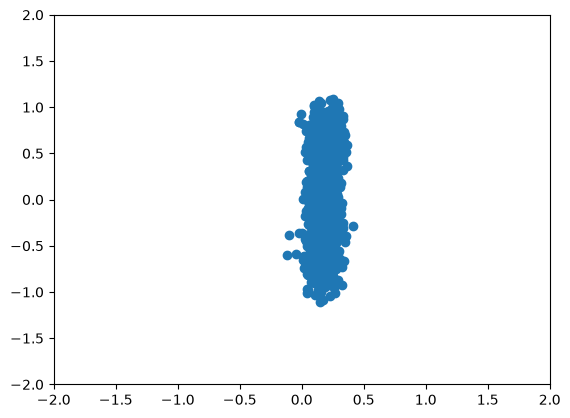

TEST 3000 logpx -3.082633


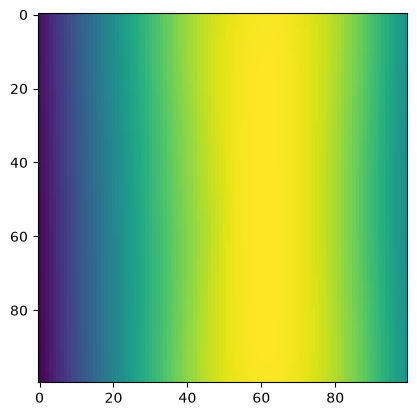

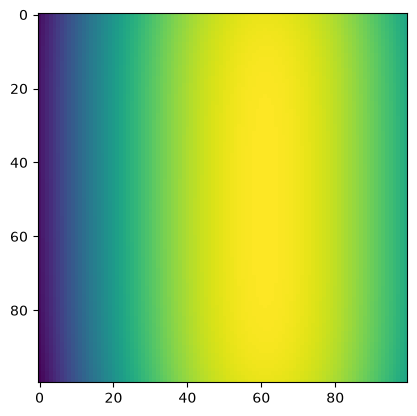

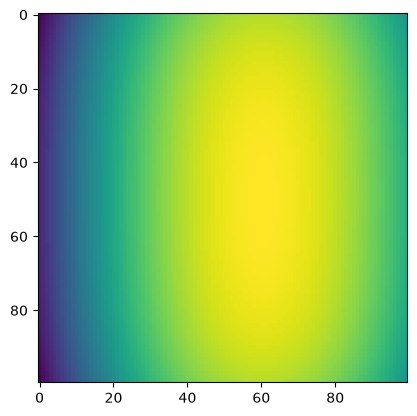

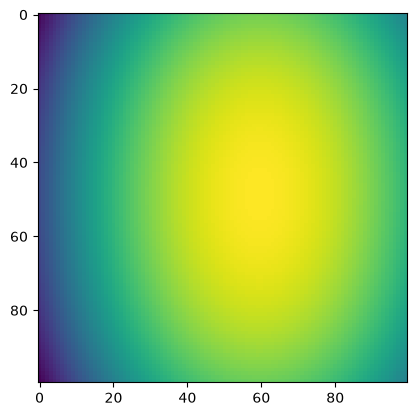

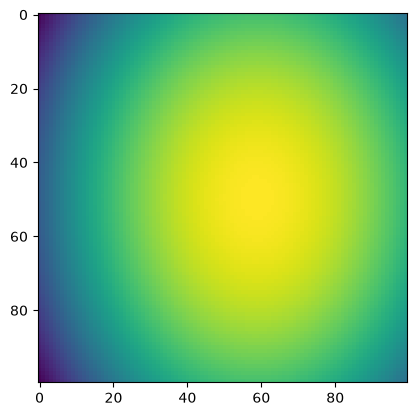

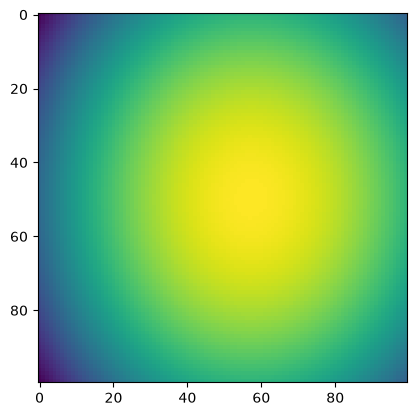

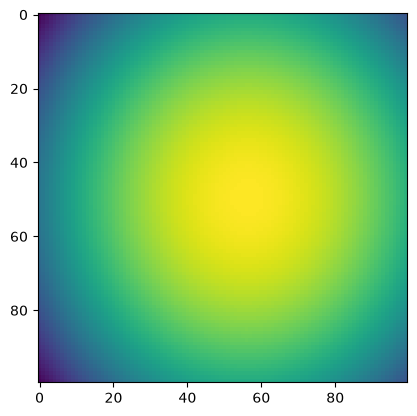

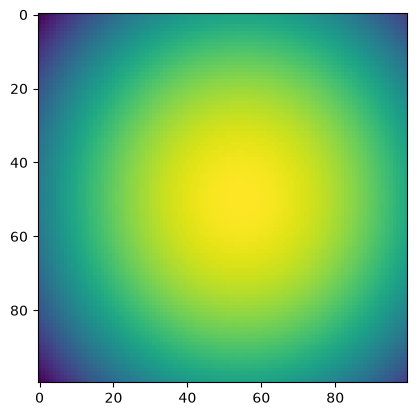

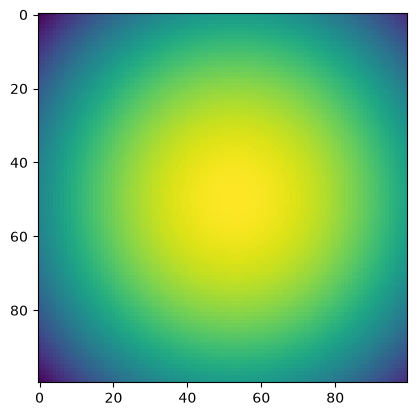

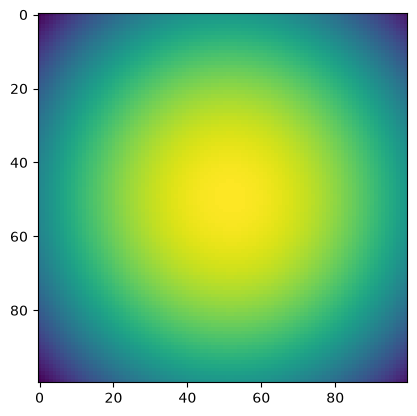

3100 0.17615575 time: 0.0019519329071044922
3200 0.1777998 time: 0.00416111946105957
3300 0.16929826 time: 0.0018529891967773438
3400 0.19549394 time: 0.003592252731323242
3500 0.19307853 time: 0.0034112930297851562
3600 0.18170267 time: 0.0019114017486572266
3700 0.20443095 time: 0.0019235610961914062
3800 0.17651232 time: 0.0033626556396484375
3900 0.19815837 time: 0.0034775733947753906
4000 0.20143534 time: 0.0017735958099365234


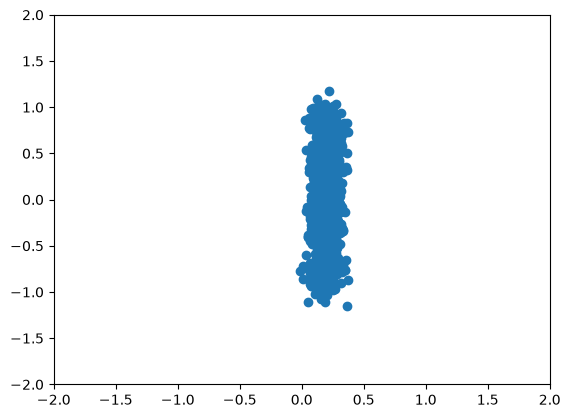

TEST 4000 logpx -0.33932757


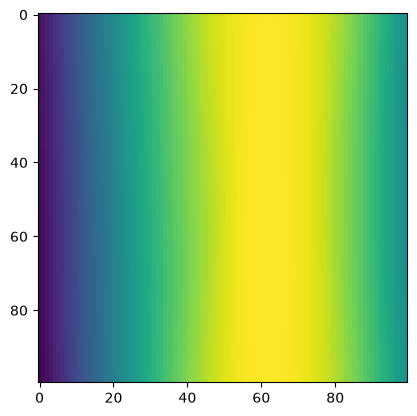

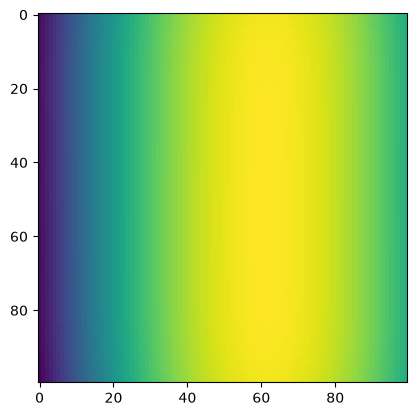

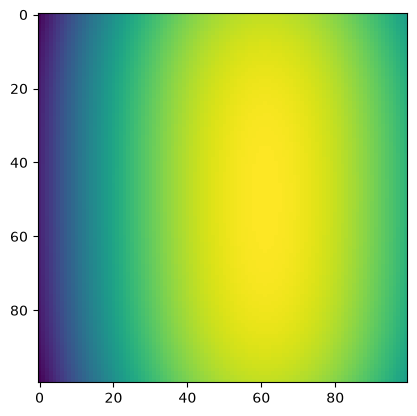

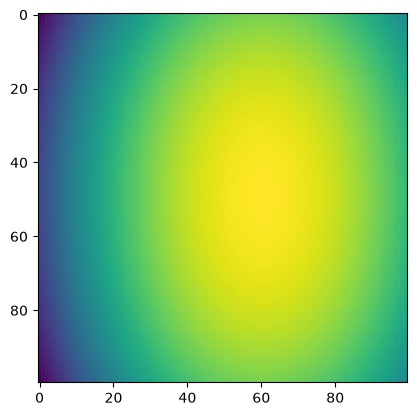

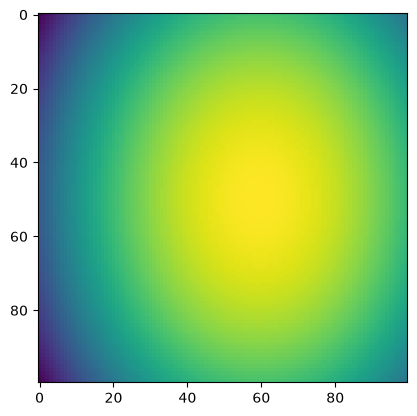

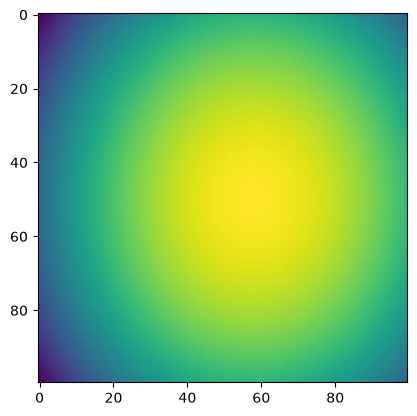

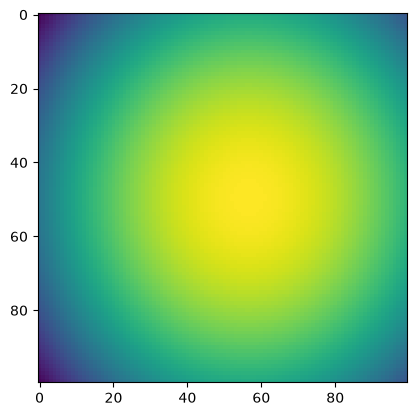

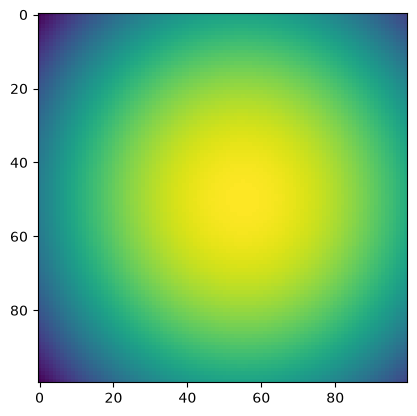

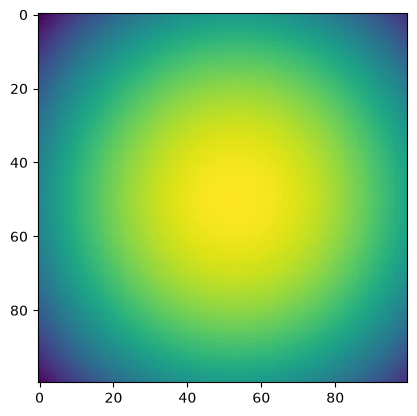

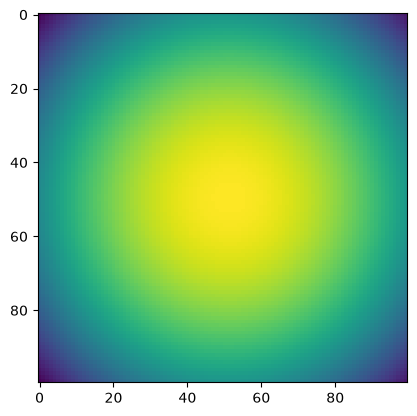

4100 0.19552335 time: 0.0020444393157958984
4200 0.19510889 time: 0.003526926040649414
4300 0.1985657 time: 0.002557039260864258
4400 0.18118095 time: 0.0018811225891113281
4500 0.20767127 time: 0.0017514228820800781
4600 0.20207374 time: 0.0018184185028076172
4700 0.19601789 time: 0.0018968582153320312
4800 0.18765311 time: 0.0017533302307128906
4900 0.20600733 time: 0.001813650131225586
5000 0.19985604 time: 0.0018274784088134766


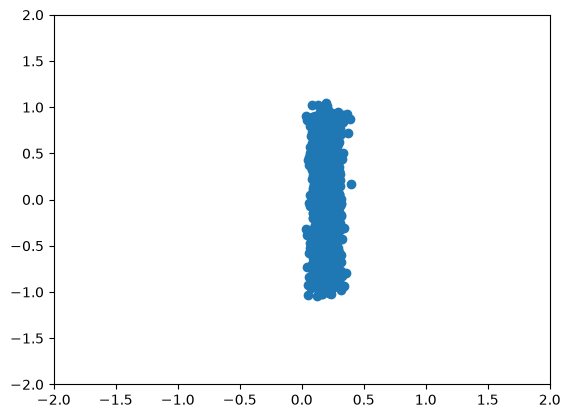

TEST 5000 logpx 0.24947046


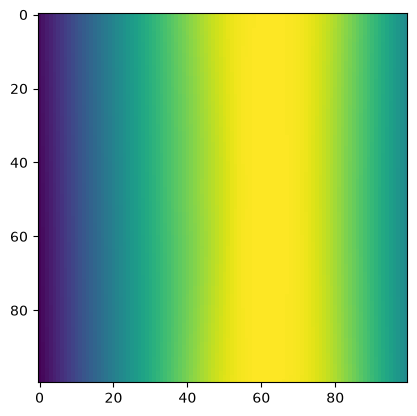

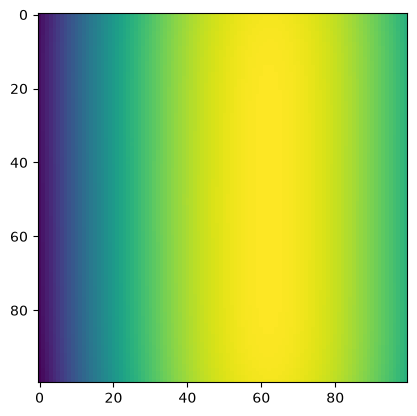

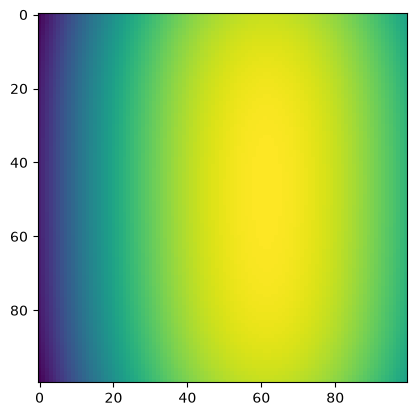

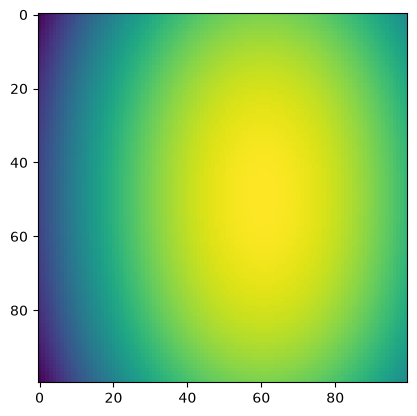

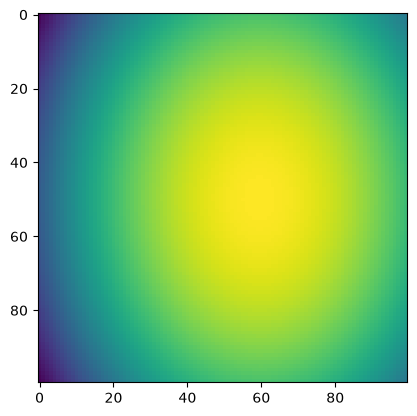

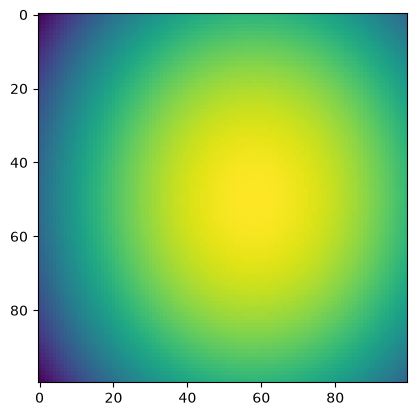

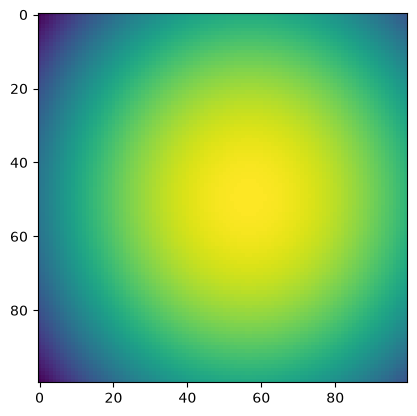

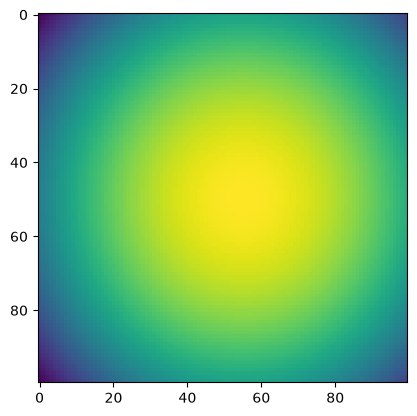

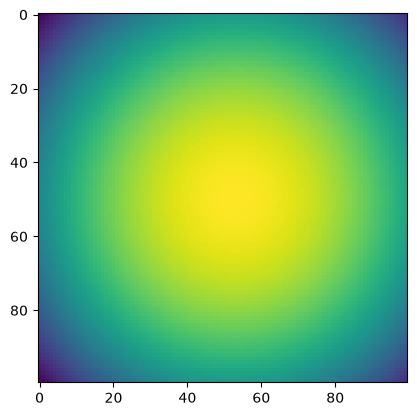

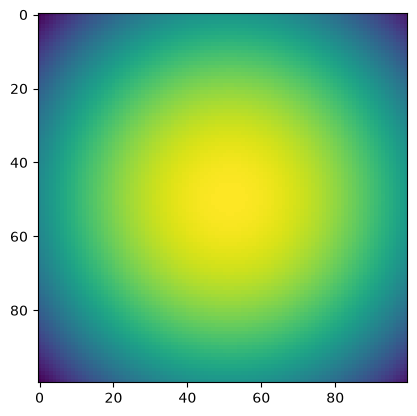

5100 0.19541837 time: 0.001966238021850586
5200 0.20324029 time: 0.002119779586791992
5300 0.19501975 time: 0.0020465850830078125
5400 0.20800017 time: 0.0030307769775390625
5500 0.20798017 time: 0.002080202102661133
5600 0.18101229 time: 0.0019152164459228516
5700 0.20709266 time: 0.0018620491027832031
5800 0.18880957 time: 0.003480195999145508
5900 0.17906667 time: 0.003194570541381836
6000 0.20252666 time: 0.0019450187683105469


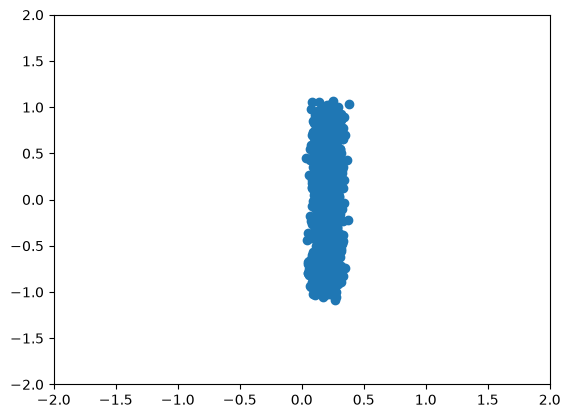

TEST 6000 logpx 0.38422242


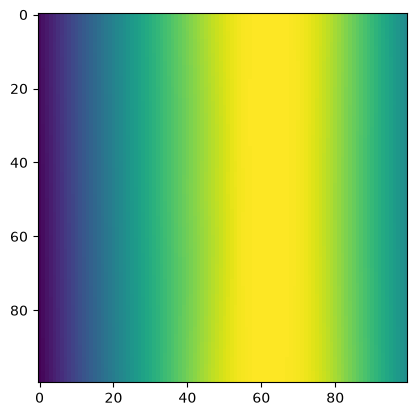

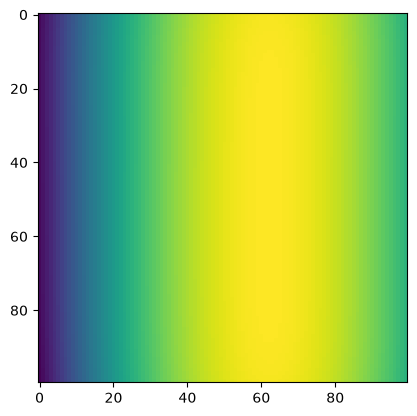

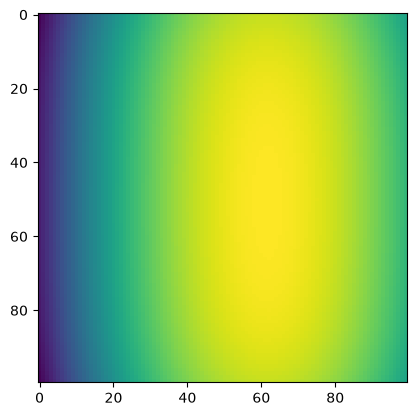

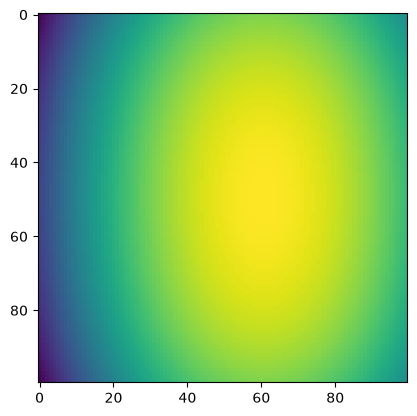

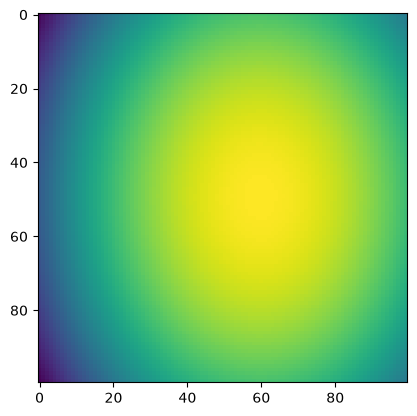

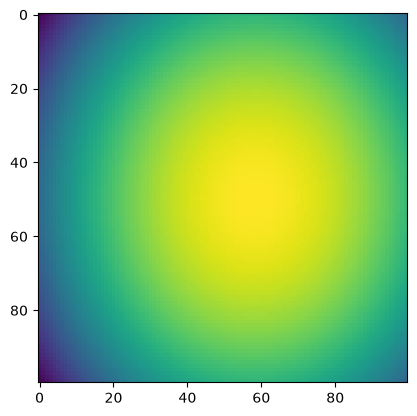

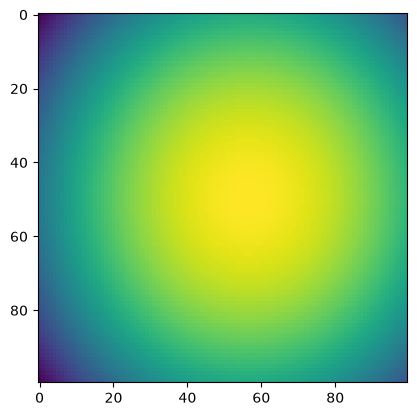

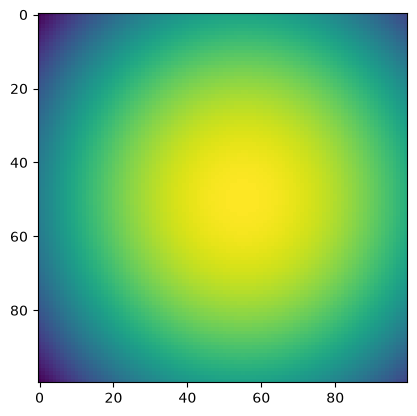

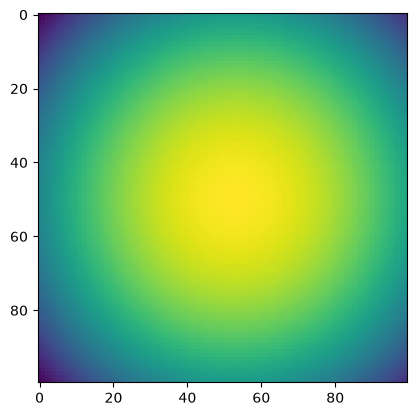

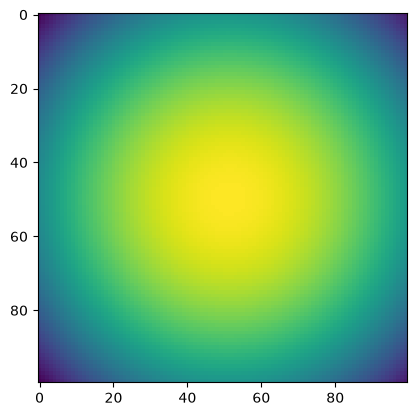

6100 0.18517186 time: 0.002574920654296875
6200 0.2088155 time: 0.0019237995147705078
6300 0.1908513 time: 0.00257110595703125
6400 0.21001792 time: 0.0019087791442871094
6500 0.19379607 time: 0.0034606456756591797
6600 0.18814377 time: 0.0019631385803222656
6700 0.18378028 time: 0.0019164085388183594
6800 0.1945755 time: 0.001911163330078125
6900 0.19196796 time: 0.0019237995147705078
7000 0.18065132 time: 0.0035719871520996094


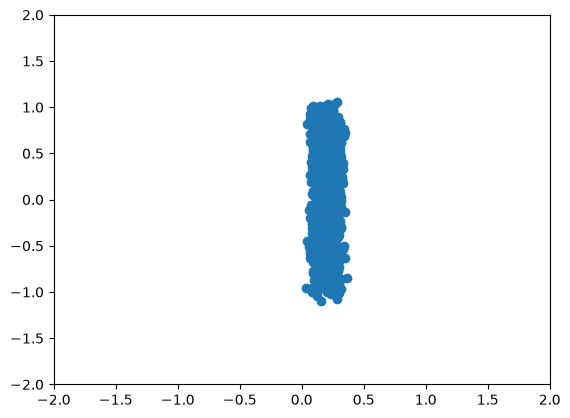

TEST 7000 logpx 0.5308879


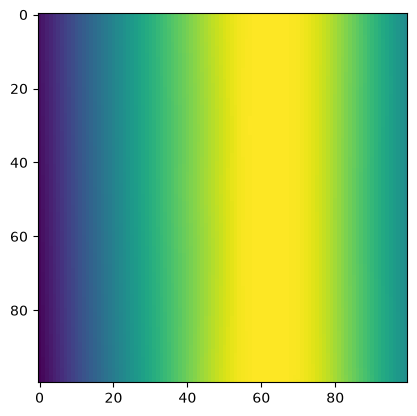

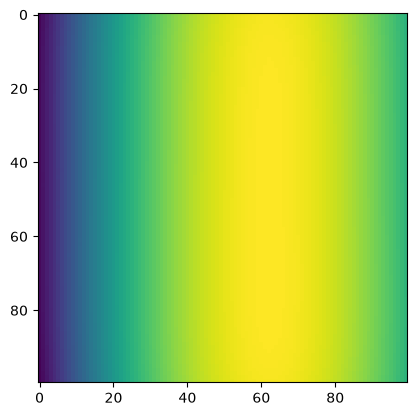

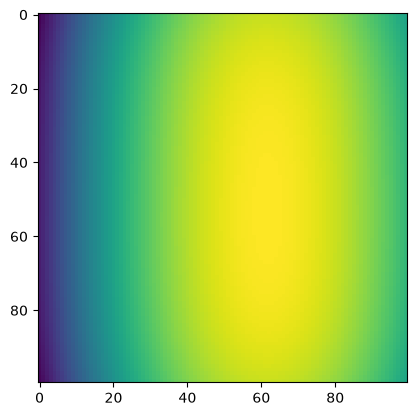

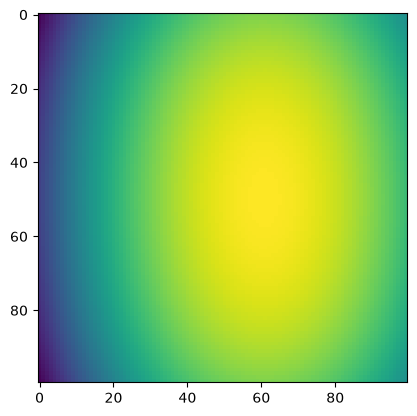

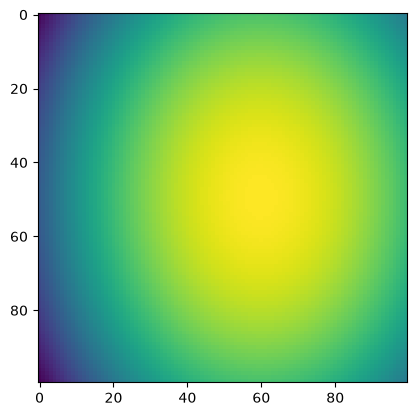

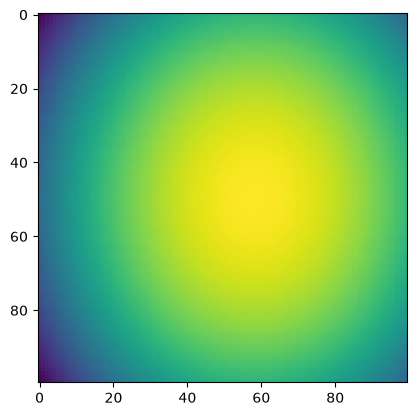

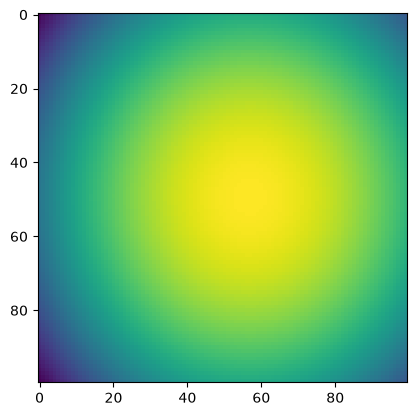

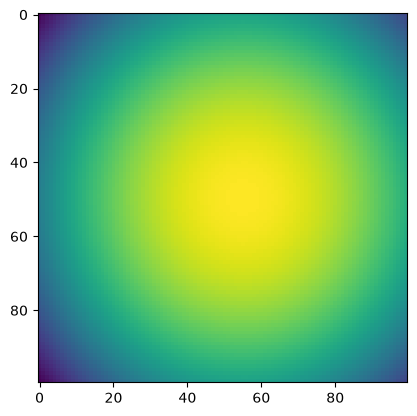

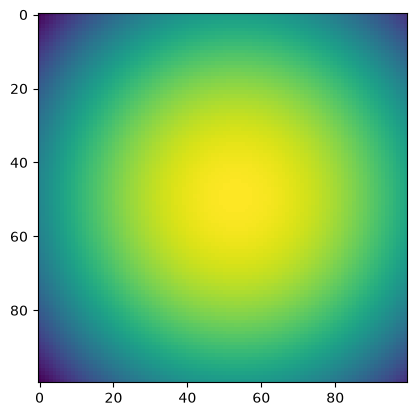

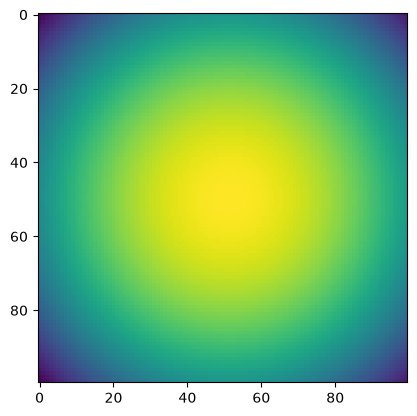

7100 0.18238206 time: 0.0018546581268310547
7200 0.18593366 time: 0.0019371509552001953
7300 0.19254294 time: 0.003499269485473633
7400 0.19149576 time: 0.003446817398071289
7500 0.18634611 time: 0.0021615028381347656
7600 0.17839663 time: 0.0036373138427734375
7700 0.19304048 time: 0.0018749237060546875
7800 0.17863685 time: 0.0030586719512939453
7900 0.18403071 time: 0.0033979415893554688
8000 0.19485432 time: 0.0019178390502929688


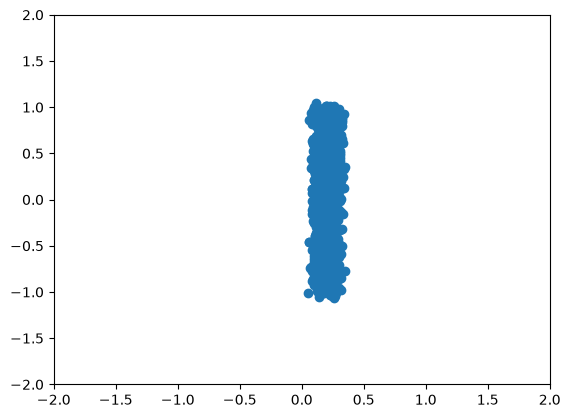

TEST 8000 logpx 0.63652


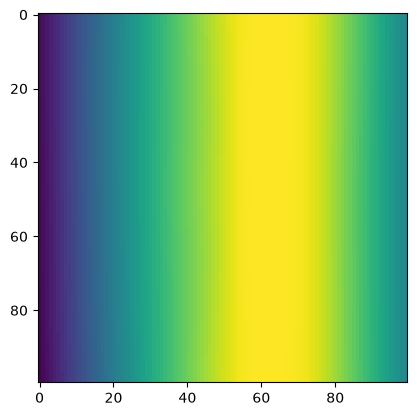

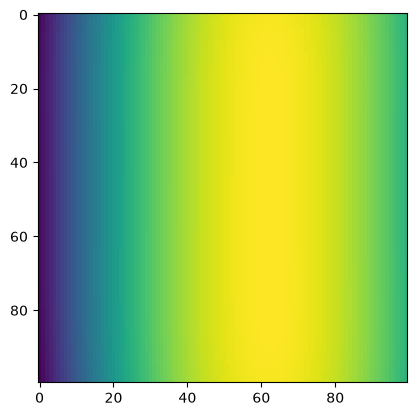

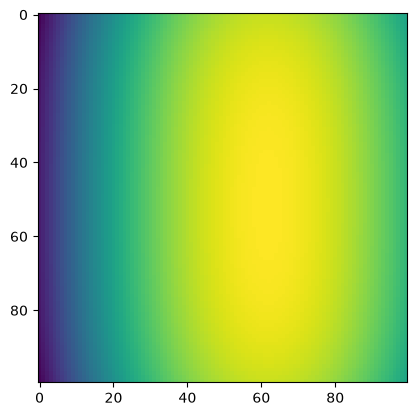

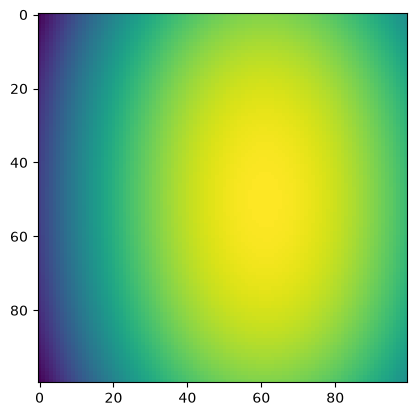

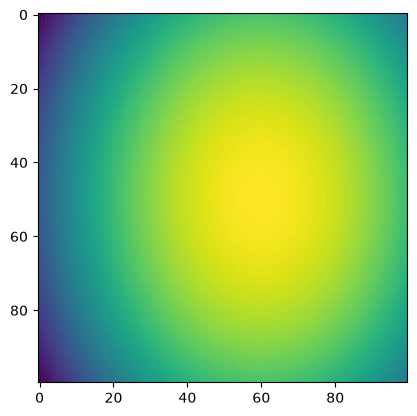

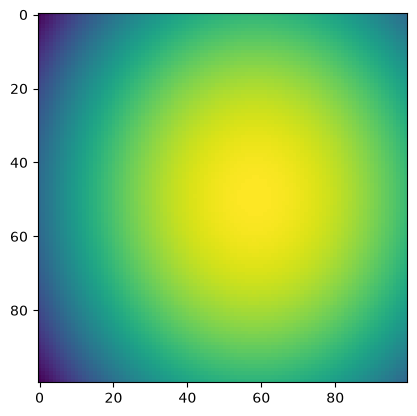

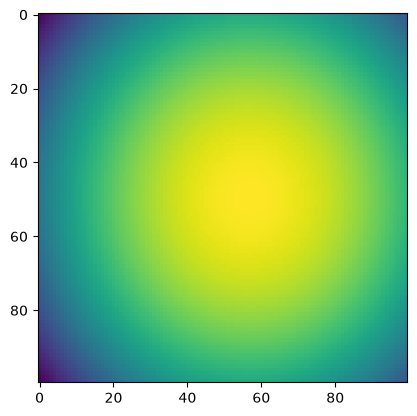

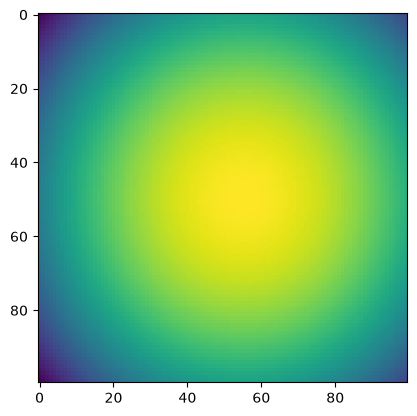

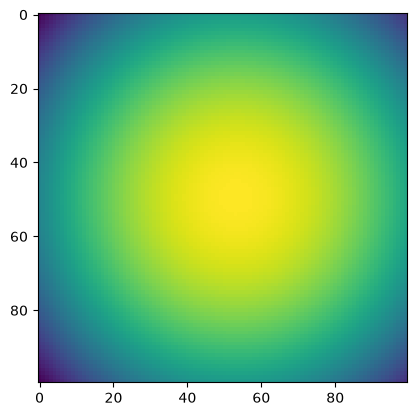

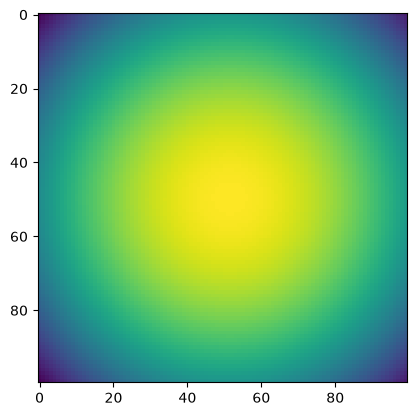

8100 0.18845347 time: 0.0033104419708251953
8200 0.18135832 time: 0.002209186553955078
8300 0.2055848 time: 0.005046367645263672
8400 0.21792383 time: 0.0024309158325195312
8500 0.18660499 time: 0.0018589496612548828
8600 0.18131568 time: 0.002013683319091797
8700 0.18847938 time: 0.0018944740295410156
8800 0.19883259 time: 0.0018606185913085938
8900 0.19281213 time: 0.0019373893737792969
9000 0.19375865 time: 0.0020046234130859375


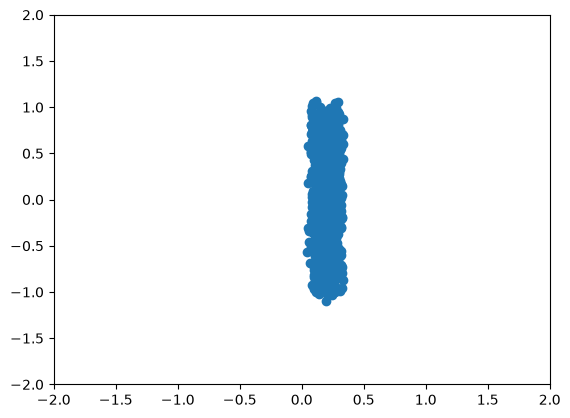

TEST 9000 logpx 0.63428277


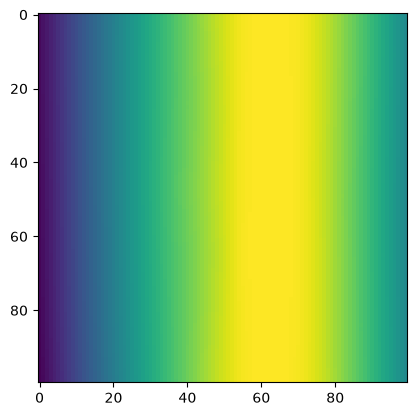

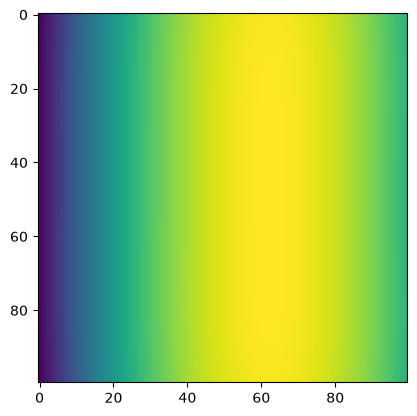

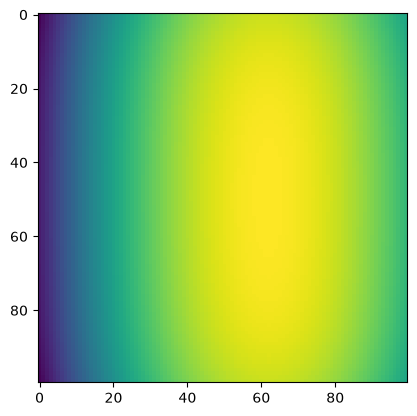

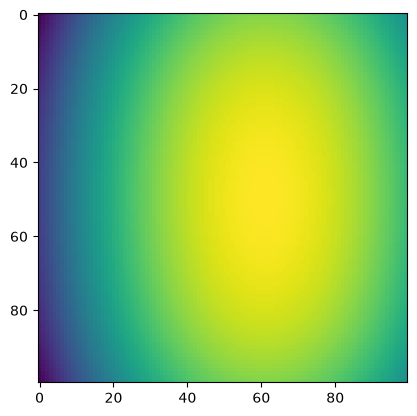

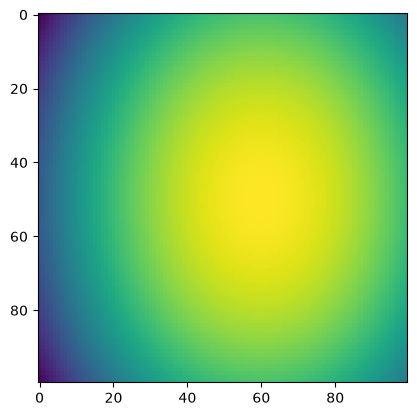

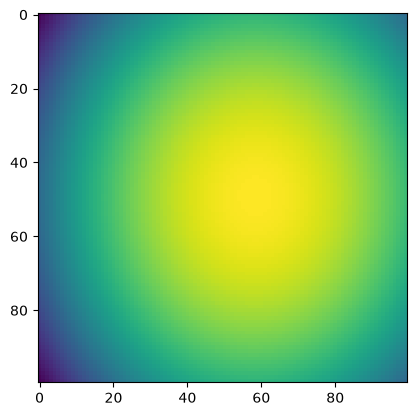

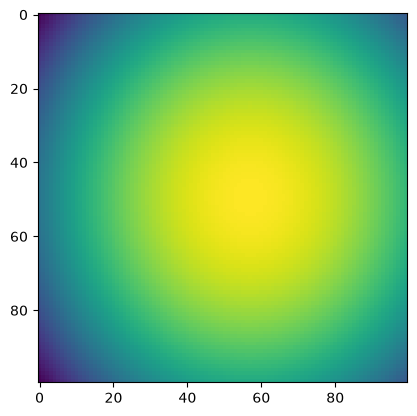

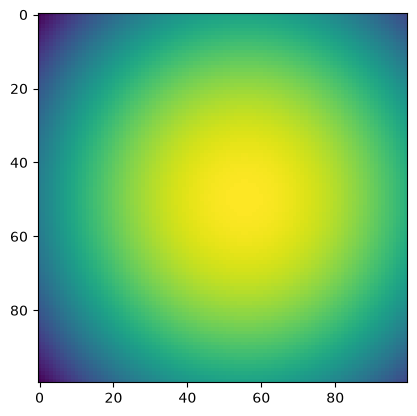

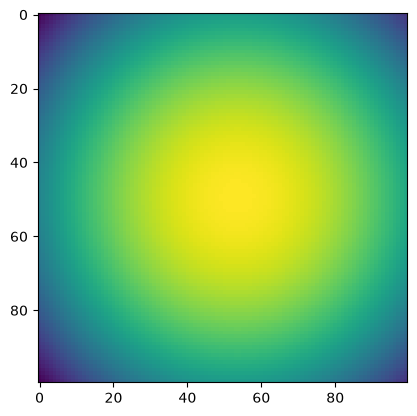

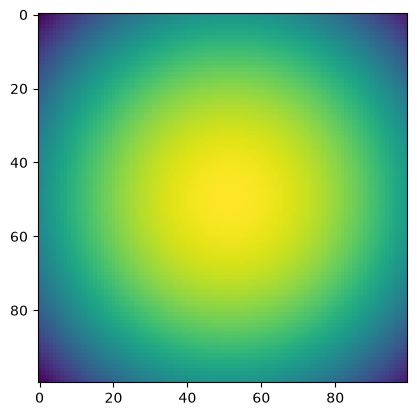

9100 0.19034703 time: 0.001989603042602539
9200 0.19339064 time: 0.0034744739532470703
9300 0.18180789 time: 0.0021538734436035156
9400 0.20001577 time: 0.003390789031982422
9500 0.18909232 time: 0.003438234329223633
9600 0.20890658 time: 0.0018579959869384766
9700 0.20016907 time: 0.0034427642822265625
9800 0.20106812 time: 0.0034308433532714844
9900 0.18340537 time: 0.0017986297607421875
10000 0.20731801 time: 0.001991748809814453


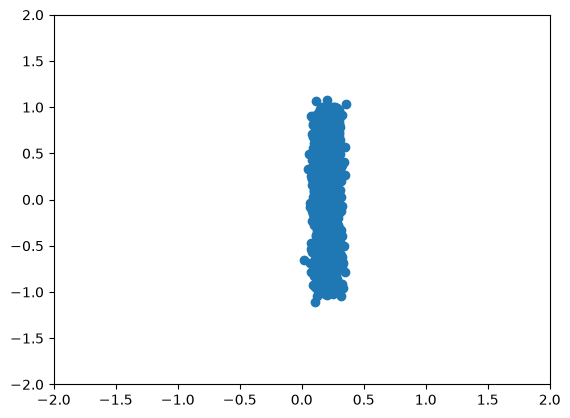

TEST 10000 logpx 0.67802733


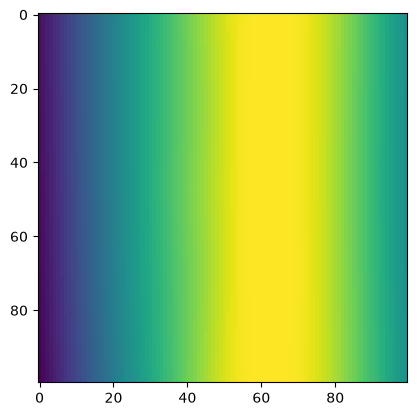

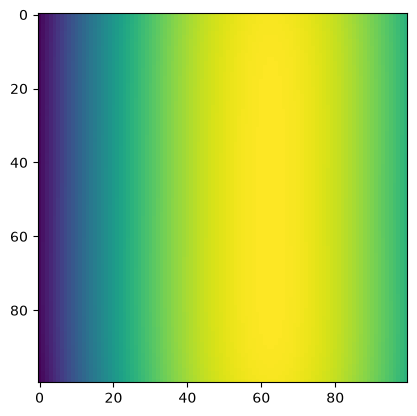

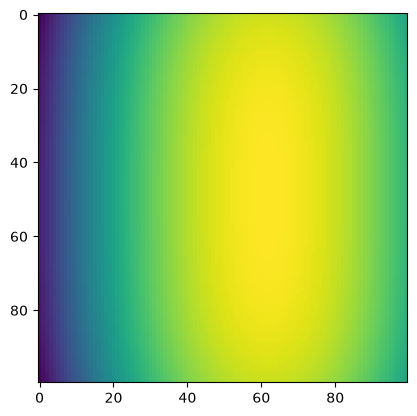

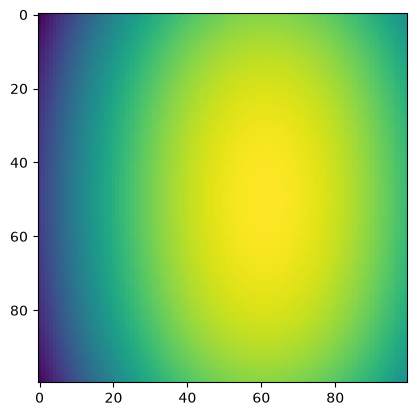

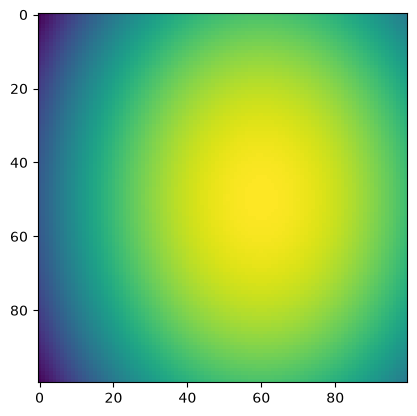

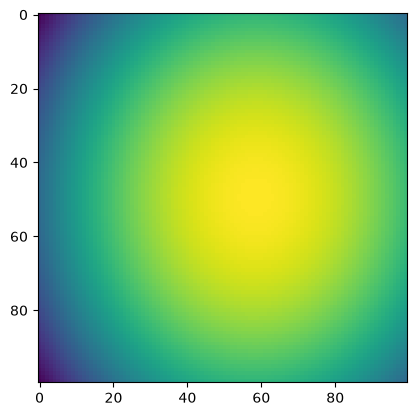

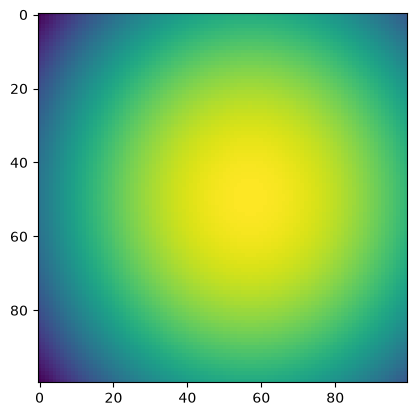

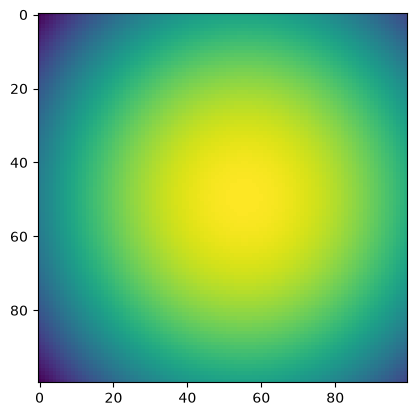

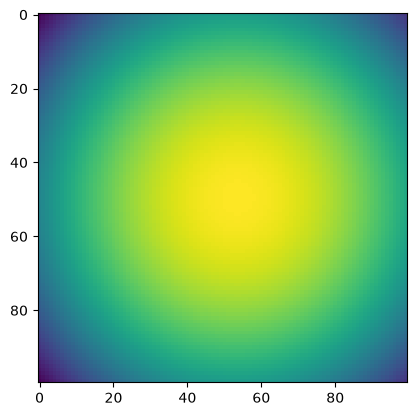

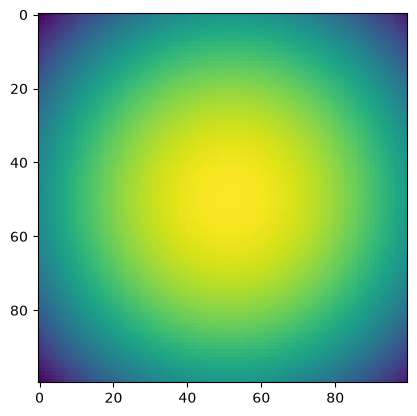

10100 0.1931984 time: 0.0033311843872070312
10200 0.19327603 time: 0.0035996437072753906
10300 0.17894122 time: 0.0023424625396728516
10400 0.195348 time: 0.001999378204345703
10500 0.18354116 time: 0.005126237869262695
10600 0.19944209 time: 0.0034360885620117188
10700 0.17801656 time: 0.003509044647216797
10800 0.18084155 time: 0.005017518997192383
10900 0.1941518 time: 0.001848459243774414
11000 0.19715112 time: 0.0019354820251464844


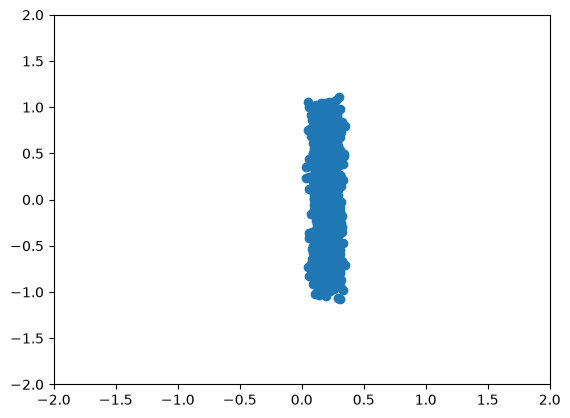

TEST 11000 logpx 0.6671375


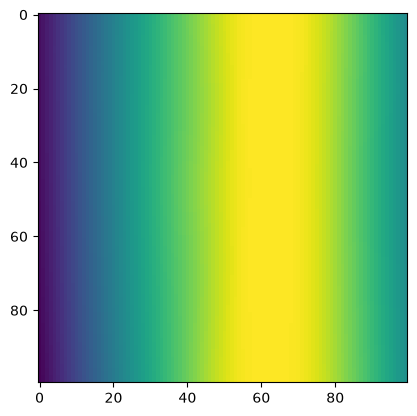

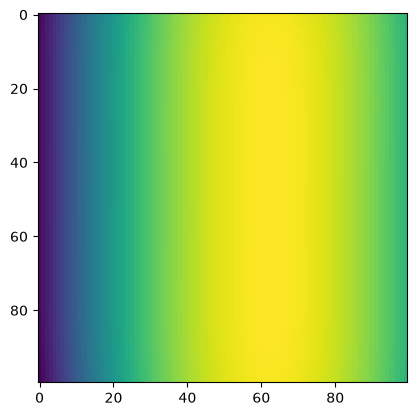

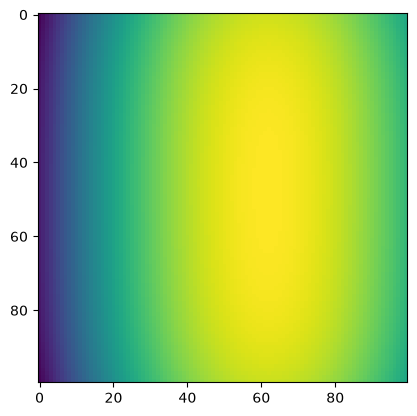

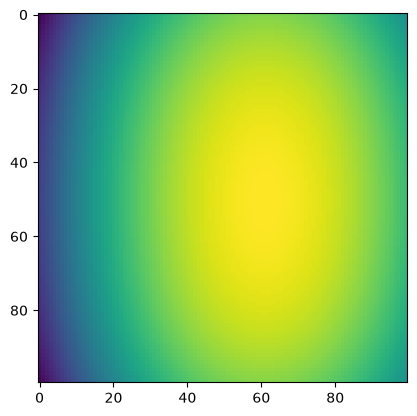

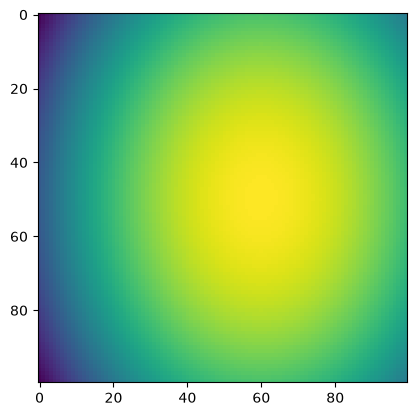

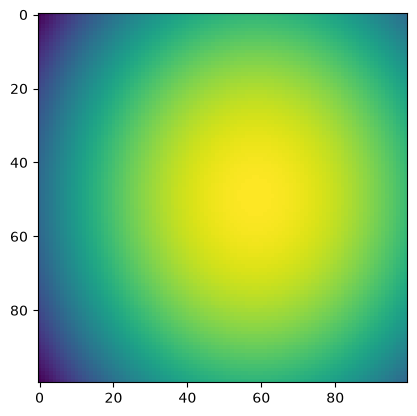

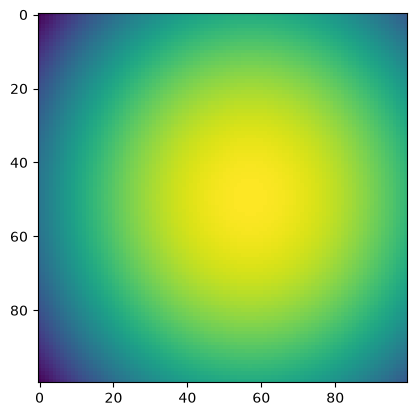

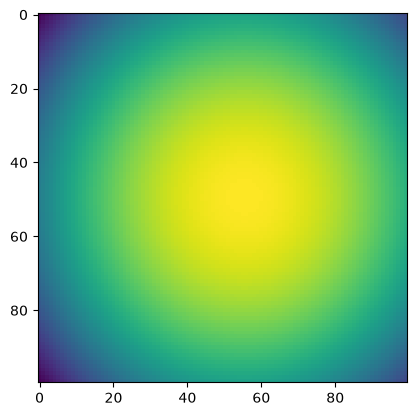

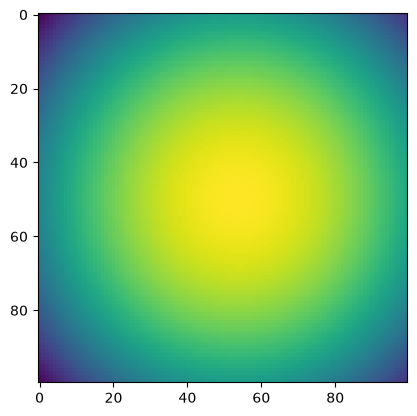

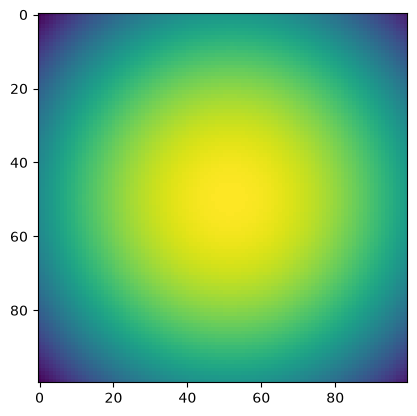

11100 0.19940221 time: 0.0031290054321289062
11200 0.17164122 time: 0.001743316650390625
11300 0.24263608 time: 0.001909494400024414
11400 0.19711556 time: 0.0018262863159179688
11500 0.20306435 time: 0.0018701553344726562
11600 0.19010584 time: 0.0023064613342285156
11700 0.20828526 time: 0.002197742462158203
11800 0.1974323 time: 0.002081632614135742
11900 0.21327181 time: 0.0018982887268066406
12000 0.1941219 time: 0.0018796920776367188


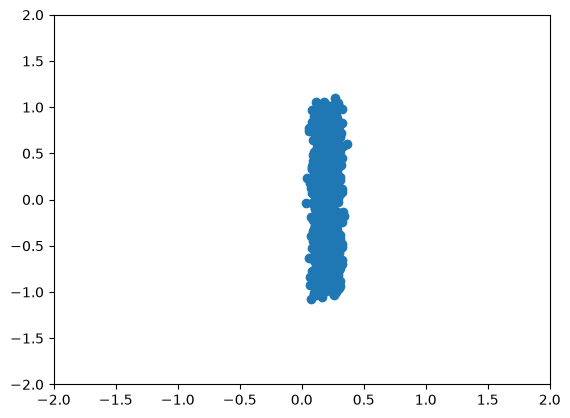

TEST 12000 logpx 0.70700896


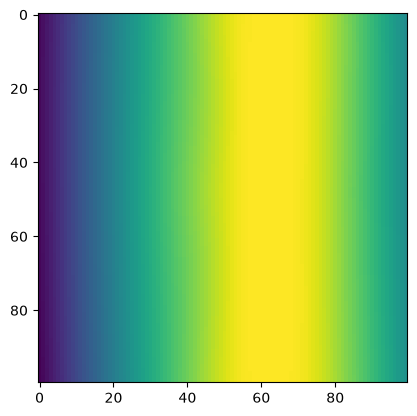

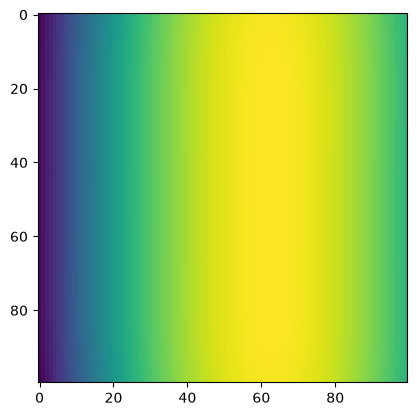

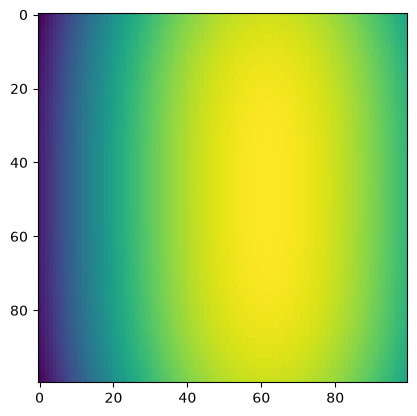

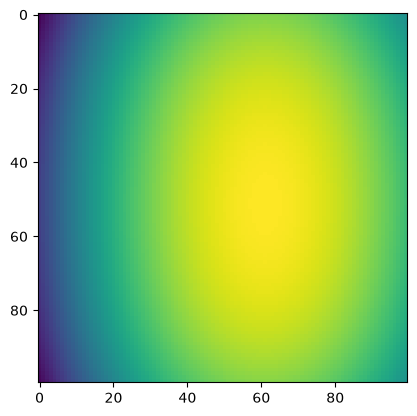

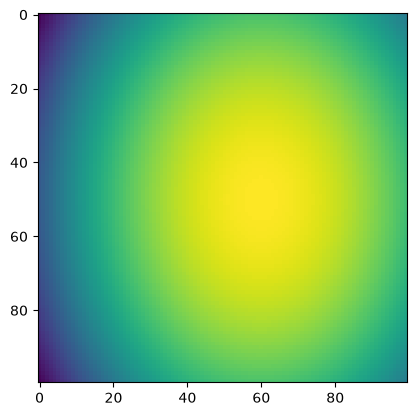

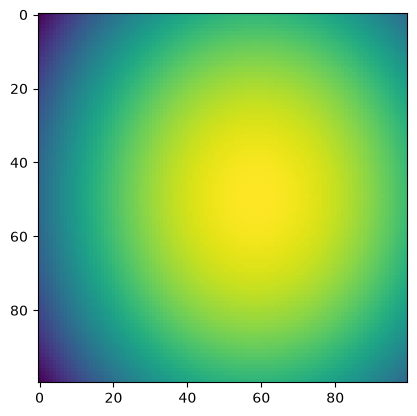

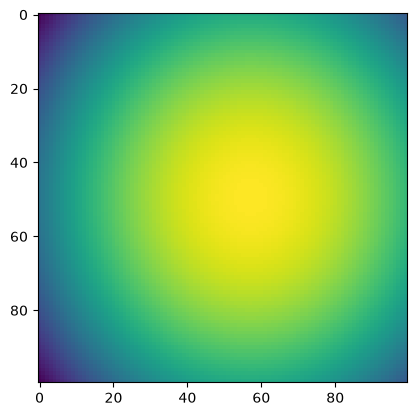

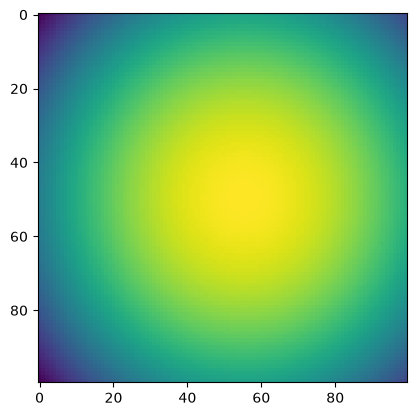

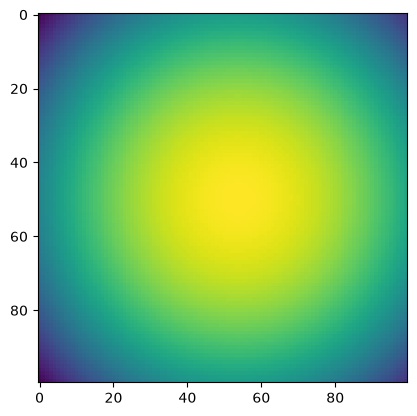

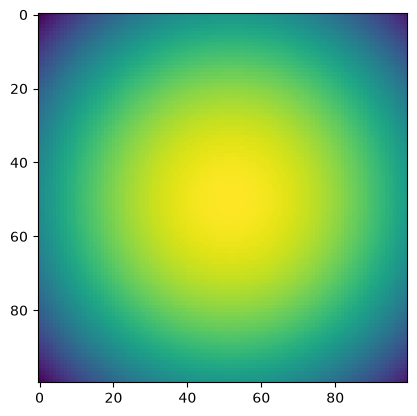

12100 0.1929643 time: 0.0018875598907470703
12200 0.19335975 time: 0.0017986297607421875
12300 0.21576503 time: 0.002387523651123047
12400 0.19010133 time: 0.0017497539520263672
12500 0.19618493 time: 0.001825571060180664
12600 0.18443199 time: 0.001977205276489258
12700 0.21397401 time: 0.0036461353302001953
12800 0.20788352 time: 0.0034236907958984375
12900 0.18870078 time: 0.0017986297607421875
13000 0.20127068 time: 0.001986265182495117


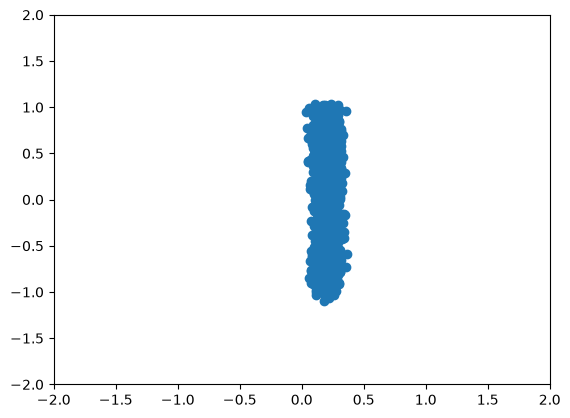

TEST 13000 logpx 0.83886147


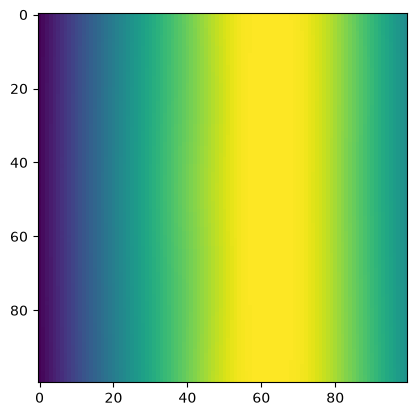

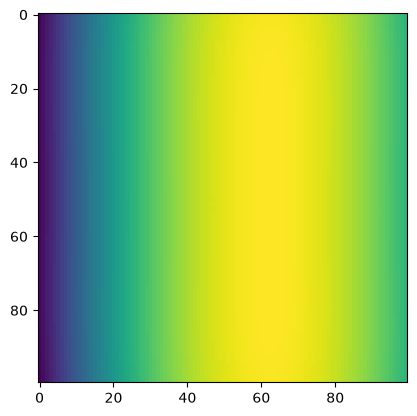

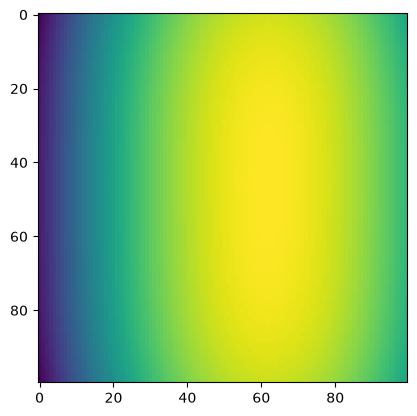

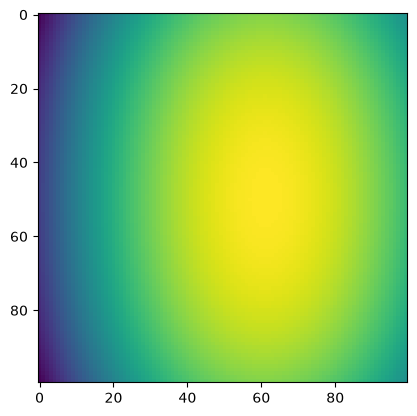

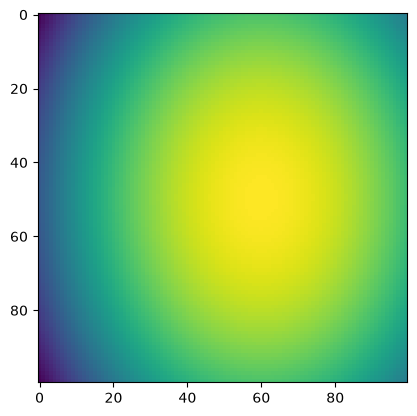

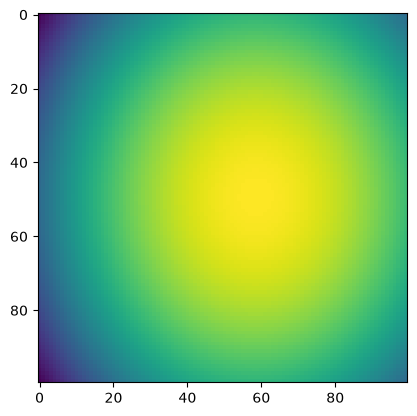

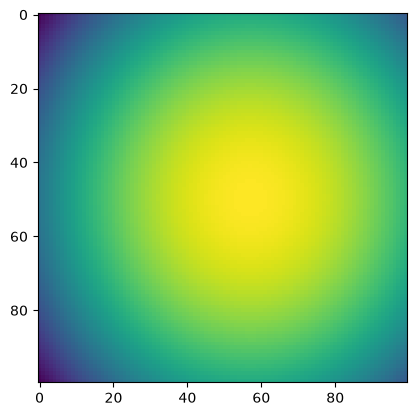

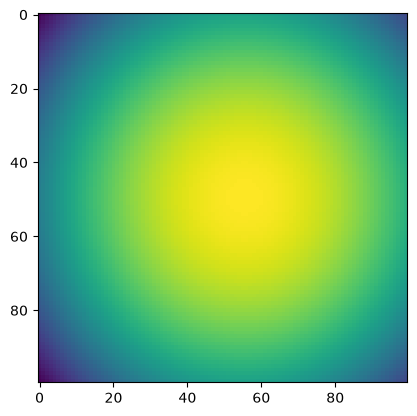

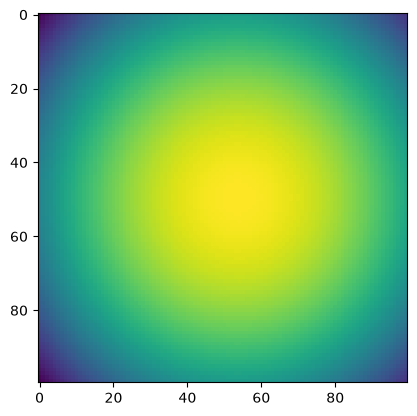

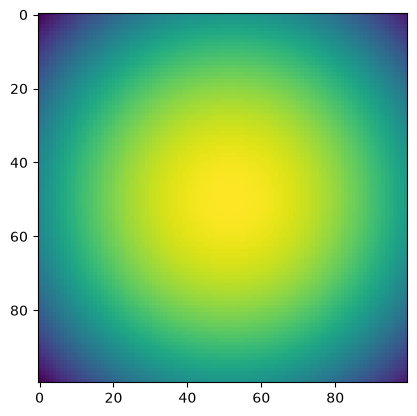

13100 0.16887867 time: 0.002249479293823242
13200 0.18136024 time: 0.005040168762207031
13300 0.19915123 time: 0.0019185543060302734
13400 0.2013202 time: 0.0019490718841552734
13500 0.18468134 time: 0.0019690990447998047
13600 0.1826816 time: 0.0021126270294189453
13700 0.19534709 time: 0.0019791126251220703
13800 0.20720072 time: 0.0019080638885498047
13900 0.19522554 time: 0.0020966529846191406
14000 0.19272034 time: 0.003590822219848633


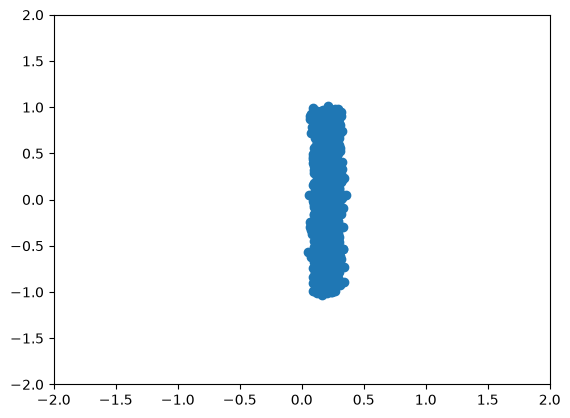

TEST 14000 logpx 0.8193719


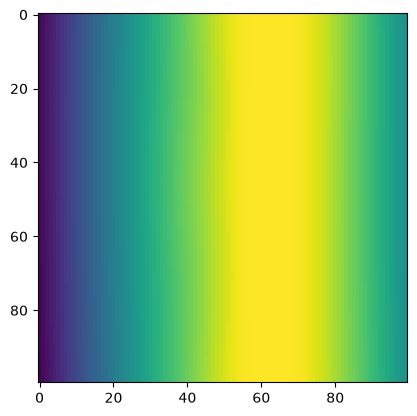

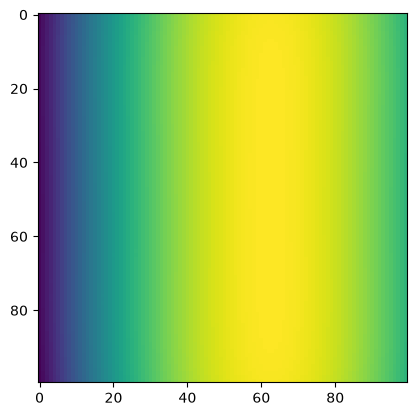

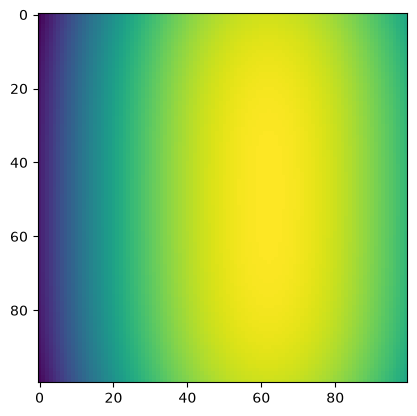

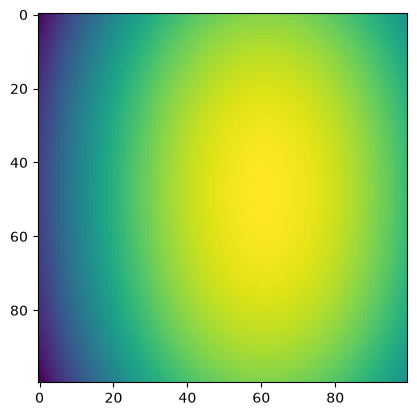

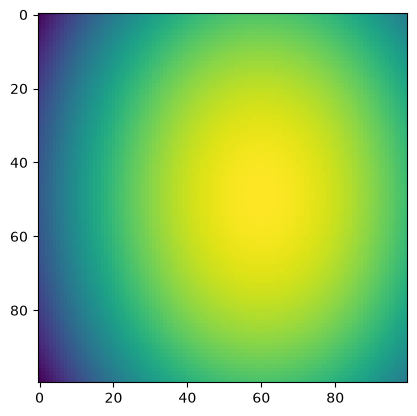

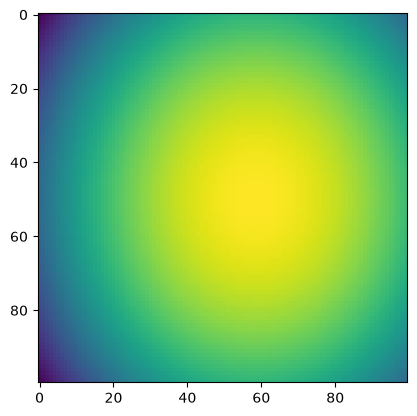

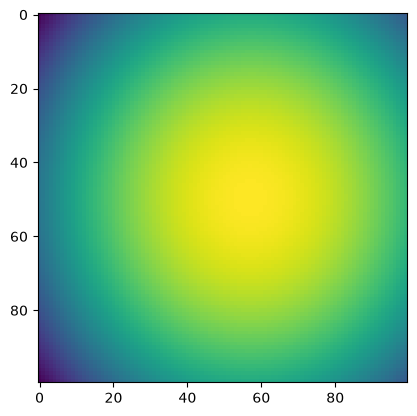

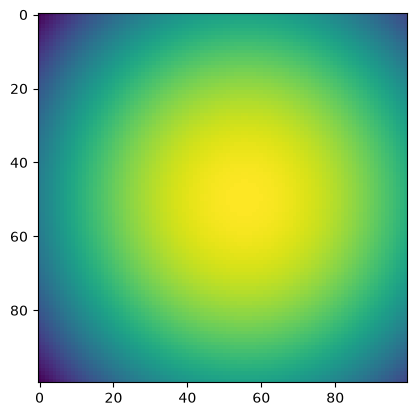

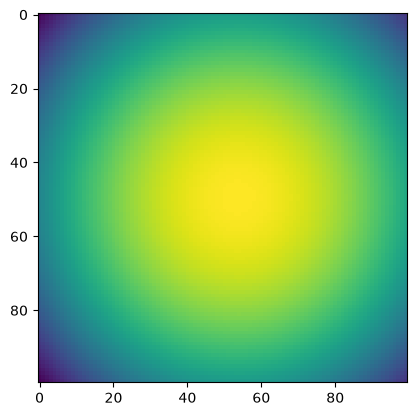

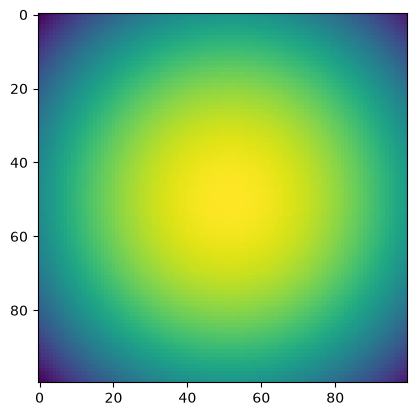

14100 0.17885329 time: 0.0020914077758789062
14200 0.19350569 time: 0.0020127296447753906
14300 0.17395444 time: 0.0021200180053710938
14400 0.19032459 time: 0.0019659996032714844
14500 0.21176651 time: 0.0025768280029296875
14600 0.20729207 time: 0.002088785171508789
14700 0.22527242 time: 0.0020096302032470703
14800 0.20298612 time: 0.0021791458129882812
14900 0.20212603 time: 0.002664804458618164
15000 0.19263884 time: 0.001859903335571289


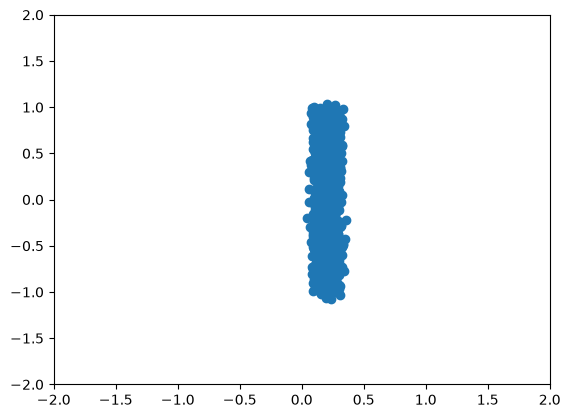

TEST 15000 logpx 0.7685012


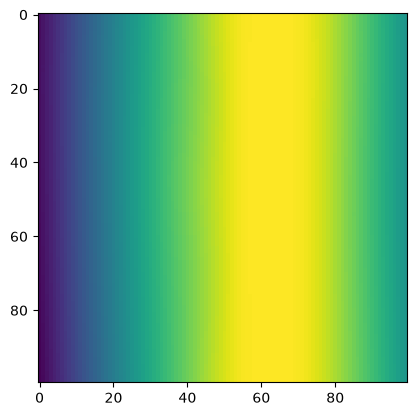

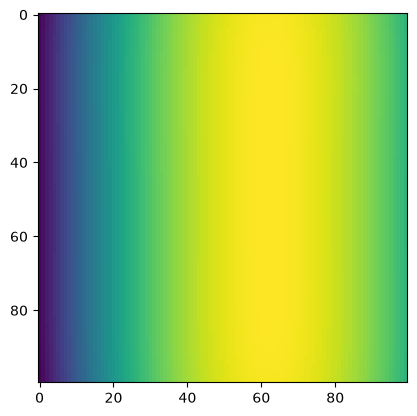

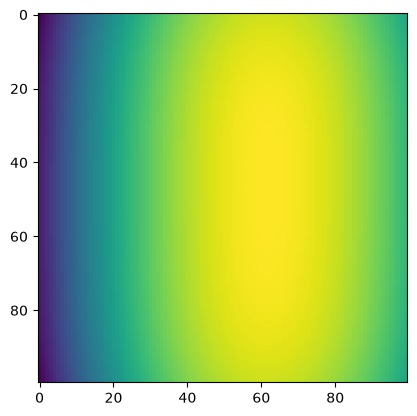

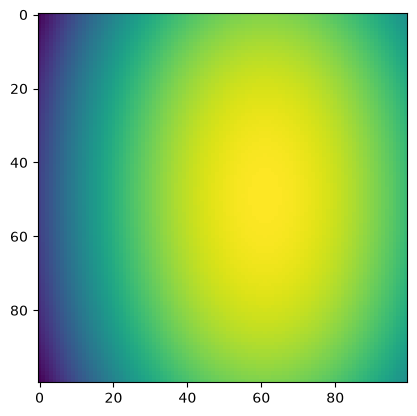

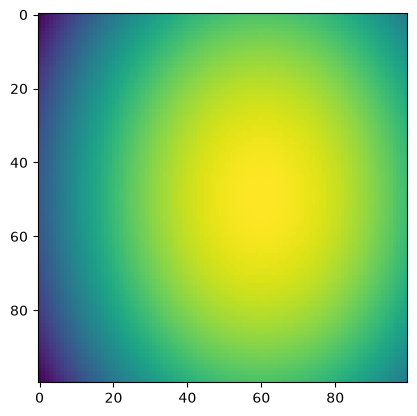

...

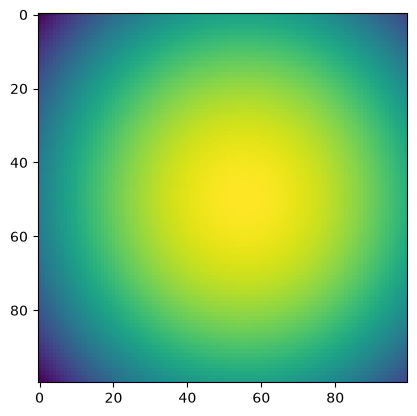

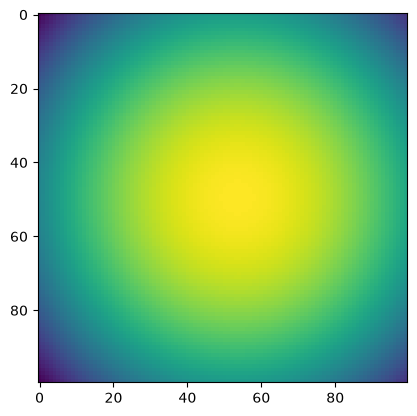

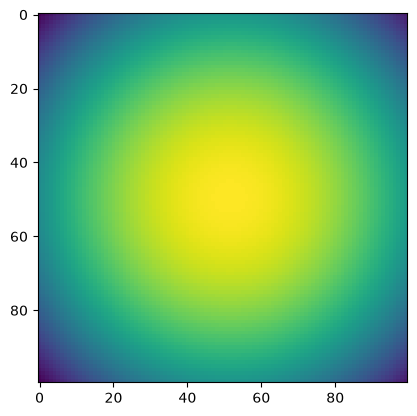

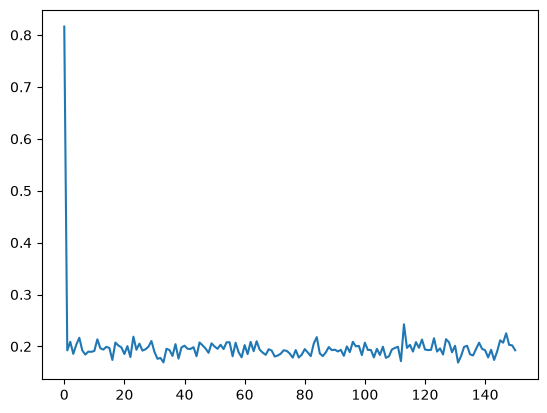

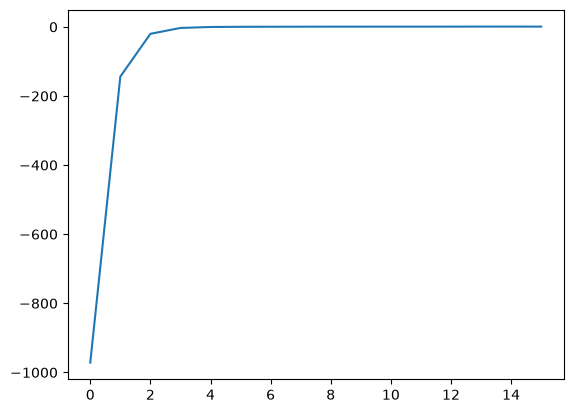

In [33]:
# Train Right Bar EBM Model
batch_size = 1000
data_dim = 2
num_steps = 15001

EMA = .999

n_steps = 100
net_params = {"n_layers": 4,
              "h_dim": 128,
              "emb_dim": 32}

def forward_fn():
  net = ResnetDiffusionModel(n_steps=n_steps, n_layers=4, x_dim=data_dim, h_dim=128, emb_dim=32)

  if ebm:
    net = EBMDiffusionModel(net)

  ddpm = PortableDiffusionModel(data_dim, n_steps, net, var_type="beta_forward")

  def logp_unnorm(x, t):
    scale_e = ddpm.energy_scale(-2 - t)
    t = jnp.ones((x.shape[0],), dtype=jnp.int32) * t
    return -net.neg_logp_unnorm(x, t) * scale_e

  def _logpx(x):
    return ddpm.logpx(x)["logpx"]
  return ddpm.loss, (ddpm.loss, ddpm.sample, _logpx, logp_unnorm)

forward = hk.multi_transform(forward_fn)
rng_seq = hk.PRNGSequence(0)

xr = [-.75, .75]
yr = [-.75, .75]


def plot_samples(x):
  plt.scatter(x[:, 0], x[:, 1])
  plt.xlim(-2, 2)
  plt.ylim(-2, 2)

def dist_show_2d(fn, xr, yr):
    nticks = 100
    x, y = np.meshgrid(np.linspace(xr[0], xr[1], nticks), np.linspace(yr[0], yr[1], nticks))
    coord = np.stack([x, y], axis=-1).reshape((-1, 2))
    heatmap = fn(coord).reshape((nticks, nticks))
    plt.imshow(heatmap)

# load data
dataset_energy, dataset_sample = right_bar()
x = dataset_sample(batch_size)

plot_samples(x)
plt.show()
x = x.reshape(x.shape[0], -1)


params = forward.init(next(rng_seq), x)
loss_fn, sample_fn, logpx_fn, logp_unnorm_fn = forward.apply
param_count = sum(x.size for x in jax.tree_leaves(params))
for k, v in jax.tree_map(lambda x: x.shape, params).items():
  print(k, v)
print("Model has {} params".format(param_count))


opt = optax.adam(1e-3)
opt_state = opt.init(params)

sample_fn = jax.jit(sample_fn, static_argnums=2)
logpx_fn = jax.jit(logpx_fn)

logp_unnorm_fn = jax.jit(logp_unnorm_fn)

@jax.jit
def mean_loss_fn(params, rng, x):
  loss = loss_fn(params, rng, x)
  return loss.mean()

@jax.jit
def update(params, opt_state, rng, x):
  loss, grad = jax.value_and_grad(mean_loss_fn)(params, rng, x)

  updates, opt_state = opt.update(grad, opt_state)
  new_params = optax.apply_updates(params, updates)
  return loss, new_params, opt_state

# Speed-only change (no maths changed): the moving average runs inside one compiled call
# instead of one small GPU operation per weight array, about 10x faster per step.
@jax.jit
def update_ema(params, ema_params, opt_state, rng, x):
  loss, params, opt_state = update(params, opt_state, rng, x)
  ema_params = jax.tree_util.tree_map(lambda e, p: e * EMA + p * (1 - EMA), ema_params, params)
  return loss, params, ema_params, opt_state

ema_params = params
losses = []
test_logpx = []
itr = 0

for itr in range(num_steps):
  x = dataset_sample(batch_size)

  x = x.reshape(x.shape[0], -1)
  start_time = time.time()
  loss, params, ema_params, opt_state = update_ema(params, ema_params, opt_state, next(rng_seq), x)
  duration_update = time.time() - start_time

  if itr % 100 == 0:
    print(itr, loss, "time:", duration_update)
    losses.append(loss)
  if itr % 1000 == 0:
    x_samp = sample_fn(ema_params, next(rng_seq), batch_size)
    plot_samples(x_samp)
    plt.show()
    logpx = logpx_fn(ema_params, next(rng_seq), x).mean()
    print("TEST", itr, 'logpx', logpx)
    test_logpx.append(logpx)

    if ebm:
      for t in range(10):
        dist_show_2d(lambda x: logp_unnorm_fn(ema_params, next(rng_seq), x, 10*t), xr=xr, yr=yr)
        plt.show()

plt.plot(losses)
plt.show()
plt.plot(test_logpx)

flow_params = params
flow_rng = next(rng_seq)

right_bar_params = ema_params

In [34]:
params = {}

for k, v in left_bar_params.items():
  params[k] = v

for k, v in right_bar_params.items():
  k = k.replace('resnet_diffusion_model/', 'resnet_diffusion_model_1/')
  params[k] = v

/tmp/ipykernel_1391087/1385371818.py:265: UserWarning: Explicitly requested dtype int64 requested in ones is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  t = jnp.ones((n,), dtype=jnp.int64) * j


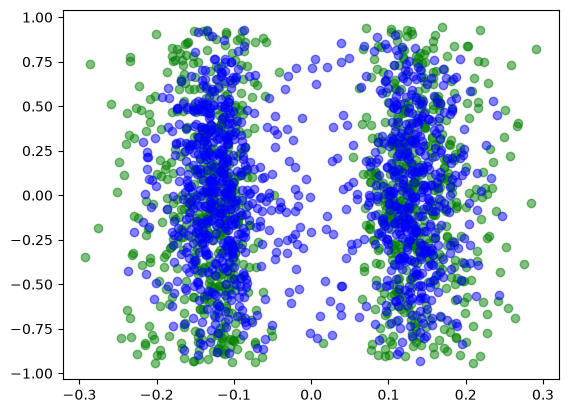

In [35]:
# Sampling from disjunction of distributions
import matplotlib.pyplot as plt

dim = 2
n_mode = 4
std = .05
init_std = 1.
init_mu = 0.
n_steps = 10
damping = .5
mass_diag_sqrt = 1.
num_leapfrog = 3
samples_per_step = 10
uha_step_size = .03
ula_step_size = .001

batch_size = 1000

rng_seq = hk.PRNGSequence(0)

means = jax.random.normal(next(rng_seq), (n_mode, dim))
comp_dists = distrax.MultivariateNormalDiag(means, jnp.ones_like(means) * std)
pi = distrax.Categorical(logits=jnp.zeros((n_mode,)))
target_dist = distrax.MixtureSameFamily(pi, comp_dists)
initial_dist = distrax.MultivariateNormalDiag(means[0] * 0 + init_mu, init_std * jnp.ones_like(means[0]))


x_init = initial_dist.sample(seed=next(rng_seq), sample_shape=(batch_size,))
logZs = []
n_stepss = [100]

def gradient_function(x, t):
  t = n_steps - jnp.ones((x.shape[0],), dtype=jnp.int32) * t - 1
  return -1 *dual_mixture_gradient_fn(params, next(rng_seq), x, t)

if ebm:
  def energy_function(x, t):
    t = n_steps - jnp.ones((x.shape[0],), dtype=jnp.int32) * t - 1
    return -1 *dual_mixture_energy_fn(params, next(rng_seq), x, t)

for n_steps in n_stepss:
  ula_step_sizes = jnp.ones((n_steps,)) * ula_step_size
  uha_step_sizes = jnp.ones((n_steps,)) * uha_step_size

  betas = jnp.linspace(0., 1., n_steps)

  def target_function(x, i):
    beta = betas[i]
    init_lp = initial_dist.log_prob(x)
    targ_lp = target_dist.log_prob(x)
    return beta * targ_lp + (1 - beta) * init_lp

  # Choose the sampler to use
  # sampler = AnnealedULASampler(n_steps, samples_per_step, ula_step_sizes, initial_dist, target_distribution=None, gradient_function=gradient_function)
  # sampler = AnnealedMALASampler(n_steps, samples_per_step, ula_step_sizes, initial_dist, target_distribution=None, gradient_function=gradient_function, energy_function=energy_function)
  # sampler = AnnealedUHASampler(n_steps, samples_per_step, uha_step_sizes, damping, mass_diag_sqrt, num_leapfrog, initial_dist, target_distribution=None, gradient_function=gradient_function)
  sampler = AnnealedMUHASampler(n_steps, samples_per_step, uha_step_sizes, damping, mass_diag_sqrt, num_leapfrog, initial_dist, target_distribution=None, gradient_function=gradient_function, energy_function=energy_function)

  x_samp, logw, accept = sampler.sample(next(rng_seq), batch_size)
  rng_seq = hk.PRNGSequence(1)
  grad_sample = dual_mixture_sample_fn(params, next(rng_seq), batch_size, jnp.inf)

  # Samples from MCMC
  plt.scatter(x_samp[:, 0], x_samp[:, 1], color='green', alpha=.5)

  # Samples generated from adding score function
  plt.scatter(grad_sample[:, 0], grad_sample[:, 1], color='blue', alpha=.5)


  plt.show()

Excute Negation Composition

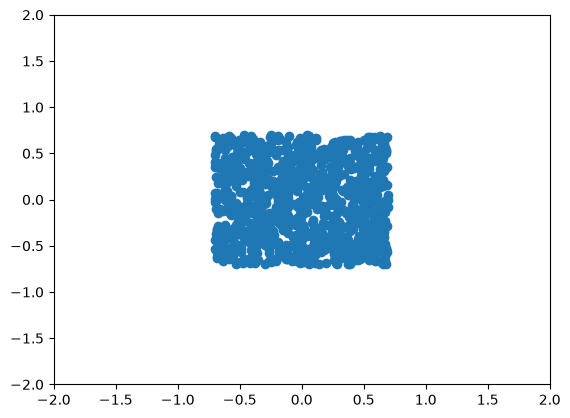

portable_diffusion_model {'out_logvar': (100,)}
resnet_diffusion_model/embed {'embeddings': (100, 32)}
resnet_diffusion_model/layer_norm {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/layer_norm_1 {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/layer_norm_2 {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/layer_norm_3 {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/linear {'b': (128,), 'w': (2, 128)}
resnet_diffusion_model/linear_1 {'b': (256,), 'w': (128, 256)}
resnet_diffusion_model/linear_10 {'b': (256,), 'w': (32, 256)}
resnet_diffusion_model/linear_11 {'b': (256,), 'w': (256, 256)}
resnet_diffusion_model/linear_12 {'b': (128,), 'w': (256, 128)}
resnet_diffusion_model/linear_13 {'b': (256,), 'w': (128, 256)}
resnet_diffusion_model/linear_14 {'b': (256,), 'w': (32, 256)}
resnet_diffusion_model/linear_15 {'b': (256,), 'w': (256, 256)}
resnet_diffusion_model/linear_16 {'b': (128,), 'w': (256, 128)}
resnet_diffusion_model/linear_17 {'b': (2,)

/tmp/ipykernel_1391087/1385371818.py:265: UserWarning: Explicitly requested dtype int64 requested in ones is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  t = jnp.ones((n,), dtype=jnp.int64) * j


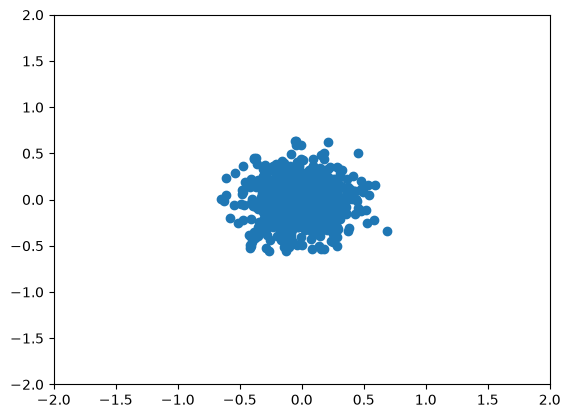

/tmp/ipykernel_1391087/1385371818.py:235: UserWarning: Explicitly requested dtype int64 requested in ones is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  t = jnp.ones((x_0.shape[0],), dtype=jnp.int64) * (self._n_steps - 1)


TEST 0 logpx -970.8571


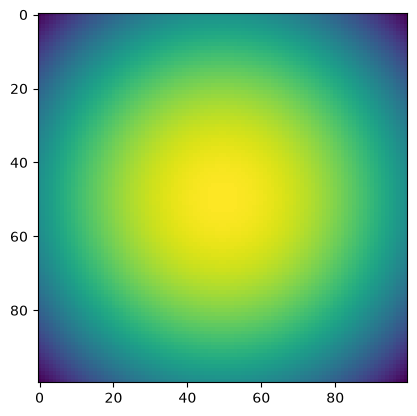

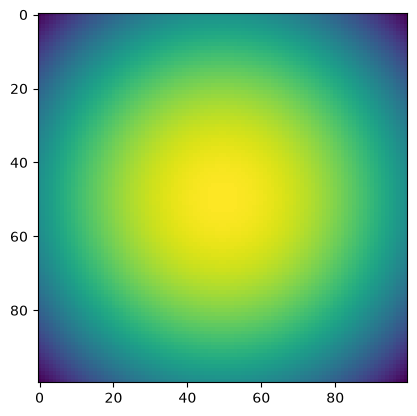

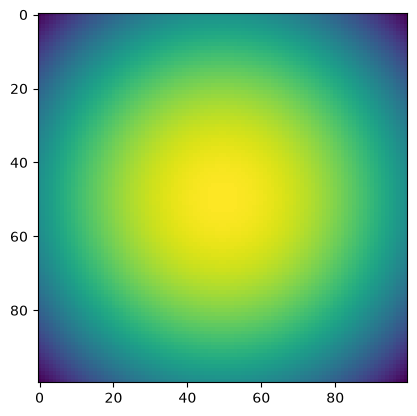

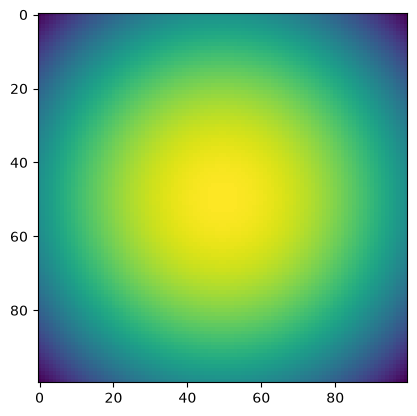

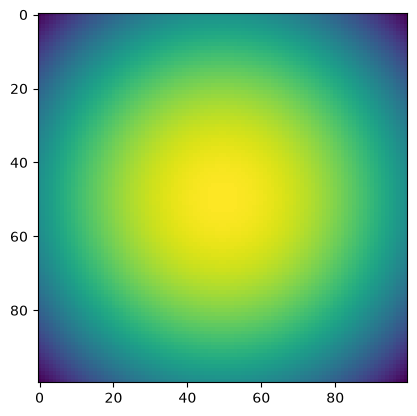

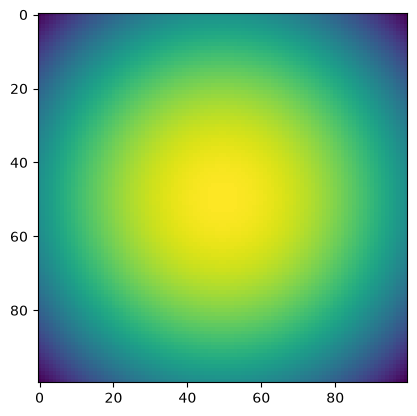

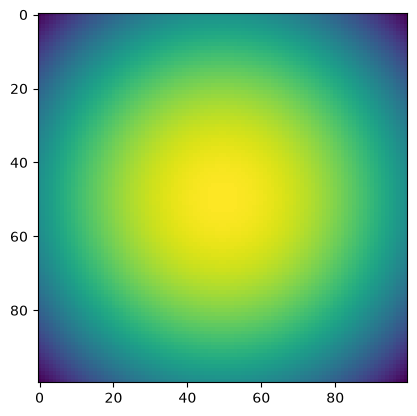

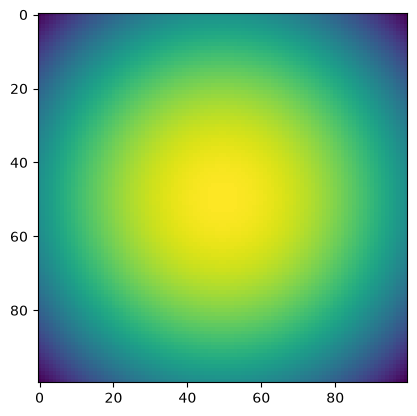

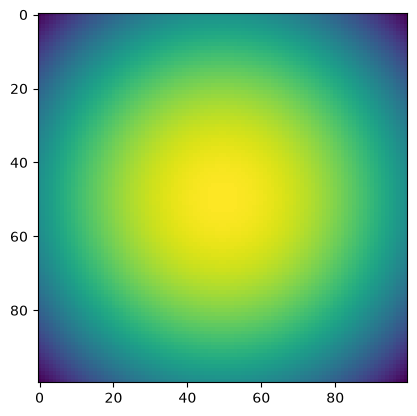

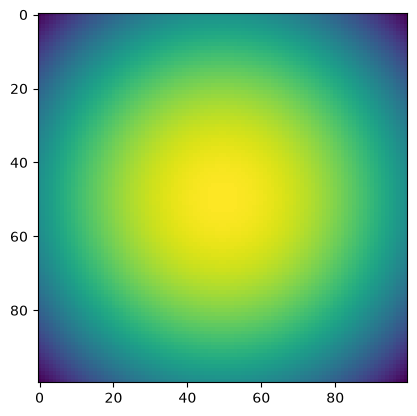

100 0.27758875 time: 0.0021376609802246094
200 0.2570102 time: 0.0020482540130615234
300 0.27927548 time: 0.0021741390228271484
400 0.2980781 time: 0.0019850730895996094
500 0.28896597 time: 0.0018401145935058594
600 0.2675763 time: 0.0019104480743408203
700 0.2743631 time: 0.0017788410186767578
800 0.258851 time: 0.0017745494842529297
900 0.27916846 time: 0.0018146038055419922
1000 0.2430601 time: 0.0022695064544677734


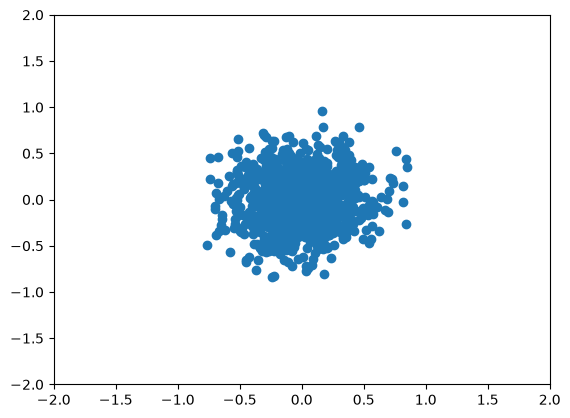

TEST 1000 logpx -133.56926


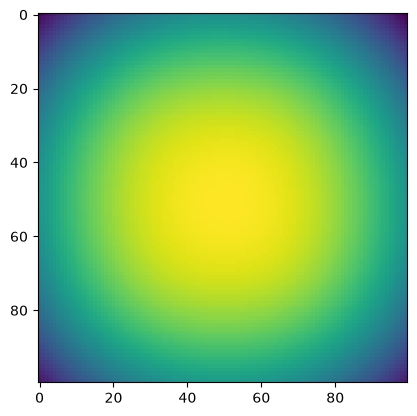

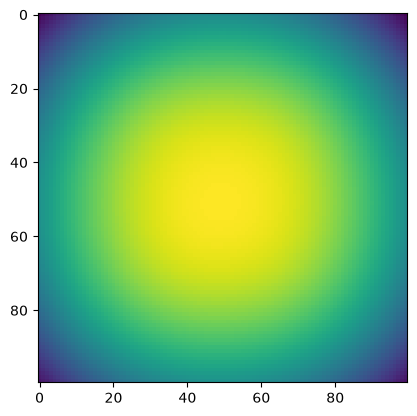

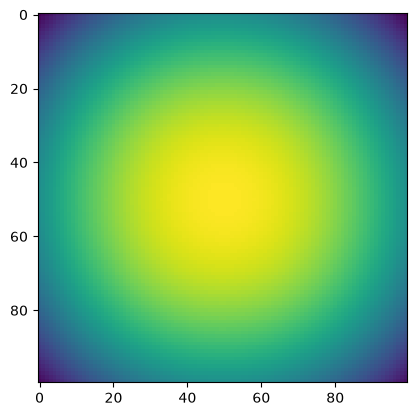

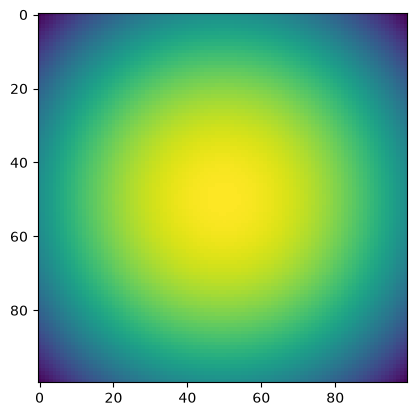

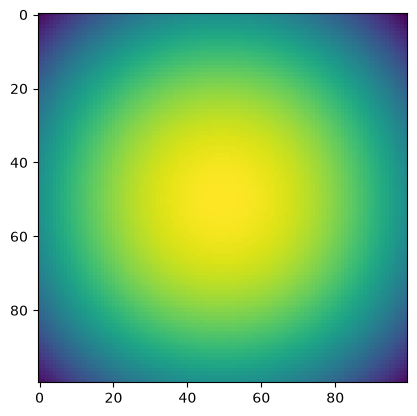

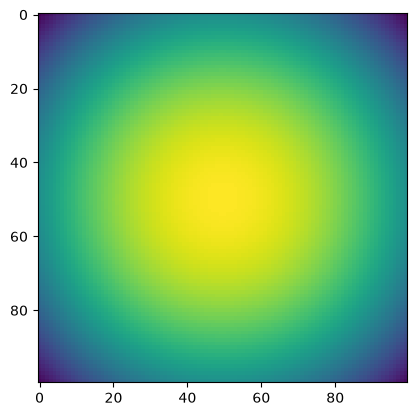

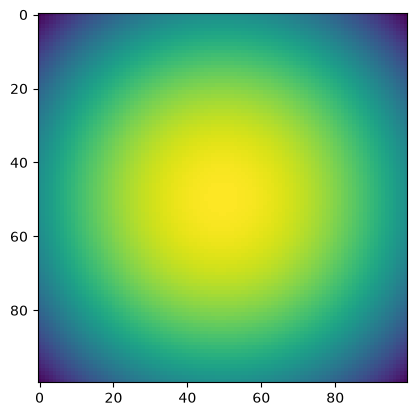

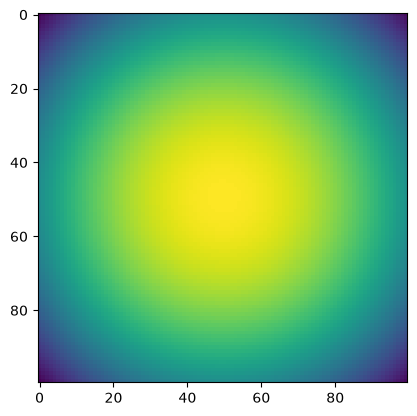

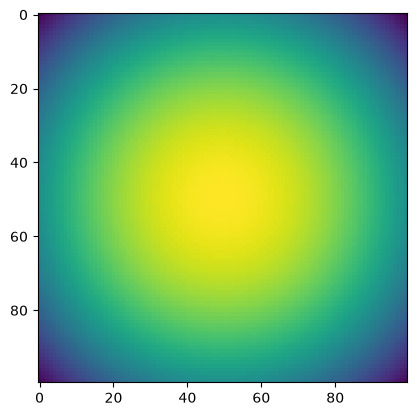

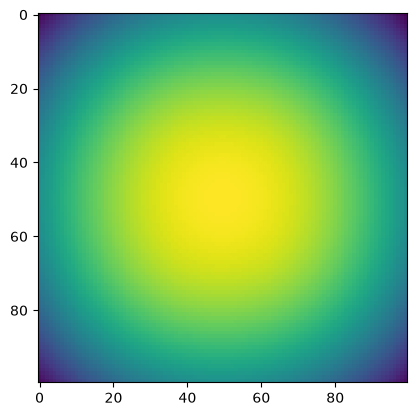

1100 0.2962817 time: 0.0017998218536376953
1200 0.294417 time: 0.0033872127532958984
1300 0.24022032 time: 0.0019664764404296875
1400 0.24841034 time: 0.0021195411682128906
1500 0.27303687 time: 0.0019567012786865234
1600 0.23579867 time: 0.0034334659576416016
1700 0.26064795 time: 0.0030159950256347656
1800 0.277466 time: 0.0024051666259765625
1900 0.28292933 time: 0.0019757747650146484
2000 0.25766322 time: 0.003515481948852539


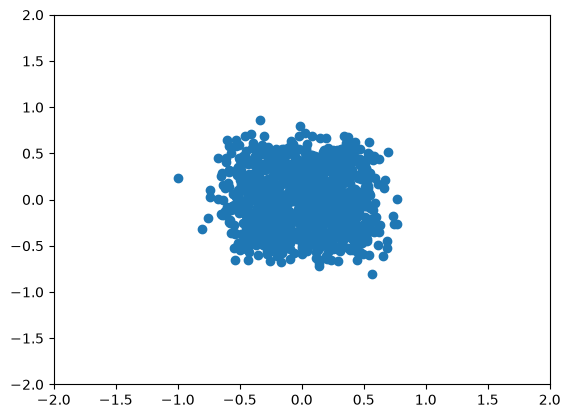

TEST 2000 logpx -18.79604


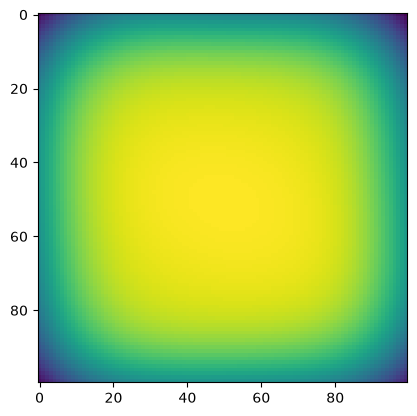

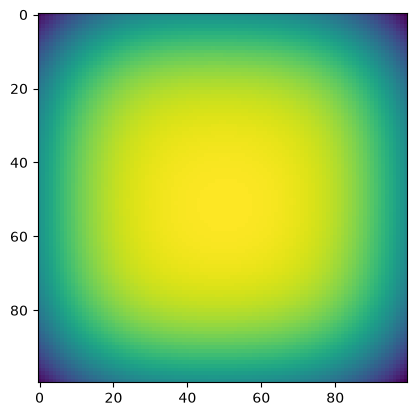

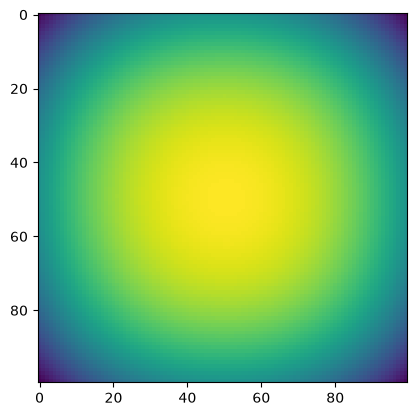

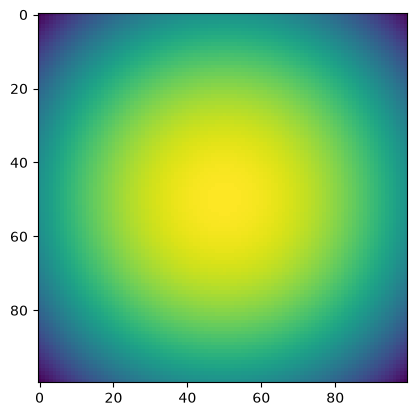

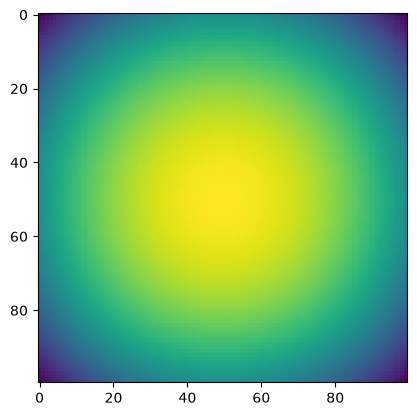

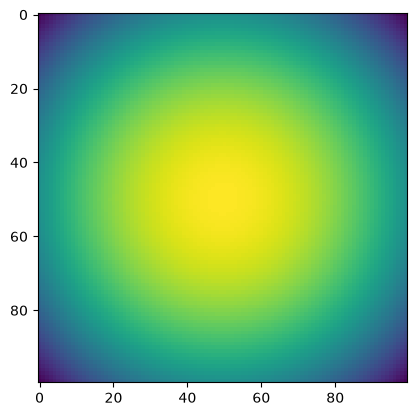

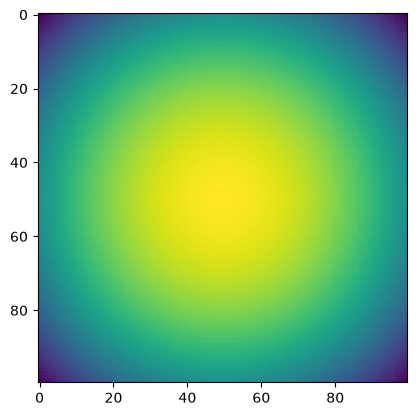

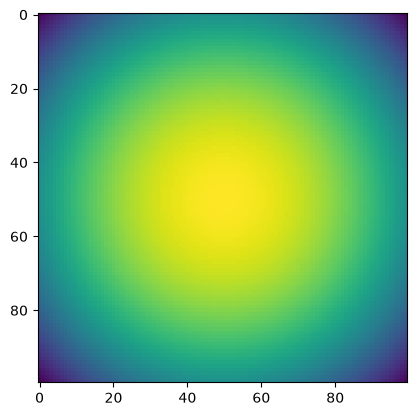

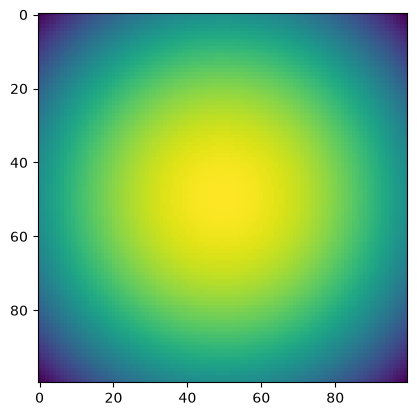

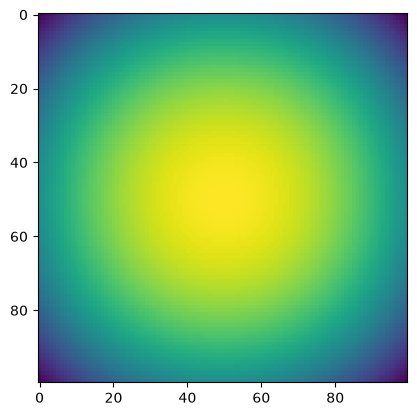

2100 0.28859726 time: 0.00191497802734375
2200 0.267031 time: 0.0021085739135742188
2300 0.28741613 time: 0.0023233890533447266
2400 0.24032058 time: 0.0019638538360595703
2500 0.2736932 time: 0.0018317699432373047
2600 0.24931501 time: 0.002142667770385742
2700 0.28259823 time: 0.0022072792053222656
2800 0.27318883 time: 0.0019788742065429688
2900 0.27639154 time: 0.0020542144775390625
3000 0.2776001 time: 0.002095937728881836


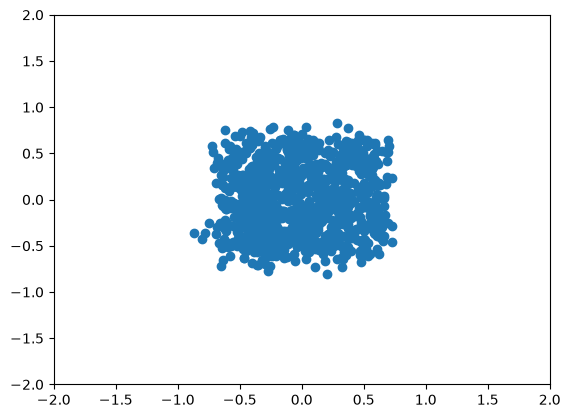

TEST 3000 logpx -4.033664


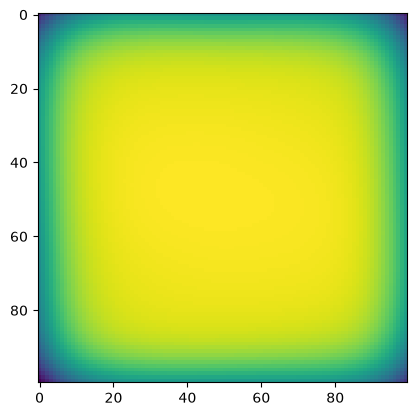

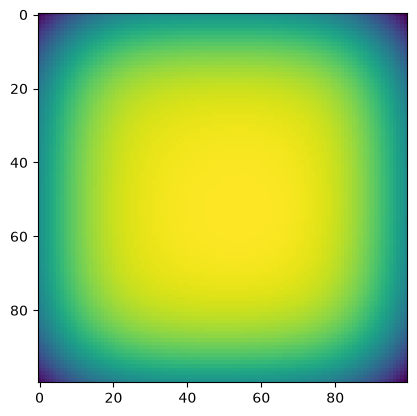

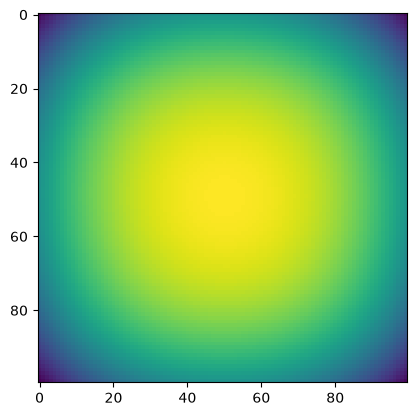

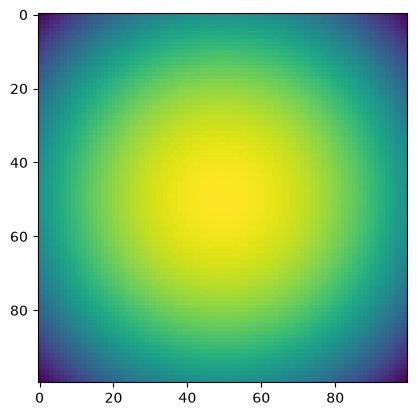

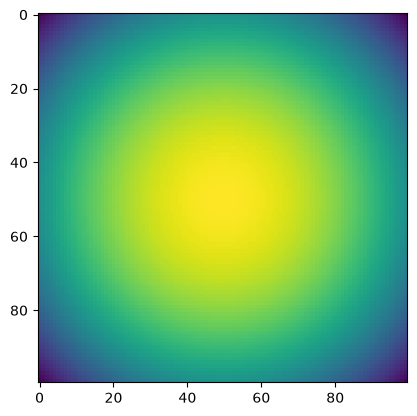

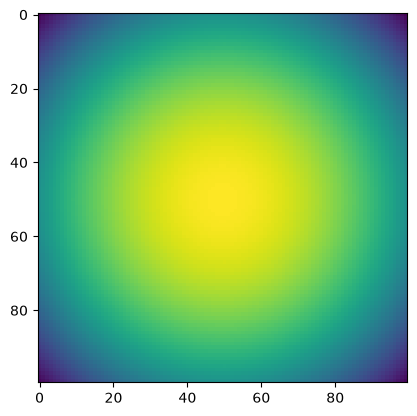

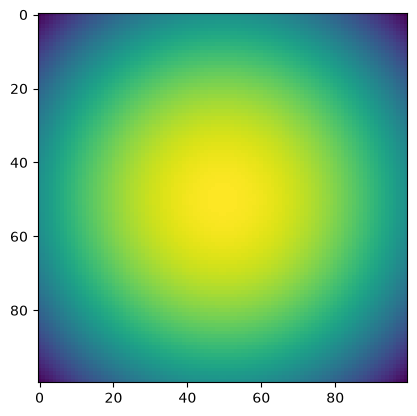

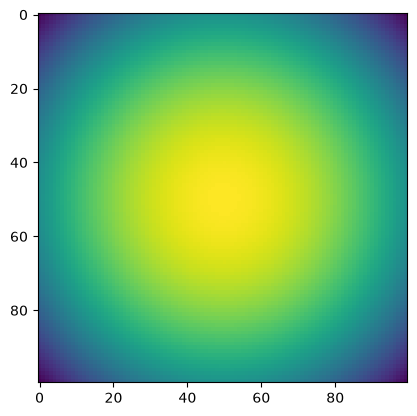

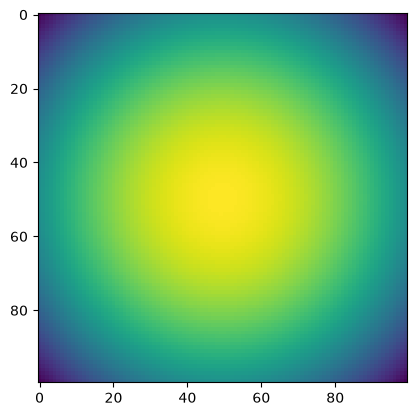

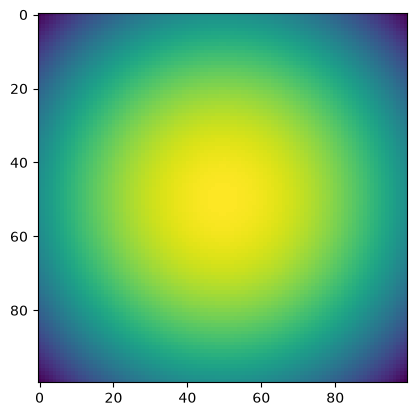

3100 0.26985043 time: 0.0033020973205566406
3200 0.2492192 time: 0.0040357112884521484
3300 0.23509096 time: 0.0038568973541259766
3400 0.25728035 time: 0.0032231807708740234
3500 0.27517933 time: 0.0031592845916748047
3600 0.255491 time: 0.003587007522583008
3700 0.2975989 time: 0.0029790401458740234
3800 0.2601647 time: 0.0033681392669677734
3900 0.25902638 time: 0.0033681392669677734
4000 0.28975153 time: 0.002227783203125


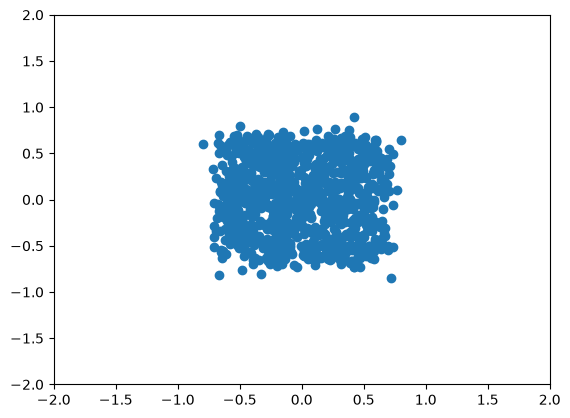

TEST 4000 logpx -1.8437684


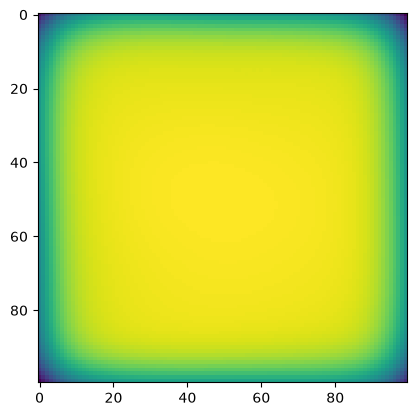

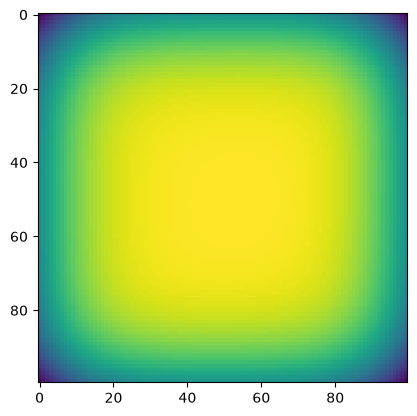

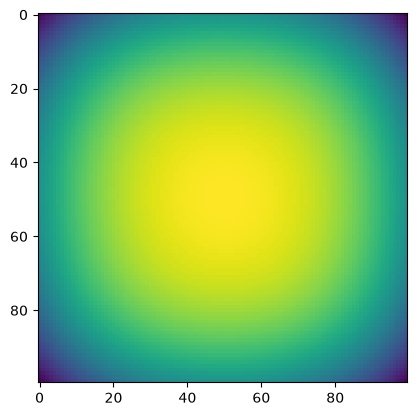

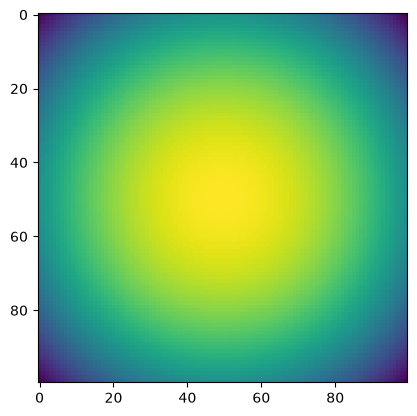

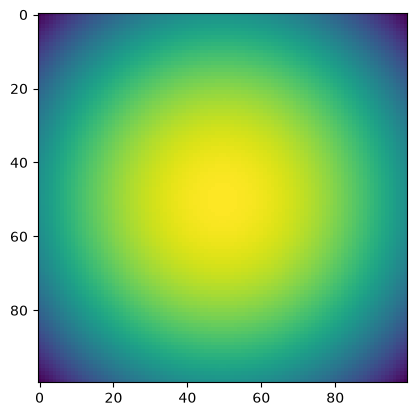

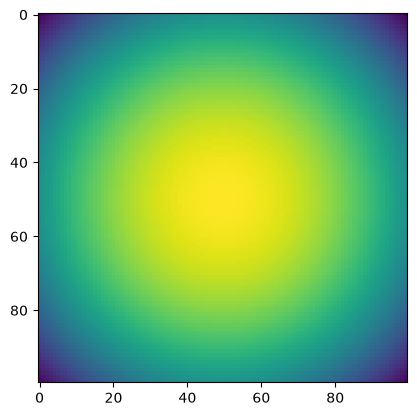

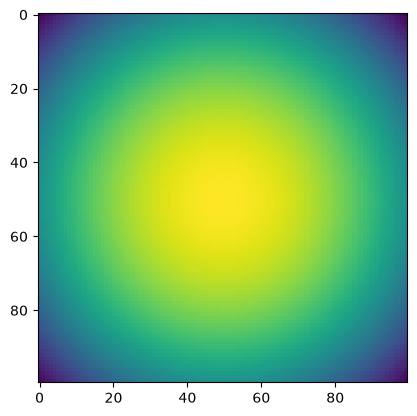

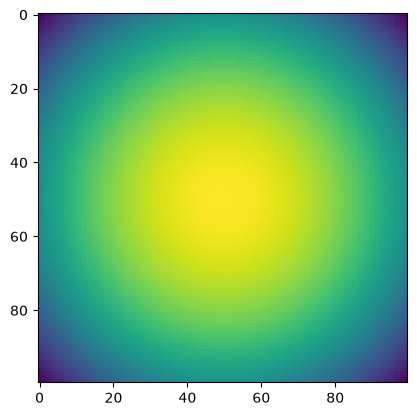

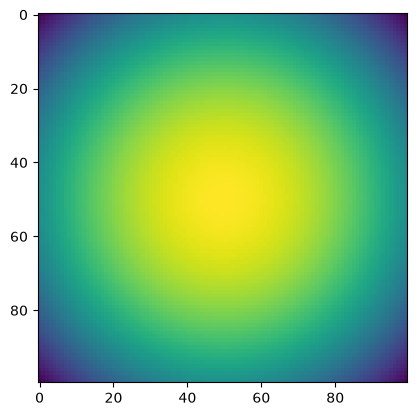

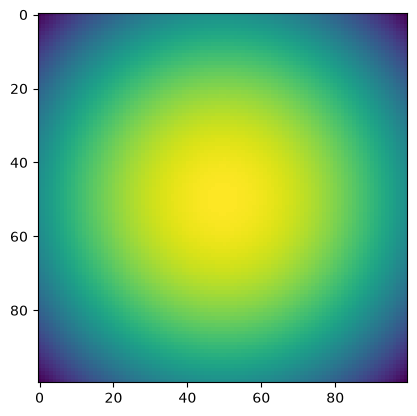

4100 0.27630922 time: 0.002289295196533203
4200 0.26532495 time: 0.0033769607543945312
4300 0.27732784 time: 0.00334930419921875
4400 0.2587452 time: 0.0019538402557373047
4500 0.28491792 time: 0.002203226089477539
4600 0.28209984 time: 0.004713535308837891
4700 0.2677574 time: 0.0035822391510009766
4800 0.23911338 time: 0.0034646987915039062
4900 0.2873238 time: 0.0036356449127197266
5000 0.26960248 time: 0.0020875930786132812


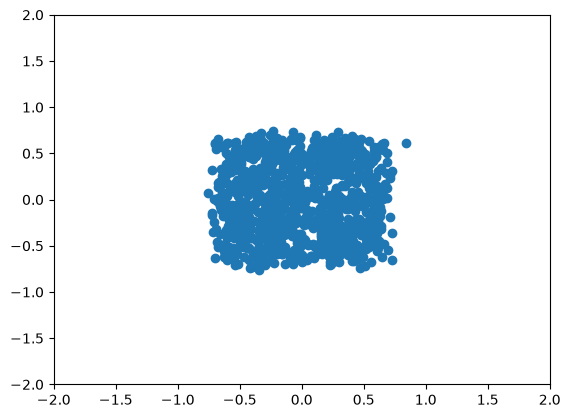

TEST 5000 logpx -1.242645


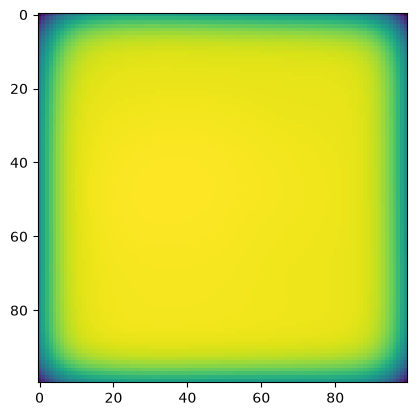

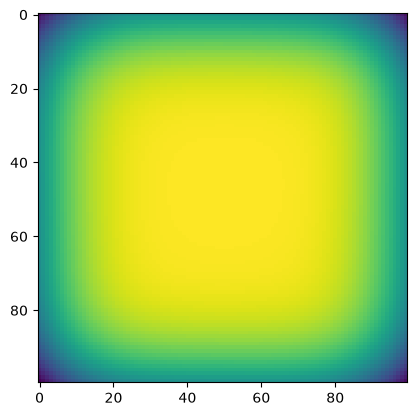

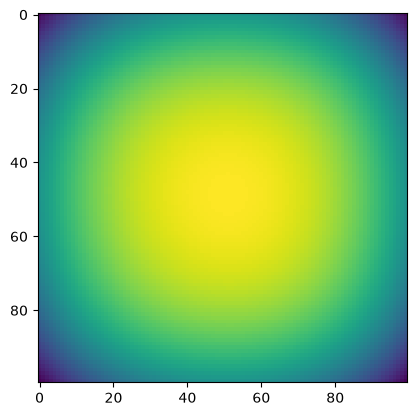

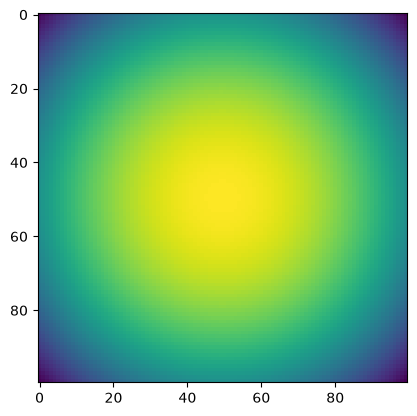

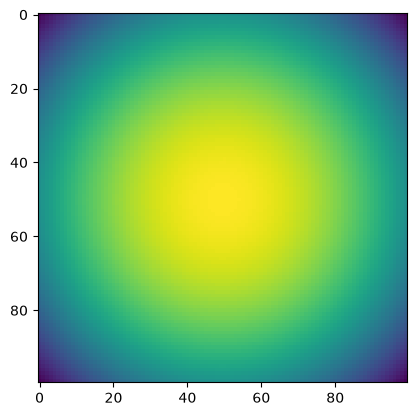

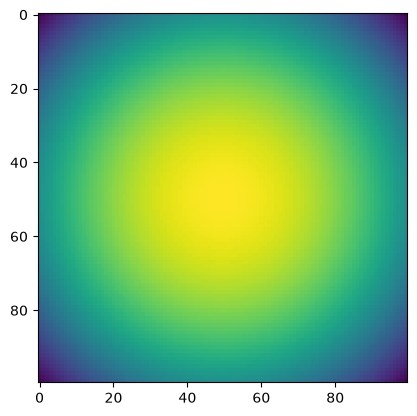

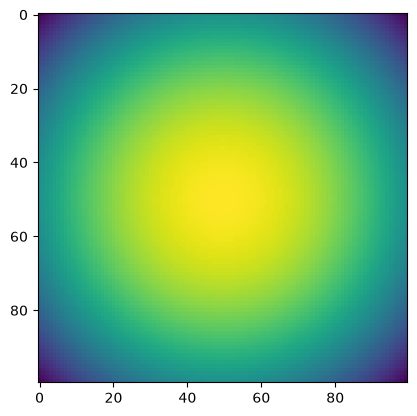

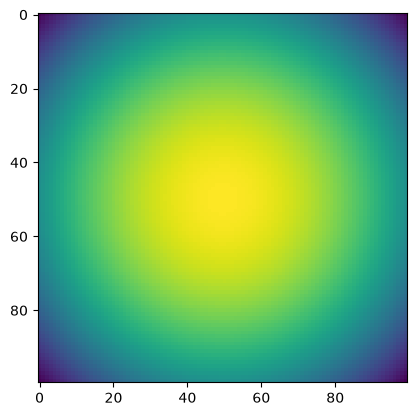

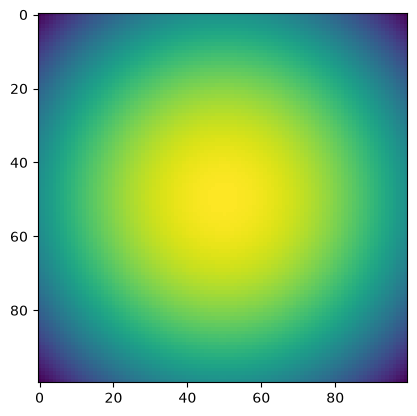

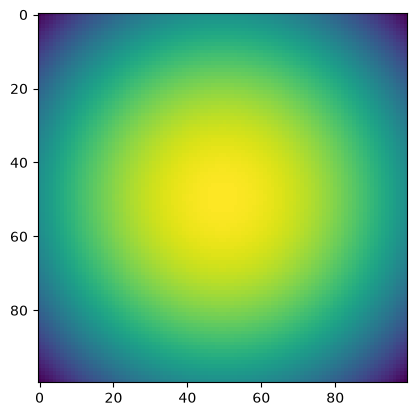

5100 0.29771292 time: 0.0030264854431152344
5200 0.29916677 time: 0.0020427703857421875
5300 0.26901412 time: 0.002144336700439453
5400 0.27070785 time: 0.0028612613677978516
5500 0.26568463 time: 0.0017666816711425781
5600 0.23417768 time: 0.0017316341400146484
5700 0.26537016 time: 0.0033173561096191406
5800 0.24256216 time: 0.0017075538635253906
5900 0.24130617 time: 0.0051538944244384766
6000 0.2929656 time: 0.0020110607147216797


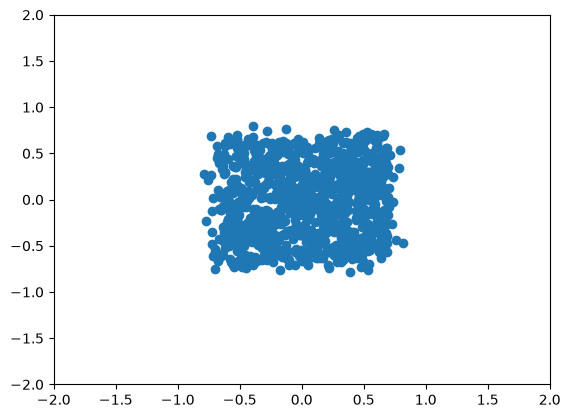

TEST 6000 logpx -1.1279496


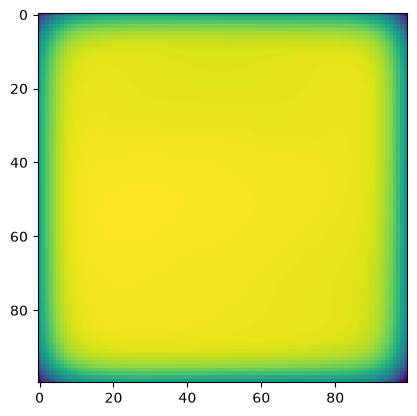

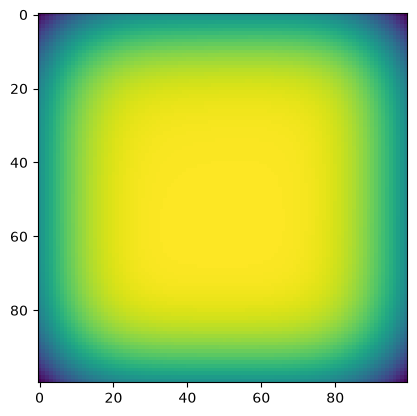

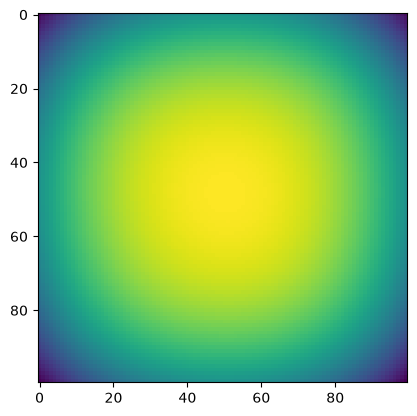

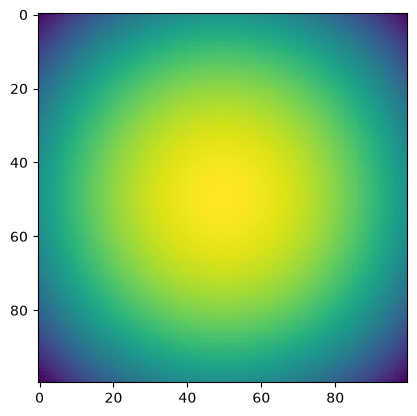

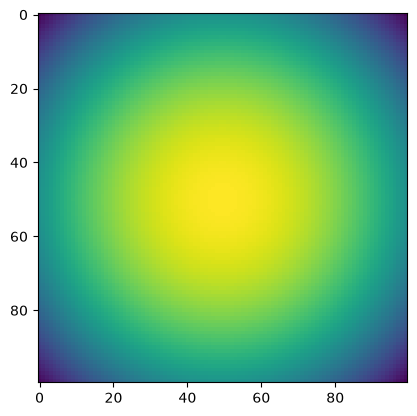

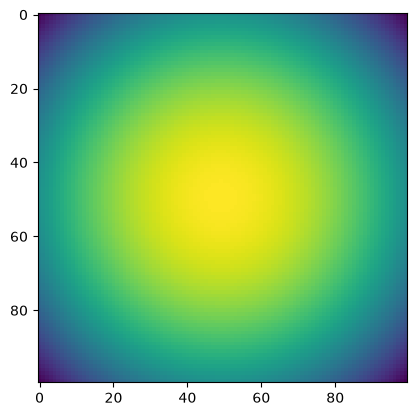

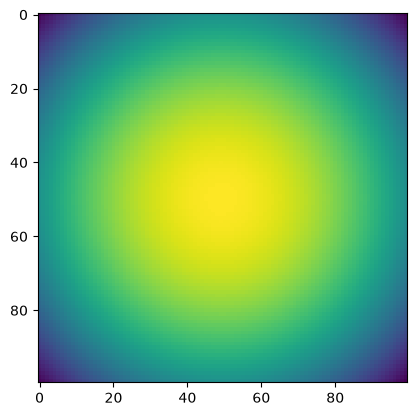

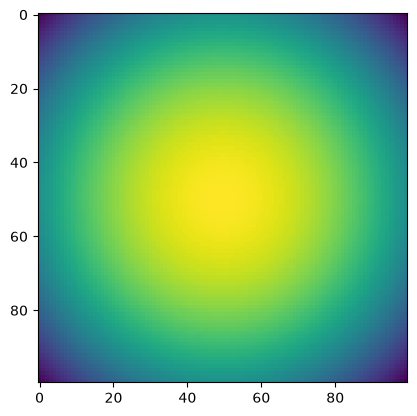

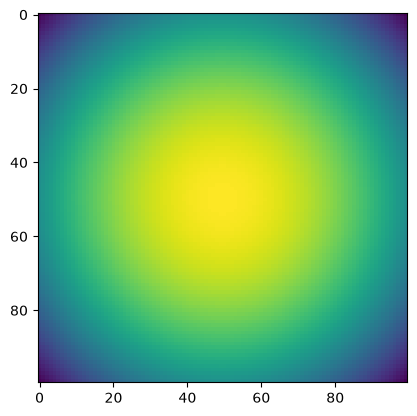

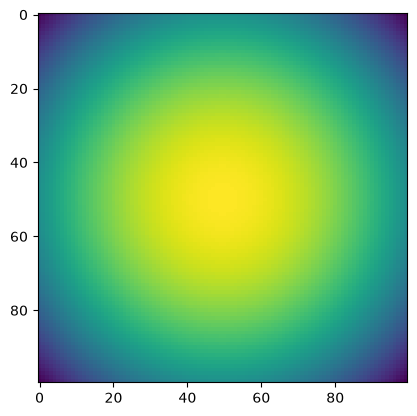

6100 0.26785487 time: 0.001674652099609375
6200 0.27854356 time: 0.0018000602722167969
6300 0.24866523 time: 0.002004384994506836
6400 0.28958705 time: 0.0018985271453857422
6500 0.2604749 time: 0.0017235279083251953
6600 0.26601443 time: 0.0018537044525146484
6700 0.25851825 time: 0.0018718242645263672
6800 0.2725807 time: 0.0018811225891113281
6900 0.26204747 time: 0.0018055438995361328
7000 0.27555975 time: 0.0017559528350830078


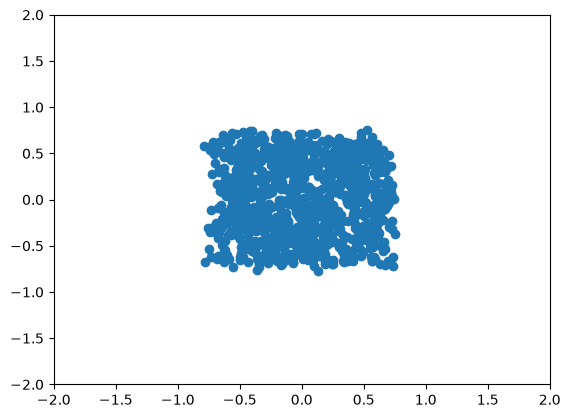

TEST 7000 logpx -0.8509356


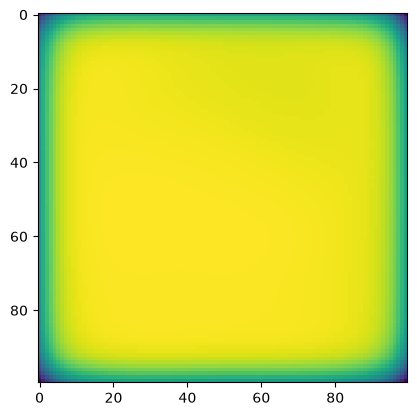

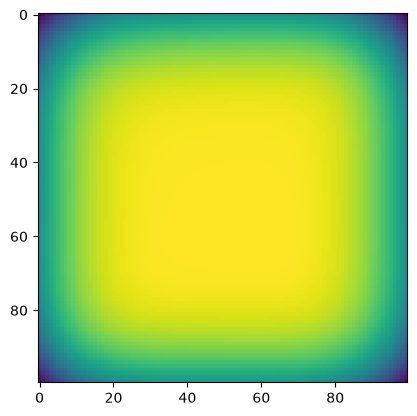

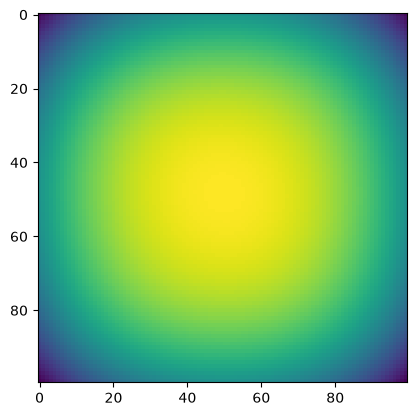

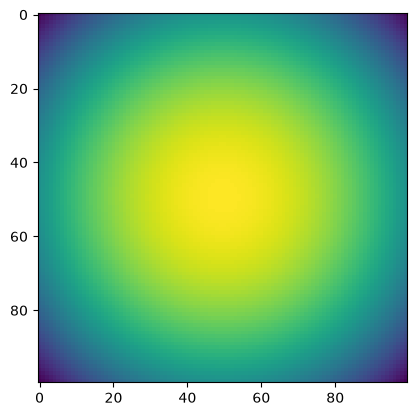

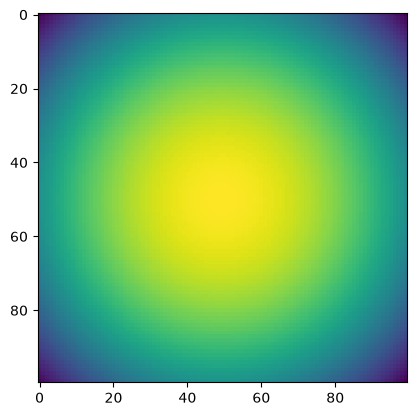

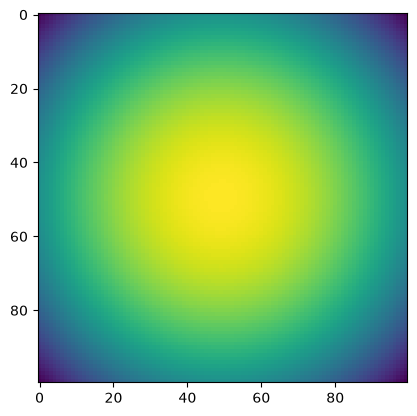

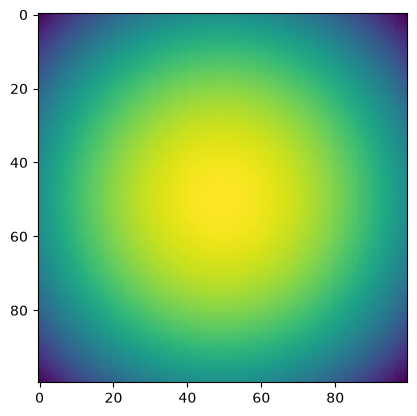

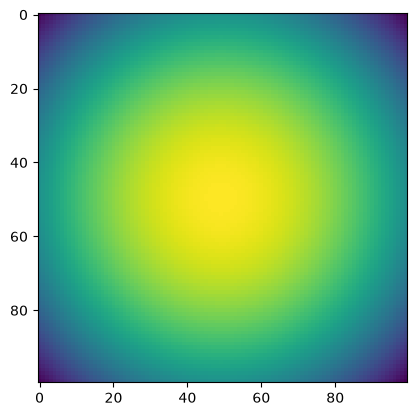

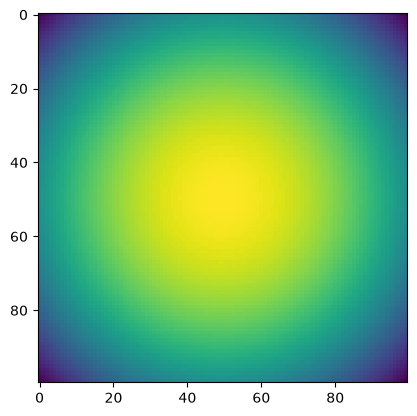

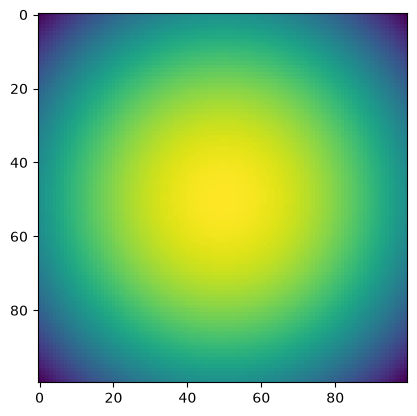

7100 0.27575728 time: 0.001996278762817383
7200 0.26228204 time: 0.0029120445251464844
7300 0.257724 time: 0.003739595413208008
7400 0.24770014 time: 0.002431631088256836
7500 0.2859564 time: 0.0020914077758789062
7600 0.25458798 time: 0.0018155574798583984
7700 0.27086526 time: 0.0035088062286376953
7800 0.2571713 time: 0.0018639564514160156
7900 0.26092273 time: 0.001844644546508789
8000 0.2729168 time: 0.0017666816711425781


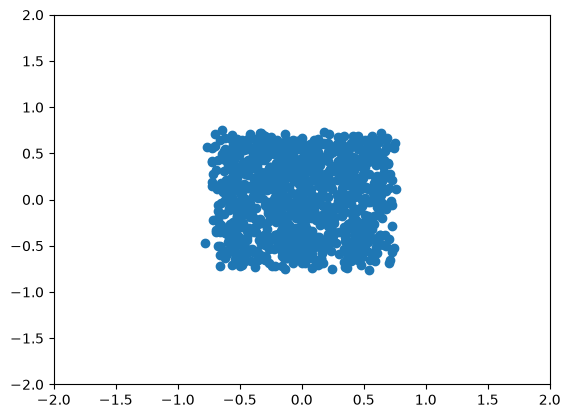

TEST 8000 logpx -0.7189378


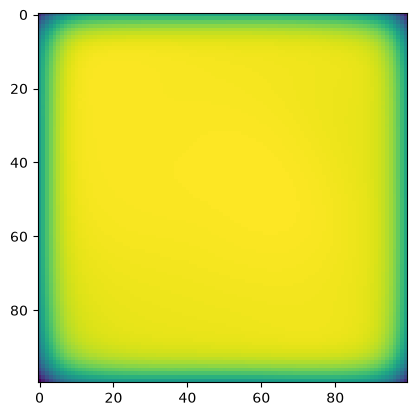

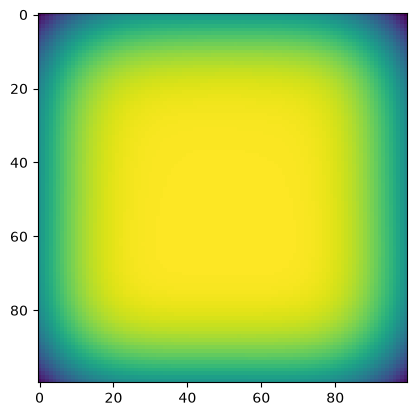

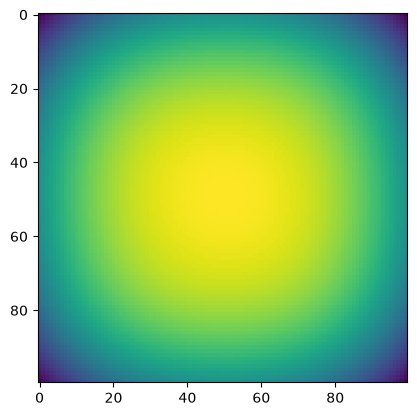

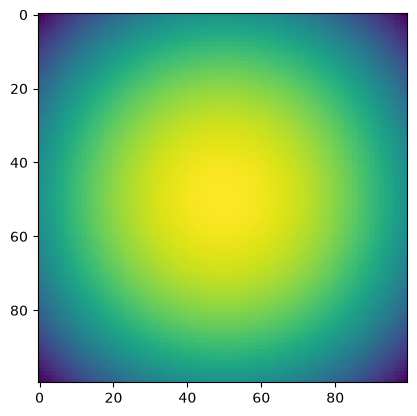

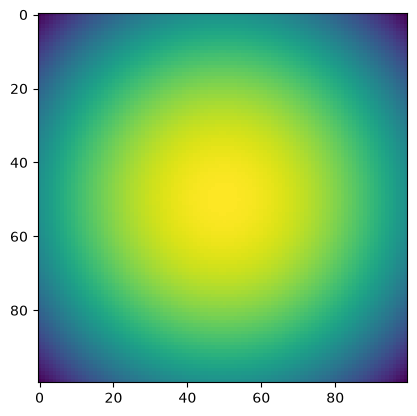

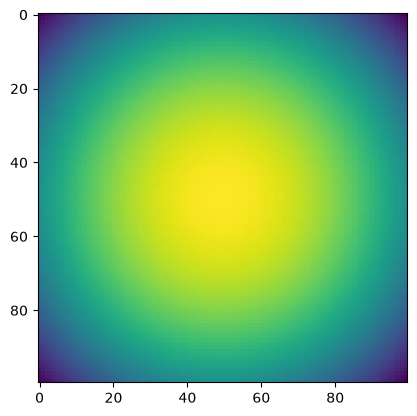

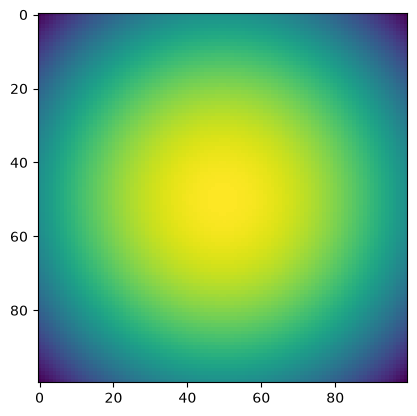

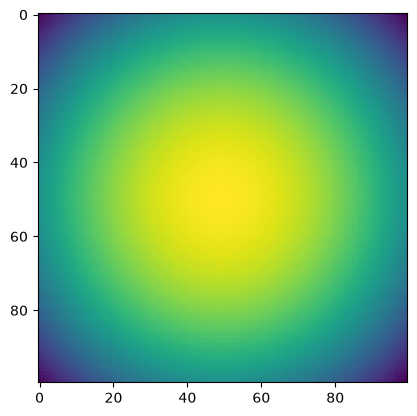

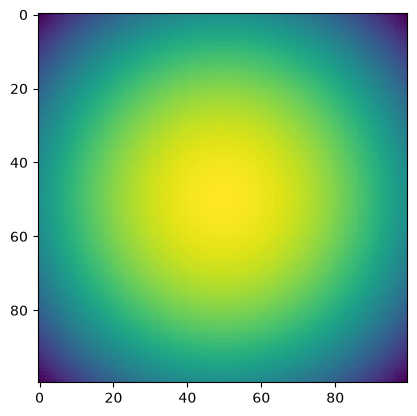

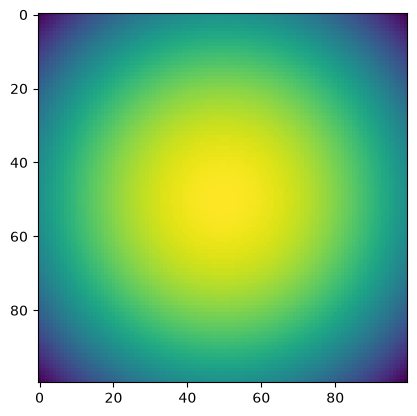

8100 0.27587685 time: 0.0025076866149902344
8200 0.24260145 time: 0.00475311279296875
8300 0.29034328 time: 0.0033707618713378906
8400 0.27818245 time: 0.001950979232788086
8500 0.26164922 time: 0.001832723617553711
8600 0.27009553 time: 0.0022194385528564453
8700 0.23886955 time: 0.0024950504302978516
8800 0.2755669 time: 0.0019371509552001953
8900 0.26631173 time: 0.0019068717956542969
9000 0.28123984 time: 0.0018038749694824219


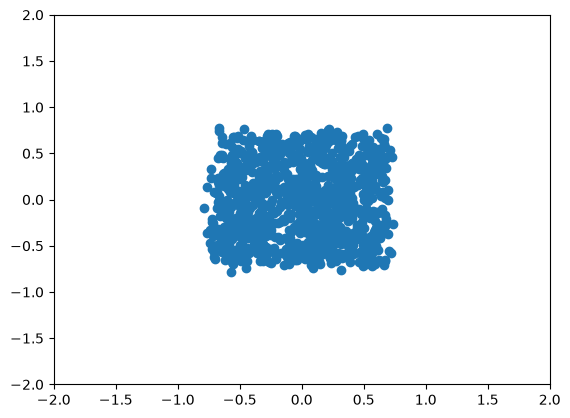

TEST 9000 logpx -0.6648955


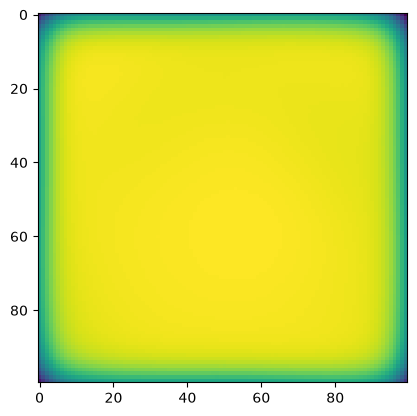

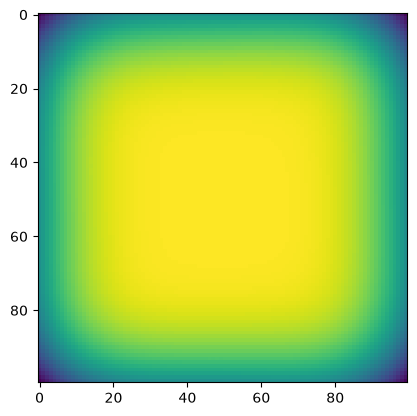

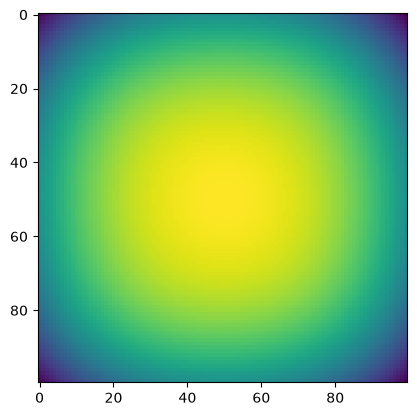

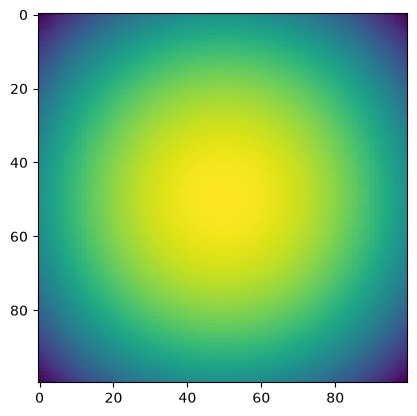

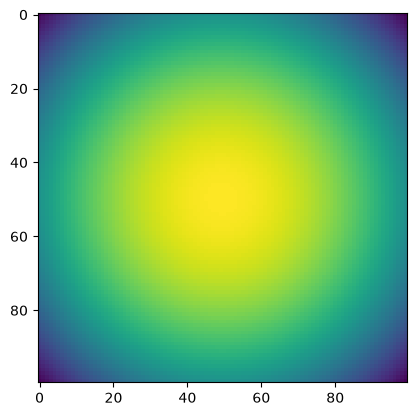

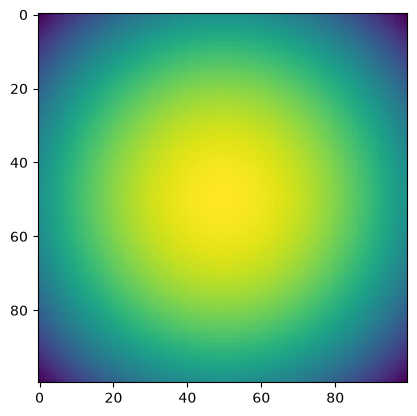

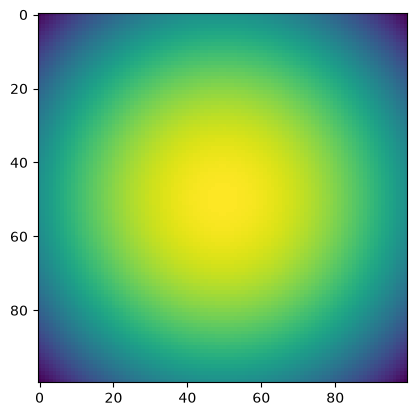

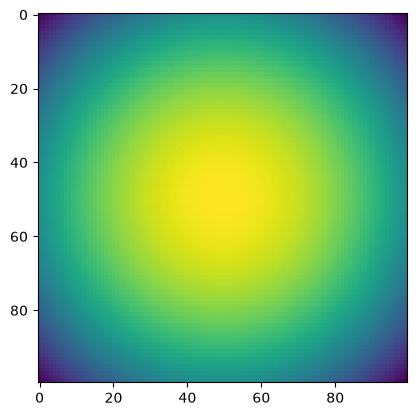

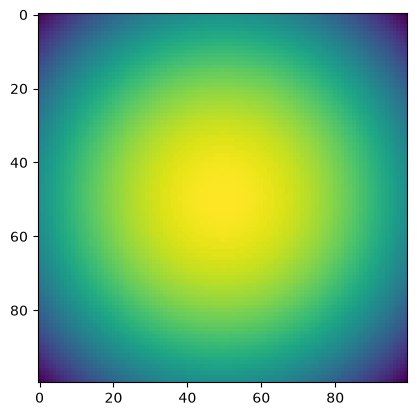

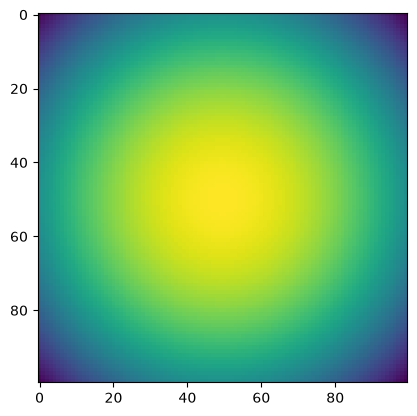

9100 0.26293522 time: 0.001878499984741211
9200 0.25406182 time: 0.003605365753173828
9300 0.25873956 time: 0.0035538673400878906
9400 0.26117417 time: 0.0019249916076660156
9500 0.27624696 time: 0.003564119338989258
9600 0.27685925 time: 0.0020284652709960938
9700 0.26273316 time: 0.0018832683563232422
9800 0.24887086 time: 0.0035223960876464844
9900 0.25270507 time: 0.0017614364624023438
10000 0.28287435 time: 0.003690004348754883


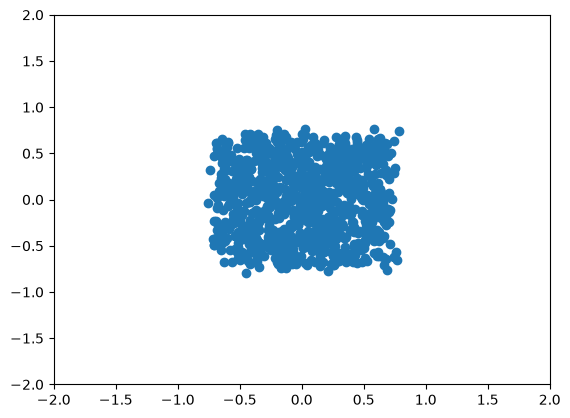

TEST 10000 logpx -0.5864283


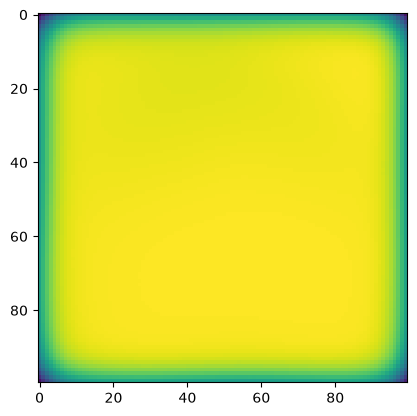

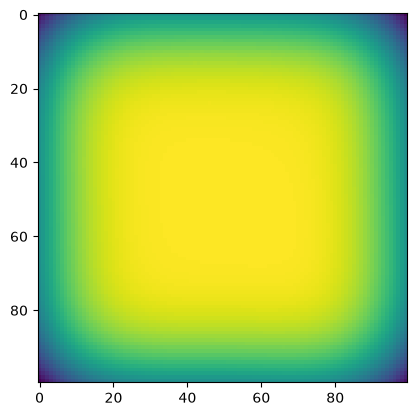

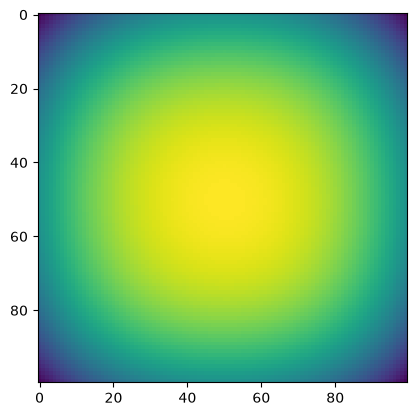

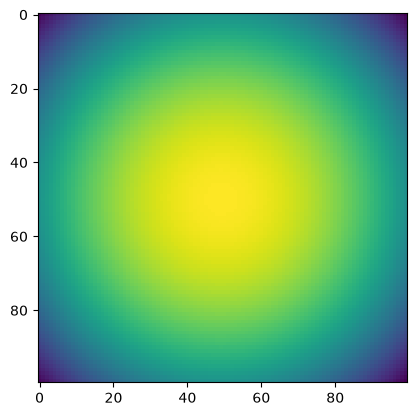

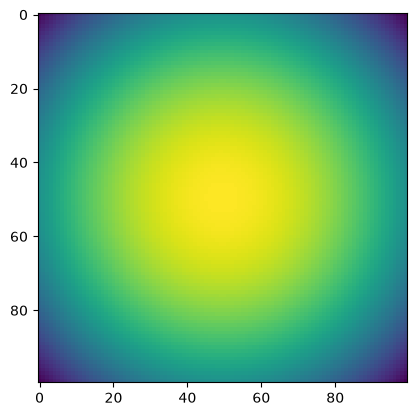

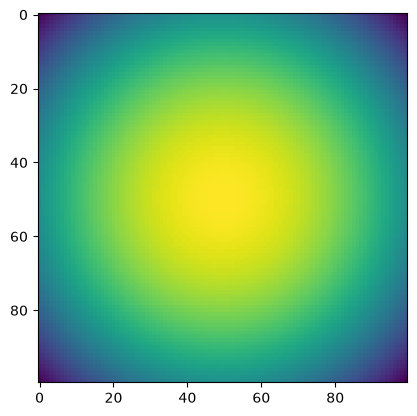

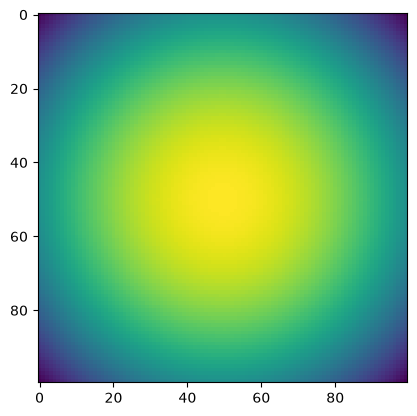

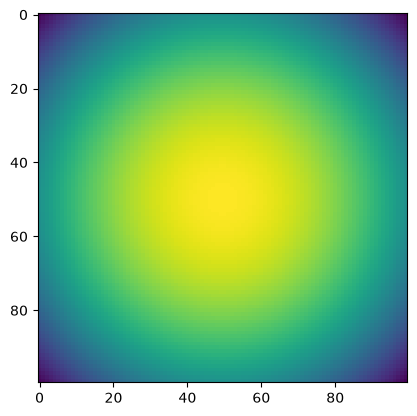

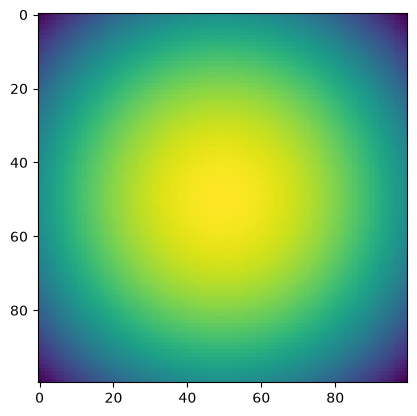

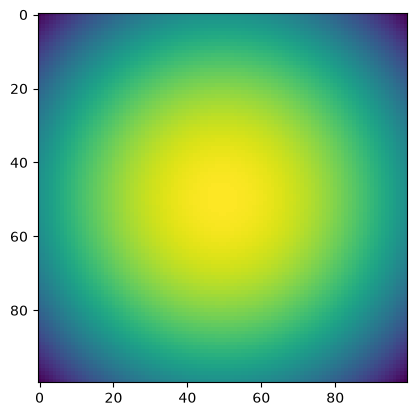

10100 0.28143176 time: 0.0036101341247558594
10200 0.27675515 time: 0.004313945770263672
10300 0.2530307 time: 0.0033643245697021484
10400 0.2515935 time: 0.0035715103149414062
10500 0.25949097 time: 0.001940011978149414
10600 0.28802133 time: 0.003439664840698242
10700 0.23580457 time: 0.0035178661346435547
10800 0.23511678 time: 0.0036153793334960938
10900 0.2599155 time: 0.0018520355224609375
11000 0.25197473 time: 0.004996776580810547


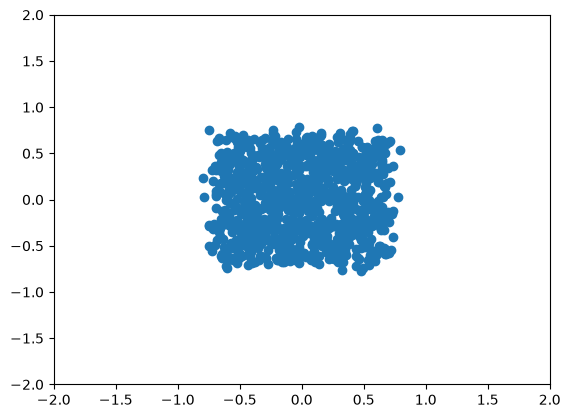

TEST 11000 logpx -0.5853402


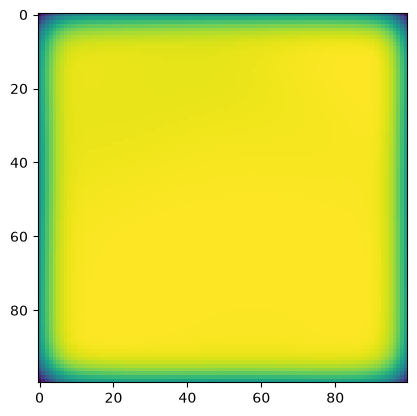

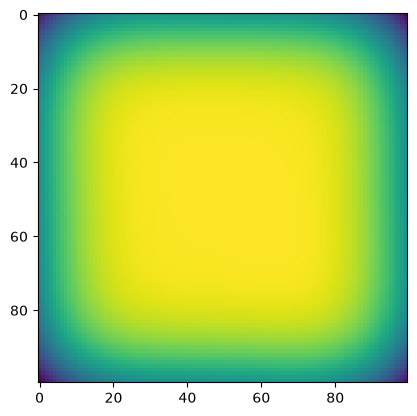

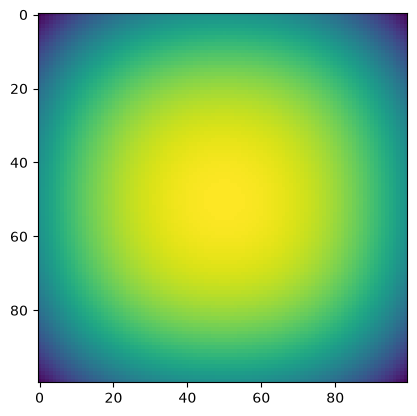

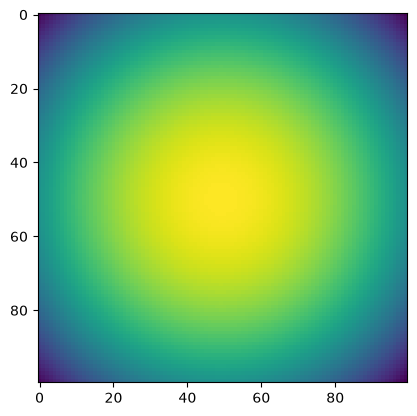

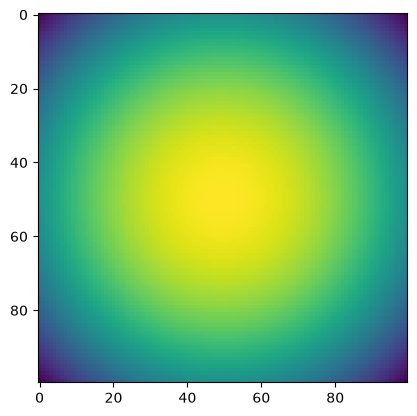

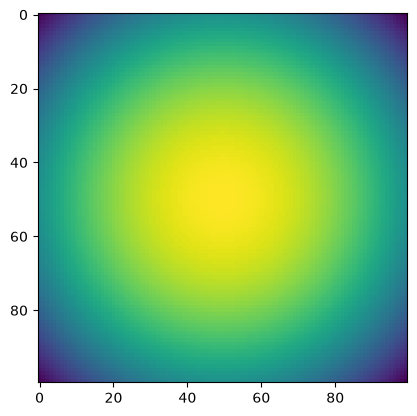

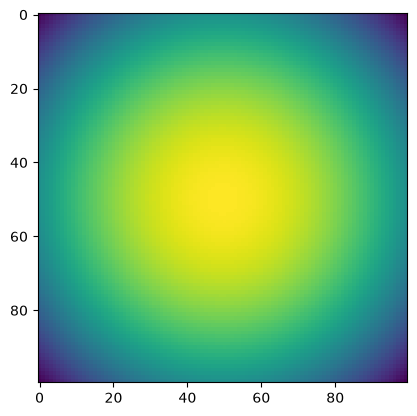

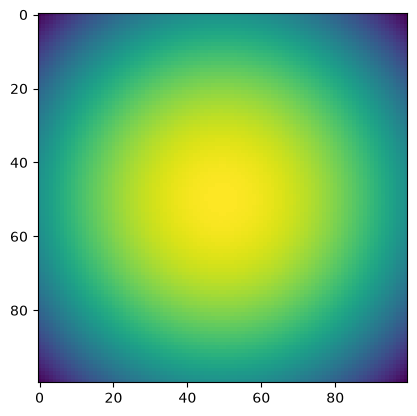

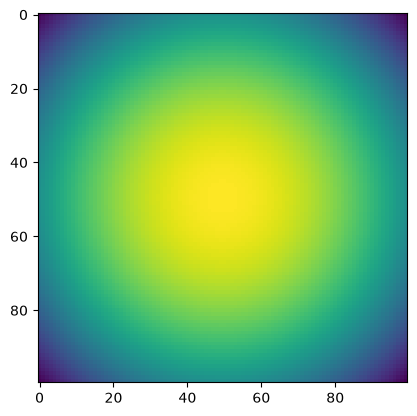

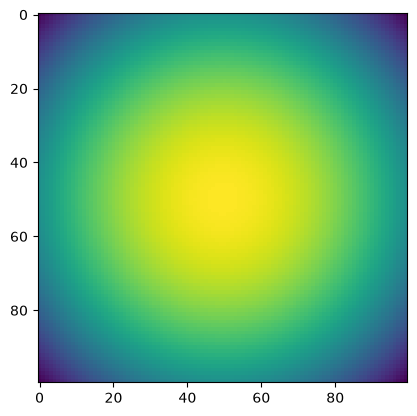

11100 0.26911387 time: 0.0033016204833984375
11200 0.24398169 time: 0.0018470287322998047
11300 0.3121237 time: 0.001828908920288086
11400 0.28830874 time: 0.005068063735961914
11500 0.27671176 time: 0.0028612613677978516
11600 0.24535075 time: 0.0016875267028808594
11700 0.2973481 time: 0.002702474594116211
11800 0.2575572 time: 0.0017147064208984375
11900 0.27607262 time: 0.0025229454040527344
12000 0.27419844 time: 0.004470109939575195


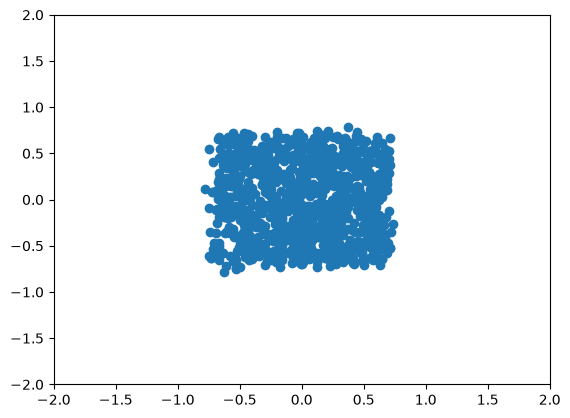

TEST 12000 logpx -0.67013663


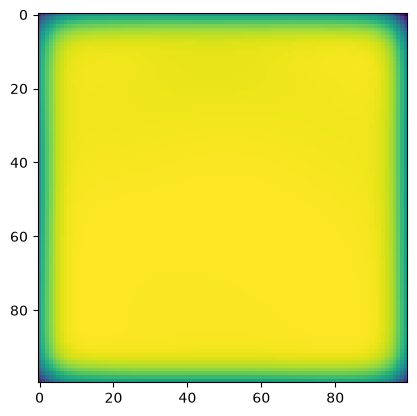

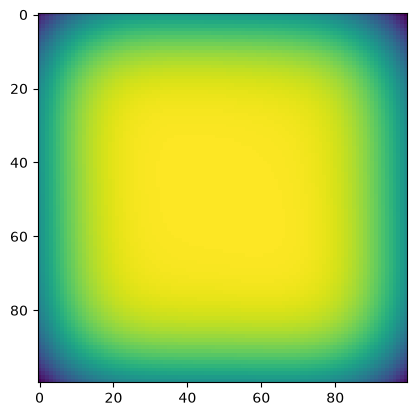

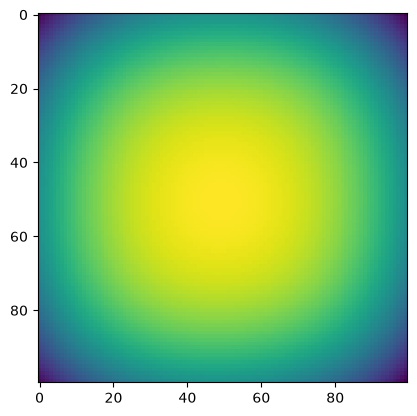

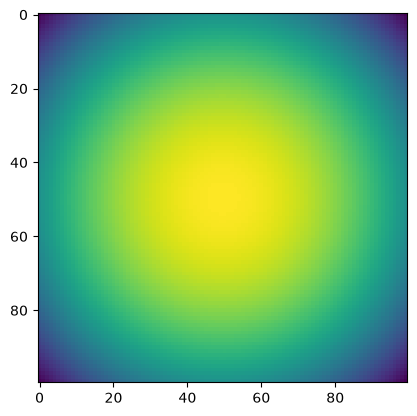

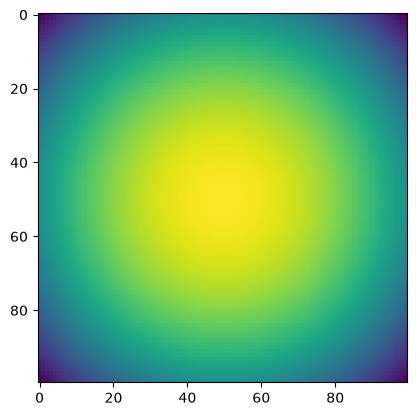

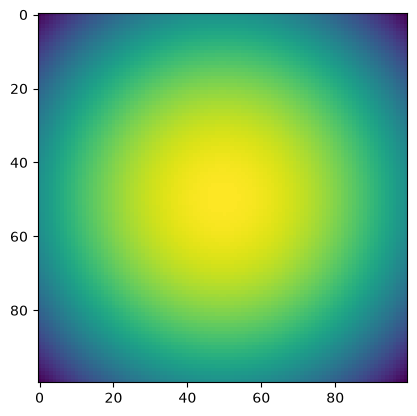

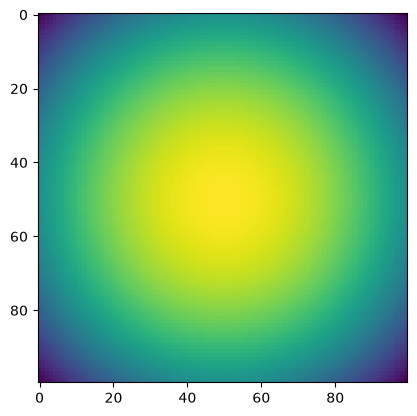

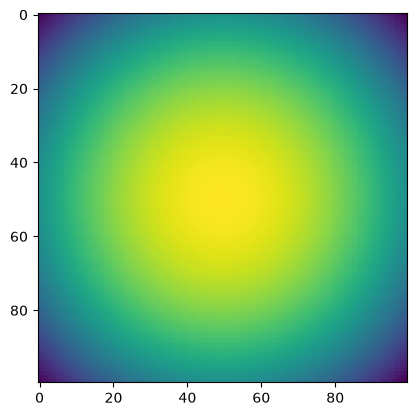

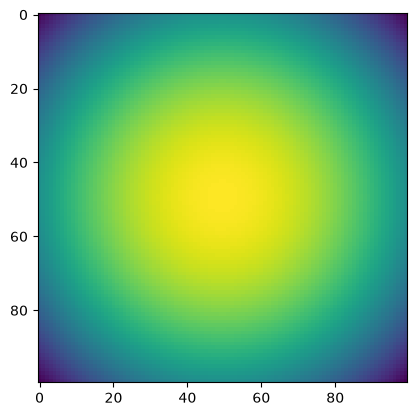

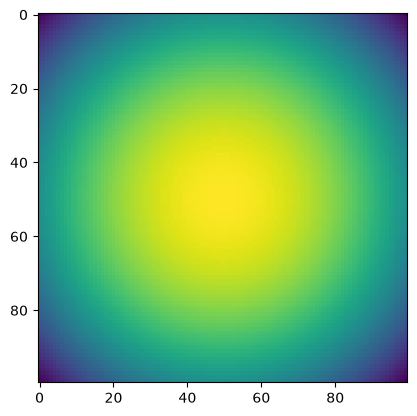

12100 0.27733186 time: 0.0016772747039794922
12200 0.27714142 time: 0.0018837451934814453
12300 0.27696165 time: 0.0017578601837158203
12400 0.25328317 time: 0.004254817962646484
12500 0.27187 time: 0.0035347938537597656
12600 0.23044564 time: 0.003610372543334961
12700 0.27310434 time: 0.0033206939697265625
12800 0.28502437 time: 0.0017745494842529297
12900 0.28075558 time: 0.0017011165618896484
13000 0.25649306 time: 0.0036401748657226562


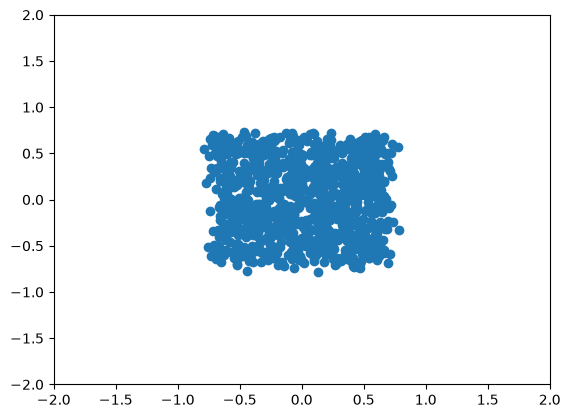

TEST 13000 logpx -0.5340711


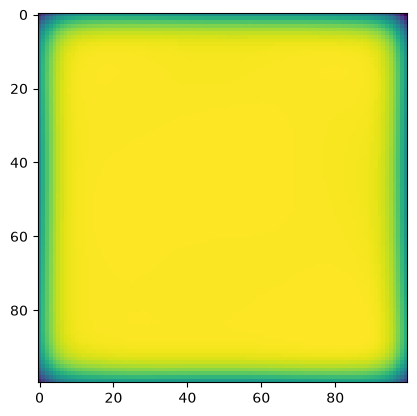

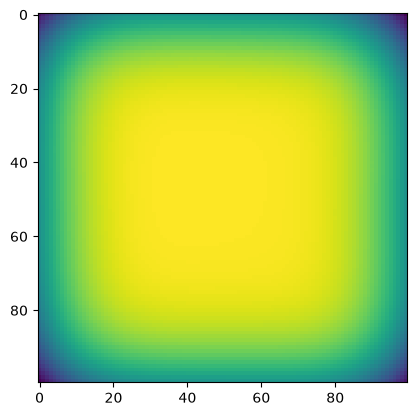

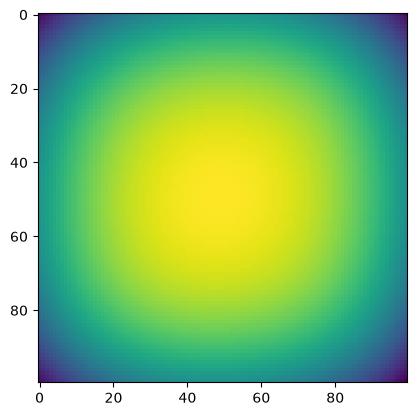

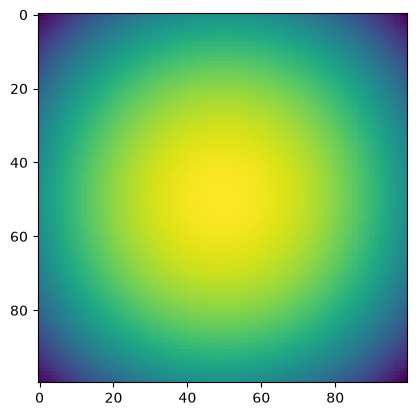

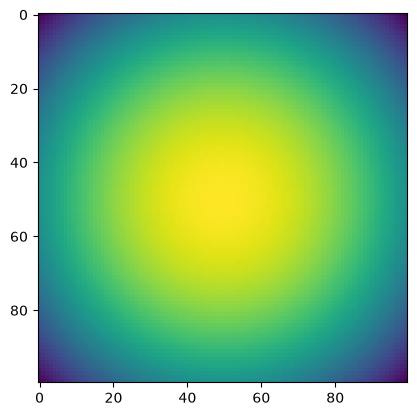

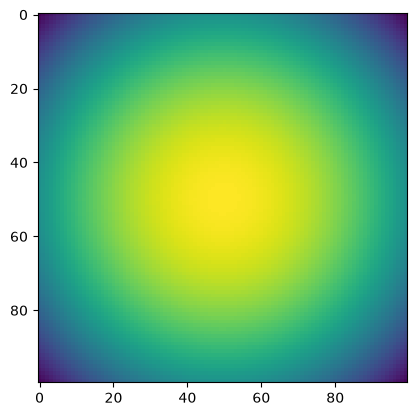

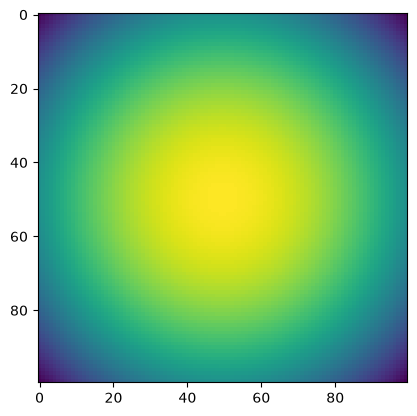

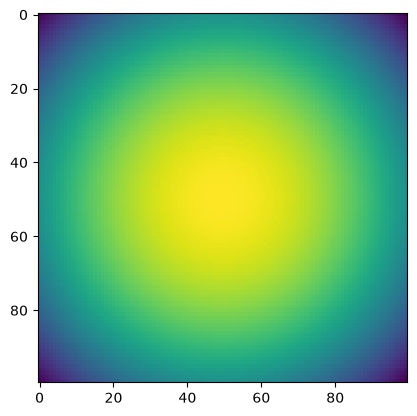

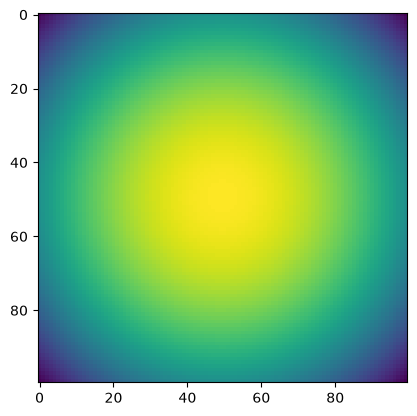

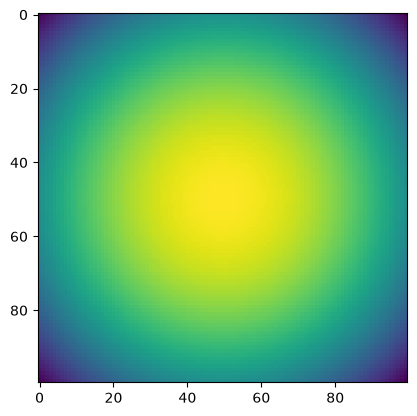

13100 0.24606255 time: 0.0020592212677001953
13200 0.26061457 time: 0.0020689964294433594
13300 0.2703603 time: 0.001821279525756836
13400 0.26789296 time: 0.0020978450775146484
13500 0.2719066 time: 0.0018281936645507812
13600 0.2538952 time: 0.0036630630493164062
13700 0.27728975 time: 0.003029346466064453
13800 0.28003773 time: 0.00173187255859375
13900 0.27428526 time: 0.0024993419647216797
14000 0.25754574 time: 0.0017702579498291016


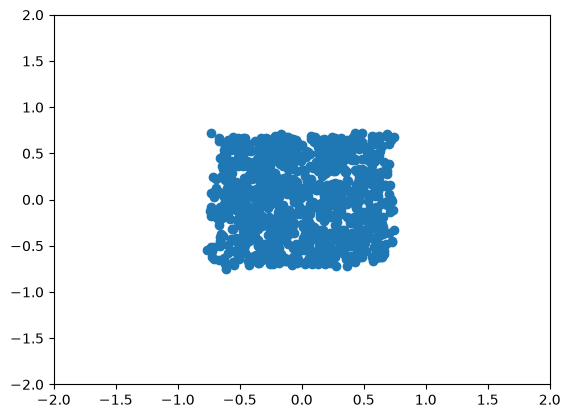

TEST 14000 logpx -0.58805835


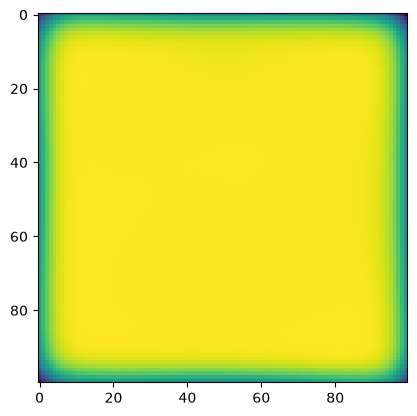

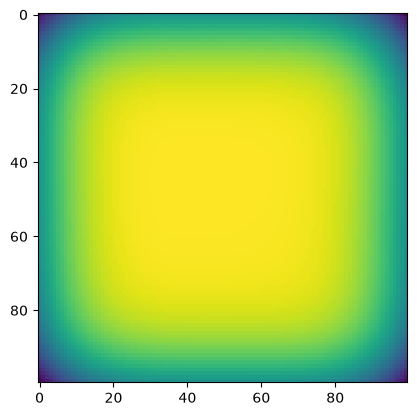

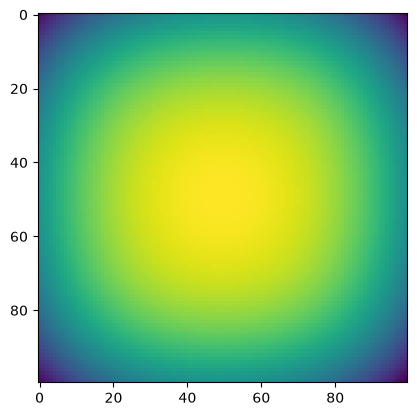

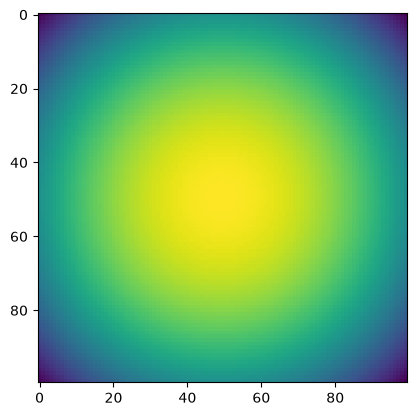

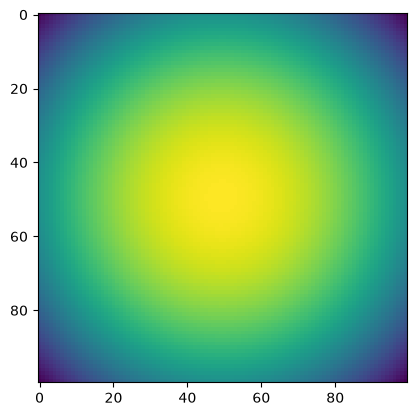

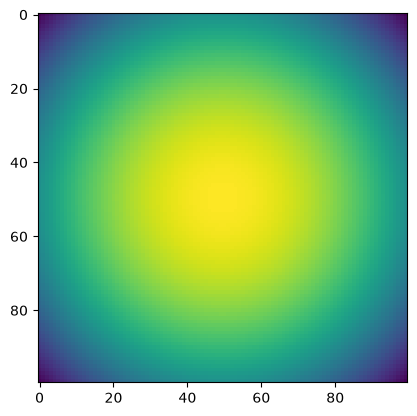

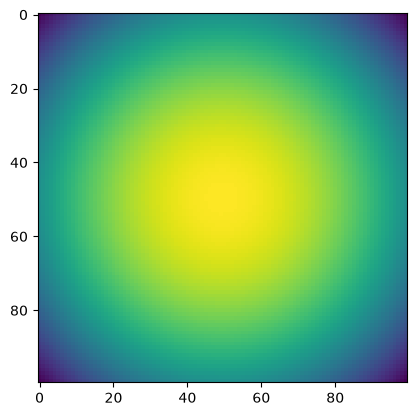

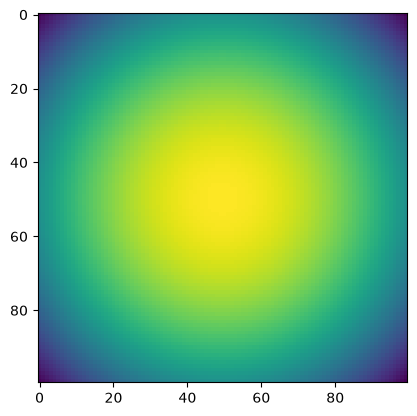

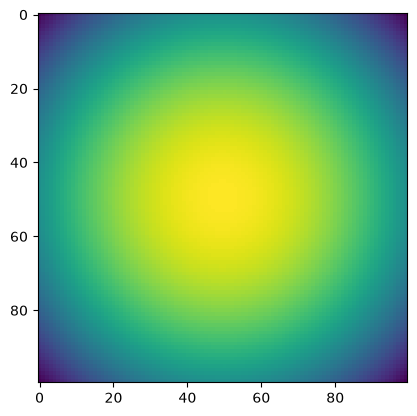

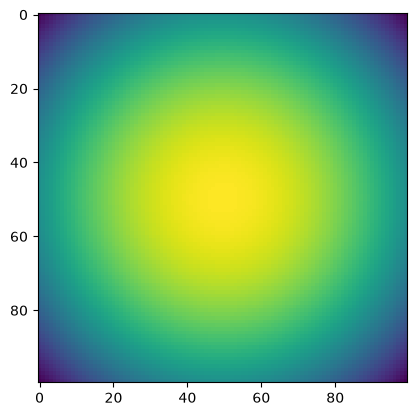

14100 0.2364531 time: 0.0018610954284667969
14200 0.27603072 time: 0.0018460750579833984
14300 0.25777924 time: 0.003462553024291992
14400 0.26819155 time: 0.0033271312713623047
14500 0.28919744 time: 0.005051374435424805
14600 0.28417686 time: 0.0034477710723876953
14700 0.2918058 time: 0.0017123222351074219
14800 0.2868103 time: 0.0017511844635009766
14900 0.26660064 time: 0.0019123554229736328
15000 0.27747867 time: 0.0021152496337890625


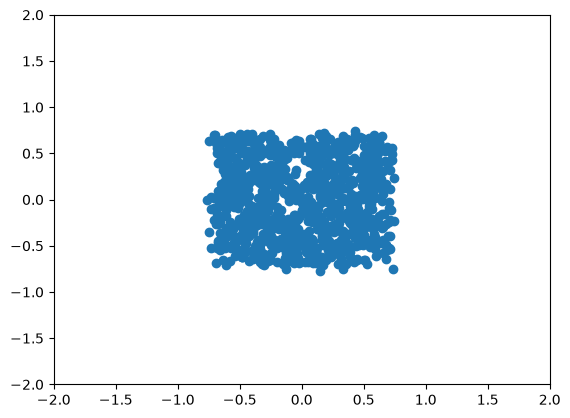

TEST 15000 logpx -0.5506063


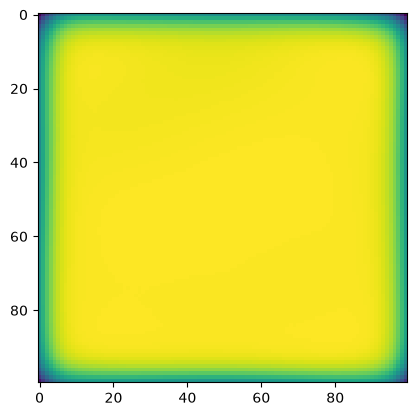

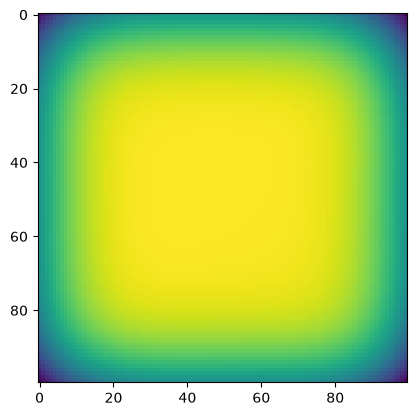

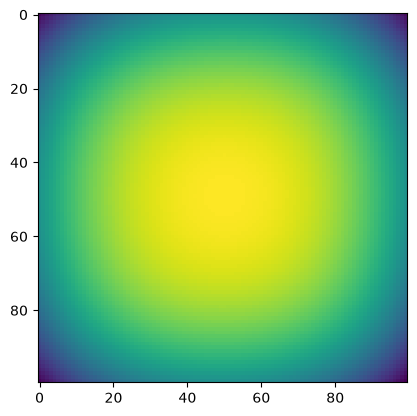

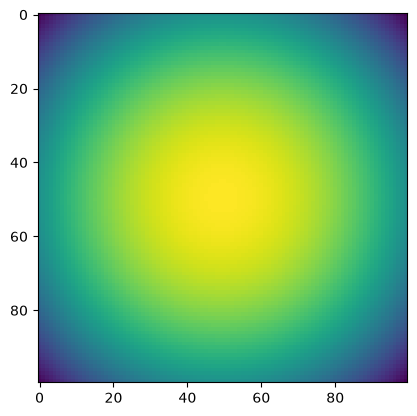

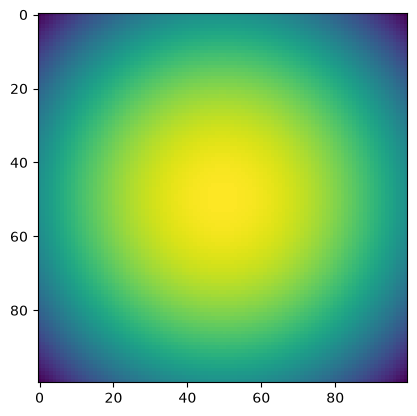

...

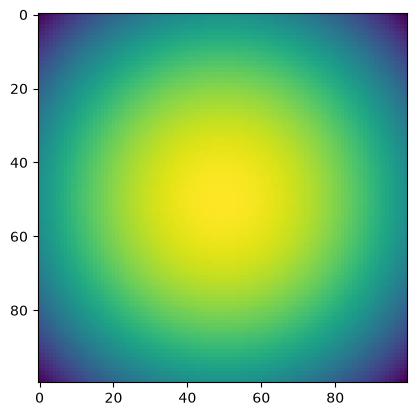

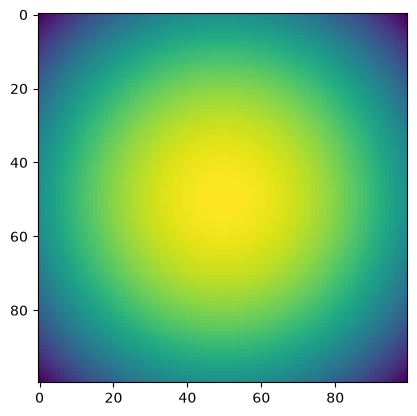

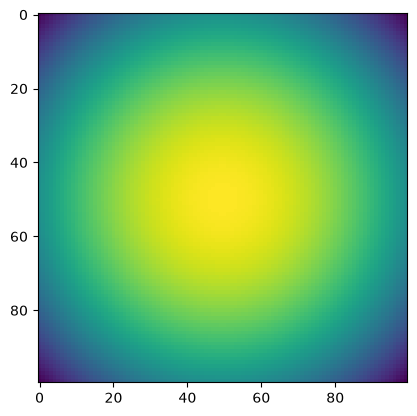

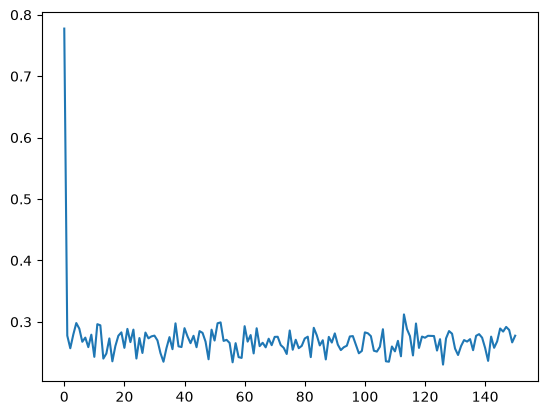

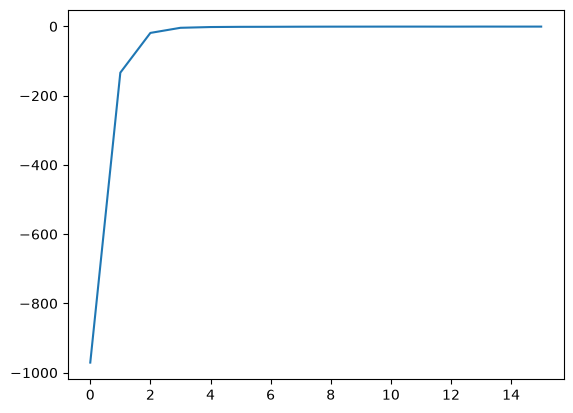

In [36]:
batch_size = 1000
data_dim = 2
num_steps = 15001

EMA = .999

n_steps = 100
net_params = {"n_layers": 4,
              "h_dim": 128,
              "emb_dim": 32}

def forward_fn():
  net = ResnetDiffusionModel(n_steps=n_steps, n_layers=4, x_dim=data_dim, h_dim=128, emb_dim=32)

  if ebm:
    net = EBMDiffusionModel(net)

  ddpm = PortableDiffusionModel(data_dim, n_steps, net, var_type="beta_forward")

  def logp_unnorm(x, t):
    scale_e = ddpm.energy_scale(-2 - t)
    t = jnp.ones((x.shape[0],), dtype=jnp.int32) * t
    return -net.neg_logp_unnorm(x, t) * scale_e

  def _logpx(x):
    return ddpm.logpx(x)["logpx"]
  return ddpm.loss, (ddpm.loss, ddpm.sample, _logpx, logp_unnorm)

forward = hk.multi_transform(forward_fn)
rng_seq = hk.PRNGSequence(0)

xr = [-.75, .75]
yr = [-.75, .75]


def plot_samples(x):
  plt.scatter(x[:, 0], x[:, 1])
  plt.xlim(-2, 2)
  plt.ylim(-2, 2)

def dist_show_2d(fn, xr, yr):
    nticks = 100
    x, y = np.meshgrid(np.linspace(xr[0], xr[1], nticks), np.linspace(yr[0], yr[1], nticks))
    coord = np.stack([x, y], axis=-1).reshape((-1, 2))
    heatmap = fn(coord).reshape((nticks, nticks))
    plt.imshow(heatmap)

# load data
dataset_energy, dataset_sample = toy_box(scale=0.7)
x = dataset_sample(batch_size)

plot_samples(x)
plt.show()
x = x.reshape(x.shape[0], -1)


params = forward.init(next(rng_seq), x)
loss_fn, sample_fn, logpx_fn, logp_unnorm_fn = forward.apply
param_count = sum(x.size for x in jax.tree_leaves(params))
for k, v in jax.tree_map(lambda x: x.shape, params).items():
  print(k, v)
print("Model has {} params".format(param_count))


opt = optax.adam(1e-3)
opt_state = opt.init(params)

sample_fn = jax.jit(sample_fn, static_argnums=2)
logpx_fn = jax.jit(logpx_fn)

logp_unnorm_fn = jax.jit(logp_unnorm_fn)

@jax.jit
def mean_loss_fn(params, rng, x):
  loss = loss_fn(params, rng, x)
  return loss.mean()

@jax.jit
def update(params, opt_state, rng, x):
  loss, grad = jax.value_and_grad(mean_loss_fn)(params, rng, x)

  updates, opt_state = opt.update(grad, opt_state)
  new_params = optax.apply_updates(params, updates)
  return loss, new_params, opt_state

# Speed-only change (no maths changed): the moving average runs inside one compiled call
# instead of one small GPU operation per weight array, about 10x faster per step.
@jax.jit
def update_ema(params, ema_params, opt_state, rng, x):
  loss, params, opt_state = update(params, opt_state, rng, x)
  ema_params = jax.tree_util.tree_map(lambda e, p: e * EMA + p * (1 - EMA), ema_params, params)
  return loss, params, ema_params, opt_state

ema_params = params
losses = []
test_logpx = []
itr = 0

for itr in range(num_steps):
  x = dataset_sample(batch_size)

  x = x.reshape(x.shape[0], -1)
  start_time = time.time()
  loss, params, ema_params, opt_state = update_ema(params, ema_params, opt_state, next(rng_seq), x)
  duration_update = time.time() - start_time

  if itr % 100 == 0:
    print(itr, loss, "time:", duration_update)
    losses.append(loss)
  if itr % 1000 == 0:
    x_samp = sample_fn(ema_params, next(rng_seq), batch_size)
    plot_samples(x_samp)
    plt.show()
    logpx = logpx_fn(ema_params, next(rng_seq), x).mean()
    print("TEST", itr, 'logpx', logpx)
    test_logpx.append(logpx)

    if ebm:
      for t in range(10):
        dist_show_2d(lambda x: logp_unnorm_fn(ema_params, next(rng_seq), x, 10*t), xr=xr, yr=yr)
        plt.show()

plt.plot(losses)
plt.show()
plt.plot(test_logpx)

large_box_params = ema_params

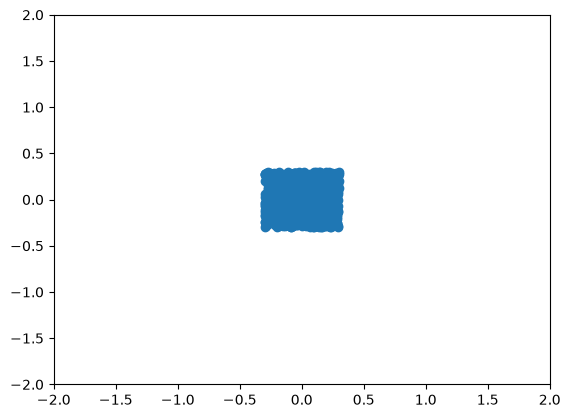

portable_diffusion_model {'out_logvar': (100,)}
resnet_diffusion_model/embed {'embeddings': (100, 32)}
resnet_diffusion_model/layer_norm {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/layer_norm_1 {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/layer_norm_2 {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/layer_norm_3 {'offset': (128,), 'scale': (128,)}
resnet_diffusion_model/linear {'b': (128,), 'w': (2, 128)}
resnet_diffusion_model/linear_1 {'b': (256,), 'w': (128, 256)}
resnet_diffusion_model/linear_10 {'b': (256,), 'w': (32, 256)}
resnet_diffusion_model/linear_11 {'b': (256,), 'w': (256, 256)}
resnet_diffusion_model/linear_12 {'b': (128,), 'w': (256, 128)}
resnet_diffusion_model/linear_13 {'b': (256,), 'w': (128, 256)}
resnet_diffusion_model/linear_14 {'b': (256,), 'w': (32, 256)}
resnet_diffusion_model/linear_15 {'b': (256,), 'w': (256, 256)}
resnet_diffusion_model/linear_16 {'b': (128,), 'w': (256, 128)}
resnet_diffusion_model/linear_17 {'b': (2,)

/tmp/ipykernel_1391087/1385371818.py:265: UserWarning: Explicitly requested dtype int64 requested in ones is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  t = jnp.ones((n,), dtype=jnp.int64) * j


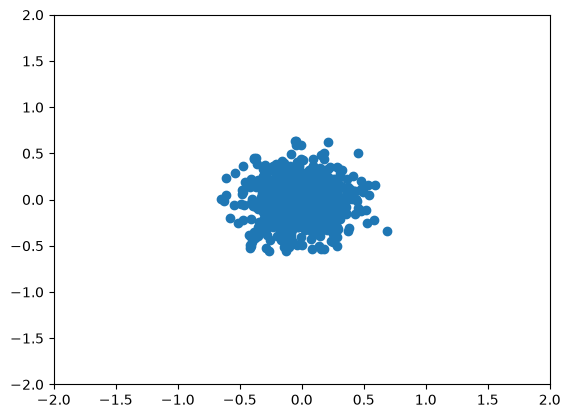

/tmp/ipykernel_1391087/1385371818.py:235: UserWarning: Explicitly requested dtype int64 requested in ones is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  t = jnp.ones((x_0.shape[0],), dtype=jnp.int64) * (self._n_steps - 1)


TEST 0 logpx -966.9383


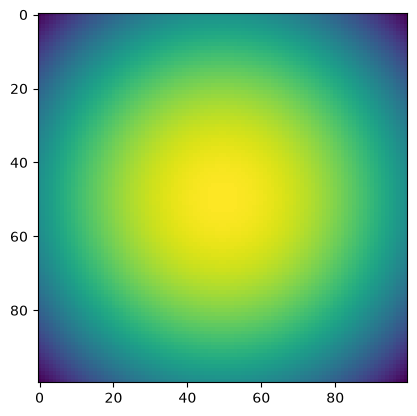

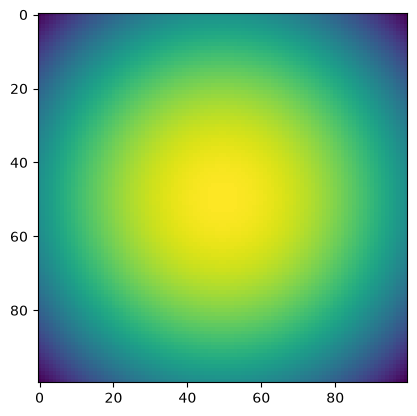

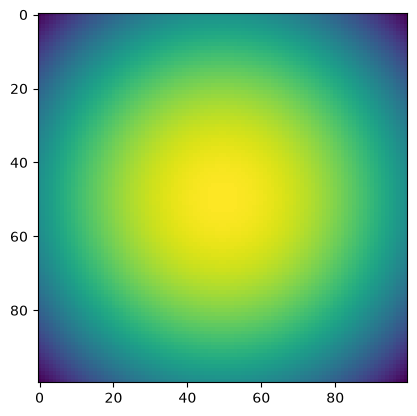

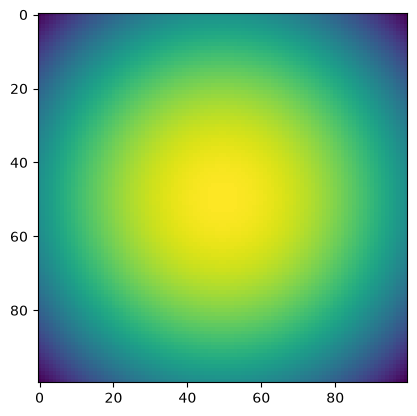

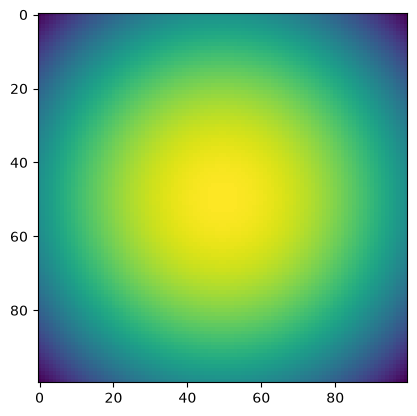

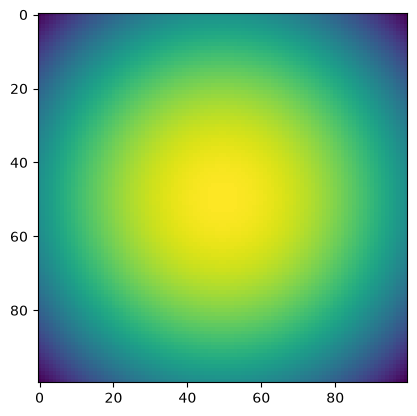

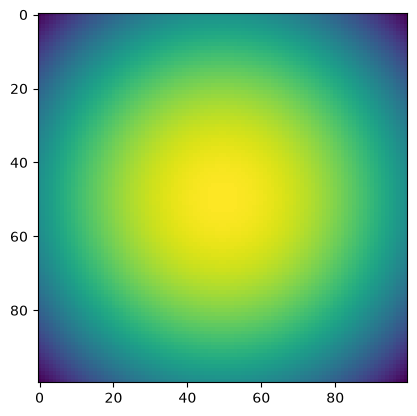

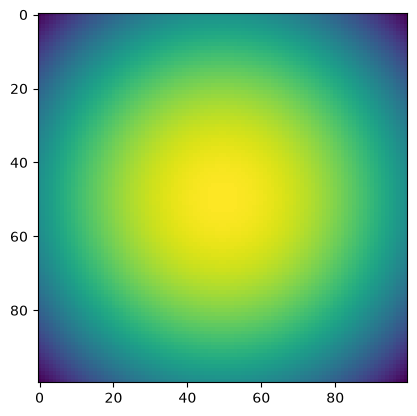

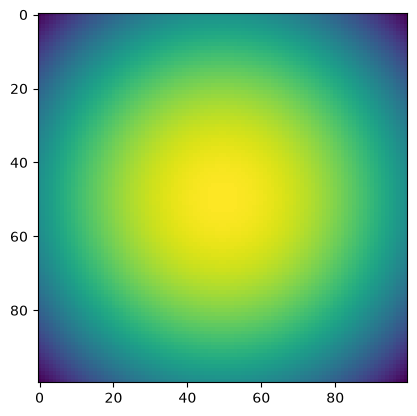

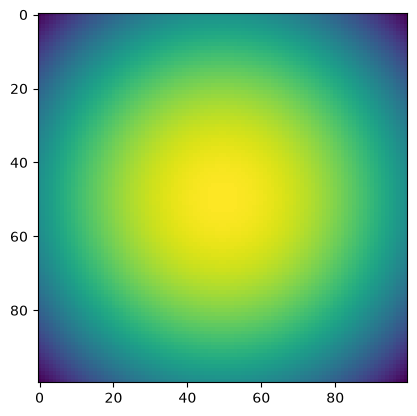

100 0.14765489 time: 0.0039031505584716797
200 0.13381016 time: 0.0020613670349121094
300 0.13435459 time: 0.0020062923431396484
400 0.14081347 time: 0.0033898353576660156
500 0.15985662 time: 0.003362894058227539
600 0.13231385 time: 0.0020112991333007812
700 0.121714674 time: 0.0019521713256835938
800 0.12721577 time: 0.003701448440551758
900 0.14202137 time: 0.0021791458129882812
1000 0.11760258 time: 0.002146482467651367


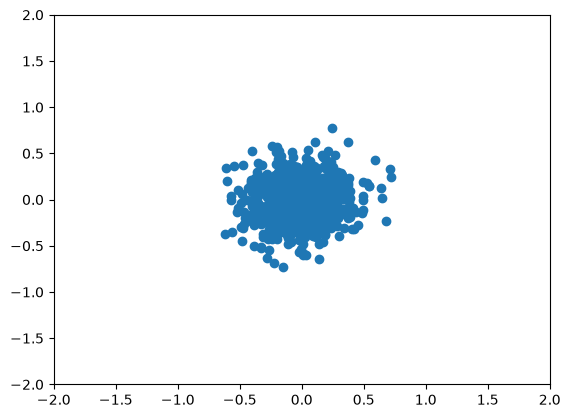

TEST 1000 logpx -144.73602


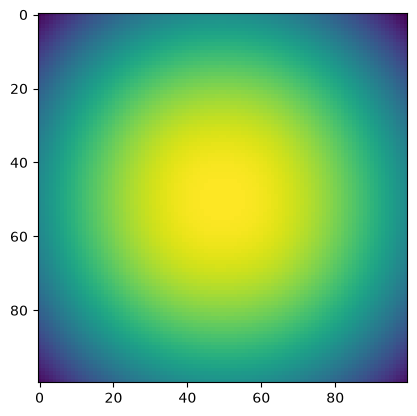

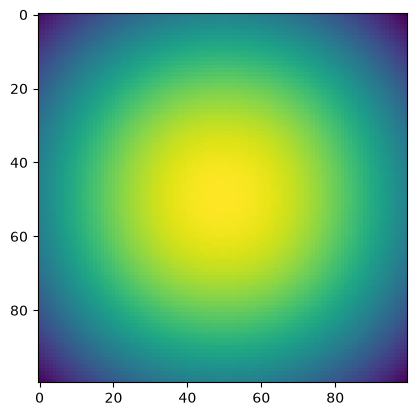

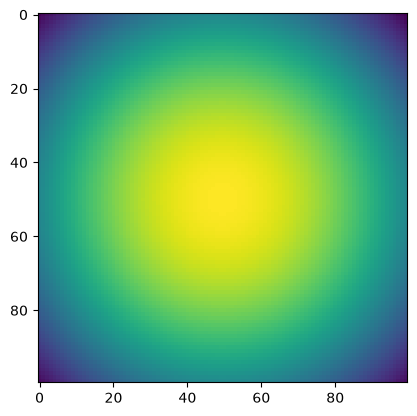

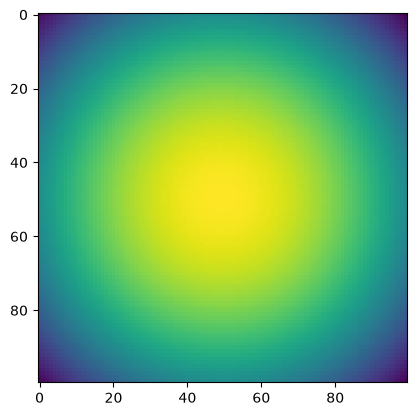

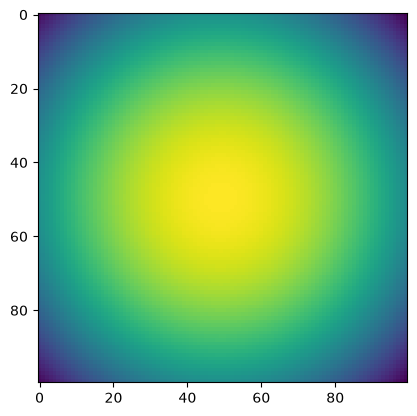

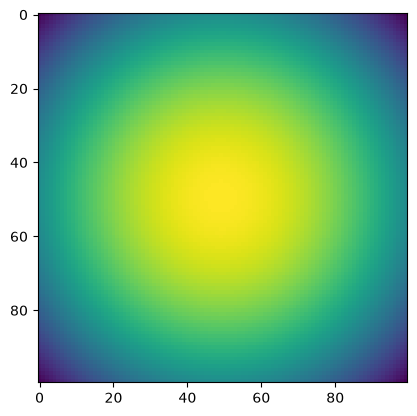

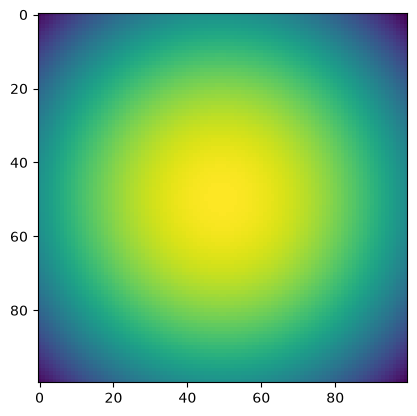

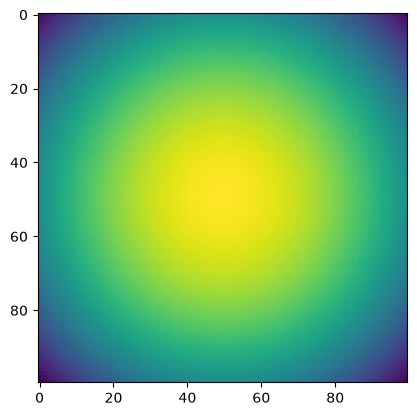

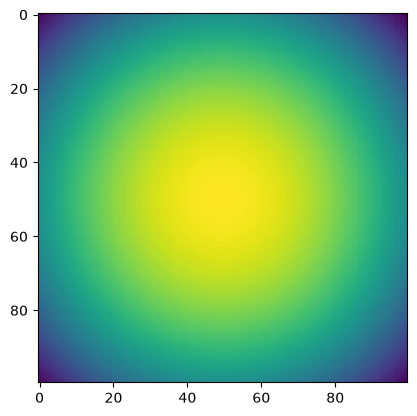

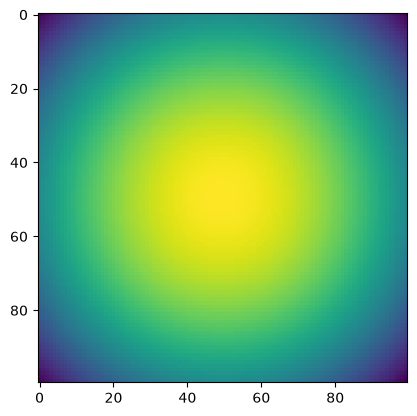

1100 0.15574811 time: 0.002140522003173828
1200 0.15178415 time: 0.0020530223846435547
1300 0.12965037 time: 0.0026464462280273438
1400 0.121528685 time: 0.0017969608306884766
1500 0.1230925 time: 0.0025055408477783203
1600 0.11333168 time: 0.003329753875732422
1700 0.13407667 time: 0.003193378448486328
1800 0.14435093 time: 0.0018329620361328125
1900 0.12940851 time: 0.0018701553344726562
2000 0.12251204 time: 0.0018532276153564453


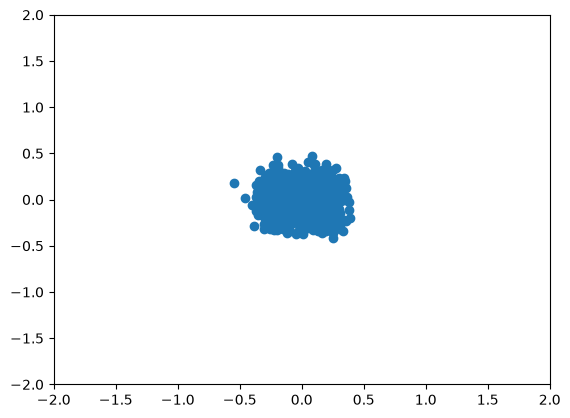

TEST 2000 logpx -19.698631


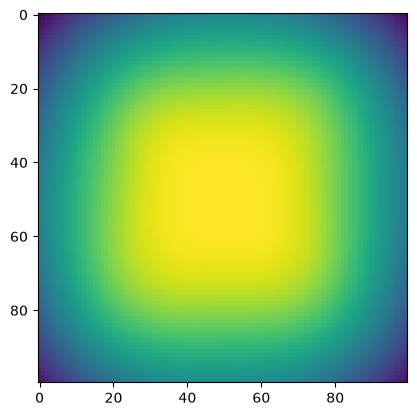

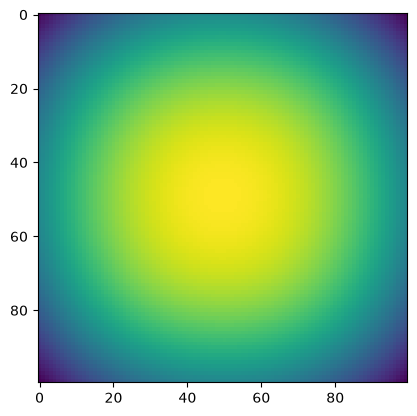

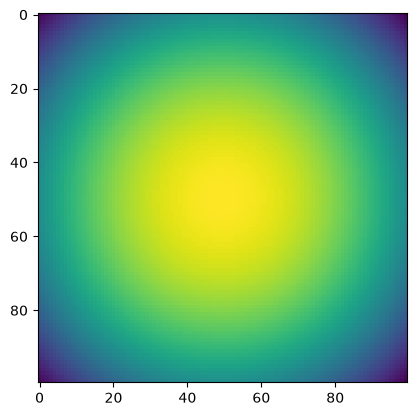

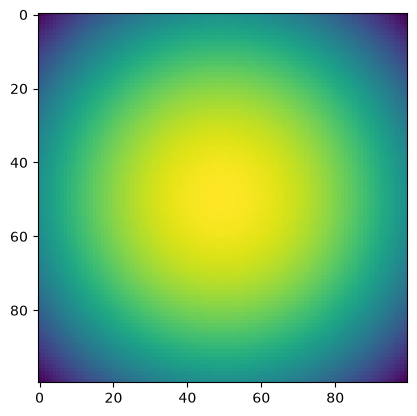

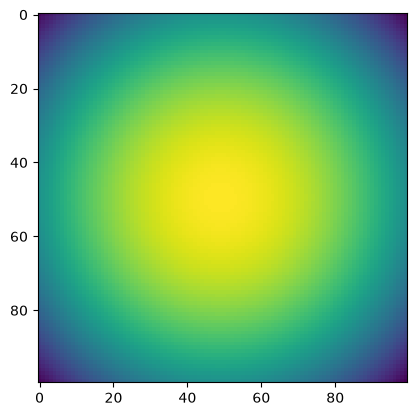

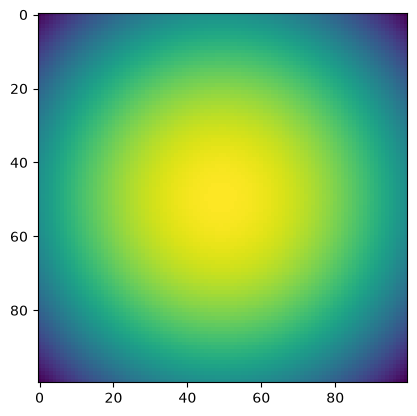

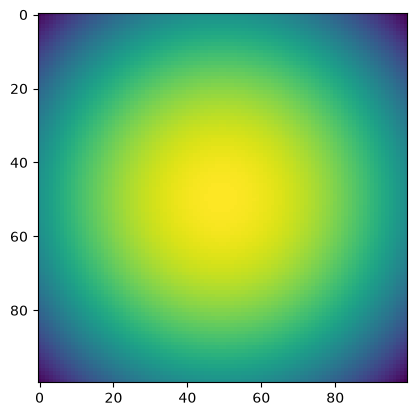

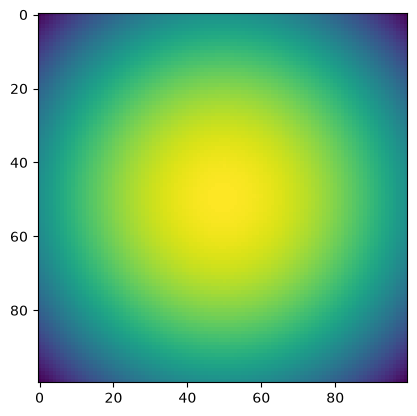

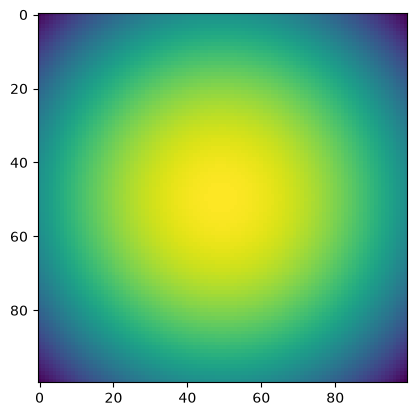

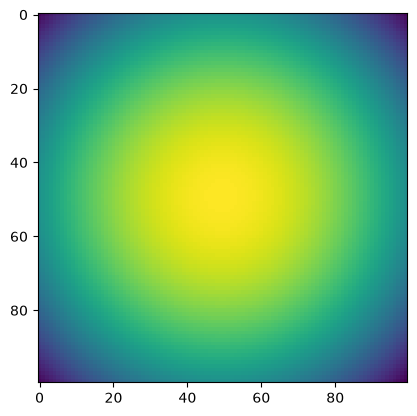

2100 0.14794989 time: 0.0019304752349853516
2200 0.14122449 time: 0.0022721290588378906
2300 0.1408296 time: 0.0020062923431396484
2400 0.13328502 time: 0.001993894577026367
2500 0.13445257 time: 0.0020241737365722656
2600 0.13851069 time: 0.0018699169158935547
2700 0.13398272 time: 0.0018312931060791016
2800 0.12942313 time: 0.0018029212951660156
2900 0.15080656 time: 0.0017998218536376953
3000 0.14459155 time: 0.0017499923706054688


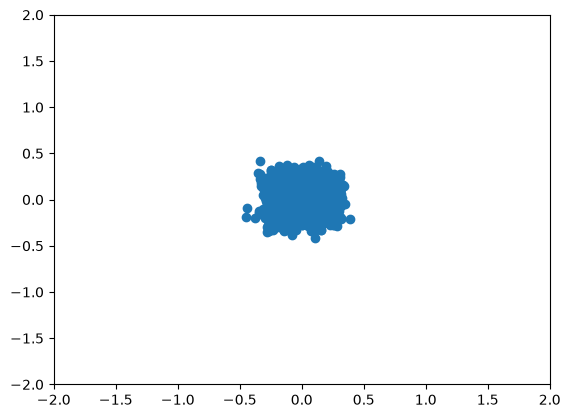

TEST 3000 logpx -2.023376


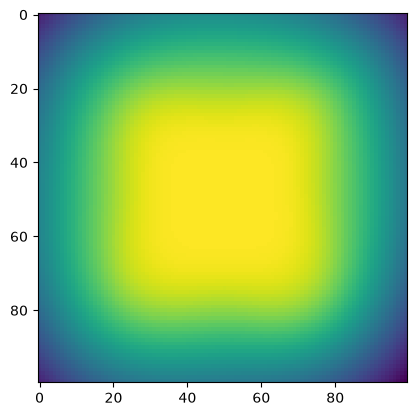

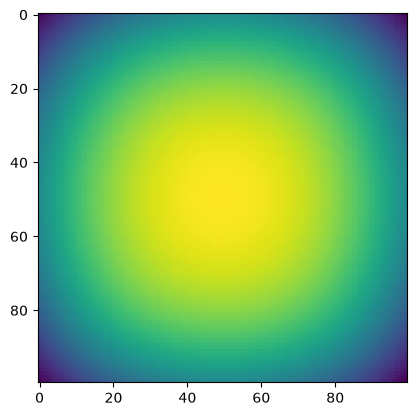

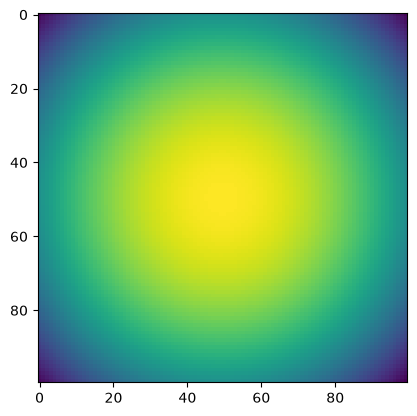

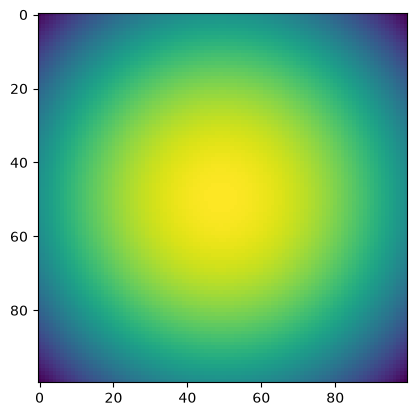

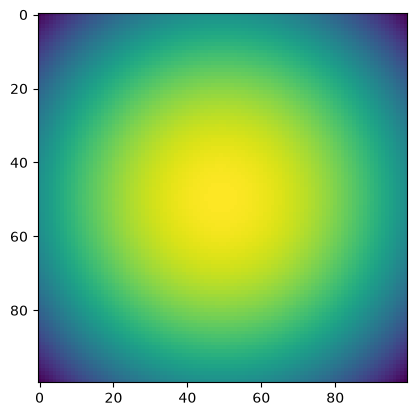

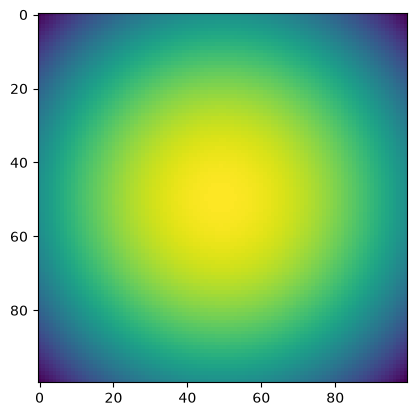

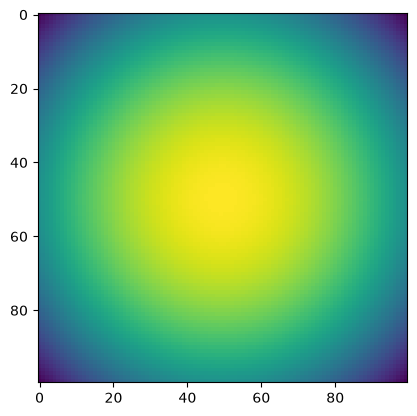

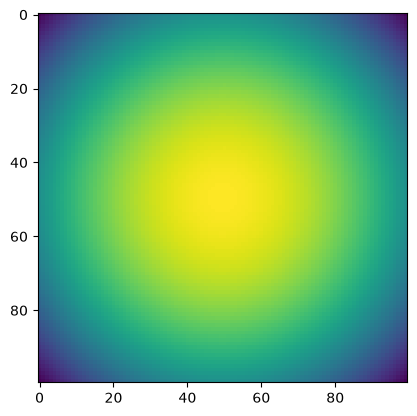

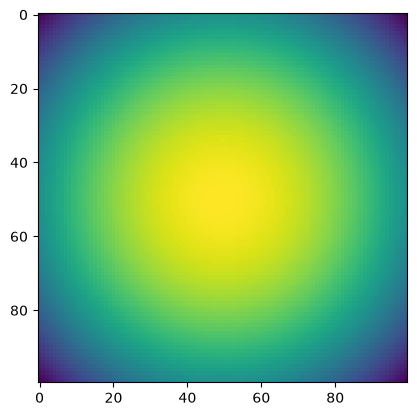

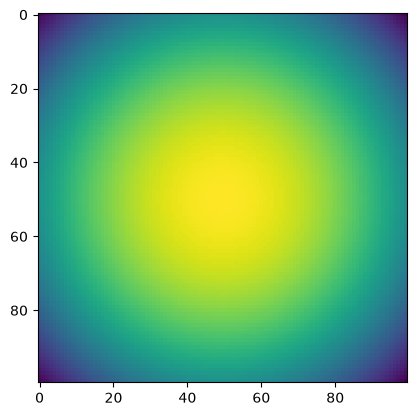

3100 0.12991257 time: 0.0022351741790771484
3200 0.12626883 time: 0.003565073013305664
3300 0.10809122 time: 0.0018832683563232422
3400 0.1289053 time: 0.0018389225006103516
3500 0.12611169 time: 0.0037674903869628906
3600 0.12818235 time: 0.0034639835357666016
3700 0.1418764 time: 0.0018684864044189453
3800 0.13873227 time: 0.0018651485443115234
3900 0.12752819 time: 0.0033228397369384766
4000 0.1450427 time: 0.0019071102142333984


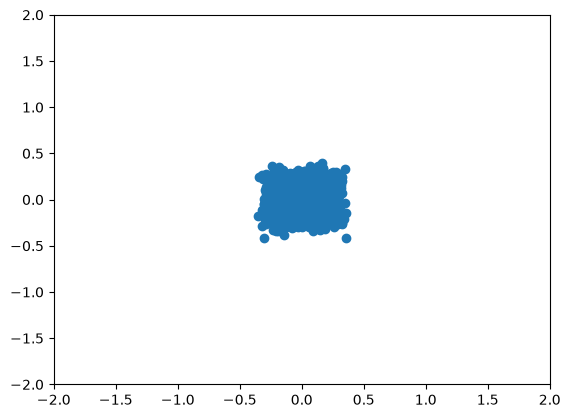

TEST 4000 logpx 0.55997944


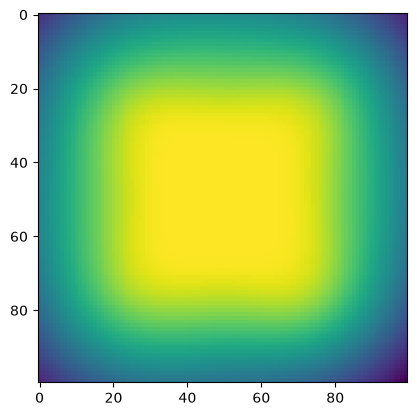

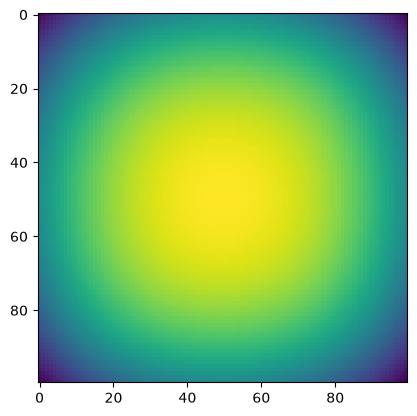

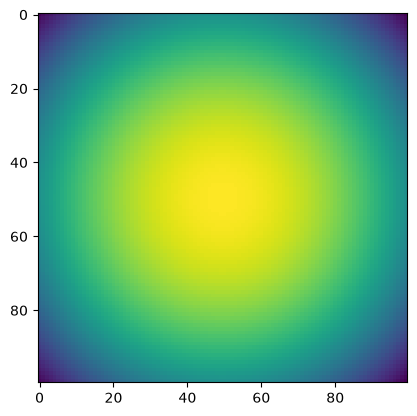

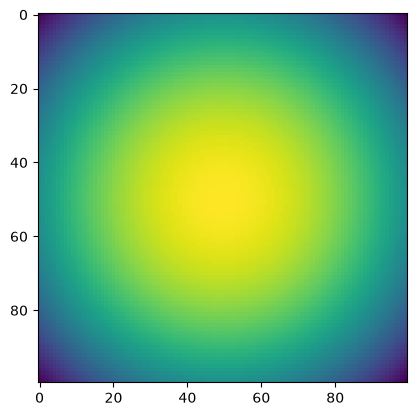

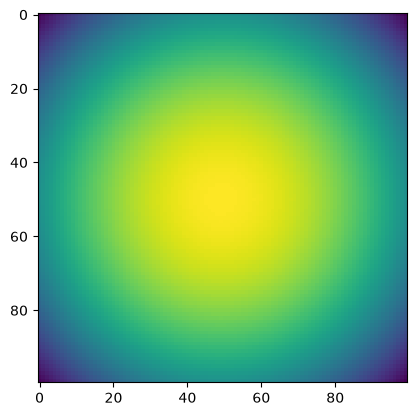

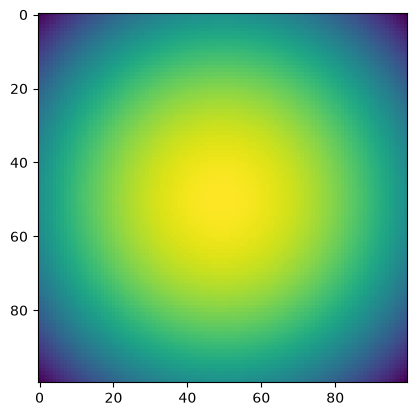

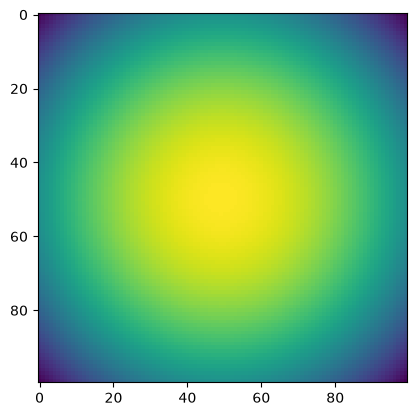

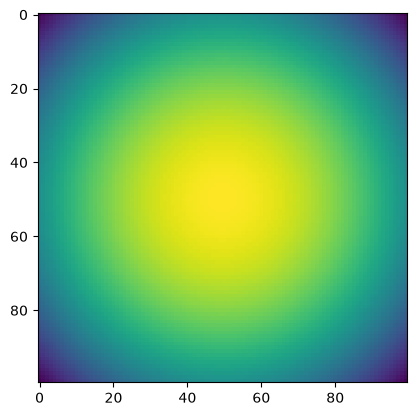

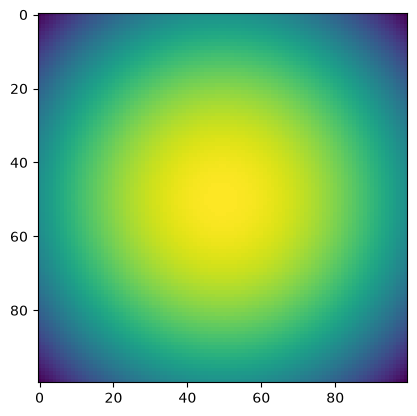

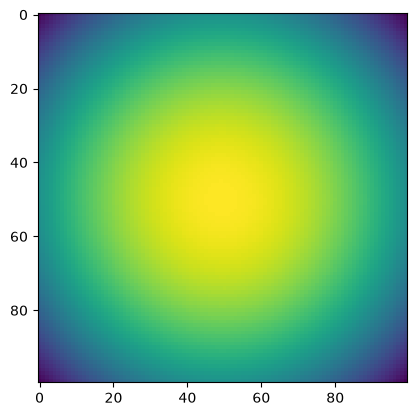

4100 0.12644292 time: 0.0018377304077148438
4200 0.13008857 time: 0.0018429756164550781
4300 0.13672048 time: 0.0019073486328125
4400 0.13331002 time: 0.001957416534423828
4500 0.14137967 time: 0.0018775463104248047
4600 0.13580117 time: 0.0018544197082519531
4700 0.12459198 time: 0.0019290447235107422
4800 0.12436857 time: 0.002460956573486328
4900 0.14343844 time: 0.0035715103149414062
5000 0.14417222 time: 0.0019071102142333984


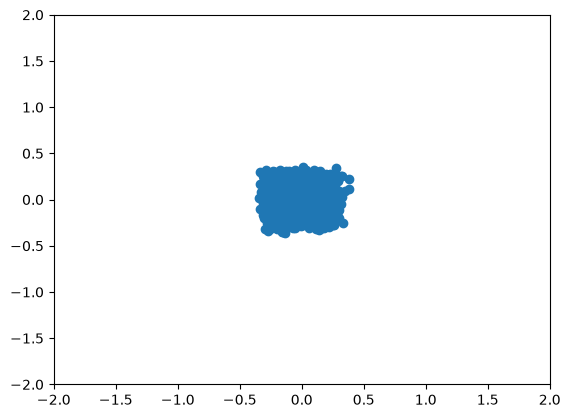

TEST 5000 logpx 0.9183976


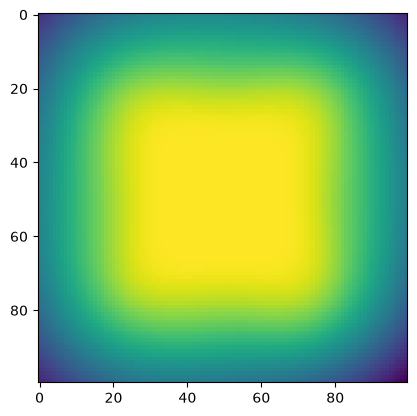

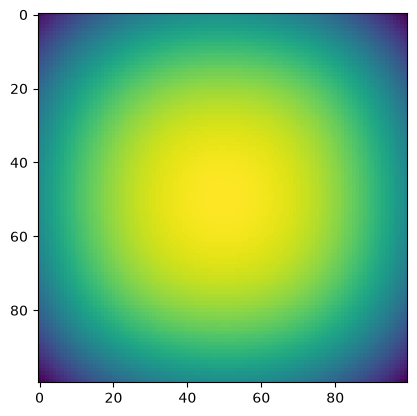

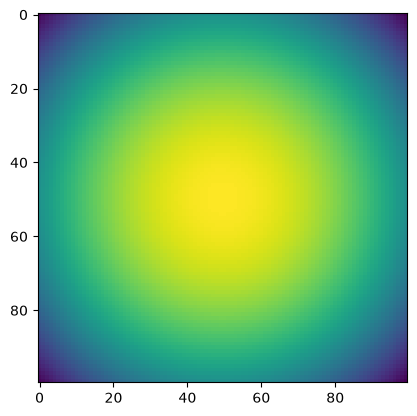

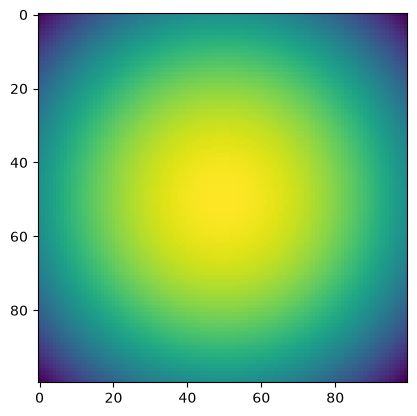

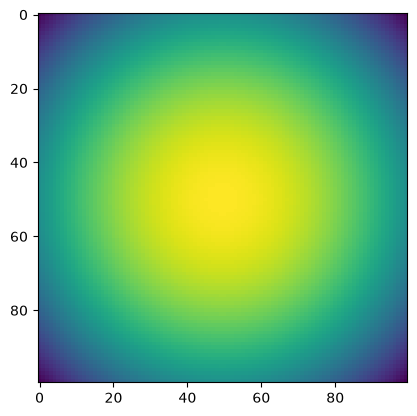

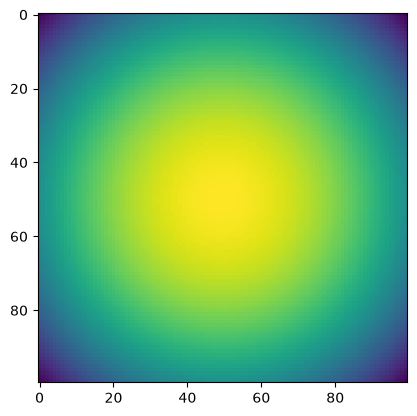

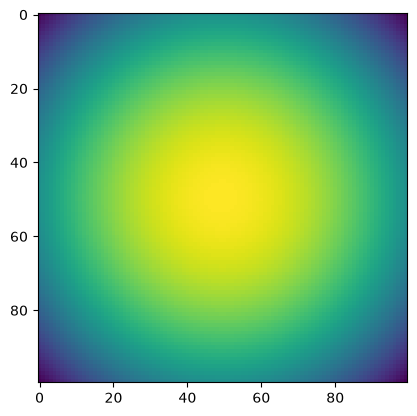

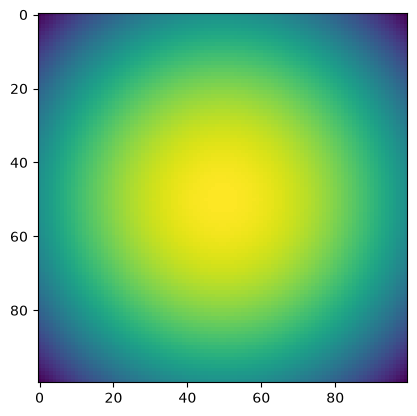

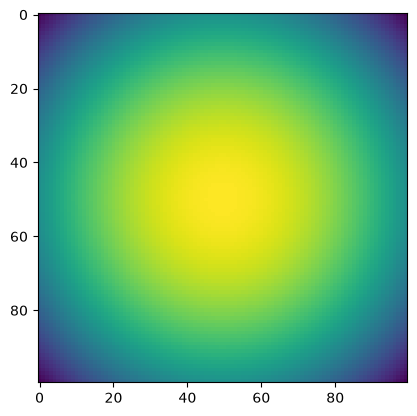

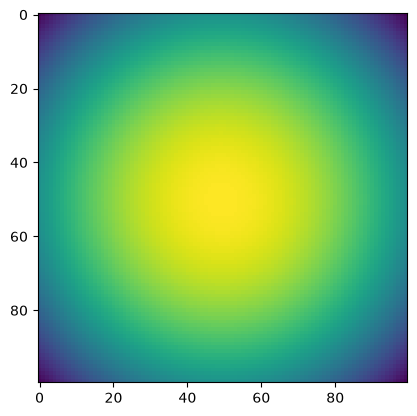

5100 0.15351702 time: 0.0033881664276123047
5200 0.14704482 time: 0.0019268989562988281
5300 0.13004966 time: 0.001965045928955078
5400 0.16211179 time: 0.0018377304077148438
5500 0.1299144 time: 0.0017859935760498047
5600 0.115866035 time: 0.003407001495361328
5700 0.14347477 time: 0.0018475055694580078
5800 0.1186825 time: 0.002111673355102539
5900 0.12722145 time: 0.0019922256469726562
6000 0.15005918 time: 0.0018639564514160156


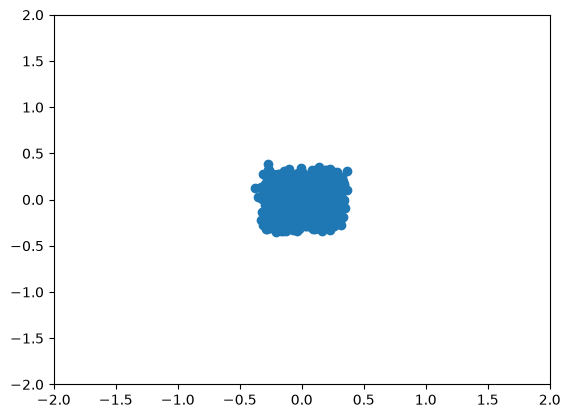

TEST 6000 logpx 0.9098855


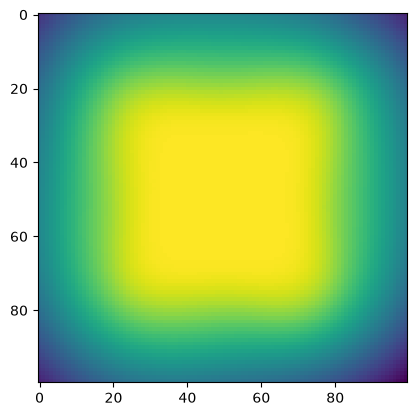

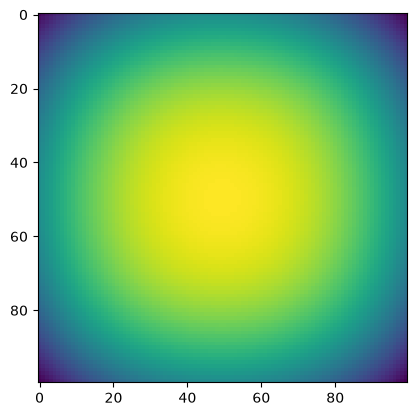

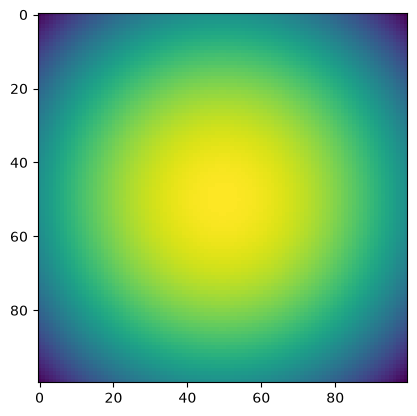

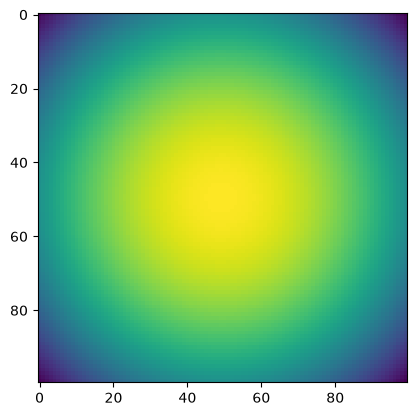

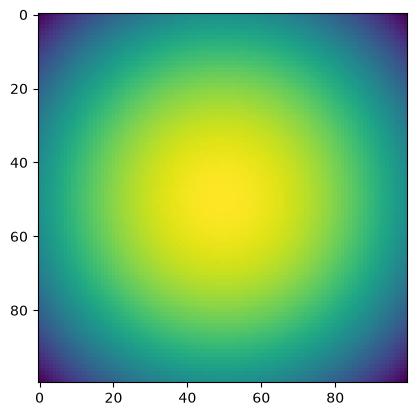

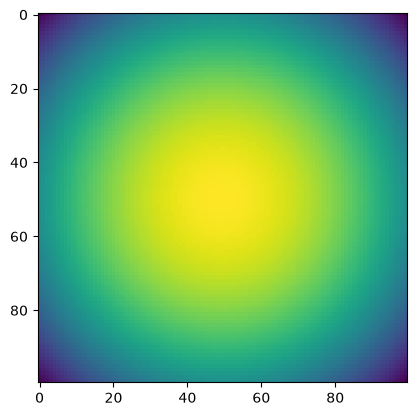

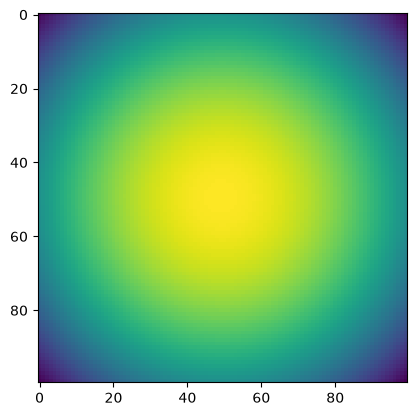

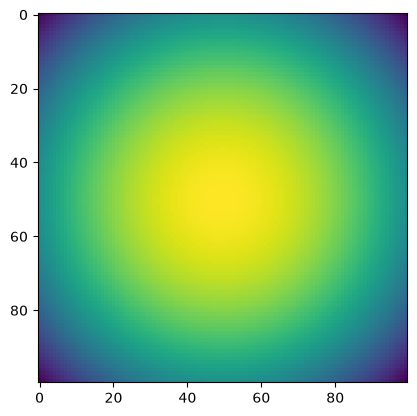

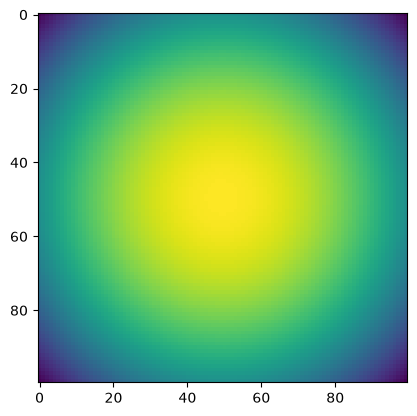

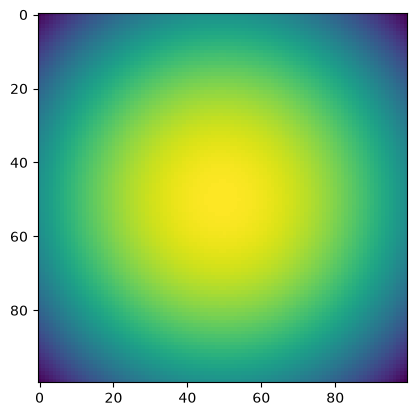

6100 0.120159425 time: 0.0036928653717041016
6200 0.12599263 time: 0.0032002925872802734
6300 0.13062035 time: 0.0017843246459960938
6400 0.15571237 time: 0.0017621517181396484
6500 0.12826528 time: 0.004025936126708984
6600 0.1171136 time: 0.0018169879913330078
6700 0.13098939 time: 0.0018587112426757812
6800 0.13275376 time: 0.0028531551361083984
6900 0.12543152 time: 0.0019397735595703125
7000 0.12154119 time: 0.0018475055694580078


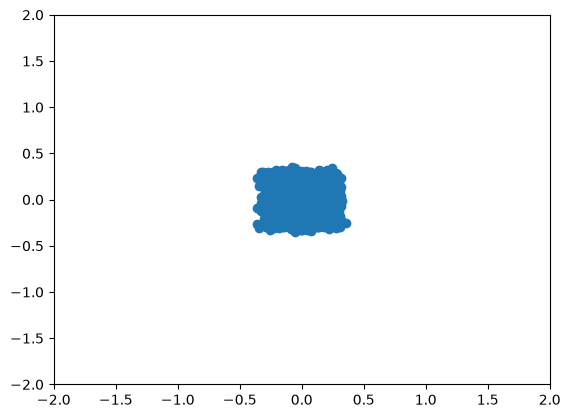

TEST 7000 logpx 0.957458


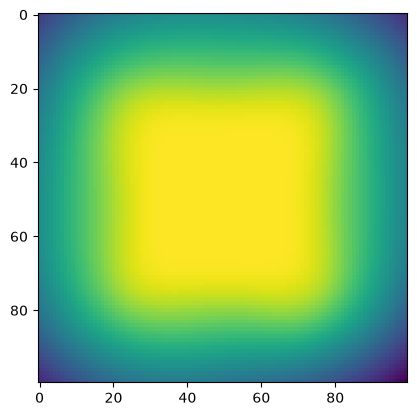

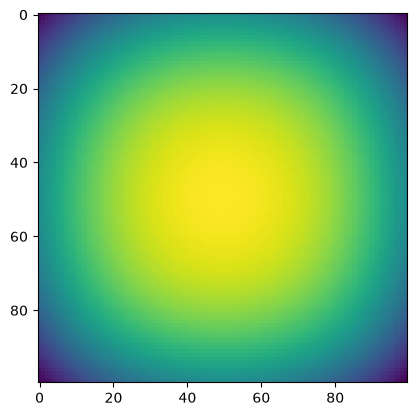

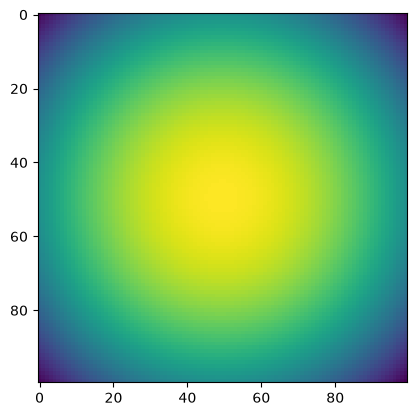

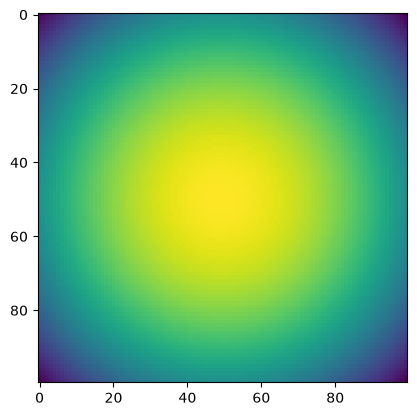

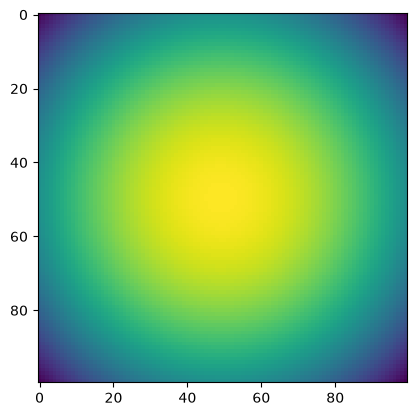

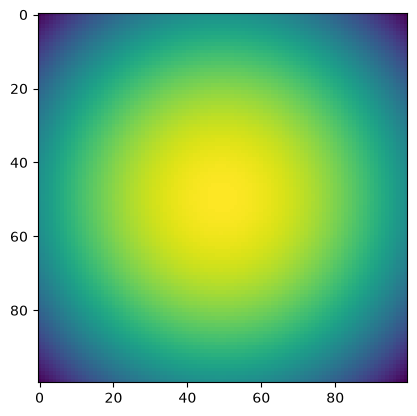

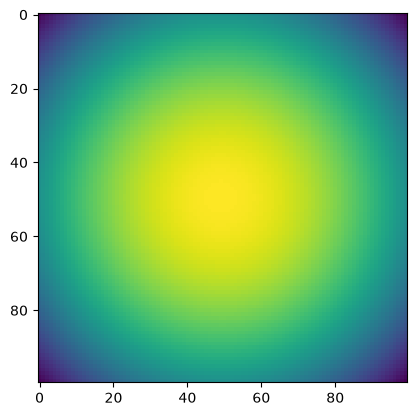

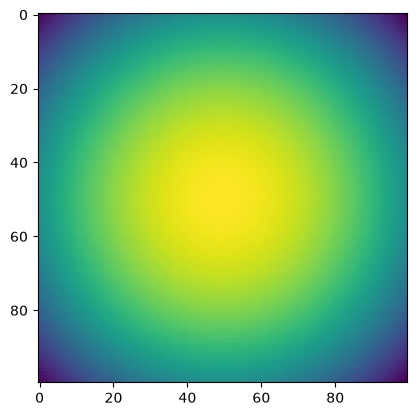

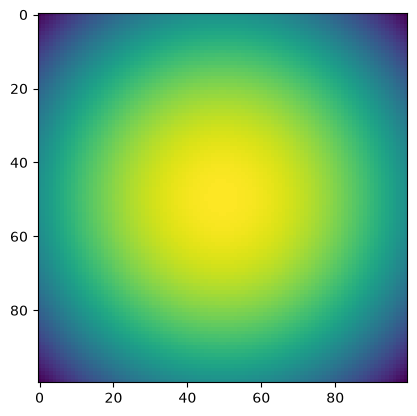

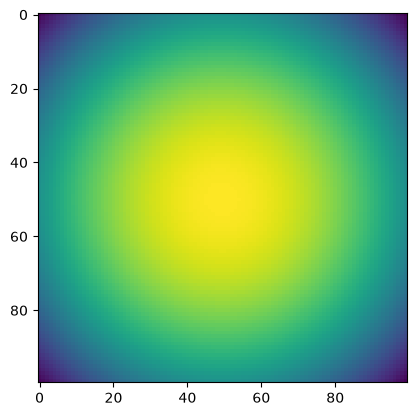

7100 0.1494526 time: 0.002095460891723633
7200 0.13173859 time: 0.003556489944458008
7300 0.14356153 time: 0.0023610591888427734
7400 0.121798426 time: 0.0019507408142089844
7500 0.13902186 time: 0.0018434524536132812
7600 0.12301839 time: 0.0018236637115478516
7700 0.14128453 time: 0.0024313926696777344
7800 0.12064959 time: 0.0017745494842529297
7900 0.13000636 time: 0.0018558502197265625
8000 0.14290076 time: 0.002546072006225586


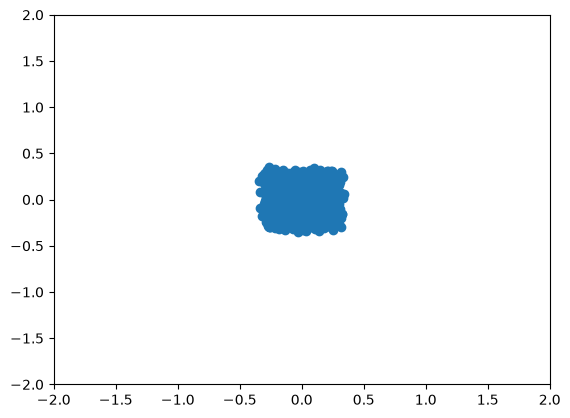

TEST 8000 logpx 1.0760559


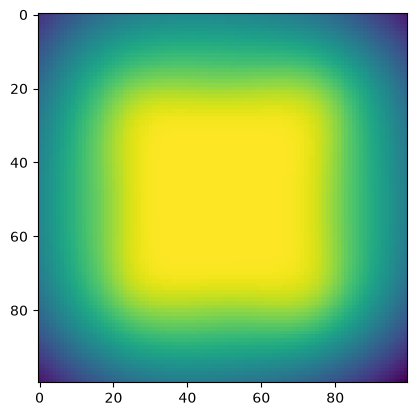

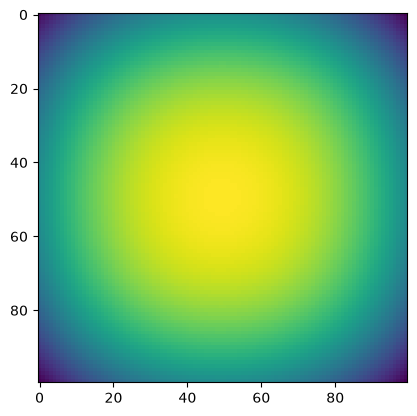

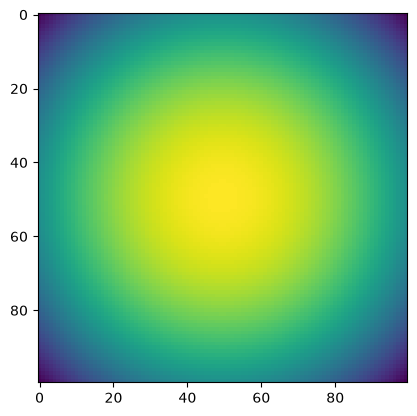

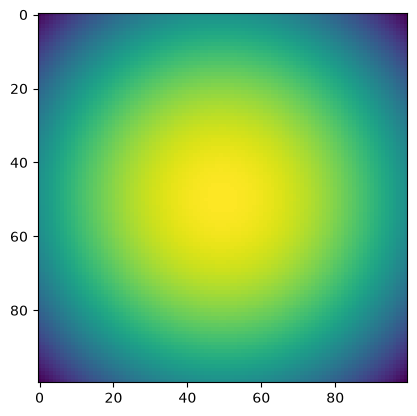

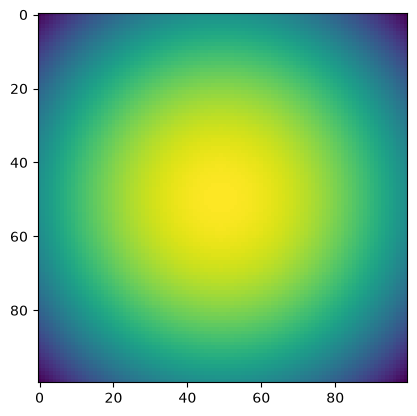

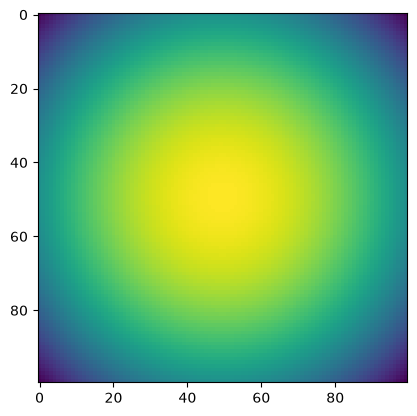

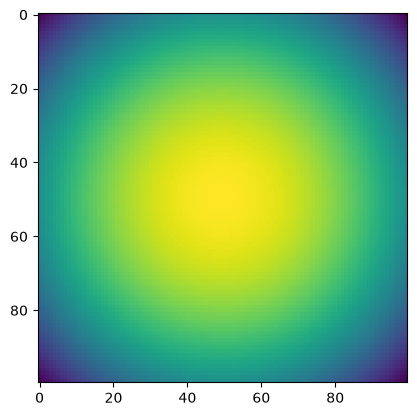

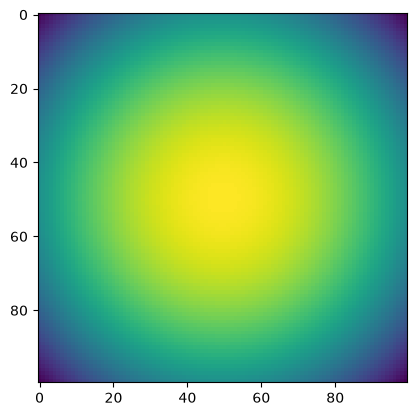

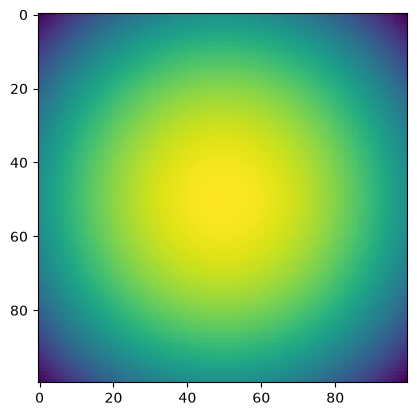

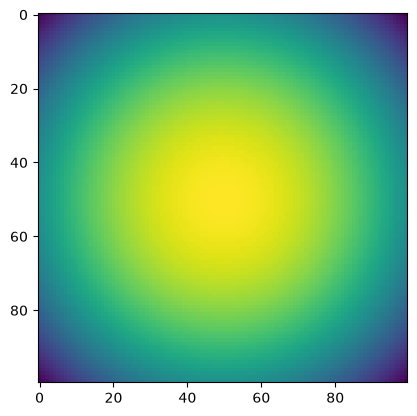

8100 0.14547049 time: 0.0033576488494873047
8200 0.11799269 time: 0.0019342899322509766
8300 0.13860863 time: 0.0033206939697265625
8400 0.14760964 time: 0.0035619735717773438
8500 0.12686253 time: 0.0036897659301757812
8600 0.1237737 time: 0.0021326541900634766
8700 0.1159024 time: 0.0022470951080322266
8800 0.13799073 time: 0.0031690597534179688
8900 0.11874258 time: 0.0018033981323242188
9000 0.13812552 time: 0.0018279552459716797


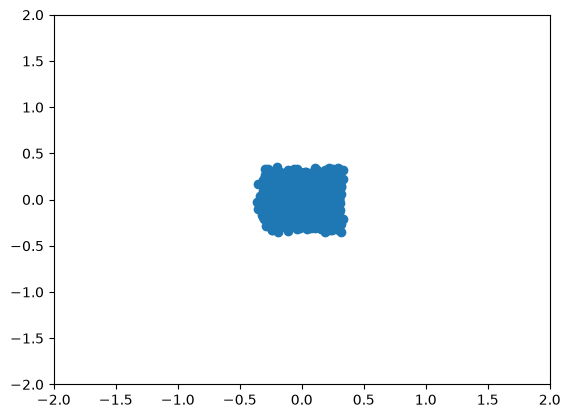

TEST 9000 logpx 0.9884672


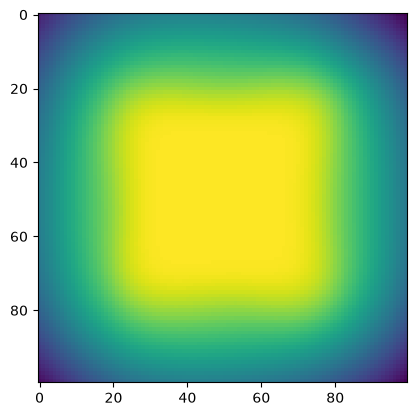

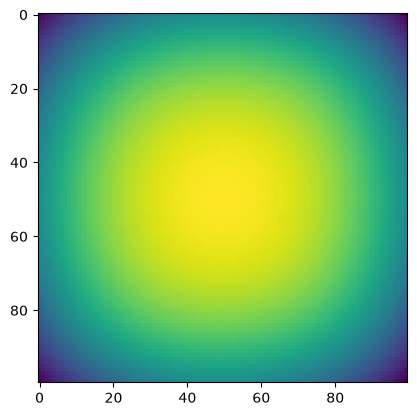

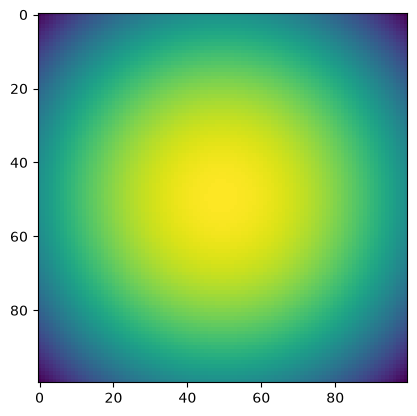

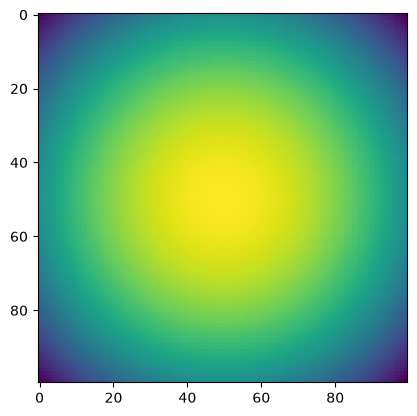

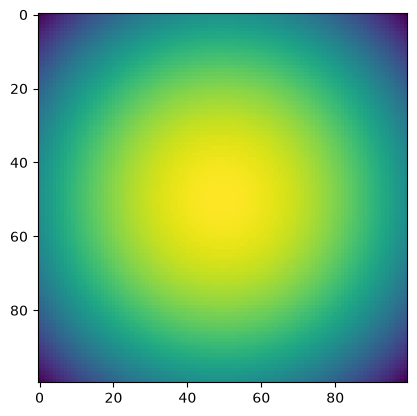

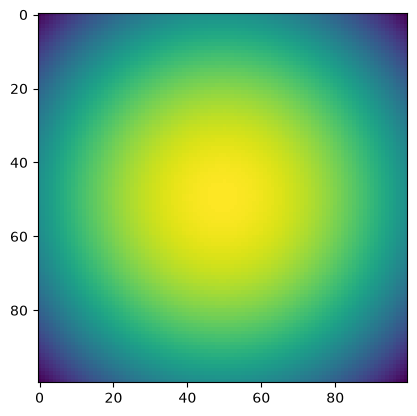

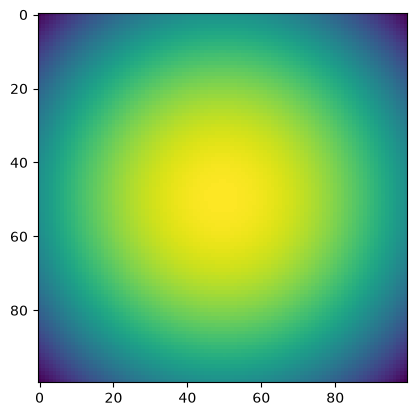

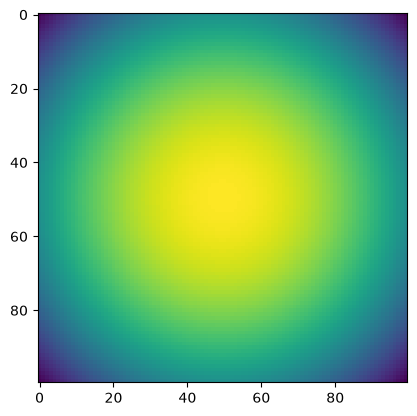

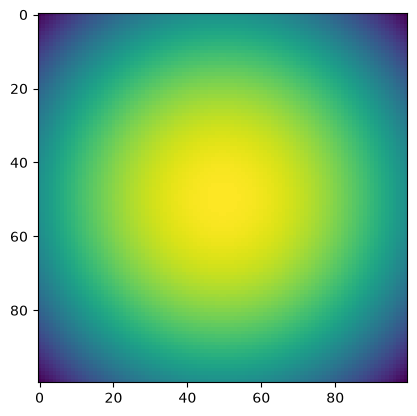

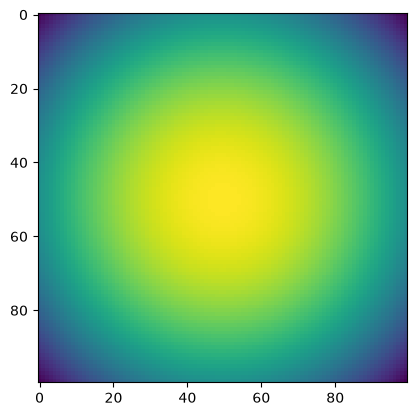

9100 0.12614927 time: 0.0019061565399169922
9200 0.11987472 time: 0.005259037017822266
9300 0.12455622 time: 0.002178668975830078
9400 0.1165551 time: 0.0020186901092529297
9500 0.13233164 time: 0.0018808841705322266
9600 0.13789915 time: 0.0038285255432128906
9700 0.12752195 time: 0.0034770965576171875
9800 0.1287539 time: 0.0020360946655273438
9900 0.117906034 time: 0.0018339157104492188
10000 0.15623292 time: 0.0020258426666259766


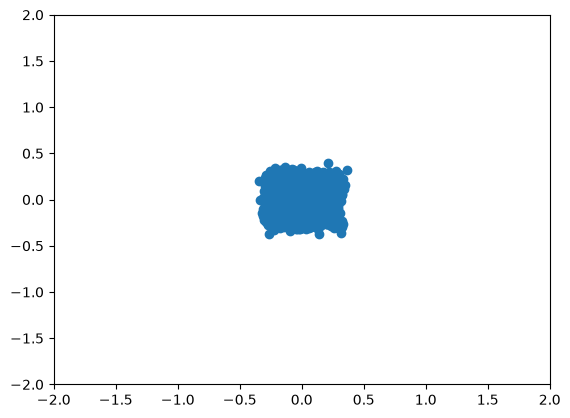

TEST 10000 logpx 1.0189723


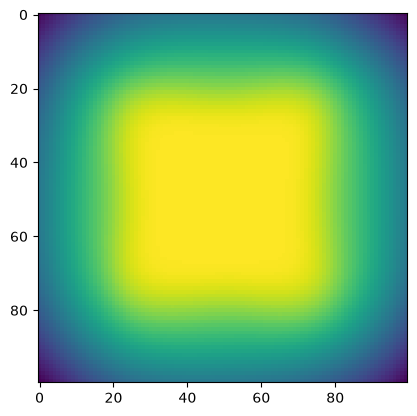

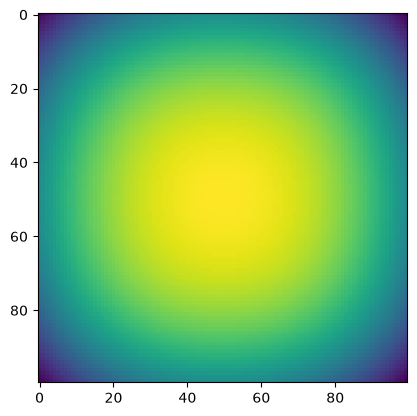

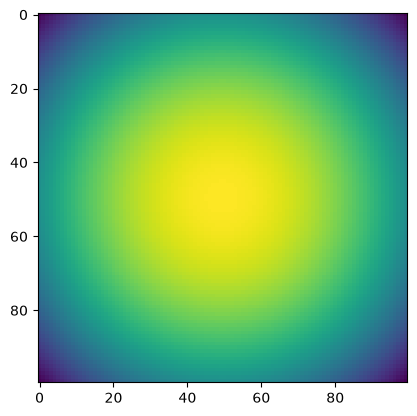

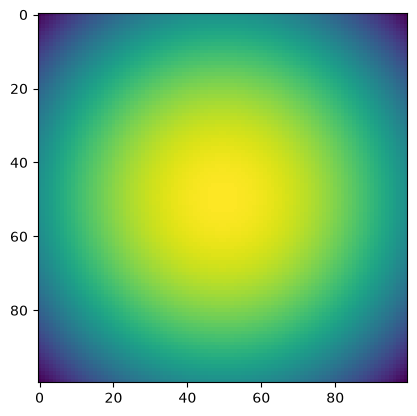

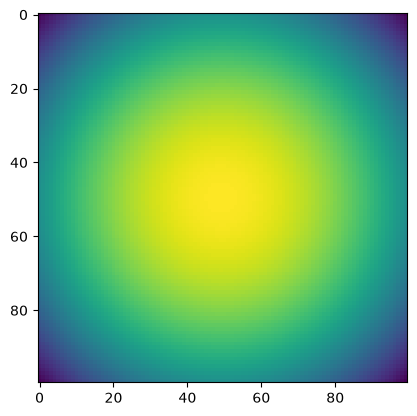

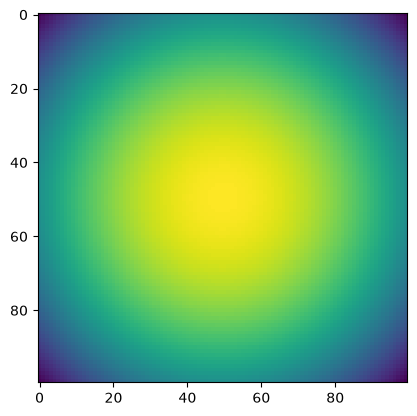

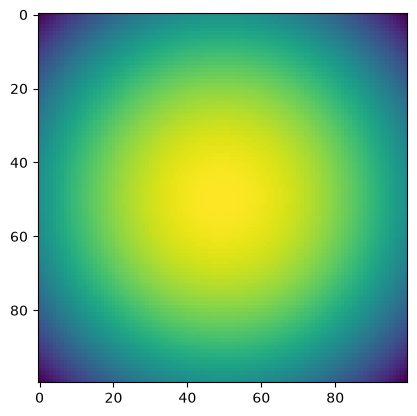

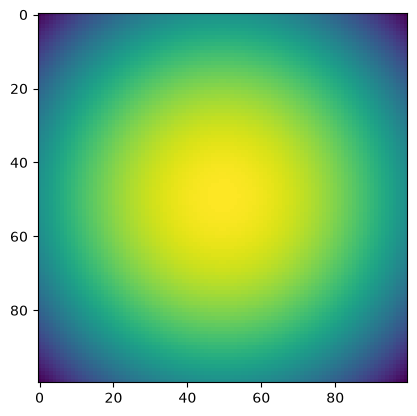

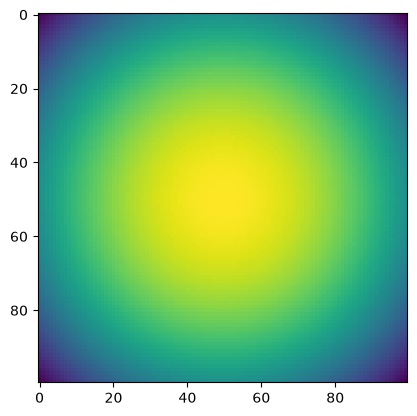

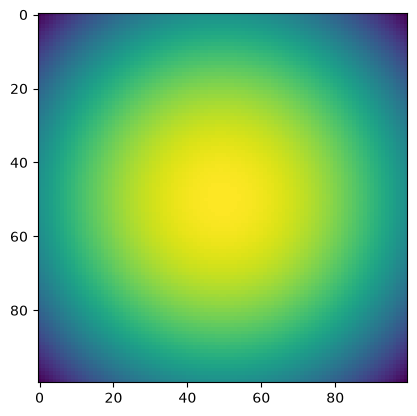

10100 0.13108566 time: 0.0030112266540527344
10200 0.13705695 time: 0.006776094436645508
10300 0.115053214 time: 0.001859903335571289
10400 0.122759074 time: 0.003760814666748047
10500 0.1327739 time: 0.0020914077758789062
10600 0.15344587 time: 0.0035953521728515625
10700 0.105619706 time: 0.0020952224731445312
10800 0.1293516 time: 0.001981496810913086
10900 0.13324116 time: 0.0025708675384521484
11000 0.11760695 time: 0.0027167797088623047


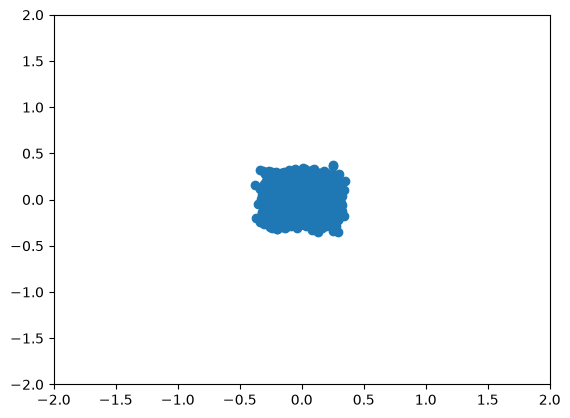

TEST 11000 logpx 1.0583801


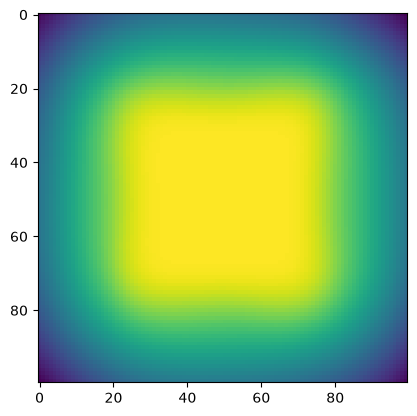

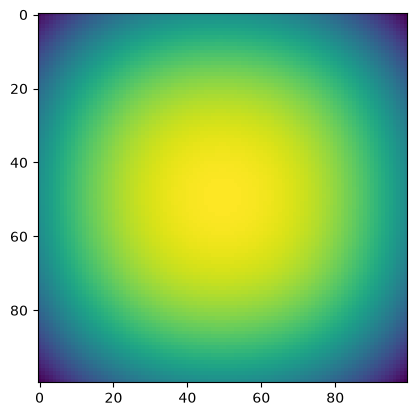

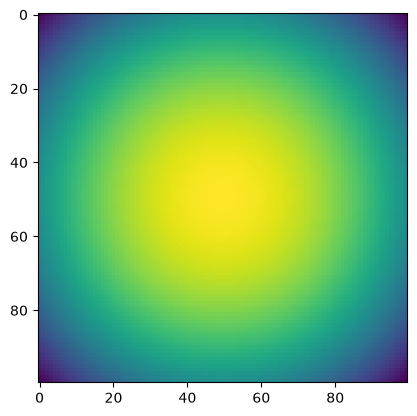

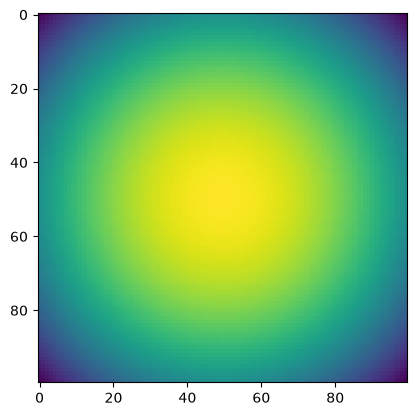

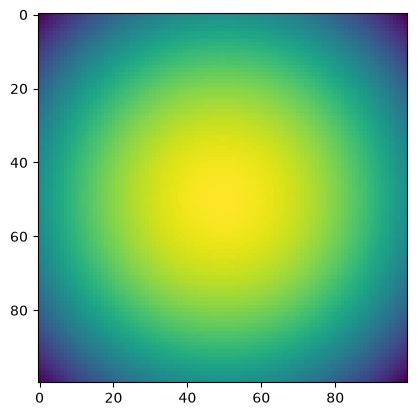

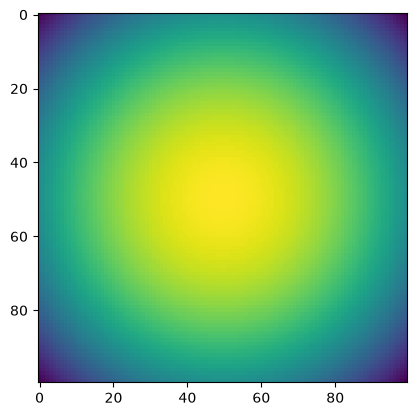

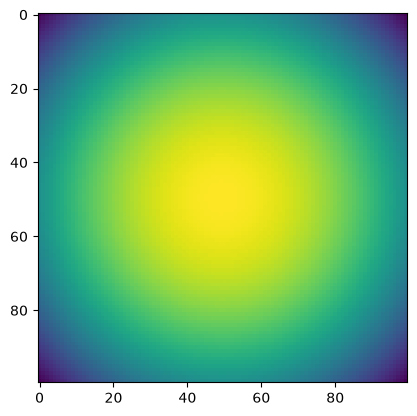

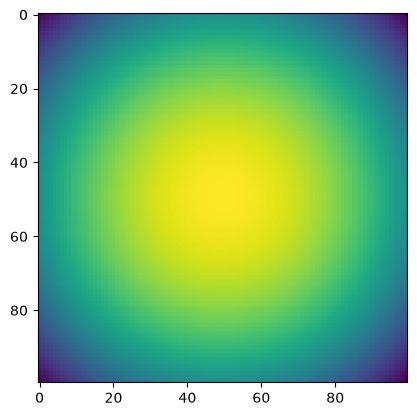

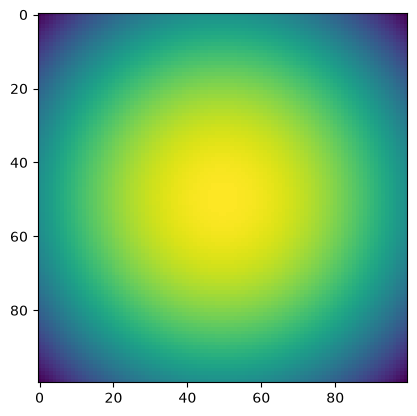

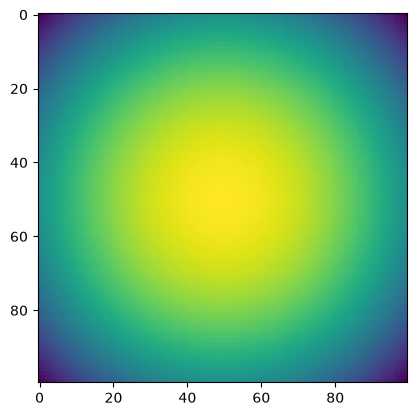

11100 0.11969363 time: 0.003491640090942383
11200 0.13815896 time: 0.0022628307342529297
11300 0.17002617 time: 0.0017883777618408203
11400 0.14790623 time: 0.0017886161804199219
11500 0.13907614 time: 0.0020503997802734375
11600 0.12358023 time: 0.0018506050109863281
11700 0.15244904 time: 0.0031404495239257812
11800 0.13245496 time: 0.0017986297607421875
11900 0.15524478 time: 0.002167224884033203
12000 0.13153952 time: 0.001905679702758789


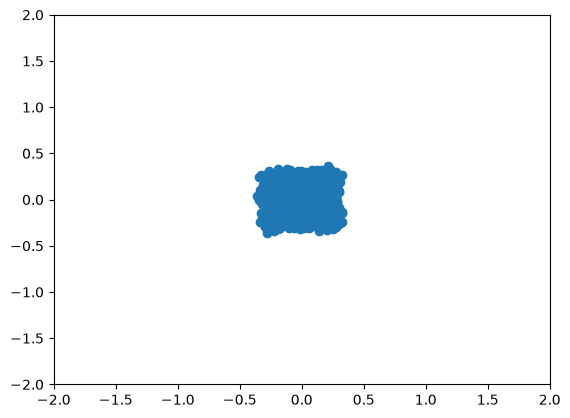

TEST 12000 logpx 0.9267504


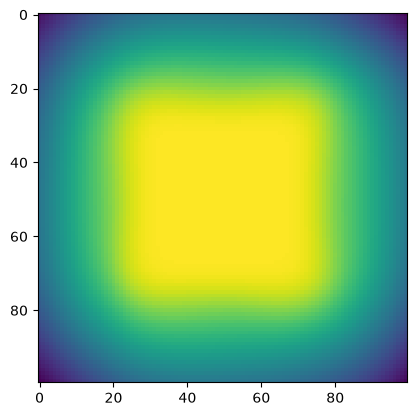

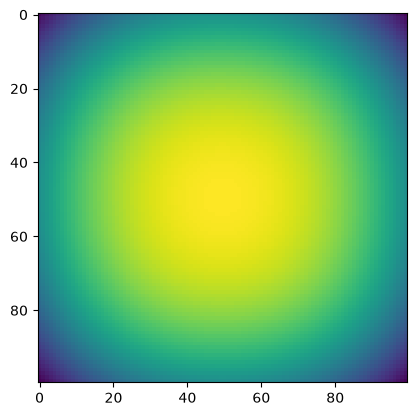

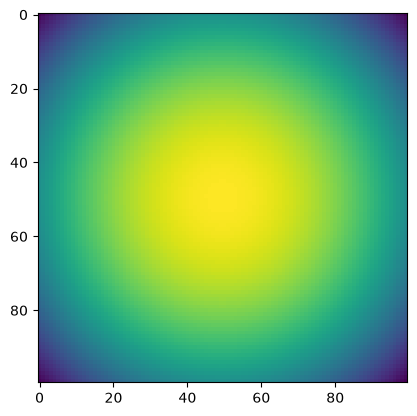

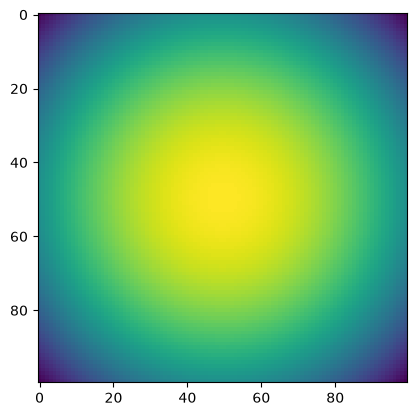

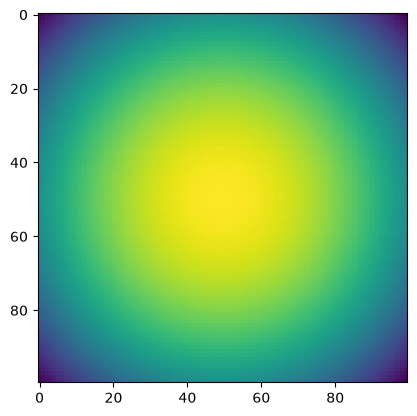

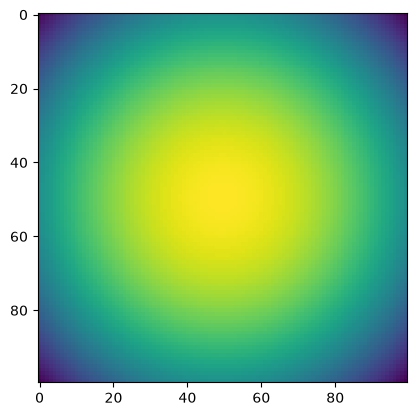

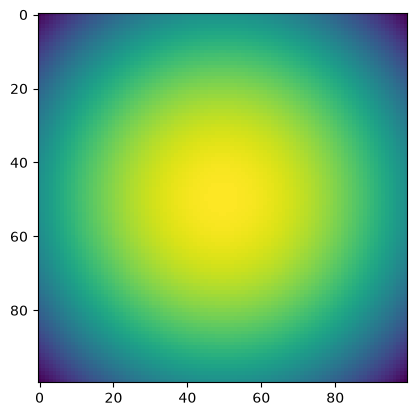

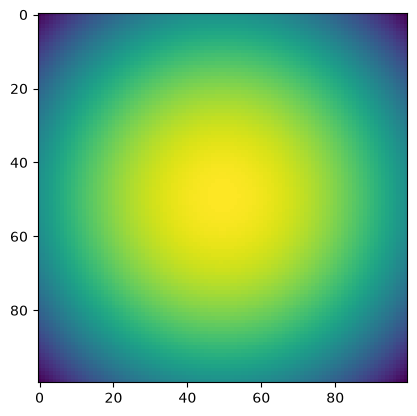

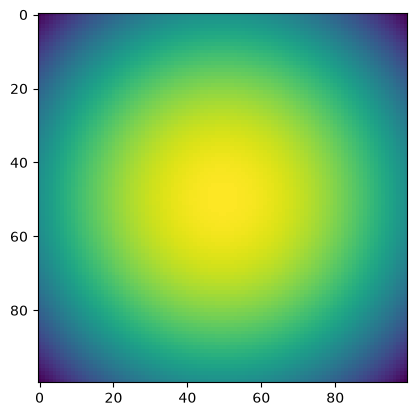

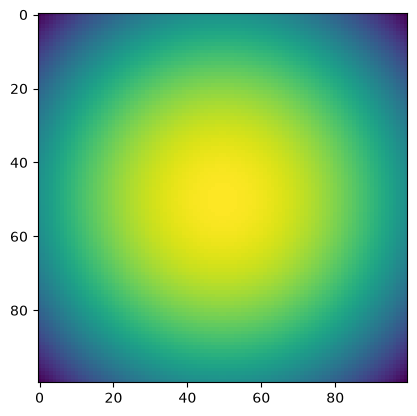

12100 0.14471224 time: 0.006572723388671875
12200 0.13297084 time: 0.002226591110229492
12300 0.13981974 time: 0.0019948482513427734
12400 0.13153897 time: 0.0019142627716064453
12500 0.1356226 time: 0.003519296646118164
12600 0.12704487 time: 0.003731966018676758
12700 0.13404866 time: 0.0021827220916748047
12800 0.1319975 time: 0.0019214153289794922
12900 0.15075728 time: 0.0019261837005615234
13000 0.13911438 time: 0.0019202232360839844


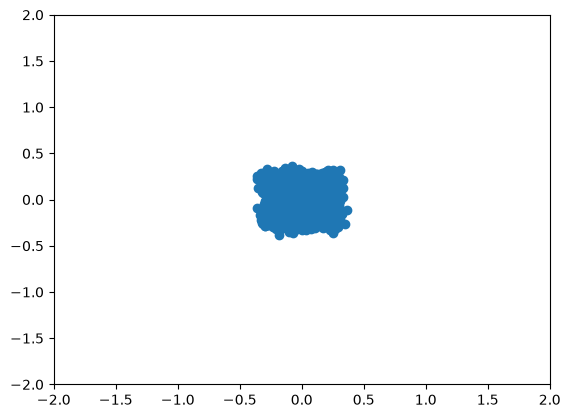

TEST 13000 logpx 1.0407677


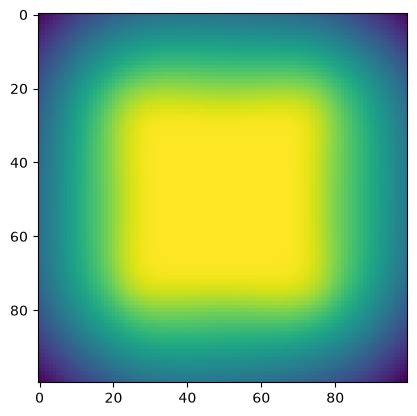

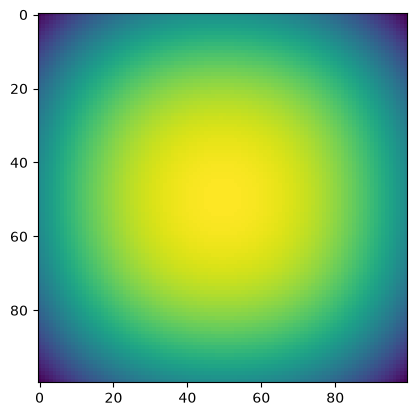

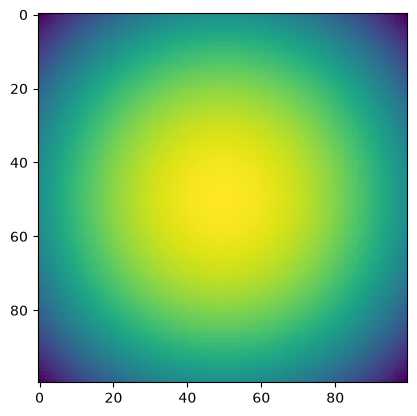

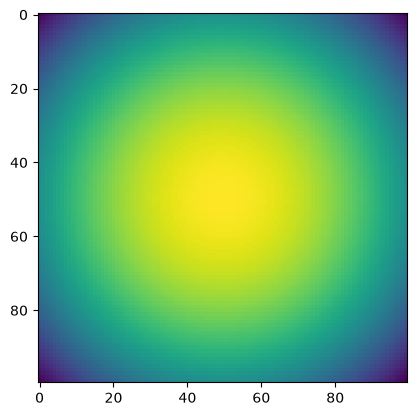

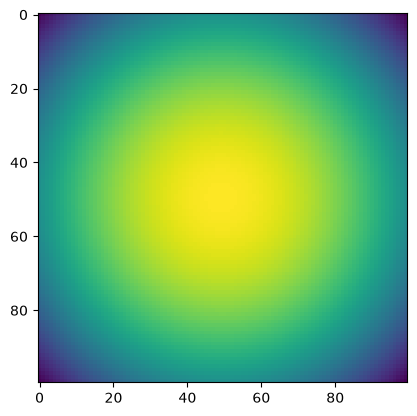

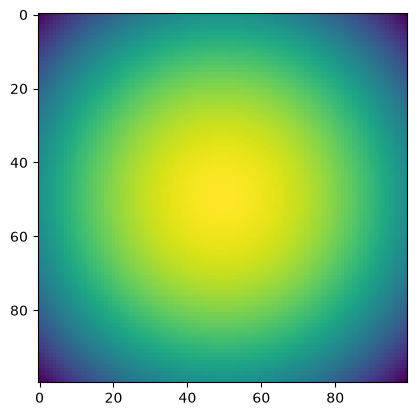

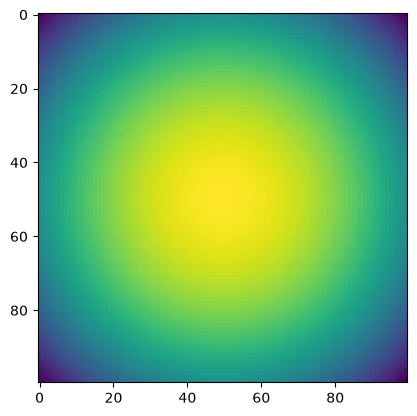

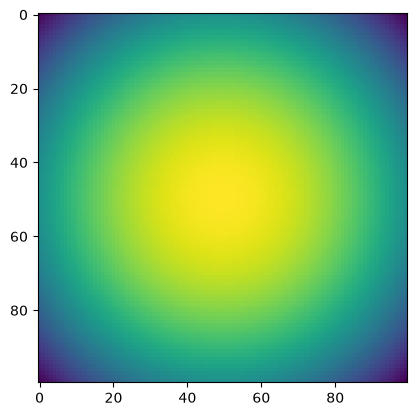

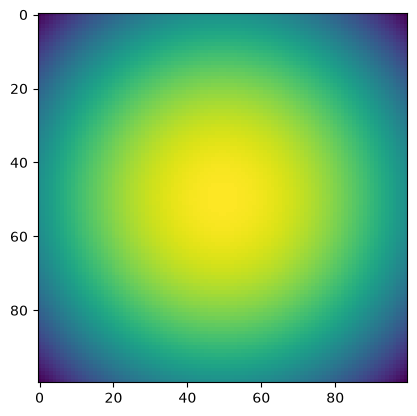

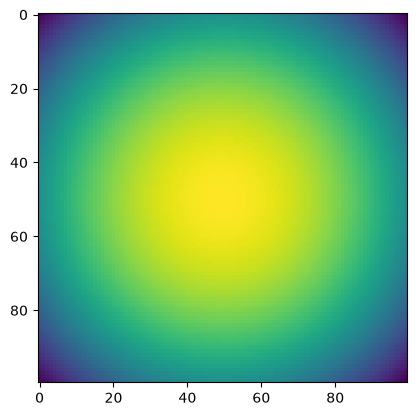

13100 0.11827546 time: 0.0036399364471435547
13200 0.12118751 time: 0.0052032470703125
13300 0.12294164 time: 0.0019960403442382812
13400 0.1302994 time: 0.0019021034240722656
13500 0.1349392 time: 0.0035505294799804688
13600 0.13474 time: 0.0017828941345214844
13700 0.13588922 time: 0.0019800662994384766
13800 0.14615013 time: 0.0028145313262939453
13900 0.1477353 time: 0.001916646957397461
14000 0.1375933 time: 0.001886129379272461


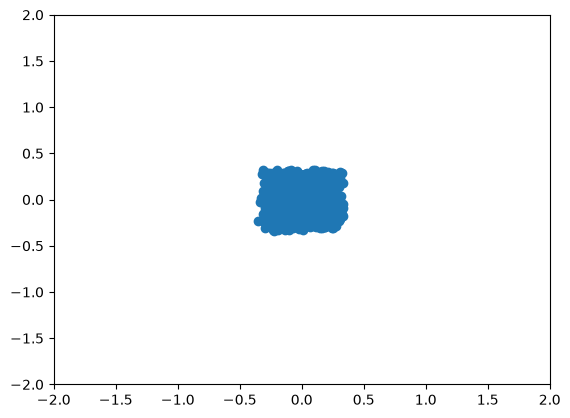

TEST 14000 logpx 0.9734247


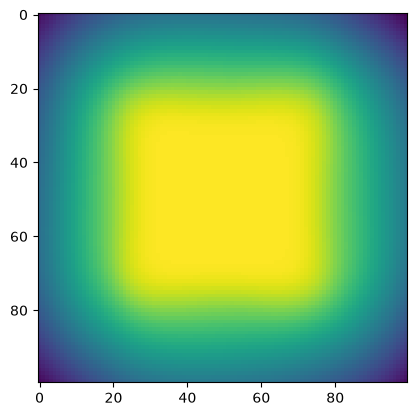

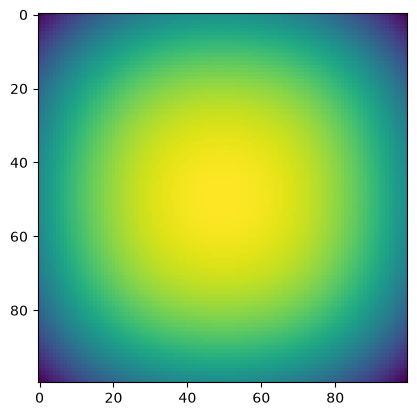

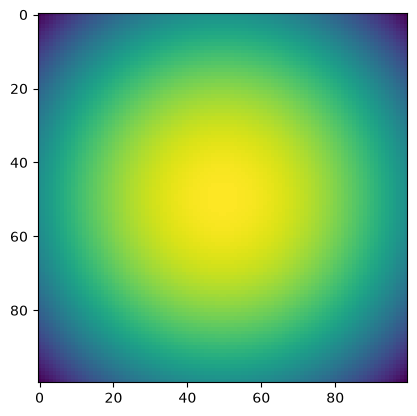

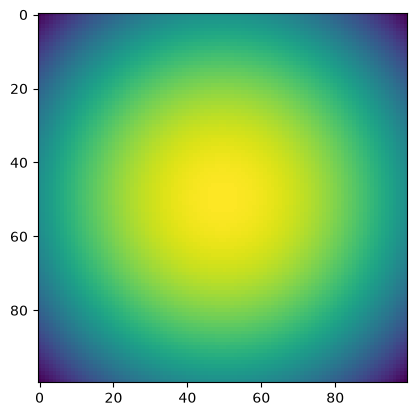

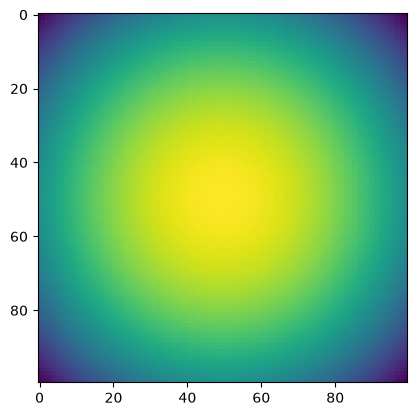

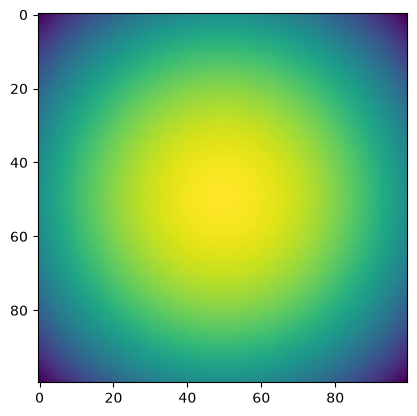

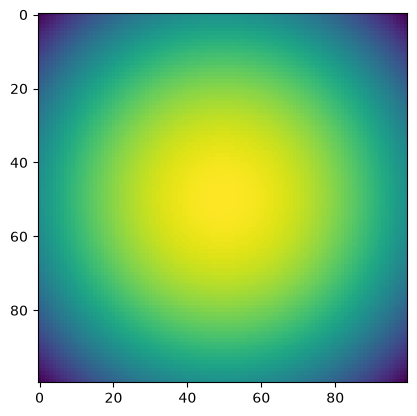

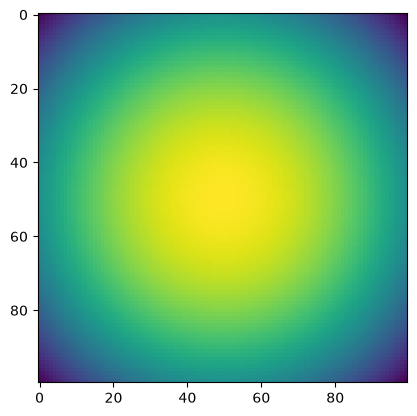

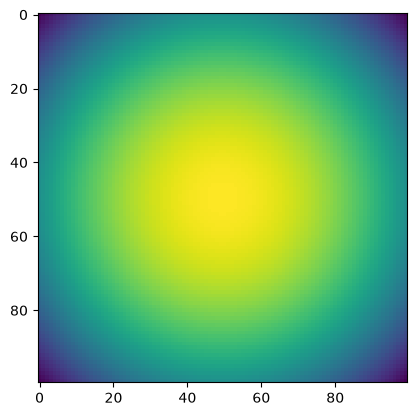

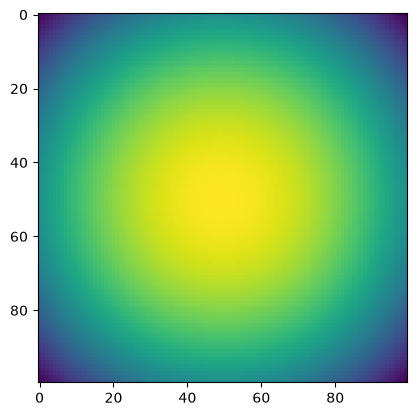

14100 0.11697796 time: 0.0018591880798339844
14200 0.13709494 time: 0.002325773239135742
14300 0.12156837 time: 0.002980947494506836
14400 0.1233814 time: 0.0020177364349365234
14500 0.14567837 time: 0.00391697883605957
14600 0.14767374 time: 0.0021195411682128906
14700 0.15127523 time: 0.0023276805877685547
14800 0.1467707 time: 0.0019626617431640625
14900 0.14077415 time: 0.0023255348205566406
15000 0.15867403 time: 0.0035936832427978516


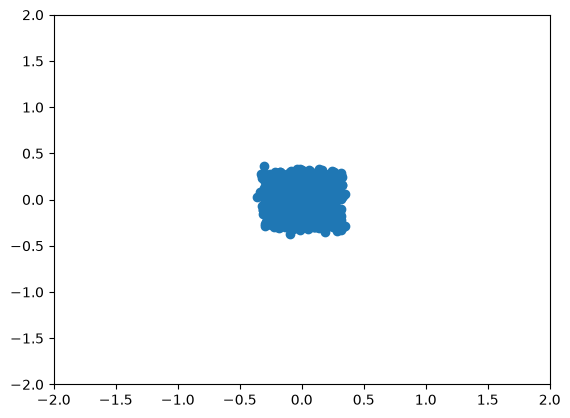

TEST 15000 logpx 0.97179514


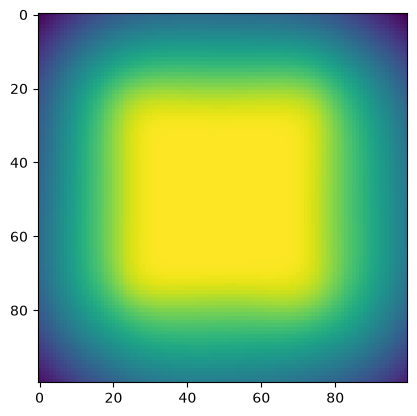

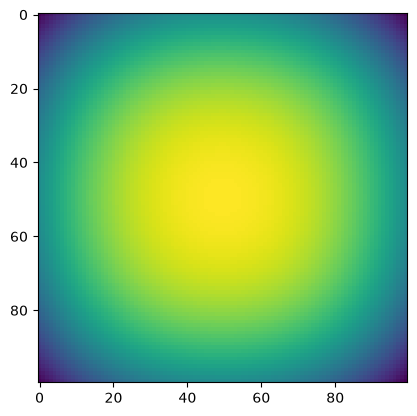

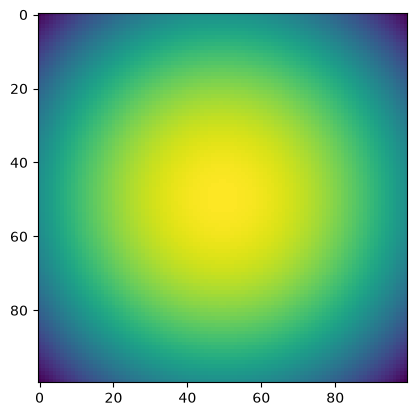

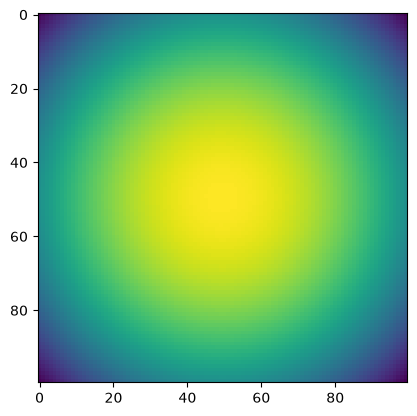

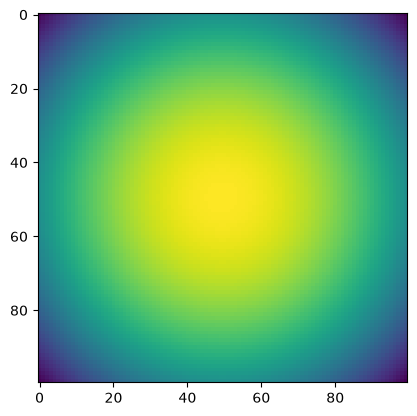

...

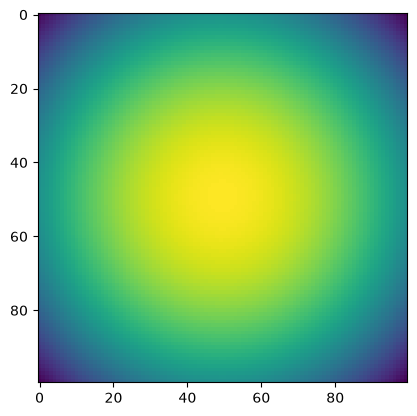

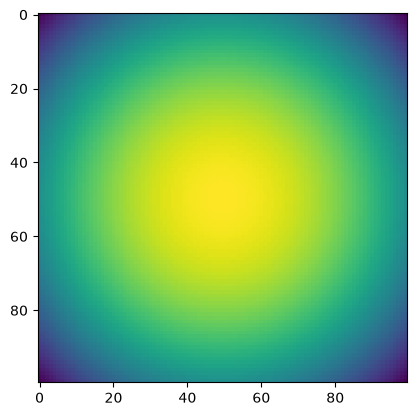

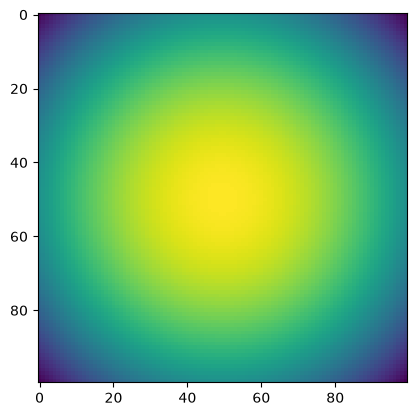

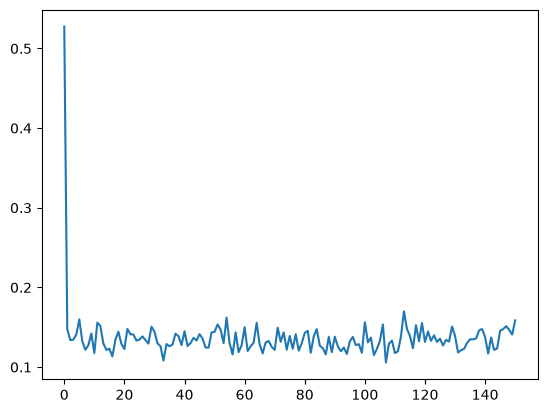

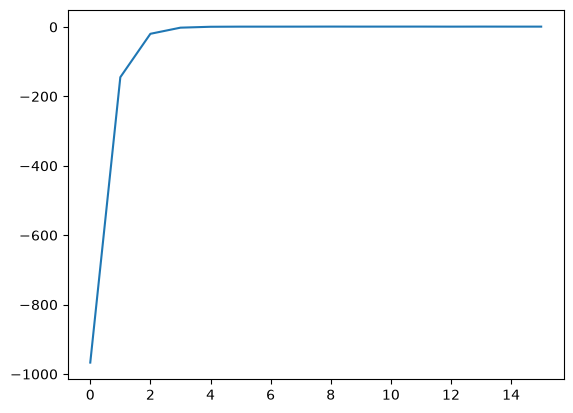

In [37]:
batch_size = 1000
data_dim = 2
num_steps = 15001

EMA = .999

n_steps = 100
net_params = {"n_layers": 4,
              "h_dim": 128,
              "emb_dim": 32}

def forward_fn():
  net = ResnetDiffusionModel(n_steps=n_steps, n_layers=4, x_dim=data_dim, h_dim=128, emb_dim=32)

  if ebm:
    net = EBMDiffusionModel(net)

  ddpm = PortableDiffusionModel(data_dim, n_steps, net, var_type="beta_forward")

  def logp_unnorm(x, t):
    scale_e = ddpm.energy_scale(-2 - t)
    t = jnp.ones((x.shape[0],), dtype=jnp.int32) * t
    return -net.neg_logp_unnorm(x, t) * scale_e

  def _logpx(x):
    return ddpm.logpx(x)["logpx"]
  return ddpm.loss, (ddpm.loss, ddpm.sample, _logpx, logp_unnorm)

forward = hk.multi_transform(forward_fn)
rng_seq = hk.PRNGSequence(0)

xr = [-.75, .75]
yr = [-.75, .75]


def plot_samples(x):
  plt.scatter(x[:, 0], x[:, 1])
  plt.xlim(-2, 2)
  plt.ylim(-2, 2)

def dist_show_2d(fn, xr, yr):
    nticks = 100
    x, y = np.meshgrid(np.linspace(xr[0], xr[1], nticks), np.linspace(yr[0], yr[1], nticks))
    coord = np.stack([x, y], axis=-1).reshape((-1, 2))
    heatmap = fn(coord).reshape((nticks, nticks))
    plt.imshow(heatmap)

# load data
dataset_energy, dataset_sample = toy_box(scale=0.3)
x = dataset_sample(batch_size)

plot_samples(x)
plt.show()
x = x.reshape(x.shape[0], -1)


params = forward.init(next(rng_seq), x)
loss_fn, sample_fn, logpx_fn, logp_unnorm_fn = forward.apply
param_count = sum(x.size for x in jax.tree_leaves(params))
for k, v in jax.tree_map(lambda x: x.shape, params).items():
  print(k, v)
print("Model has {} params".format(param_count))


opt = optax.adam(1e-3)
opt_state = opt.init(params)

sample_fn = jax.jit(sample_fn, static_argnums=2)
logpx_fn = jax.jit(logpx_fn)

logp_unnorm_fn = jax.jit(logp_unnorm_fn)

@jax.jit
def mean_loss_fn(params, rng, x):
  loss = loss_fn(params, rng, x)
  return loss.mean()

@jax.jit
def update(params, opt_state, rng, x):
  loss, grad = jax.value_and_grad(mean_loss_fn)(params, rng, x)

  updates, opt_state = opt.update(grad, opt_state)
  new_params = optax.apply_updates(params, updates)
  return loss, new_params, opt_state

# Speed-only change (no maths changed): the moving average runs inside one compiled call
# instead of one small GPU operation per weight array, about 10x faster per step.
@jax.jit
def update_ema(params, ema_params, opt_state, rng, x):
  loss, params, opt_state = update(params, opt_state, rng, x)
  ema_params = jax.tree_util.tree_map(lambda e, p: e * EMA + p * (1 - EMA), ema_params, params)
  return loss, params, ema_params, opt_state

ema_params = params
losses = []
test_logpx = []
itr = 0

for itr in range(num_steps):
  x = dataset_sample(batch_size)

  x = x.reshape(x.shape[0], -1)
  start_time = time.time()
  loss, params, ema_params, opt_state = update_ema(params, ema_params, opt_state, next(rng_seq), x)
  duration_update = time.time() - start_time

  if itr % 100 == 0:
    print(itr, loss, "time:", duration_update)
    losses.append(loss)
  if itr % 1000 == 0:
    x_samp = sample_fn(ema_params, next(rng_seq), batch_size)
    plot_samples(x_samp)
    plt.show()
    logpx = logpx_fn(ema_params, next(rng_seq), x).mean()
    print("TEST", itr, 'logpx', logpx)
    test_logpx.append(logpx)

    if ebm:
      for t in range(10):
        dist_show_2d(lambda x: logp_unnorm_fn(ema_params, next(rng_seq), x, 10*t), xr=xr, yr=yr)
        plt.show()

plt.plot(losses)
plt.show()
plt.plot(test_logpx)

small_box_params = ema_params

In [38]:
params = {}

for k, v in large_box_params.items():
  params[k] = v

for k, v in small_box_params.items():
  k = k.replace('resnet_diffusion_model/', 'resnet_diffusion_model_1/')
  params[k] = v

/tmp/ipykernel_1391087/1385371818.py:265: UserWarning: Explicitly requested dtype int64 requested in ones is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  t = jnp.ones((n,), dtype=jnp.int64) * j


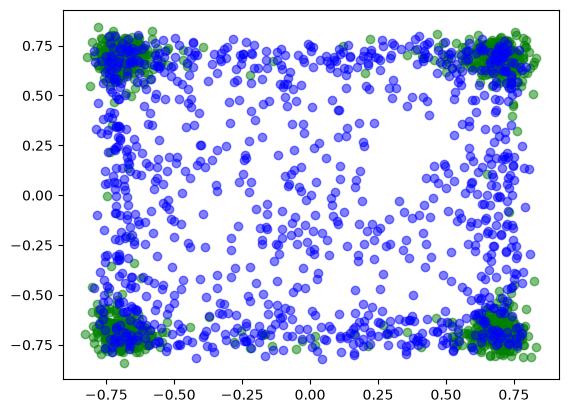

In [39]:
# Sampling from negation of distributions
import matplotlib.pyplot as plt

dim = 2
n_mode = 4
std = .05
init_std = 1.
init_mu = 0.
n_steps = 10
damping = .5
mass_diag_sqrt = 1.
num_leapfrog = 3
samples_per_step = 10
uha_step_size = .03
ula_step_size = .001

batch_size = 1000

rng_seq = hk.PRNGSequence(0)

means = jax.random.normal(next(rng_seq), (n_mode, dim))
comp_dists = distrax.MultivariateNormalDiag(means, jnp.ones_like(means) * std)
pi = distrax.Categorical(logits=jnp.zeros((n_mode,)))
target_dist = distrax.MixtureSameFamily(pi, comp_dists)
initial_dist = distrax.MultivariateNormalDiag(means[0] * 0 + init_mu, init_std * jnp.ones_like(means[0]))


x_init = initial_dist.sample(seed=next(rng_seq), sample_shape=(batch_size,))
logZs = []
n_stepss = [100]

def gradient_function(x, t):
  t = n_steps - jnp.ones((x.shape[0],), dtype=jnp.int32) * t - 1
  return -1 *dual_negation_gradient_fn(params, next(rng_seq), x, t)

if ebm:
  def energy_function(x, t):
    t = n_steps - jnp.ones((x.shape[0],), dtype=jnp.int32) * t - 1
    return -1 *dual_negation_energy_fn(params, next(rng_seq), x, t)

for n_steps in n_stepss:
  ula_step_sizes = jnp.ones((n_steps,)) * ula_step_size
  uha_step_sizes = jnp.ones((n_steps,)) * uha_step_size

  betas = jnp.linspace(0., 1., n_steps)

  def target_function(x, i):
    #print(x.shape)
    beta = betas[i]
    init_lp = initial_dist.log_prob(x)
    targ_lp = target_dist.log_prob(x)
    return beta * targ_lp + (1 - beta) * init_lp

  # Choose the sampler to use
  # sampler = AnnealedULASampler(n_steps, samples_per_step, ula_step_sizes, initial_dist, target_distribution=None, gradient_function=gradient_function)
  # sampler = AnnealedMALASampler(n_steps, samples_per_step, ula_step_sizes, initial_dist, target_distribution=None, gradient_function=gradient_function, energy_function=energy_function)
  # sampler = AnnealedUHASampler(n_steps, samples_per_step, uha_step_sizes, damping, mass_diag_sqrt, num_leapfrog, initial_dist, target_distribution=None, gradient_function=gradient_function)
  sampler = AnnealedMUHASampler(n_steps, samples_per_step, uha_step_sizes, damping, mass_diag_sqrt, num_leapfrog, initial_dist, target_distribution=None, gradient_function=gradient_function, energy_function=energy_function)

  # Generate sample with MCMC
  x_samp, logw, accept = sampler.sample(next(rng_seq), batch_size)
  rng_seq = hk.PRNGSequence(1)

  # Samples generated by adding score function
  grad_sample = dual_negation_sample_fn(params, next(rng_seq), batch_size, jnp.inf)

  # Samples from MCMC
  plt.scatter(x_samp[:, 0], x_samp[:, 1], color='green', alpha=.5)

  # Samples from adding score
  plt.scatter(grad_sample[:, 0], grad_sample[:, 1], color='blue', alpha=.5)

  plt.show()

In [40]:
def gen_plot_nice(pts):
    plt.scatter(pts[:, 0], pts[:, 1], c='b')
    ax = plt.gca()

    plt.xlim(-1, 1)
    plt.ylim(-1, 1)

    for axis in ['top', 'bottom', 'left', 'right']:
        ax.spines[axis].set_linewidth(1.5)

    ax.set_xticks([], [])
    ax.set_yticks([], [])